In [1]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART A: BATCH SCALING TO THE MEMORY WALL
# ============================================================
#
# STEP 1: GPU ENVIRONMENT AND REPRODUCIBILITY
#
# SUMMARY:
# 1. Initialize personal parameters (SID4, SEED, SLICE,
#    HP_ID, CLS_A, CLS_B).
# 2. Set random seeds for reproducibility.
# 3. Identify GPU model, CUDA version and available VRAM.
# 4. Record hardware and software information.
#
# COMMANDS:
# - Import required libraries.
# - Initialize seeds.
# - Check CUDA availability and GPU specifications.
# - Execute nvidia-smi to inspect GPU memory.
# ============================================================

import os
import sys
import random
import subprocess
from datetime import datetime

import numpy as np
import torch

# ------------------------------------------------------------
# 1. PERSONAL PARAMETERS
# ------------------------------------------------------------

SID4 = 1980
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

# ------------------------------------------------------------
# 2. REPRODUCIBILITY
# ------------------------------------------------------------

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# 3. GPU ENVIRONMENT
# ------------------------------------------------------------

print("=" * 65)
print("HW4.5 — PART A — STEP 1")
print("GPU ENVIRONMENT AND REPRODUCIBILITY")
print("=" * 65)

print(f"Timestamp       : {datetime.now().isoformat()}")
print(f"SID4            : {SID4}")
print(f"SEED            : {SEED}")
print(f"SLICE           : {SLICE}")
print(f"HP_ID           : {HP_ID}")
print(f"CLS_A           : {CLS_A}")
print(f"CLS_B           : {CLS_B}")

print("-" * 65)

print(f"Python version  : {sys.version.split()[0]}")
print(f"PyTorch version : {torch.__version__}")
print(f"CUDA version    : {torch.version.cuda}")
print(f"CUDA available  : {torch.cuda.is_available()}")
print(f"GPU count       : {torch.cuda.device_count()}")

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        gpu = torch.cuda.get_device_properties(i)

        print(f"\nGPU {i}         : {gpu.name}")
        print(f"Total VRAM      : {gpu.total_memory / 1024**3:.2f} GB")

# ------------------------------------------------------------
# 4. NVIDIA GPU DETAILS
# ------------------------------------------------------------

try:
    result = subprocess.run(
        ["nvidia-smi"],
        capture_output=True,
        text=True,
        check=True
    )
    print("\nNVIDIA-SMI OUTPUT:")
    print(result.stdout)

except Exception as e:
    print(f"nvidia-smi unavailable: {e}")

print("=" * 65)
print("STEP 1 COMPLETE")
print("=" * 65)


HW4.5 — PART A — STEP 1
GPU ENVIRONMENT AND REPRODUCIBILITY
Timestamp       : 2026-10-26T21:18:58.567032
SID4            : 1980
SEED            : 1980
SLICE           : 980
HP_ID           : 0
CLS_A           : 0
CLS_B           : 1
-----------------------------------------------------------------
Python version  : 3.10.13
PyTorch version : 2.1.2
CUDA version    : 12.1
CUDA available  : True
GPU count       : 1

GPU 0         : NVIDIA GeForce RTX 4090
Total VRAM      : 23.99 GB

NVIDIA-SMI OUTPUT:
Mon Oct 26 21:18:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 610.47.03              KMD Version: 610.60        CUDA UMD Version: 13.3     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|    

In [2]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART A: BATCH SCALING TO THE MEMORY WALL
# ============================================================
#
# STEP 2: LOCATE ORIGINAL HW4.a FILES
#
# SUMMARY:
# 1. Identify the current working directory.
# 2. Search for existing HW4/HW4.a notebooks and files.
# 3. Locate Twitter sentiment datasets.
# 4. Identify saved BERT models and training metrics.
# 5. Prepare to reuse the original fine-tuning settings.
#
# COMMANDS:
# - Print current working directory.
# - Search relevant directories for HW4 files.
# - Display matching notebooks, datasets and checkpoints.
# - Do not modify or delete any existing files.
# ============================================================

from pathlib import Path

print("=" * 65)
print("HW4.5 — PART A — STEP 2")
print("LOCATE ORIGINAL HW4.a FILES")
print("=" * 65)

cwd = Path.cwd()

print(f"\nCurrent directory: {cwd}")

# ------------------------------------------------------------
# 1. SEARCH LOCATIONS
# ------------------------------------------------------------

search_dirs = [
    cwd,
    cwd.parent,
    Path.home()
]

keywords = [
    "hw4",
    "bert",
    "twitter",
    "sentiment",
    "metrics",
    "training"
]

extensions = {
    ".ipynb", ".py", ".csv", ".tsv",
    ".json", ".jsonl", ".pt", ".pth",
    ".safetensors", ".bin", ".md"
}

# ------------------------------------------------------------
# 2. FIND RELEVANT FILES
# ------------------------------------------------------------

found_files = {}
max_depth = 4

for base in search_dirs:
    if not base.exists():
        continue

    print(f"\nSearching: {base}")

    for root, dirs, files in os.walk(base):

        relative_depth = len(
            Path(root).relative_to(base).parts
        )

        if relative_depth >= max_depth:
            dirs[:] = []
            continue

        dirs[:] = [
            d for d in dirs
            if d not in {
                ".git", "node_modules", ".cache",
                "site-packages", "__pycache__"
            }
        ]

        for filename in files:
            path = Path(root) / filename

            if (
                path.suffix.lower() in extensions
                and any(
                    k in str(path).lower()
                    for k in keywords
                )
            ):
                found_files[str(path)] = path

# ------------------------------------------------------------
# 3. DISPLAY RESULTS
# ------------------------------------------------------------

print("\n" + "-" * 65)
print("MATCHING FILES")
print("-" * 65)

if found_files:
    for i, path in enumerate(
        sorted(found_files.values()), 1
    ):
        size_mb = path.stat().st_size / (1024 ** 2)

        print(f"{i}. {path}")
        print(f"   Size: {size_mb:.2f} MB")
else:
    print("No matching files found in searched directories.")

print("\nTotal matching files:", len(found_files))

print("=" * 65)
print("STEP 2 COMPLETE")
print("=" * 65)


HW4.5 — PART A — STEP 2
LOCATE ORIGINAL HW4.a FILES

Current directory: /app

Searching: /app

Searching: /

Searching: /root

-----------------------------------------------------------------
MATCHING FILES
-----------------------------------------------------------------
No matching files found in searched directories.

Total matching files: 0
STEP 2 COMPLETE


In [3]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART A: BATCH SCALING TO THE MEMORY WALL
# ============================================================
#
# STEP 3: CHECK BERT LIBRARIES AND CACHED DATASETS
#
# SUMMARY:
# 1. Check availability of Hugging Face libraries.
# 2. Record installed library versions.
# 3. Inspect Hugging Face cache directories.
# 4. Look for cached BERT models and Twitter datasets.
# 5. Identify missing dependencies before fine-tuning.
#
# COMMANDS:
# - Check installed Python packages.
# - Inspect Hugging Face cache locations.
# - List cached models and datasets.
# - Do not download or modify existing files.
# ============================================================

import os
import importlib.metadata
from pathlib import Path

print("=" * 65)
print("HW4.5 — PART A — STEP 3")
print("BERT DEPENDENCIES AND DATASET CACHE")
print("=" * 65)

# ------------------------------------------------------------
# 1. CHECK REQUIRED LIBRARIES
# ------------------------------------------------------------

packages = [
    "torch",
    "transformers",
    "datasets",
    "tokenizers",
    "accelerate",
    "scikit-learn",
    "pandas",
    "numpy",
    "bitsandbytes",
    "vllm"
]

print("\nINSTALLED LIBRARIES")
print("-" * 65)

for package in packages:
    try:
        version = importlib.metadata.version(package)
        print(f"{package:<18}: {version}")
    except importlib.metadata.PackageNotFoundError:
        print(f"{package:<18}: NOT INSTALLED")

# ------------------------------------------------------------
# 2. CHECK HUGGING FACE CACHE
# ------------------------------------------------------------

hf_home = Path(
    os.environ.get(
        "HF_HOME",
        str(Path.home() / ".cache" / "huggingface")
    )
)

cache_paths = [
    hf_home / "hub",
    hf_home / "datasets",
    Path.home() / ".cache" / "torch"
]

print("\nCACHE LOCATIONS")
print("-" * 65)

for cache_path in cache_paths:

    print(f"\nPath: {cache_path}")

    if cache_path.exists():

        entries = sorted(cache_path.iterdir())

        print(f"Entries: {len(entries)}")

        for entry in entries[:30]:
            print(f"  {entry.name}")

        if len(entries) > 30:
            print(f"  ... {len(entries) - 30} more")

    else:
        print("Not found")

# ------------------------------------------------------------
# 3. CHECK ENVIRONMENT CONFIGURATION
# ------------------------------------------------------------

print("\nHUGGING FACE ENVIRONMENT")
print("-" * 65)

for variable in [
    "HF_HOME",
    "HF_HUB_CACHE",
    "HF_DATASETS_CACHE",
    "TRANSFORMERS_CACHE"
]:
    print(f"{variable:<22}: {os.environ.get(variable, 'Not set')}")

print("=" * 65)
print("STEP 3 COMPLETE")
print("=" * 65)


HW4.5 — PART A — STEP 3
BERT DEPENDENCIES AND DATASET CACHE

INSTALLED LIBRARIES
-----------------------------------------------------------------
torch             : 2.1.2
transformers      : NOT INSTALLED
datasets          : NOT INSTALLED
tokenizers        : NOT INSTALLED
accelerate        : NOT INSTALLED
scikit-learn      : NOT INSTALLED
pandas            : NOT INSTALLED
numpy             : 1.26.2
bitsandbytes      : NOT INSTALLED
vllm              : NOT INSTALLED

CACHE LOCATIONS
-----------------------------------------------------------------

Path: /root/.cache/huggingface/hub
Not found

Path: /root/.cache/huggingface/datasets
Not found

Path: /root/.cache/torch
Not found

HUGGING FACE ENVIRONMENT
-----------------------------------------------------------------
HF_HOME               : Not set
HF_HUB_CACHE          : Not set
HF_DATASETS_CACHE     : Not set
TRANSFORMERS_CACHE    : Not set
STEP 3 COMPLETE


In [4]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART A: BATCH SCALING TO THE MEMORY WALL
# ============================================================
#
# STEP 4: INSTALL BERT TRAINING DEPENDENCIES
#
# SUMMARY:
# 1. Install Hugging Face Transformers and Tokenizers.
# 2. Install Datasets for Twitter sentiment data.
# 3. Install Accelerate for training support.
# 4. Install scikit-learn and pandas for evaluation.
# 5. Preserve the existing PyTorch CUDA installation.
#
# COMMANDS:
# - Run pip installation using the notebook's Python.
# - Verify installation results.
# - Confirm that PyTorch and CUDA remain available.
# ============================================================

import sys
import subprocess
import importlib.metadata
import torch

print("=" * 65)
print("HW4.5 — PART A — STEP 4")
print("INSTALL BERT TRAINING DEPENDENCIES")
print("=" * 65)

packages = [
    "transformers==4.40.2",
    "datasets==2.19.1",
    "accelerate==0.30.1",
    "scikit-learn==1.4.2",
    "pandas==2.2.2",
    "sentencepiece==0.2.0"
]

print("\nInstalling required packages...\n")

command = [
    sys.executable,
    "-m",
    "pip",
    "install",
    "--disable-pip-version-check",
    *packages
]

result = subprocess.run(
    command,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT
)

print(result.stdout[-12000:])

if result.returncode != 0:
    raise RuntimeError(
        f"Package installation failed: exit code {result.returncode}"
    )

print("\nINSTALLED PACKAGE VERSIONS")
print("-" * 65)

for package in [
    "transformers",
    "datasets",
    "tokenizers",
    "accelerate",
    "scikit-learn",
    "pandas"
]:
    print(
        f"{package:<18}: "
        f"{importlib.metadata.version(package)}"
    )

print("\nGPU VERIFICATION")
print("-" * 65)
print(f"PyTorch version : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")
print(f"GPU             : {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'Not detected'}")

print("=" * 65)
print("STEP 4 COMPLETE")
print("=" * 65)


HW4.5 — PART A — STEP 4
INSTALL BERT TRAINING DEPENDENCIES

Installing required packages...

━━━━━━━━━━━━━━━━━ 21.6/37.7 MB 13.1 MB/s eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━━ 22.0/37.7 MB 13.1 MB/s eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━━ 22.5/37.7 MB 13.1 MB/s eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━━ 22.9/37.7 MB 13.0 MB/s eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━━ 23.4/37.7 MB 13.0 MB/s eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━━ 23.7/37.7 MB 12.8 MB/s eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━━ 24.2/37.7 MB 12.8 MB/s eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━━ 24.7/37.7 MB 12.9 MB/s eta 0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━━ 25.1/37.7 MB 12.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━━ 25.6/37.7 MB 12.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━╸━━━━━━━━━━━━ 26.0/37.7 MB 12.8 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━╺━━━━━━━━━━━ 26.5/37.7 MB 12.9 MB

In [5]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a BASELINE PREPARATION
# ============================================================
#
# STEP 5: INITIALIZE BERT FINE-TUNING CONFIGURATION
#
# SUMMARY:
# 1. Define the pretrained BERT checkpoint.
# 2. Configure sequence length, learning rate and epochs.
# 3. Define baseline training and evaluation batch sizes.
# 4. Establish the Twitter dataset row range.
# 5. Create directories for models, figures and metrics.
#
# COMMANDS:
# - Initialize baseline hyperparameters.
# - Calculate the requested Twitter row indices.
# - Create output directories.
# - Display and verify the experiment configuration.
# ============================================================

from pathlib import Path
import json
from datetime import datetime

# ------------------------------------------------------------
# 1. MODEL CONFIGURATION
# ------------------------------------------------------------

MODEL_NAME = "bert-base-uncased"

MAX_LENGTH = 128
LEARNING_RATE = 2e-5
EPOCHS = 3
TRAIN_BATCH_SIZE = 16
EVAL_BATCH_SIZE = 32
WEIGHT_DECAY = 0.01

# Original baseline uses FP32 training
USE_AMP = False
USE_GRADIENT_CHECKPOINTING = False
GRADIENT_ACCUMULATION_STEPS = 1

# ------------------------------------------------------------
# 2. DATASET CONFIGURATION
# ------------------------------------------------------------

MAX_ROWS = 5000

ROW_START = SLICE
ROW_END_EXCLUSIVE = SLICE + MAX_ROWS

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

# Actual row count will be verified after loading data.

# ------------------------------------------------------------
# 3. OUTPUT DIRECTORIES
# ------------------------------------------------------------

PROJECT_DIR = Path.cwd() / "HW4_5_GPU_Assignment"

MODEL_DIR = PROJECT_DIR / "models"
FIGURE_DIR = PROJECT_DIR / "figures"
METRICS_DIR = PROJECT_DIR / "metrics"
LOG_DIR = PROJECT_DIR / "logs"

for directory in [
    PROJECT_DIR,
    MODEL_DIR,
    FIGURE_DIR,
    METRICS_DIR,
    LOG_DIR
]:
    directory.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 4. SAVE PROPOSED BASELINE CONFIGURATION
# ------------------------------------------------------------

baseline_config = {
    "sid4": SID4,
    "seed": SEED,
    "slice": SLICE,
    "model_name": MODEL_NAME,
    "max_length": MAX_LENGTH,
    "learning_rate": LEARNING_RATE,
    "epochs": EPOCHS,
    "train_batch_size": TRAIN_BATCH_SIZE,
    "eval_batch_size": EVAL_BATCH_SIZE,
    "weight_decay": WEIGHT_DECAY,
    "use_amp": USE_AMP,
    "gradient_checkpointing": USE_GRADIENT_CHECKPOINTING,
    "gradient_accumulation_steps": GRADIENT_ACCUMULATION_STEPS,
    "row_start": ROW_START,
    "row_end_exclusive": ROW_END_EXCLUSIVE,
    "train_ratio": TRAIN_RATIO,
    "val_ratio": VAL_RATIO,
    "test_ratio": TEST_RATIO,
    "created_at": datetime.now().isoformat()
}

config_path = PROJECT_DIR / "baseline_config.json"

with open(config_path, "w") as f:
    json.dump(baseline_config, f, indent=4)

# ------------------------------------------------------------
# 5. DISPLAY CONFIGURATION
# ------------------------------------------------------------

print("=" * 65)
print("HW4.a BASELINE — STEP 5")
print("BERT FINE-TUNING CONFIGURATION")
print("=" * 65)

for key, value in baseline_config.items():
    print(f"{key:<30}: {value}")

print("-" * 65)
print(f"Project directory : {PROJECT_DIR}")
print(f"Configuration     : {config_path}")
print("-" * 65)

print("EXPECTED DATASET SUBSET")
print(f"Start index       : {ROW_START}")
print(f"End index         : {ROW_END_EXCLUSIVE - 1}")
print(f"Maximum rows      : {MAX_ROWS}")

print("=" * 65)
print("STEP 5 COMPLETE")
print("=" * 65)


HW4.a BASELINE — STEP 5
BERT FINE-TUNING CONFIGURATION
sid4                          : 1980
seed                          : 1980
slice                         : 980
model_name                    : bert-base-uncased
max_length                    : 128
learning_rate                 : 2e-05
epochs                        : 3
train_batch_size              : 16
eval_batch_size               : 32
weight_decay                  : 0.01
use_amp                       : False
gradient_checkpointing        : False
gradient_accumulation_steps   : 1
row_start                     : 980
row_end_exclusive             : 5980
train_ratio                   : 0.7
val_ratio                     : 0.15
test_ratio                    : 0.15
created_at                    : 2026-10-26T21:23:53.747013
-----------------------------------------------------------------
Project directory : /app/HW4_5_GPU_Assignment
Configuration     : /app/HW4_5_GPU_Assignment/baseline_config.json
---------------------------------------

In [6]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a BASELINE PREPARATION
# ============================================================
#
# STEP 6: LOAD AND INSPECT TWITTER SENTIMENT DATASET
#
# SUMMARY:
# 1. Download TweetEval sentiment dataset.
# 2. Inspect dataset size, columns and sentiment labels.
# 3. Select up to 5,000 consecutive rows from SLICE.
# 4. Verify the exact row range and class distribution.
# 5. Save the selected subset for reproducibility.
#
# COMMANDS:
# - Load cardiffnlp/tweet_eval sentiment dataset.
# - Select consecutive rows starting at index 980.
# - Display five example tweets.
# - Save the working subset locally.
# ============================================================

from datasets import load_dataset
from collections import Counter
from datetime import datetime

print("=" * 65)
print("HW4.a BASELINE — STEP 6")
print("LOAD TWITTER SENTIMENT DATASET")
print("=" * 65)

# ------------------------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------------------------

print("\nLoading TweetEval sentiment dataset...")

dataset = load_dataset(
    "cardiffnlp/tweet_eval",
    "sentiment"
)

source_dataset = dataset["train"]

print("\nDATASET INFORMATION")
print("-" * 65)
print(f"Source rows      : {len(source_dataset)}")
print(f"Columns          : {source_dataset.column_names}")
print(f"Label names      : {source_dataset.features['label'].names}")

# ------------------------------------------------------------
# 2. SELECT CONSECUTIVE ROWS
# ------------------------------------------------------------

start_idx = SLICE
end_idx = min(
    SLICE + MAX_ROWS,
    len(source_dataset)
)

assert start_idx < len(source_dataset), (
    "SLICE exceeds available dataset rows."
)

working_dataset = source_dataset.select(
    range(start_idx, end_idx)
)

print("\nWORKING SUBSET")
print("-" * 65)
print(f"Start row        : {start_idx}")
print(f"End row          : {end_idx - 1}")
print(f"Total rows       : {len(working_dataset)}")

# ------------------------------------------------------------
# 3. CLASS DISTRIBUTION
# ------------------------------------------------------------

label_names = source_dataset.features["label"].names

class_counts = Counter(
    working_dataset["label"]
)

print("\nCLASS DISTRIBUTION")
print("-" * 65)

for label_id, label_name in enumerate(label_names):
    count = class_counts.get(label_id, 0)
    percentage = 100 * count / len(working_dataset)

    print(
        f"{label_id} — {label_name:<10}: "
        f"{count:>5} ({percentage:.2f}%)"
    )

# ------------------------------------------------------------
# 4. DISPLAY SAMPLE TWEETS
# ------------------------------------------------------------

print("\nFIRST FIVE EXAMPLES")
print("-" * 65)

for i in range(min(5, len(working_dataset))):
    example = working_dataset[i]

    print(f"\nOriginal row : {start_idx + i}")
    print(f"Text         : {example['text']}")
    print(f"Label        : {label_names[example['label']]}")

# ------------------------------------------------------------
# 5. SAVE SUBSET
# ------------------------------------------------------------

subset_path = PROJECT_DIR / "twitter_working_subset"

working_dataset.save_to_disk(str(subset_path))

print("\n" + "-" * 65)
print(f"Saved subset : {subset_path}")
print(f"Timestamp    : {datetime.now().isoformat()}")

print("=" * 65)
print("STEP 6 COMPLETE")
print("=" * 65)


/opt/conda/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


HW4.a BASELINE — STEP 6
LOAD TWITTER SENTIMENT DATASET

Loading TweetEval sentiment dataset...


Generating validation split: 100%|██████████| 2000/2000 [00:00<00:00, 1029024.53 examples/s]



DATASET INFORMATION
-----------------------------------------------------------------
Source rows      : 45615
Columns          : ['text', 'label']
Label names      : ['negative', 'neutral', 'positive']

WORKING SUBSET
-----------------------------------------------------------------
Start row        : 980
End row          : 5979
Total rows       : 5000

CLASS DISTRIBUTION
-----------------------------------------------------------------
0 — negative  :   785 (15.70%)
1 — neutral   :  2268 (45.36%)
2 — positive  :  1947 (38.94%)

FIRST FIVE EXAMPLES
-----------------------------------------------------------------

Original row : 980
Text         : I will be out of town and will miss this but you should go! Nuit Blanche #DC event Sept 24 @user
Label        : neutral

Original row : 981
Text         : .@richardgasquet1 honing his game on P3 Court for his match with Federer tomorrow. #USOpen
Label        : positive

Original row : 982
Text         : @user Hi, may i ask you for your Help

Saving the dataset (1/1 shards): 100%|██████████| 5000/5000 [00:00<00:00, 303957.10 examples/s]


-----------------------------------------------------------------
Saved subset : /app/HW4_5_GPU_Assignment/twitter_working_subset
Timestamp    : 2026-10-26T21:24:27.106747
STEP 6 COMPLETE


In [7]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a BASELINE PREPARATION
# ============================================================
#
# STEP 7: TRAIN / VALIDATION / TEST SPLIT
#
# SUMMARY:
# 1. Split the 5,000 selected tweets into 70/15/15.
# 2. Use SEED = 1980 for reproducibility.
# 3. Stratify by sentiment class to preserve proportions.
# 4. Verify no overlapping examples by source row ID.
# 5. Save all three splits for subsequent experiments.
#
# COMMANDS:
# - Generate source row indices.
# - Perform seeded stratified splitting.
# - Validate split sizes and class distributions.
# - Save the train, validation and test datasets.
# ============================================================

from sklearn.model_selection import train_test_split
from datasets import DatasetDict
from collections import Counter
import numpy as np

print("=" * 65)
print("HW4.a BASELINE — STEP 7")
print("TRAIN / VALIDATION / TEST SPLIT")
print("=" * 65)

# ------------------------------------------------------------
# 1. PREPARE ROW INDICES AND LABELS
# ------------------------------------------------------------

all_indices = np.arange(len(working_dataset))
all_labels = np.array(working_dataset["label"])

# ------------------------------------------------------------
# 2. TRAIN SPLIT — 70%
# ------------------------------------------------------------

train_idx, temp_idx = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=all_labels
)

# ------------------------------------------------------------
# 3. VALIDATION / TEST — 15% EACH
# ------------------------------------------------------------

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=all_labels[temp_idx]
)

# ------------------------------------------------------------
# 4. CREATE DATASET SPLITS
# ------------------------------------------------------------

split_dataset = DatasetDict({
    "train": working_dataset.select(train_idx.tolist()),
    "validation": working_dataset.select(val_idx.tolist()),
    "test": working_dataset.select(test_idx.tolist())
})

# ------------------------------------------------------------
# 5. VERIFY SPLIT SIZES AND OVERLAP
# ------------------------------------------------------------

print("\nSPLIT SIZES")
print("-" * 65)

for split_name, ds in split_dataset.items():
    print(f"{split_name:<12}: {len(ds)} rows")

assert len(split_dataset["train"]) == 3500
assert len(split_dataset["validation"]) == 750
assert len(split_dataset["test"]) == 750

assert len(set(train_idx) & set(val_idx)) == 0
assert len(set(train_idx) & set(test_idx)) == 0
assert len(set(val_idx) & set(test_idx)) == 0

assert len(
    set(train_idx) | set(val_idx) | set(test_idx)
) == 5000

print("\nPASS: No overlapping source row indices.")
print("PASS: All 5,000 rows accounted for.")

# ------------------------------------------------------------
# 6. CLASS DISTRIBUTION PER SPLIT
# ------------------------------------------------------------

print("\nCLASS DISTRIBUTION")
print("-" * 65)

for split_name, ds in split_dataset.items():

    counts = Counter(ds["label"])
    total = len(ds)

    print(f"\n{split_name.upper()}")

    for label_id, label_name in enumerate(label_names):

        count = counts.get(label_id, 0)
        percentage = count / total * 100

        print(
            f"  {label_name:<10}: "
            f"{count:>4} ({percentage:.2f}%)"
        )

# ------------------------------------------------------------
# 7. SAVE SPLITS AND SOURCE INDICES
# ------------------------------------------------------------

split_path = PROJECT_DIR / "twitter_split_dataset"
split_dataset.save_to_disk(str(split_path))

np.savez(
    PROJECT_DIR / "split_indices.npz",
    train=train_idx + SLICE,
    validation=val_idx + SLICE,
    test=test_idx + SLICE
)

print("\n" + "-" * 65)
print(f"Saved splits  : {split_path}")
print(f"Saved indices : {PROJECT_DIR / 'split_indices.npz'}")

print("=" * 65)
print("STEP 7 COMPLETE")
print("=" * 65)


HW4.a BASELINE — STEP 7
TRAIN / VALIDATION / TEST SPLIT

SPLIT SIZES
-----------------------------------------------------------------
train       : 3500 rows
validation  : 750 rows
test        : 750 rows

PASS: No overlapping source row indices.
PASS: All 5,000 rows accounted for.

CLASS DISTRIBUTION
-----------------------------------------------------------------

TRAIN
  negative  :  549 (15.69%)
  neutral   : 1588 (45.37%)
  positive  : 1363 (38.94%)

VALIDATION
  negative  :  118 (15.73%)
  neutral   :  340 (45.33%)
  positive  :  292 (38.93%)

TEST
  negative  :  118 (15.73%)
  neutral   :  340 (45.33%)
  positive  :  292 (38.93%)


Saving the dataset (1/1 shards): 100%|██████████| 750/750 [00:00<00:00, 85113.99 examples/s]


-----------------------------------------------------------------
Saved splits  : /app/HW4_5_GPU_Assignment/twitter_split_dataset
Saved indices : /app/HW4_5_GPU_Assignment/split_indices.npz
STEP 7 COMPLETE


In [8]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a BASELINE PREPARATION
# ============================================================
#
# STEP 8: BERT TOKENIZATION AND TENSOR DATASETS
#
# SUMMARY:
# 1. Load BertTokenizer for bert-base-uncased.
# 2. Tokenize train, validation and test tweets.
# 3. Apply truncation and padding to MAX_LENGTH = 128.
# 4. Convert input IDs, attention masks and labels to tensors.
# 5. Verify tensor shapes, data types and label ranges.
# 6. Save tokenized datasets for HW4.5 experiments.
#
# COMMANDS:
# - Load the pretrained BERT tokenizer.
# - Tokenize the three dataset splits.
# - Construct PyTorch TensorDataset objects.
# - Validate dimensions and save the tensors.
# ============================================================

from transformers import BertTokenizer
from torch.utils.data import TensorDataset
import torch
from pathlib import Path
from datetime import datetime

print("=" * 65)
print("HW4.a BASELINE — STEP 8")
print("BERT TOKENIZATION AND TENSOR PREPARATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. LOAD BERT TOKENIZER
# ------------------------------------------------------------

print("\nLoading BERT tokenizer...")

tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

print(f"Tokenizer        : {MODEL_NAME}")
print(f"Vocabulary size  : {tokenizer.vocab_size}")
print(f"Maximum length   : {MAX_LENGTH}")

# ------------------------------------------------------------
# 2. TOKENIZE EACH SPLIT
# ------------------------------------------------------------

tensor_datasets = {}
tokenized_tensors = {}

for split_name in ["train", "validation", "test"]:

    ds = split_dataset[split_name]

    print(f"\nTokenizing {split_name}: {len(ds)} tweets")

    encoded = tokenizer(
        ds["text"],
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,
        return_attention_mask=True,
        return_tensors="pt"
    )

    labels = torch.tensor(
        ds["label"],
        dtype=torch.long
    )

    input_ids = encoded["input_ids"]
    attention_mask = encoded["attention_mask"]

    tensor_datasets[split_name] = TensorDataset(
        input_ids,
        attention_mask,
        labels
    )

    tokenized_tensors[split_name] = {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels
    }

    print(f"  Input IDs      : {tuple(input_ids.shape)}")
    print(f"  Attention mask : {tuple(attention_mask.shape)}")
    print(f"  Labels         : {tuple(labels.shape)}")

# ------------------------------------------------------------
# 3. VERIFY TENSOR SHAPES AND TYPES
# ------------------------------------------------------------

print("\nTENSOR VERIFICATION")
print("-" * 65)

expected_sizes = {
    "train": 3500,
    "validation": 750,
    "test": 750
}

for split_name, expected_size in expected_sizes.items():

    tensors = tokenized_tensors[split_name]

    assert tensors["input_ids"].shape == (
        expected_size, MAX_LENGTH
    )

    assert tensors["attention_mask"].shape == (
        expected_size, MAX_LENGTH
    )

    assert tensors["labels"].shape == (
        expected_size,
    )

    assert tensors["input_ids"].dtype == torch.long
    assert tensors["attention_mask"].dtype == torch.long
    assert tensors["labels"].dtype == torch.long

    assert set(tensors["labels"].tolist()).issubset(
        {0, 1, 2}
    )

    print(f"PASS: {split_name} tensor verification")

# ------------------------------------------------------------
# 4. INSPECT TOKENIZATION EXAMPLE
# ------------------------------------------------------------

example_text = split_dataset["train"][0]["text"]

example_tokens = tokenizer.tokenize(example_text)

print("\nTOKENIZATION EXAMPLE")
print("-" * 65)
print(f"Original text : {example_text}")
print(f"BERT tokens   : {example_tokens[:30]}")
print(
    "Active tokens :",
    int(tokenized_tensors["train"]["attention_mask"][0].sum())
)

# ------------------------------------------------------------
# 5. SAVE TOKENIZED TENSORS
# ------------------------------------------------------------

tensor_dir = PROJECT_DIR / "tokenized_tensors"
tensor_dir.mkdir(parents=True, exist_ok=True)

for split_name, tensors in tokenized_tensors.items():

    output_path = tensor_dir / f"{split_name}_tensors.pt"

    torch.save(tensors, output_path)

    print(f"Saved: {output_path}")

tokenizer.save_pretrained(str(MODEL_DIR / "bert_tokenizer"))

print("\n" + "-" * 65)
print(f"Timestamp : {datetime.now().isoformat()}")

print("=" * 65)
print("STEP 8 COMPLETE")
print("=" * 65)


HW4.a BASELINE — STEP 8
BERT TOKENIZATION AND TENSOR PREPARATION

Loading BERT tokenizer...


/opt/conda/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


Tokenizer        : bert-base-uncased
Vocabulary size  : 30522
Maximum length   : 128

Tokenizing train: 3500 tweets
  Input IDs      : (3500, 128)
  Attention mask : (3500, 128)
  Labels         : (3500,)

Tokenizing validation: 750 tweets
  Input IDs      : (750, 128)
  Attention mask : (750, 128)
  Labels         : (750,)

Tokenizing test: 750 tweets
  Input IDs      : (750, 128)
  Attention mask : (750, 128)
  Labels         : (750,)

TENSOR VERIFICATION
-----------------------------------------------------------------
PASS: train tensor verification
PASS: validation tensor verification
PASS: test tensor verification

TOKENIZATION EXAMPLE
-----------------------------------------------------------------
Original text : Can it be April so I can be closer to see Justin Bieber???
BERT tokens   : ['can', 'it', 'be', 'april', 'so', 'i', 'can', 'be', 'closer', 'to', 'see', 'justin', 'bi', '##eber', '?', '?', '?']
Active tokens : 19
Saved: /app/HW4_5_GPU_Assignment/tokenized_tensors/train_

In [9]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a BASELINE PREPARATION
# ============================================================
#
# STEP 9: INITIALIZE BERT SENTIMENT CLASSIFIER
#
# SUMMARY:
# 1. Set SEED = 1980 before model initialization.
# 2. Load pretrained bert-base-uncased.
# 3. Configure classification for three sentiment classes.
# 4. Keep model weights in FP32 (no mixed precision).
# 5. Move the model to the RTX 4090.
# 6. Verify parameter count and GPU memory usage.
#
# COMMANDS:
# - Initialize BertForSequenceClassification.
# - Set label mappings for negative, neutral, positive.
# - Transfer the model to CUDA.
# - Verify classifier output dimensions.
# - Record initial GPU memory allocation.
# ============================================================

import random
import numpy as np
import torch
from transformers import BertForSequenceClassification
from datetime import datetime

print("=" * 65)
print("HW4.a BASELINE — STEP 9")
print("INITIALIZE BERT SENTIMENT CLASSIFIER")
print("=" * 65)

# ------------------------------------------------------------
# 1. REPRODUCIBLE MODEL INITIALIZATION
# ------------------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert device.type == "cuda", (
    "GPU required for HW4.5 benchmarking."
)

# ------------------------------------------------------------
# 2. DEFINE SENTIMENT LABELS
# ------------------------------------------------------------

id2label = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

label2id = {
    value: key for key, value in id2label.items()
}

# ------------------------------------------------------------
# 3. LOAD PRETRAINED BERT MODEL
# ------------------------------------------------------------

print("\nLoading pretrained BERT model...")

model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

# ------------------------------------------------------------
# 4. VERIFY BASELINE PRECISION
# ------------------------------------------------------------

model = model.float()
model.config.use_cache = False

model.to(device)

assert next(model.parameters()).dtype == torch.float32

# ------------------------------------------------------------
# 5. MODEL PARAMETER COUNT
# ------------------------------------------------------------

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

# ------------------------------------------------------------
# 6. GPU MEMORY VERIFICATION
# ------------------------------------------------------------

torch.cuda.synchronize()

allocated_gb = (
    torch.cuda.memory_allocated() / 1024**3
)

reserved_gb = (
    torch.cuda.memory_reserved() / 1024**3
)

total_vram_gb = (
    torch.cuda.get_device_properties(0).total_memory
    / 1024**3
)

# ------------------------------------------------------------
# 7. DISPLAY RESULTS
# ------------------------------------------------------------

print("\nMODEL INFORMATION")
print("-" * 65)

print(f"Model             : {MODEL_NAME}")
print(f"Architecture      : {model.__class__.__name__}")
print(f"Number of classes : {model.config.num_labels}")
print(f"Labels            : {id2label}")
print(f"Total parameters  : {total_params:,}")
print(f"Trainable params  : {trainable_params:,}")
print(f"Model dtype       : {next(model.parameters()).dtype}")

print("\nGPU INFORMATION")
print("-" * 65)

print(f"Device            : {device}")
print(f"GPU               : {torch.cuda.get_device_name(0)}")
print(f"Total VRAM        : {total_vram_gb:.2f} GB")
print(f"Allocated memory  : {allocated_gb:.4f} GB")
print(f"Reserved memory   : {reserved_gb:.4f} GB")

# ------------------------------------------------------------
# 8. FINAL VERIFICATION
# ------------------------------------------------------------

assert model.config.num_labels == 3
assert trainable_params == total_params
assert next(model.parameters()).is_cuda

print("\nPASS: Three-class classifier initialized.")
print("PASS: All parameters trainable.")
print("PASS: Model loaded on GPU in FP32.")

print("-" * 65)
print(f"Timestamp: {datetime.now().isoformat()}")

print("=" * 65)
print("STEP 9 COMPLETE")
print("=" * 65)


HW4.a BASELINE — STEP 9
INITIALIZE BERT SENTIMENT CLASSIFIER

Loading pretrained BERT model...


/opt/conda/lib/python3.10/site-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



MODEL INFORMATION
-----------------------------------------------------------------
Model             : bert-base-uncased
Architecture      : BertForSequenceClassification
Number of classes : 3
Labels            : {0: 'negative', 1: 'neutral', 2: 'positive'}
Total parameters  : 109,484,547
Trainable params  : 109,484,547
Model dtype       : torch.float32

GPU INFORMATION
-----------------------------------------------------------------
Device            : cuda
GPU               : NVIDIA GeForce RTX 4090
Total VRAM        : 23.99 GB
Allocated memory  : 0.4089 GB
Reserved memory   : 0.4609 GB

PASS: Three-class classifier initialized.
PASS: All parameters trainable.
PASS: Model loaded on GPU in FP32.
-----------------------------------------------------------------
Timestamp: 2026-10-26T21:28:17.046747
STEP 9 COMPLETE


In [10]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a BASELINE PREPARATION
# ============================================================
#
# STEP 10: CONFIGURE TRAINING COMPONENTS
#
# SUMMARY:
# 1. Create train, validation and test DataLoaders.
# 2. Use batch size 16 for training and 32 for evaluation.
# 3. Configure AdamW with learning rate 2e-5.
# 4. Configure a linear learning-rate scheduler.
# 5. Calculate steps per epoch and total optimizer steps.
# 6. Verify the first batch dimensions.
#
# COMMANDS:
# - Initialize seeded DataLoaders.
# - Create AdamW optimizer.
# - Initialize linear scheduler.
# - Inspect tensor shapes and training configuration.
# ============================================================

import math
import torch
from torch.utils.data import DataLoader
from transformers import get_linear_schedule_with_warmup
from datetime import datetime

print("=" * 65)
print("HW4.a BASELINE — STEP 10")
print("TRAINING COMPONENT CONFIGURATION")
print("=" * 65)

# ------------------------------------------------------------
# 1. SEEDED TRAINING GENERATOR
# ------------------------------------------------------------

train_generator = torch.Generator()
train_generator.manual_seed(SEED)

# ------------------------------------------------------------
# 2. CREATE DATA LOADERS
# ------------------------------------------------------------

train_loader = DataLoader(
    tensor_datasets["train"],
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    generator=train_generator,
    num_workers=0,
    pin_memory=True,
    drop_last=False
)

val_loader = DataLoader(
    tensor_datasets["validation"],
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    tensor_datasets["test"],
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# ------------------------------------------------------------
# 3. CONFIGURE OPTIMIZER
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ------------------------------------------------------------
# 4. CONFIGURE LEARNING-RATE SCHEDULER
# ------------------------------------------------------------

steps_per_epoch = len(train_loader)

total_training_steps = (
    steps_per_epoch * EPOCHS
)

warmup_steps = 0

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_training_steps
)

# ------------------------------------------------------------
# 5. VERIFY FIRST TRAINING BATCH
# ------------------------------------------------------------

batch = next(iter(train_loader))

input_ids, attention_mask, labels = batch

assert input_ids.shape[1] == MAX_LENGTH
assert attention_mask.shape == input_ids.shape
assert labels.shape[0] == input_ids.shape[0]

# Reset generator so the training run starts with
# the original seeded shuffle sequence.
train_generator.manual_seed(SEED)

# ------------------------------------------------------------
# 6. DISPLAY TRAINING CONFIGURATION
# ------------------------------------------------------------

print("\nDATA LOADERS")
print("-" * 65)

print(f"Training samples    : {len(train_loader.dataset)}")
print(f"Validation samples  : {len(val_loader.dataset)}")
print(f"Test samples        : {len(test_loader.dataset)}")

print(f"Train batch size    : {TRAIN_BATCH_SIZE}")
print(f"Eval batch size     : {EVAL_BATCH_SIZE}")

print(f"Train batches/epoch : {len(train_loader)}")
print(f"Validation batches  : {len(val_loader)}")
print(f"Test batches        : {len(test_loader)}")

print("\nOPTIMIZER AND SCHEDULER")
print("-" * 65)

print(f"Optimizer           : AdamW")
print(f"Learning rate       : {LEARNING_RATE}")
print(f"Weight decay        : {WEIGHT_DECAY}")
print(f"Scheduler           : Linear decay")
print(f"Warmup steps        : {warmup_steps}")
print(f"Epochs              : {EPOCHS}")
print(f"Steps per epoch     : {steps_per_epoch}")
print(f"Total optimizer steps: {total_training_steps}")

print("\nFIRST BATCH VERIFICATION")
print("-" * 65)

print(f"Input IDs shape     : {tuple(input_ids.shape)}")
print(f"Attention mask shape: {tuple(attention_mask.shape)}")
print(f"Labels shape        : {tuple(labels.shape)}")

print("\nPASS: DataLoaders initialized.")
print("PASS: Optimizer initialized.")
print("PASS: Scheduler initialized.")
print("PASS: First batch verified.")

print("-" * 65)
print(f"Timestamp: {datetime.now().isoformat()}")

print("=" * 65)
print("STEP 10 COMPLETE")
print("=" * 65)


HW4.a BASELINE — STEP 10
TRAINING COMPONENT CONFIGURATION

DATA LOADERS
-----------------------------------------------------------------
Training samples    : 3500
Validation samples  : 750
Test samples        : 750
Train batch size    : 16
Eval batch size     : 32
Train batches/epoch : 219
Validation batches  : 24
Test batches        : 24

OPTIMIZER AND SCHEDULER
-----------------------------------------------------------------
Optimizer           : AdamW
Learning rate       : 2e-05
Weight decay        : 0.01
Scheduler           : Linear decay
Warmup steps        : 0
Epochs              : 3
Steps per epoch     : 219
Total optimizer steps: 657

FIRST BATCH VERIFICATION
-----------------------------------------------------------------
Input IDs shape     : (16, 128)
Attention mask shape: (16, 128)
Labels shape        : (16,)

PASS: DataLoaders initialized.
PASS: Optimizer initialized.
PASS: Scheduler initialized.
PASS: First batch verified.
---------------------------------------------

In [12]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a BASELINE FINE-TUNING
# ============================================================
#
# STEP 11: TRAIN BERT SENTIMENT CLASSIFIER
#
# SUMMARY:
# 1. Fine-tune BERT for 3 epochs using FP32.
# 2. Record training loss for every epoch.
# 3. Measure validation loss and accuracy after each epoch.
# 4. Measure GPU peak memory and wall-clock time.
# 5. Save the best validation checkpoint.
# 6. Save training history and console logs.
#
# COMMANDS:
# - Run forward and backward propagation.
# - Update parameters using AdamW and linear scheduler.
# - Evaluate on validation data after each epoch.
# - Track peak CUDA memory and elapsed time.
# - Save model checkpoints and training metrics.
# ============================================================

import time
import json
import math
import torch
from datetime import datetime
from tqdm.auto import tqdm

print("=" * 65)
print("HW4.a BASELINE — STEP 11")
print("BERT FP32 FINE-TUNING")
print("=" * 65)

# ------------------------------------------------------------
# 1. INITIALIZE METRIC TRACKING
# ------------------------------------------------------------

training_history = []
best_val_loss = float("inf")
best_epoch = None

baseline_start = datetime.now()
start_time = time.perf_counter()

torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()
torch.cuda.synchronize()

print(f"Start time       : {baseline_start.isoformat()}")
print(f"GPU              : {torch.cuda.get_device_name(0)}")
print(f"Precision        : FP32")
print(f"Training batch   : {TRAIN_BATCH_SIZE}")
print(f"Epochs           : {EPOCHS}")
print(f"Training samples : {len(train_loader.dataset)}")

# ------------------------------------------------------------
# 2. TRAINING LOOP
# ------------------------------------------------------------

for epoch in range(EPOCHS):

    epoch_start = time.perf_counter()

    model.train()

    train_loss_sum = 0.0
    train_sample_count = 0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS} Training"
    )

    for input_ids, attention_mask, labels in progress:

        input_ids = input_ids.to(
            device, non_blocking=True
        )
        attention_mask = attention_mask.to(
            device, non_blocking=True
        )
        labels = labels.to(
            device, non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss

        loss.backward()

        optimizer.step()
        scheduler.step()

        batch_size = labels.size(0)

        train_loss_sum += loss.item() * batch_size
        train_sample_count += batch_size

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    torch.cuda.synchronize()

    train_end = time.perf_counter()
    train_duration = train_end - epoch_start

    avg_train_loss = (
        train_loss_sum / train_sample_count
    )

    # --------------------------------------------------------
    # 3. VALIDATION
    # --------------------------------------------------------

    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():

        for input_ids, attention_mask, labels in val_loader:

            input_ids = input_ids.to(
                device, non_blocking=True
            )
            attention_mask = attention_mask.to(
                device, non_blocking=True
            )
            labels = labels.to(
                device, non_blocking=True
            )

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            batch_size = labels.size(0)

            val_loss_sum += (
                outputs.loss.item() * batch_size
            )

            predictions = torch.argmax(
                outputs.logits, dim=1
            )

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += batch_size

    torch.cuda.synchronize()

    avg_val_loss = val_loss_sum / val_total
    val_accuracy = val_correct / val_total

    epoch_duration = (
        time.perf_counter() - epoch_start
    )

    throughput = (
        train_sample_count / train_duration
    )

    peak_memory_gb = (
        torch.cuda.max_memory_allocated()
        / 1024**3
    )

    # --------------------------------------------------------
    # 4. SAVE BEST VALIDATION MODEL
    # --------------------------------------------------------

    if avg_val_loss < best_val_loss:

        best_val_loss = avg_val_loss
        best_epoch = epoch + 1

        best_model_dir = MODEL_DIR / "bert_best"

        model.save_pretrained(
            str(best_model_dir)
        )

        tokenizer.save_pretrained(
            str(best_model_dir)
        )

        print(
            f"Best checkpoint updated: "
            f"Epoch {best_epoch}"
        )

    # --------------------------------------------------------
    # 5. RECORD EPOCH METRICS
    # --------------------------------------------------------

    epoch_metrics = {
        "epoch": epoch + 1,
        "train_loss": avg_train_loss,
        "val_loss": avg_val_loss,
        "val_accuracy": val_accuracy,
        "train_time_seconds": train_duration,
        "epoch_time_seconds": epoch_duration,
        "train_throughput_samples_per_sec": throughput,
        "peak_gpu_memory_gb": peak_memory_gb
    }

    training_history.append(epoch_metrics)

    print("\n" + "-" * 65)
    print(f"EPOCH {epoch + 1} RESULTS")
    print("-" * 65)
    print(f"Training loss       : {avg_train_loss:.6f}")
    print(f"Validation loss     : {avg_val_loss:.6f}")
    print(f"Validation accuracy : {val_accuracy:.4%}")
    print(f"Training time       : {train_duration:.2f} sec")
    print(f"Total epoch time    : {epoch_duration:.2f} sec")
    print(f"Throughput          : {throughput:.2f} samples/sec")
    print(f"Peak GPU memory     : {peak_memory_gb:.4f} GB")

    # Save progress after every completed epoch
    with open(
        METRICS_DIR / "hw4a_training_history.json", "w"
    ) as f:
        json.dump(training_history, f, indent=4)

# ------------------------------------------------------------
# 6. FINAL BASELINE MEASUREMENTS
# ------------------------------------------------------------

torch.cuda.synchronize()

total_wall_time = (
    time.perf_counter() - start_time
)

baseline_end = datetime.now()

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)

baseline_summary = {
    "model": MODEL_NAME,
    "gpu": torch.cuda.get_device_name(0),
    "precision": "FP32",
    "train_batch_size": TRAIN_BATCH_SIZE,
    "epochs": EPOCHS,
    "train_samples": len(train_loader.dataset),
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "final_val_accuracy": training_history[-1]["val_accuracy"],
    "peak_allocated_gb": peak_allocated_gb,
    "peak_reserved_gb": peak_reserved_gb,
    "wall_clock_seconds": total_wall_time,
    "start_time": baseline_start.isoformat(),
    "end_time": baseline_end.isoformat()
}

with open(
    METRICS_DIR / "hw4a_baseline_summary.json", "w"
) as f:
    json.dump(baseline_summary, f, indent=4)

# ------------------------------------------------------------
# 7. SAVE RUN LOG
# ------------------------------------------------------------

log_path = LOG_DIR / "hw4a_training_RUN_LOG.txt"

with open(log_path, "w") as f:

    f.write("HW4.a BERT BASELINE TRAINING\n")
    f.write("=" * 65 + "\n")
    f.write(json.dumps(baseline_summary, indent=4))
    f.write("\n\nEPOCH METRICS\n")
    f.write(json.dumps(training_history, indent=4))

# ------------------------------------------------------------
# 8. DISPLAY FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("HW4.a BASELINE TRAINING COMPLETE")
print("=" * 65)

print(f"Best epoch          : {best_epoch}")
print(f"Best validation loss: {best_val_loss:.6f}")
print(
    f"Final val accuracy  : "
    f"{training_history[-1]['val_accuracy']:.4%}"
)
print(f"Total wall time     : {total_wall_time:.2f} sec")
print(f"Peak allocated VRAM : {peak_allocated_gb:.4f} GB")
print(f"Peak reserved VRAM  : {peak_reserved_gb:.4f} GB")

print(f"\nTraining history    : {METRICS_DIR / 'hw4a_training_history.json'}")
print(f"Baseline summary    : {METRICS_DIR / 'hw4a_baseline_summary.json'}")
print(f"Run log             : {log_path}")
print(f"Best checkpoint     : {MODEL_DIR / 'bert_best'}")

print("=" * 65)
print("STEP 11 COMPLETE")
print("=" * 65)


HW4.a BASELINE — STEP 11
BERT FP32 FINE-TUNING
Start time       : 2026-10-26T21:30:24.532161
GPU              : NVIDIA GeForce RTX 4090
Precision        : FP32
Training batch   : 16
Epochs           : 3
Training samples : 3500


Epoch 1/3 Training: 100%|██████████| 219/219 [00:10<00:00, 20.04it/s, loss=0.6843]


Best checkpoint updated: Epoch 1

-----------------------------------------------------------------
EPOCH 1 RESULTS
-----------------------------------------------------------------
Training loss       : 0.888026
Validation loss     : 0.721695
Validation accuracy : 65.4667%
Training time       : 10.93 sec
Total epoch time    : 11.53 sec
Throughput          : 320.11 samples/sec
Peak GPU memory     : 2.7958 GB


Epoch 2/3 Training: 100%|██████████| 219/219 [00:10<00:00, 21.47it/s, loss=0.3549]


Best checkpoint updated: Epoch 2

-----------------------------------------------------------------
EPOCH 2 RESULTS
-----------------------------------------------------------------
Training loss       : 0.583201
Validation loss     : 0.715220
Validation accuracy : 67.3333%
Training time       : 10.20 sec
Total epoch time    : 10.80 sec
Throughput          : 342.99 samples/sec
Peak GPU memory     : 2.7958 GB


Epoch 3/3 Training: 100%|██████████| 219/219 [00:10<00:00, 21.13it/s, loss=0.2948]



-----------------------------------------------------------------
EPOCH 3 RESULTS
-----------------------------------------------------------------
Training loss       : 0.370063
Validation loss     : 0.782620
Validation accuracy : 66.9333%
Training time       : 10.37 sec
Total epoch time    : 10.96 sec
Throughput          : 337.62 samples/sec
Peak GPU memory     : 2.7958 GB

HW4.a BASELINE TRAINING COMPLETE
Best epoch          : 2
Best validation loss: 0.715220
Final val accuracy  : 66.9333%
Total wall time     : 36.66 sec
Peak allocated VRAM : 2.7958 GB
Peak reserved VRAM  : 3.0996 GB

Training history    : /app/HW4_5_GPU_Assignment/metrics/hw4a_training_history.json
Baseline summary    : /app/HW4_5_GPU_Assignment/metrics/hw4a_baseline_summary.json
Run log             : /app/HW4_5_GPU_Assignment/logs/hw4a_training_RUN_LOG.txt
Best checkpoint     : /app/HW4_5_GPU_Assignment/models/bert_best
STEP 11 COMPLETE


HW4.a BASELINE — STEP 12
TEST EVALUATION AND CLASS ERROR ANALYSIS
Checkpoint       : /app/HW4_5_GPU_Assignment/models/bert_best
Best epoch       : 2
Test samples     : 750

TEST ACCURACY
-----------------------------------------------------------------
Accuracy: 71.4667%

PER-CLASS PERFORMANCE
-----------------------------------------------------------------
negative   | Precision: 0.6916 | Recall: 0.6271 | F1: 0.6578 | Support: 118
neutral    | Precision: 0.7219 | Recall: 0.6794 | F1: 0.7000 | Support: 340
positive   | Precision: 0.7152 | Recall: 0.7911 | F1: 0.7512 | Support: 292

CLASSIFICATION REPORT
-----------------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.69      0.63      0.66       118
     neutral       0.72      0.68      0.70       340
    positive       0.72      0.79      0.75       292

    accuracy                           0.71       750
   macro avg       0.71      0.70      0.70       

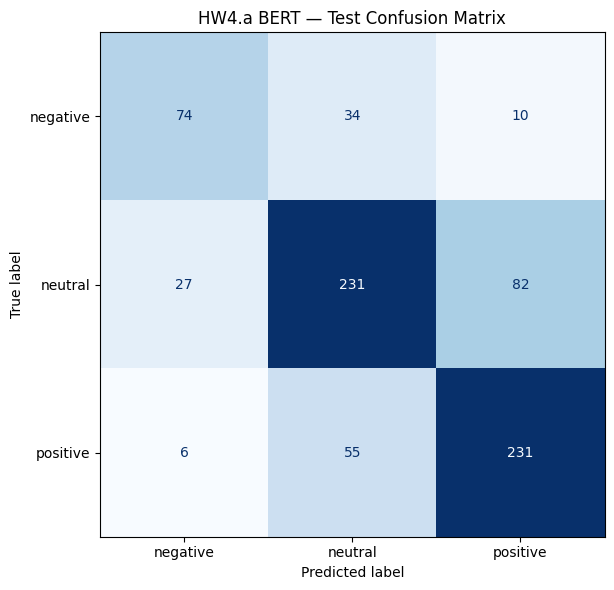


WORST-PERFORMING CLASS
-----------------------------------------------------------------
Class       : negative
Class ID    : 0
Precision   : 0.6916
Recall      : 0.6271
F1-score    : 0.6578

FIVE MISCLASSIFIED EXAMPLES
-----------------------------------------------------------------

Example 1
Original row : 2034
Tweet        : You may remember Frank Gifford as a great football player or broadcaster. But I remember him as the guy who wanted anal from a stewardess
True label   : negative
Predicted    : neutral
Confidence   : 0.6920

Example 2
Original row : 1844
Tweet        : Why does she hella look like a mix of Jennifer Lawrence and Caitlyn Jenner in the 2nd pic omg
True label   : negative
Predicted    : neutral
Confidence   : 0.6611

Example 3
Original row : 2982
Tweet        : Capello Bemoans Language Barrier in Russia: Russia coach Fabio Capello spoke Monday of his frustration at the la...
True label   : negative
Predicted    : neutral
Confidence   : 0.6589

Example 4
Original 

In [15]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a BASELINE EVALUATION
# ============================================================
#
# STEP 12: TEST EVALUATION AND ERROR ANALYSIS
#
# SUMMARY:
# 1. Reload the best BERT checkpoint (epoch 2).
# 2. Evaluate on the untouched test dataset.
# 3. Calculate accuracy, precision, recall and F1-score.
# 4. Generate and save the confusion matrix.
# 5. Identify the worst-performing class by F1-score.
# 6. Save five misclassified examples from that class.
#
# COMMANDS:
# - Load best checkpoint.
# - Run test inference without gradients.
# - Generate classification report and confusion matrix.
# - Save metrics, figure and misclassified examples.
# ============================================================

import json
import torch
import numpy as np
import matplotlib.pyplot as plt

from datetime import datetime
from transformers import BertForSequenceClassification
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("=" * 65)
print("HW4.a BASELINE — STEP 12")
print("TEST EVALUATION AND CLASS ERROR ANALYSIS")
print("=" * 65)

# ------------------------------------------------------------
# 1. LOAD BEST CHECKPOINT
# ------------------------------------------------------------

best_model_dir = MODEL_DIR / "bert_best"

best_model = BertForSequenceClassification.from_pretrained(
    str(best_model_dir)
).to(device)

best_model.eval()

print(f"Checkpoint       : {best_model_dir}")
print(f"Best epoch       : {best_epoch}")
print(f"Test samples     : {len(test_loader.dataset)}")

# ------------------------------------------------------------
# 2. RUN TEST INFERENCE
# ------------------------------------------------------------

all_predictions = []
all_true_labels = []
all_probabilities = []

with torch.inference_mode():

    for input_ids, attention_mask, labels in test_loader:

        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)

        outputs = best_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = torch.softmax(
            outputs.logits, dim=1
        )

        predictions = torch.argmax(
            probabilities, dim=1
        )

        all_predictions.extend(
            predictions.cpu().tolist()
        )

        all_true_labels.extend(
            labels.tolist()
        )

        all_probabilities.extend(
            probabilities.cpu().tolist()
        )

# ------------------------------------------------------------
# 3. CALCULATE METRICS
# ------------------------------------------------------------

class_ids = [0, 1, 2]
class_names = [
    "negative",
    "neutral",
    "positive"
]

test_accuracy = accuracy_score(
    all_true_labels,
    all_predictions
)

precision, recall, f1, support = (
    precision_recall_fscore_support(
        all_true_labels,
        all_predictions,
        labels=class_ids,
        zero_division=0
    )
)

print("\nTEST ACCURACY")
print("-" * 65)
print(f"Accuracy: {test_accuracy:.4%}")

print("\nPER-CLASS PERFORMANCE")
print("-" * 65)

for i, name in enumerate(class_names):
    print(
        f"{name:<10} | "
        f"Precision: {precision[i]:.4f} | "
        f"Recall: {recall[i]:.4f} | "
        f"F1: {f1[i]:.4f} | "
        f"Support: {support[i]}"
    )

print("\nCLASSIFICATION REPORT")
print("-" * 65)

print(
    classification_report(
        all_true_labels,
        all_predictions,
        labels=class_ids,
        target_names=class_names,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 4. CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    all_true_labels,
    all_predictions,
    labels=class_ids
)

print("\nCONFUSION MATRIX")
print("-" * 65)
print(cm)
print("Rows = True labels, Columns = Predicted labels")

fig, ax = plt.subplots(figsize=(7, 6))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title(
    "HW4.a BERT — Test Confusion Matrix"
)

plt.tight_layout()

figure_path = FIGURE_DIR / "hw4a_confusion_matrix.png"

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. IDENTIFY WORST CLASS
# ------------------------------------------------------------

worst_class_id = int(np.argmin(f1))
worst_class_name = class_names[worst_class_id]

print("\nWORST-PERFORMING CLASS")
print("-" * 65)

print(f"Class       : {worst_class_name}")
print(f"Class ID    : {worst_class_id}")
print(f"Precision   : {precision[worst_class_id]:.4f}")
print(f"Recall      : {recall[worst_class_id]:.4f}")
print(f"F1-score    : {f1[worst_class_id]:.4f}")

# ------------------------------------------------------------
# 6. FIVE MISCLASSIFIED EXAMPLES
# ------------------------------------------------------------

misclassified_examples = []

for i, (true_label, predicted_label) in enumerate(
    zip(all_true_labels, all_predictions)
):

    if (
        true_label == worst_class_id
        and predicted_label != true_label
    ):

        example = {
            "test_index": i,
            "original_row": int(
                SLICE + test_idx[i]
            ),
            "text": split_dataset["test"][i]["text"],
            "true_label": class_names[true_label],
            "predicted_label": class_names[predicted_label],
            "predicted_confidence": float(
                all_probabilities[i][predicted_label]
            )
        }

        misclassified_examples.append(example)

print("\nFIVE MISCLASSIFIED EXAMPLES")
print("-" * 65)

for i, example in enumerate(
    misclassified_examples[:5], 1
):

    print(f"\nExample {i}")
    print(f"Original row : {example['original_row']}")
    print(f"Tweet        : {example['text']}")
    print(f"True label   : {example['true_label']}")
    print(f"Predicted    : {example['predicted_label']}")
    print(
        f"Confidence   : "
        f"{example['predicted_confidence']:.4f}"
    )

# ------------------------------------------------------------
# 7. SAVE EVALUATION METRICS
# ------------------------------------------------------------

evaluation_results = {
    "checkpoint": str(best_model_dir),
    "best_epoch": best_epoch,
    "test_accuracy": float(test_accuracy),
    "confusion_matrix": cm.tolist(),
    "per_class": {
        name: {
            "precision": float(precision[i]),
            "recall": float(recall[i]),
            "f1": float(f1[i]),
            "support": int(support[i])
        }
        for i, name in enumerate(class_names)
    },
    "worst_class": worst_class_name,
    "misclassified_examples": misclassified_examples[:5],
    "timestamp": datetime.now().isoformat()
}

metrics_path = (
    METRICS_DIR / "hw4a_test_evaluation.json"
)

with open(metrics_path, "w") as f:
    json.dump(
        evaluation_results,
        f,
        indent=4
    )

print("\n" + "-" * 65)
print(f"Metrics saved : {metrics_path}")
print(f"Figure saved  : {figure_path}")

print("=" * 65)
print("STEP 12 COMPLETE")
print("=" * 65)


In [14]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a BASELINE EVALUATION
# ============================================================
#
# STEP 12A: FIX MISSING MATPLOTLIB DEPENDENCY
#
# SUMMARY:
# 1. Install matplotlib for confusion matrix visualization.
# 2. Verify that matplotlib imports successfully.
# 3. Confirm PyTorch and CUDA are still available.
# 4. Preserve the trained BERT checkpoint and metrics.
#
# COMMANDS:
# - Install matplotlib using the notebook Python.
# - Verify the installed version.
# - Check CUDA availability.
# ============================================================

import sys
import subprocess
import importlib.metadata
import torch

print("=" * 65)
print("HW4.a BASELINE — STEP 12A")
print("MATPLOTLIB DEPENDENCY FIX")
print("=" * 65)

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "matplotlib==3.8.4"
    ],
    capture_output=True,
    text=True
)

if result.returncode != 0:
    print(result.stdout)
    print(result.stderr)
    raise RuntimeError("Matplotlib installation failed.")

import matplotlib
import matplotlib.pyplot as plt

print(f"Matplotlib version : {matplotlib.__version__}")
print(f"PyTorch version    : {torch.__version__}")
print(f"CUDA available     : {torch.cuda.is_available()}")
print(f"GPU                : {torch.cuda.get_device_name(0)}")

assert torch.cuda.is_available()

print("\nPASS: Matplotlib installed successfully.")
print("PASS: GPU remains available.")

print("=" * 65)
print("STEP 12A COMPLETE")
print("=" * 65)


HW4.a BASELINE — STEP 12A
MATPLOTLIB DEPENDENCY FIX
Matplotlib version : 3.8.4
PyTorch version    : 2.1.2
CUDA available     : True
GPU                : NVIDIA GeForce RTX 4090

PASS: Matplotlib installed successfully.
PASS: GPU remains available.
STEP 12A COMPLETE


HW4.a BASELINE — STEP 13
TRAINING AND VALIDATION CURVES

TRAINING HISTORY
-----------------------------------------------------------------
Epoch 1: Train Loss=0.8880, Val Loss=0.7217, Val Accuracy=65.47%
Epoch 2: Train Loss=0.5832, Val Loss=0.7152, Val Accuracy=67.33%
Epoch 3: Train Loss=0.3701, Val Loss=0.7826, Val Accuracy=66.93%


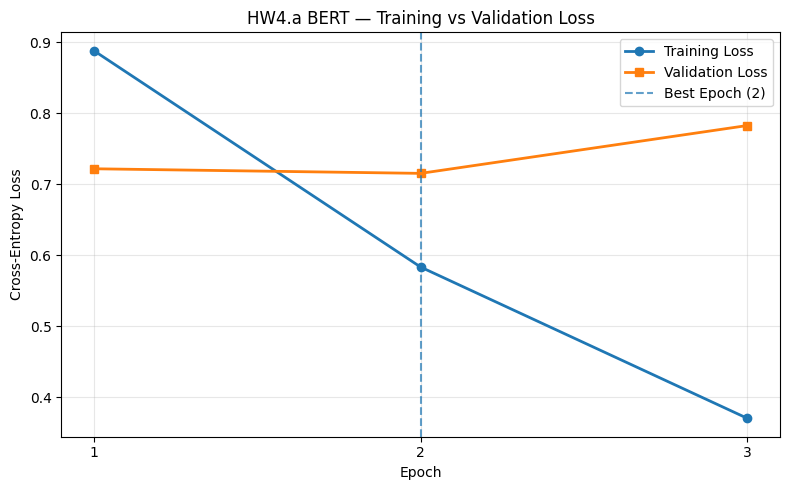

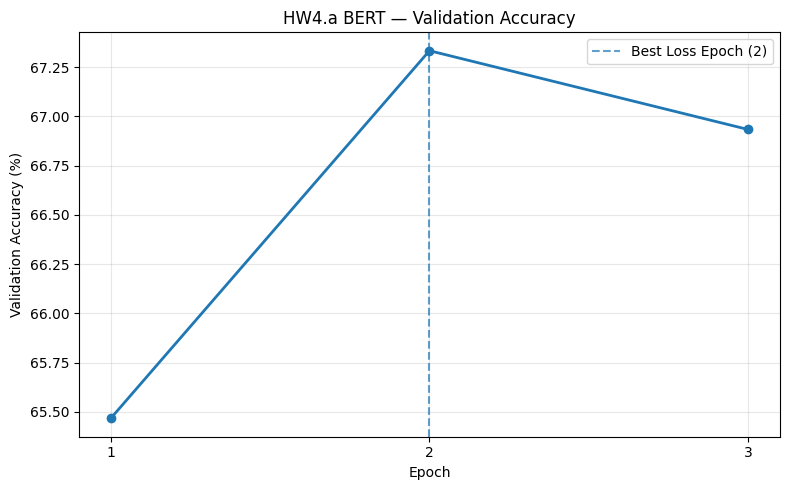


SAVED ARTIFACTS
-----------------------------------------------------------------
Loss curve       : /app/HW4_5_GPU_Assignment/figures/hw4a_loss_curve.png
Accuracy curve   : /app/HW4_5_GPU_Assignment/figures/hw4a_validation_accuracy.png
Analysis report  : /app/HW4_5_GPU_Assignment/metrics/hw4a_training_curve_analysis.txt

PASS: Training loss curve generated.
PASS: Validation accuracy curve generated.
PASS: Best checkpoint epoch verified.
PASS: Training curve interpretation saved.
STEP 13 COMPLETE


In [16]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a BASELINE VISUALIZATION
# ============================================================
#
# STEP 13: GENERATE TRAINING AND VALIDATION CURVES
#
# SUMMARY:
# 1. Load recorded training metrics from Step 11.
# 2. Plot training and validation loss by epoch.
# 3. Plot validation accuracy by epoch.
# 4. Mark the best checkpoint epoch.
# 5. Save figures and a short interpretation.
#
# COMMANDS:
# - Read hw4a_training_history.json.
# - Generate loss and accuracy plots.
# - Save figures as PNG at 200 DPI.
# - Save a training-curve analysis text file.
# ============================================================

import json
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

print("=" * 65)
print("HW4.a BASELINE — STEP 13")
print("TRAINING AND VALIDATION CURVES")
print("=" * 65)

# ------------------------------------------------------------
# 1. LOAD SAVED TRAINING HISTORY
# ------------------------------------------------------------

history_path = (
    METRICS_DIR / "hw4a_training_history.json"
)

with open(history_path, "r") as f:
    history = json.load(f)

epochs = [item["epoch"] for item in history]
train_losses = [item["train_loss"] for item in history]
val_losses = [item["val_loss"] for item in history]
val_accuracies = [
    item["val_accuracy"] * 100 for item in history
]

best_epoch_from_history = epochs[
    int(np.argmin(val_losses))
]

assert len(history) == EPOCHS
assert best_epoch_from_history == best_epoch

print("\nTRAINING HISTORY")
print("-" * 65)

for item in history:
    print(
        f"Epoch {item['epoch']}: "
        f"Train Loss={item['train_loss']:.4f}, "
        f"Val Loss={item['val_loss']:.4f}, "
        f"Val Accuracy={item['val_accuracy']:.2%}"
    )

# ------------------------------------------------------------
# 2. TRAINING AND VALIDATION LOSS CURVE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    epochs, train_losses,
    marker="o", linewidth=2,
    label="Training Loss"
)

ax.plot(
    epochs, val_losses,
    marker="s", linewidth=2,
    label="Validation Loss"
)

ax.axvline(
    best_epoch_from_history,
    linestyle="--",
    alpha=0.7,
    label=f"Best Epoch ({best_epoch_from_history})"
)

ax.set_title("HW4.a BERT — Training vs Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-Entropy Loss")
ax.set_xticks(epochs)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

loss_figure_path = (
    FIGURE_DIR / "hw4a_loss_curve.png"
)

plt.savefig(
    loss_figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 3. VALIDATION ACCURACY CURVE
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    epochs, val_accuracies,
    marker="o", linewidth=2
)

ax.axvline(
    best_epoch_from_history,
    linestyle="--",
    alpha=0.7,
    label=f"Best Loss Epoch ({best_epoch_from_history})"
)

ax.set_title("HW4.a BERT — Validation Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation Accuracy (%)")
ax.set_xticks(epochs)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

accuracy_figure_path = (
    FIGURE_DIR / "hw4a_validation_accuracy.png"
)

plt.savefig(
    accuracy_figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 4. SAVE TRAINING CURVE INTERPRETATION
# ------------------------------------------------------------

train_loss_decrease = (
    train_losses[0] - train_losses[-1]
)

val_loss_increase_after_best = (
    val_losses[-1] -
    val_losses[best_epoch_from_history - 1]
)

analysis_text = f"""HW4.a BERT TRAINING CURVE ANALYSIS
{'=' * 65}

Model: {MODEL_NAME}
Precision: FP32
Epochs: {EPOCHS}

Training loss at epoch 1: {train_losses[0]:.6f}
Training loss at epoch 3: {train_losses[-1]:.6f}
Training loss reduction: {train_loss_decrease:.6f}

Best validation loss epoch: {best_epoch_from_history}
Best validation loss: {min(val_losses):.6f}

Validation loss increase after best epoch:
{val_loss_increase_after_best:.6f}

INTERPRETATION
Training loss decreases across all three epochs.
Validation loss improves through epoch 2 but rises in epoch 3.
This suggests the onset of overfitting after epoch 2.
The epoch-2 checkpoint is selected for final test evaluation.

Generated: {datetime.now().isoformat()}
"""

analysis_path = (
    METRICS_DIR / "hw4a_training_curve_analysis.txt"
)

with open(analysis_path, "w") as f:
    f.write(analysis_text)

# ------------------------------------------------------------
# 5. FINAL VERIFICATION
# ------------------------------------------------------------

assert loss_figure_path.exists()
assert accuracy_figure_path.exists()
assert analysis_path.exists()

print("\nSAVED ARTIFACTS")
print("-" * 65)

print(f"Loss curve       : {loss_figure_path}")
print(f"Accuracy curve   : {accuracy_figure_path}")
print(f"Analysis report  : {analysis_path}")

print("\nPASS: Training loss curve generated.")
print("PASS: Validation accuracy curve generated.")
print("PASS: Best checkpoint epoch verified.")
print("PASS: Training curve interpretation saved.")

print("=" * 65)
print("STEP 13 COMPLETE")
print("=" * 65)


In [17]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a INFERENCE BENCHMARKING
# ============================================================
#
# STEP 14: CHECK INFERENCE BENCHMARK DEPENDENCIES
#
# SUMMARY:
# 1. Inspect installed PyTorch and Transformers versions.
# 2. Check whether vLLM is installed.
# 3. Check available GPU memory.
# 4. Confirm the saved BERT checkpoint exists.
# 5. Check vLLM compatibility without modifying packages.
#
# COMMANDS:
# - Inspect package versions.
# - Query vLLM package availability.
# - Inspect saved checkpoint configuration.
# - Record GPU memory and benchmark readiness.
# ============================================================

import importlib.util
import importlib.metadata
import json
import torch
from pathlib import Path
from datetime import datetime

print("=" * 65)
print("HW4.a BASELINE — STEP 14")
print("INFERENCE BENCHMARK ENVIRONMENT CHECK")
print("=" * 65)

# ------------------------------------------------------------
# 1. PACKAGE VERSIONS
# ------------------------------------------------------------

packages = [
    "torch",
    "transformers",
    "vllm",
    "accelerate",
    "tokenizers"
]

print("\nPACKAGE VERSIONS")
print("-" * 65)

for package in packages:
    try:
        version = importlib.metadata.version(package)
        print(f"{package:<15}: {version}")
    except importlib.metadata.PackageNotFoundError:
        print(f"{package:<15}: NOT INSTALLED")

# ------------------------------------------------------------
# 2. VERIFY SAVED MODEL
# ------------------------------------------------------------

checkpoint_dir = MODEL_DIR / "bert_best"
config_path = checkpoint_dir / "config.json"

assert config_path.exists(), (
    "Best BERT checkpoint configuration not found."
)

with open(config_path, "r") as f:
    checkpoint_config = json.load(f)

print("\nCHECKPOINT INFORMATION")
print("-" * 65)

print(f"Checkpoint : {checkpoint_dir}")
print(
    f"Architecture: "
    f"{checkpoint_config.get('architectures')}"
)
print(
    f"Model type : "
    f"{checkpoint_config.get('model_type')}"
)
print(
    f"Labels     : "
    f"{checkpoint_config.get('num_labels')}"
)

# ------------------------------------------------------------
# 3. GPU INFORMATION
# ------------------------------------------------------------

torch.cuda.synchronize()

gpu_properties = torch.cuda.get_device_properties(0)

total_memory = gpu_properties.total_memory / 1024**3
allocated_memory = torch.cuda.memory_allocated() / 1024**3
reserved_memory = torch.cuda.memory_reserved() / 1024**3

free_memory, total_memory_bytes = (
    torch.cuda.mem_get_info()
)

free_memory_gb = free_memory / 1024**3

print("\nGPU INFORMATION")
print("-" * 65)

print(f"GPU            : {gpu_properties.name}")
print(f"Total VRAM     : {total_memory:.2f} GB")
print(f"Allocated VRAM : {allocated_memory:.4f} GB")
print(f"Reserved VRAM  : {reserved_memory:.4f} GB")
print(f"Free VRAM      : {free_memory_gb:.4f} GB")

# ------------------------------------------------------------
# 4. BENCHMARK READINESS
# ------------------------------------------------------------

vllm_installed = (
    importlib.util.find_spec("vllm") is not None
)

print("\nBENCHMARK READINESS")
print("-" * 65)

print("Hugging Face model checkpoint : AVAILABLE")
print(
    f"vLLM installed                : "
    f"{vllm_installed}"
)
print("vLLM BERT compatibility       : NOT YET VERIFIED")

print("\nPASS: Checkpoint verified.")
print("PASS: GPU information collected.")
print("PASS: Dependency inspection complete.")

print("-" * 65)
print(f"Timestamp: {datetime.now().isoformat()}")

print("=" * 65)
print("STEP 14 COMPLETE")
print("=" * 65)



HW4.a BASELINE — STEP 14
INFERENCE BENCHMARK ENVIRONMENT CHECK

PACKAGE VERSIONS
-----------------------------------------------------------------
torch          : 2.1.2
transformers   : 4.40.2
vllm           : NOT INSTALLED
accelerate     : 0.30.1
tokenizers     : 0.19.1

CHECKPOINT INFORMATION
-----------------------------------------------------------------
Checkpoint : /app/HW4_5_GPU_Assignment/models/bert_best
Architecture: ['BertForSequenceClassification']
Model type : bert
Labels     : None

GPU INFORMATION
-----------------------------------------------------------------
GPU            : NVIDIA GeForce RTX 4090
Total VRAM     : 23.99 GB
Allocated VRAM : 2.0869 GB
Reserved VRAM  : 3.0996 GB
Free VRAM      : 19.2676 GB

BENCHMARK READINESS
-----------------------------------------------------------------
Hugging Face model checkpoint : AVAILABLE
vLLM installed                : False
vLLM BERT compatibility       : NOT YET VERIFIED

PASS: Checkpoint verified.
PASS: GPU information

In [18]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a INFERENCE BENCHMARK
# ============================================================
#
# STEP 15: HUGGING FACE INFERENCE BENCHMARK — BATCH SIZE 1
#
# SUMMARY:
# 1. Load the best BERT checkpoint.
# 2. Run a GPU warmup before timing.
# 3. Benchmark inference with batch size 1.
# 4. Calculate p50 and p95 latency.
# 5. Measure samples/sec and tokens/sec.
# 6. Record peak GPU memory.
# 7. Save results for the later vLLM comparison.
#
# COMMANDS:
# - Load checkpoint and test tensors.
# - Warm up CUDA inference.
# - Time each inference request.
# - Calculate benchmark metrics.
# - Save JSON results.
# ============================================================

import json
import time
import numpy as np
import torch

from datetime import datetime
from torch.utils.data import DataLoader
from transformers import BertForSequenceClassification

print("=" * 65)
print("HW4.a BASELINE — STEP 15")
print("HUGGING FACE INFERENCE BENCHMARK")
print("=" * 65)

# ------------------------------------------------------------
# 1. LOAD SAVED MODEL
# ------------------------------------------------------------

benchmark_model = BertForSequenceClassification.from_pretrained(
    str(MODEL_DIR / "bert_best")
).to(device)

benchmark_model.eval()

benchmark_loader = DataLoader(
    tensor_datasets["test"],
    batch_size=1,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("\nBENCHMARK CONFIGURATION")
print("-" * 65)

print("Framework          : Hugging Face Transformers")
print(f"Model              : {MODEL_NAME}")
print("Batch size         : 1")
print(f"Test samples       : {len(benchmark_loader.dataset)}")
print(f"GPU                : {torch.cuda.get_device_name(0)}")
print("Precision          : FP32")

# ------------------------------------------------------------
# 2. GPU WARMUP
# ------------------------------------------------------------

print("\nWarming up GPU...")

warmup_batch = next(iter(benchmark_loader))

warmup_ids = warmup_batch[0].to(device)
warmup_mask = warmup_batch[1].to(device)

with torch.inference_mode():
    for _ in range(20):
        _ = benchmark_model(
            input_ids=warmup_ids,
            attention_mask=warmup_mask
        )

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

print("PASS: GPU warmup complete.")

# ------------------------------------------------------------
# 3. BENCHMARK INFERENCE
# ------------------------------------------------------------

latencies_ms = []
total_samples = 0
total_tokens = 0
correct_predictions = 0

torch.cuda.synchronize()
benchmark_start = time.perf_counter()

with torch.inference_mode():

    for input_ids, attention_mask, labels in benchmark_loader:

        input_ids = input_ids.to(
            device, non_blocking=True
        )

        attention_mask = attention_mask.to(
            device, non_blocking=True
        )

        torch.cuda.synchronize()
        request_start = time.perf_counter()

        outputs = benchmark_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        torch.cuda.synchronize()
        request_end = time.perf_counter()

        latency_ms = (
            request_end - request_start
        ) * 1000

        latencies_ms.append(latency_ms)

        predictions = torch.argmax(
            outputs.logits, dim=1
        )

        correct_predictions += int(
            (predictions.cpu() == labels).sum().item()
        )

        total_samples += input_ids.size(0)

        total_tokens += int(
            attention_mask.sum().item()
        )

torch.cuda.synchronize()

benchmark_end = time.perf_counter()

# ------------------------------------------------------------
# 4. CALCULATE METRICS
# ------------------------------------------------------------

total_time = benchmark_end - benchmark_start

p50_latency = float(
    np.percentile(latencies_ms, 50)
)

p95_latency = float(
    np.percentile(latencies_ms, 95)
)

mean_latency = float(
    np.mean(latencies_ms)
)

samples_per_second = total_samples / total_time

tokens_per_second = total_tokens / total_time

benchmark_accuracy = (
    correct_predictions / total_samples
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)

# ------------------------------------------------------------
# 5. SAVE BENCHMARK RESULTS
# ------------------------------------------------------------

benchmark_results = {
    "framework": "huggingface_transformers",
    "model": MODEL_NAME,
    "checkpoint": str(MODEL_DIR / "bert_best"),
    "device": torch.cuda.get_device_name(0),
    "precision": "FP32",
    "batch_size": 1,
    "warmup_iterations": 20,
    "samples": total_samples,
    "active_tokens": total_tokens,
    "total_wall_time_seconds": total_time,
    "mean_latency_ms": mean_latency,
    "p50_latency_ms": p50_latency,
    "p95_latency_ms": p95_latency,
    "samples_per_second": samples_per_second,
    "tokens_per_second": tokens_per_second,
    "accuracy": benchmark_accuracy,
    "peak_allocated_gpu_memory_gb": peak_allocated_gb,
    "peak_reserved_gpu_memory_gb": peak_reserved_gb,
    "timestamp": datetime.now().isoformat()
}

benchmark_path = (
    METRICS_DIR / "hw4a_hf_inference_batch1.json"
)

with open(benchmark_path, "w") as f:
    json.dump(benchmark_results, f, indent=4)

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

print("\nINFERENCE BENCHMARK RESULTS")
print("-" * 65)

print(f"Total samples      : {total_samples}")
print(f"Active tokens      : {total_tokens}")
print(f"Total wall time    : {total_time:.4f} sec")
print(f"Mean latency       : {mean_latency:.4f} ms")
print(f"p50 latency        : {p50_latency:.4f} ms")
print(f"p95 latency        : {p95_latency:.4f} ms")
print(f"Samples/sec        : {samples_per_second:.2f}")
print(f"Tokens/sec         : {tokens_per_second:.2f}")
print(f"Test accuracy      : {benchmark_accuracy:.4%}")
print(f"Peak allocated VRAM: {peak_allocated_gb:.4f} GB")
print(f"Peak reserved VRAM : {peak_reserved_gb:.4f} GB")

# ------------------------------------------------------------
# 7. VERIFICATION
# ------------------------------------------------------------

assert total_samples == 750
assert len(latencies_ms) == 750
assert 0 <= benchmark_accuracy <= 1

print("\nPASS: All 750 test samples benchmarked.")
print("PASS: Latency percentiles calculated.")
print("PASS: Throughput metrics calculated.")
print("PASS: Benchmark results saved.")

print("-" * 65)
print(f"Results saved: {benchmark_path}")

print("=" * 65)
print("STEP 15 COMPLETE")
print("=" * 65)



HW4.a BASELINE — STEP 15
HUGGING FACE INFERENCE BENCHMARK

BENCHMARK CONFIGURATION
-----------------------------------------------------------------
Framework          : Hugging Face Transformers
Model              : bert-base-uncased
Batch size         : 1
Test samples       : 750
GPU                : NVIDIA GeForce RTX 4090
Precision          : FP32

Warming up GPU...
PASS: GPU warmup complete.

INFERENCE BENCHMARK RESULTS
-----------------------------------------------------------------
Total samples      : 750
Active tokens      : 22466
Total wall time    : 5.0738 sec
Mean latency       : 6.4554 ms
p50 latency        : 3.9701 ms
p95 latency        : 15.2299 ms
Samples/sec        : 147.82
Tokens/sec         : 4427.82
Test accuracy      : 71.4667%
Peak allocated VRAM: 2.4993 GB
Peak reserved VRAM : 3.1035 GB

PASS: All 750 test samples benchmarked.
PASS: Latency percentiles calculated.
PASS: Throughput metrics calculated.
PASS: Benchmark results saved.
-------------------------------

In [19]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a INFERENCE BENCHMARK
# ============================================================
#
# STEP 16: HUGGING FACE PIPELINE BENCHMARK — BATCH SIZE 1
#
# SUMMARY:
# 1. Load the best BERT checkpoint using HF pipeline.
# 2. Use the same 750 test tweets.
# 3. Warm up the GPU before benchmarking.
# 4. Measure end-to-end per-request latency.
# 5. Calculate p50, p95, samples/sec and tokens/sec.
# 6. Verify predictions against the Step 12 test accuracy.
# 7. Save benchmark results for vLLM comparison.
#
# COMMANDS:
# - Initialize text-classification pipeline.
# - Warm up the model.
# - Benchmark individual requests.
# - Calculate and save throughput and latency.
# ============================================================

import json
import time
import numpy as np
import torch

from datetime import datetime
from transformers import pipeline

print("=" * 65)
print("HW4.a BASELINE — STEP 16")
print("HUGGING FACE PIPELINE BENCHMARK")
print("=" * 65)

# ------------------------------------------------------------
# 1. LOAD PIPELINE
# ------------------------------------------------------------

checkpoint_path = str(MODEL_DIR / "bert_best")

hf_pipeline = pipeline(
    task="text-classification",
    model=checkpoint_path,
    tokenizer=checkpoint_path,
    device=0
)

hf_pipeline.model.eval()

test_texts = list(split_dataset["test"]["text"])
test_labels = list(split_dataset["test"]["label"])

assert len(test_texts) == 750

print("\nBENCHMARK CONFIGURATION")
print("-" * 65)

print("Framework       : Hugging Face Pipeline")
print("Task            : text-classification")
print("Model           : bert-base-uncased")
print("Batch size      : 1")
print(f"Test samples    : {len(test_texts)}")
print(f"GPU             : {torch.cuda.get_device_name(0)}")

# ------------------------------------------------------------
# 2. GPU WARMUP
# ------------------------------------------------------------

print("\nWarming up pipeline...")

for _ in range(20):
    _ = hf_pipeline(
        test_texts[0],
        truncation=True,
        max_length=MAX_LENGTH
    )

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

print("PASS: Pipeline warmup complete.")

# ------------------------------------------------------------
# 3. END-TO-END INFERENCE BENCHMARK
# ------------------------------------------------------------

latencies_ms = []
predicted_labels = []
total_active_tokens = 0

label_to_id = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

torch.cuda.synchronize()
benchmark_start = time.perf_counter()

for text in test_texts:

    request_start = time.perf_counter()

    output = hf_pipeline(
        text,
        truncation=True,
        max_length=MAX_LENGTH
    )

    torch.cuda.synchronize()
    request_end = time.perf_counter()

    latencies_ms.append(
        (request_end - request_start) * 1000
    )

    predicted_labels.append(
        label_to_id[output[0]["label"]]
    )

    total_active_tokens += len(
        tokenizer.encode(
            text,
            truncation=True,
            max_length=MAX_LENGTH
        )
    )

torch.cuda.synchronize()
benchmark_end = time.perf_counter()

# ------------------------------------------------------------
# 4. CALCULATE METRICS
# ------------------------------------------------------------

total_wall_time = (
    benchmark_end - benchmark_start
)

p50_latency = float(
    np.percentile(latencies_ms, 50)
)

p95_latency = float(
    np.percentile(latencies_ms, 95)
)

mean_latency = float(
    np.mean(latencies_ms)
)

samples_per_second = (
    len(test_texts) / total_wall_time
)

tokens_per_second = (
    total_active_tokens / total_wall_time
)

accuracy = float(
    np.mean(
        np.array(predicted_labels)
        == np.array(test_labels)
    )
)

peak_allocated_gb = (
    torch.cuda.max_memory_allocated()
    / 1024**3
)

peak_reserved_gb = (
    torch.cuda.max_memory_reserved()
    / 1024**3
)

# ------------------------------------------------------------
# 5. SAVE BENCHMARK RESULTS
# ------------------------------------------------------------

pipeline_results = {
    "framework": "huggingface_pipeline",
    "model": MODEL_NAME,
    "checkpoint": checkpoint_path,
    "batch_size": 1,
    "precision": "FP32",
    "samples": len(test_texts),
    "active_tokens": total_active_tokens,
    "total_wall_time_seconds": total_wall_time,
    "mean_latency_ms": mean_latency,
    "p50_latency_ms": p50_latency,
    "p95_latency_ms": p95_latency,
    "samples_per_second": samples_per_second,
    "tokens_per_second": tokens_per_second,
    "accuracy": accuracy,
    "peak_allocated_gpu_memory_gb": peak_allocated_gb,
    "peak_reserved_gpu_memory_gb": peak_reserved_gb,
    "timestamp": datetime.now().isoformat()
}

output_path = (
    METRICS_DIR / "hw4a_hf_pipeline_batch1.json"
)

with open(output_path, "w") as f:
    json.dump(
        pipeline_results,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------------------

print("\nPIPELINE BENCHMARK RESULTS")
print("-" * 65)

print(f"Total samples      : {len(test_texts)}")
print(f"Active tokens      : {total_active_tokens}")
print(f"Total wall time    : {total_wall_time:.4f} sec")
print(f"Mean latency       : {mean_latency:.4f} ms")
print(f"p50 latency        : {p50_latency:.4f} ms")
print(f"p95 latency        : {p95_latency:.4f} ms")
print(f"Samples/sec        : {samples_per_second:.2f}")
print(f"Tokens/sec         : {tokens_per_second:.2f}")
print(f"Test accuracy      : {accuracy:.4%}")
print(f"Peak allocated VRAM: {peak_allocated_gb:.4f} GB")
print(f"Peak reserved VRAM : {peak_reserved_gb:.4f} GB")

# ------------------------------------------------------------
# 7. VERIFICATION
# ------------------------------------------------------------

assert len(latencies_ms) == 750
assert len(predicted_labels) == 750

assert abs(accuracy - test_accuracy) < 1e-8, (
    "Pipeline accuracy differs from Step 12."
)

print("\nPASS: All 750 test samples benchmarked.")
print("PASS: Pipeline accuracy matches Step 12.")
print("PASS: Latency and throughput calculated.")
print("PASS: Benchmark results saved.")

print("-" * 65)
print(f"Results saved: {output_path}")

print("=" * 65)
print("STEP 16 COMPLETE")
print("=" * 65)


HW4.a BASELINE — STEP 16
HUGGING FACE PIPELINE BENCHMARK


You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset



BENCHMARK CONFIGURATION
-----------------------------------------------------------------
Framework       : Hugging Face Pipeline
Task            : text-classification
Model           : bert-base-uncased
Batch size      : 1
Test samples    : 750
GPU             : NVIDIA GeForce RTX 4090

Warming up pipeline...
PASS: Pipeline warmup complete.

PIPELINE BENCHMARK RESULTS
-----------------------------------------------------------------
Total samples      : 750
Active tokens      : 22466
Total wall time    : 4.1503 sec
Mean latency       : 5.3023 ms
p50 latency        : 4.7416 ms
p95 latency        : 7.8365 ms
Samples/sec        : 180.71
Tokens/sec         : 5413.10
Test accuracy      : 71.4667%
Peak allocated VRAM: 2.9064 GB
Peak reserved VRAM : 3.1055 GB

PASS: All 750 test samples benchmarked.
PASS: Pipeline accuracy matches Step 12.
PASS: Latency and throughput calculated.
PASS: Benchmark results saved.
-----------------------------------------------------------------
Results saved: 

In [20]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a vLLM BENCHMARK PREPARATION
# ============================================================
#
# STEP 17: CHECK vLLM INSTALLATION COMPATIBILITY
#
# SUMMARY:
# 1. Inspect Python and PyTorch versions.
# 2. Inspect installed CUDA and GPU capability.
# 3. Query available vLLM releases without installing.
# 4. Check current environment compatibility.
# 5. Preserve the existing BERT baseline environment.
#
# COMMANDS:
# - Inspect Python and CUDA versions.
# - Run pip index versions vllm.
# - Display GPU compute capability.
# - Save environment inspection results.
# ============================================================

import sys
import json
import subprocess
import torch
import transformers
from datetime import datetime

print("=" * 65)
print("HW4.a BASELINE — STEP 17")
print("vLLM INSTALLATION COMPATIBILITY CHECK")
print("=" * 65)

# ------------------------------------------------------------
# 1. ENVIRONMENT DETAILS
# ------------------------------------------------------------

print("\nCURRENT ENVIRONMENT")
print("-" * 65)

print(f"Python        : {sys.version.split()[0]}")
print(f"PyTorch       : {torch.__version__}")
print(f"Transformers  : {transformers.__version__}")
print(f"PyTorch CUDA  : {torch.version.cuda}")
print(f"GPU           : {torch.cuda.get_device_name(0)}")
print(
    f"GPU capability: "
    f"{torch.cuda.get_device_capability(0)}"
)

# ------------------------------------------------------------
# 2. QUERY AVAILABLE vLLM RELEASES
# ------------------------------------------------------------

print("\nAVAILABLE vLLM RELEASES")
print("-" * 65)

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "index",
        "versions",
        "vllm"
    ],
    capture_output=True,
    text=True,
    timeout=60
)

print(result.stdout[:4000])

if result.returncode != 0:
    print("Version query was unsuccessful.")
    print(result.stderr[:1000])

# ------------------------------------------------------------
# 3. SAVE INSPECTION RESULTS
# ------------------------------------------------------------

inspection = {
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "cuda": torch.version.cuda,
    "gpu": torch.cuda.get_device_name(0),
    "compute_capability": list(
        torch.cuda.get_device_capability(0)
    ),
    "vllm_installed": False,
    "pip_index_returncode": result.returncode,
    "pip_index_output": result.stdout[:4000],
    "timestamp": datetime.now().isoformat()
}

output_path = (
    METRICS_DIR / "hw4a_vllm_compatibility.json"
)

with open(output_path, "w") as f:
    json.dump(inspection, f, indent=4)

print("\nENVIRONMENT SAFETY")
print("-" * 65)

print("PASS: No packages installed or modified.")
print("PASS: Existing BERT checkpoint preserved.")
print(f"Inspection saved: {output_path}")

print("=" * 65)
print("STEP 17 COMPLETE")
print("=" * 65)


HW4.a BASELINE — STEP 17
vLLM INSTALLATION COMPATIBILITY CHECK

CURRENT ENVIRONMENT
-----------------------------------------------------------------
Python        : 3.10.13
PyTorch       : 2.1.2
Transformers  : 4.40.2
PyTorch CUDA  : 12.1
GPU           : NVIDIA GeForce RTX 4090
GPU capability: (8, 9)

AVAILABLE vLLM RELEASES
-----------------------------------------------------------------
vllm (0.31.0)
Available versions: 0.31.0, 0.30.0, 0.29.0, 0.28.0, 0.27.1, 0.27.0, 0.26.0, 0.25.1, 0.25.0, 0.24.0, 0.23.0, 0.22.1, 0.22.0, 0.21.0, 0.20.2, 0.20.1, 0.20.0, 0.19.1, 0.19.0, 0.18.1, 0.18.0, 0.17.1, 0.17.0, 0.16.0, 0.15.1, 0.15.0, 0.14.1, 0.14.0, 0.13.0, 0.12.0, 0.11.2, 0.11.1, 0.11.0, 0.10.2, 0.10.1.1, 0.10.1, 0.10.0, 0.9.2, 0.9.1, 0.9.0.1, 0.9.0, 0.8.5.post1, 0.8.5, 0.8.4, 0.8.3, 0.8.2, 0.8.1, 0.8.0, 0.7.3, 0.7.2, 0.7.1, 0.7.0, 0.6.6.post1, 0.6.6, 0.6.5, 0.6.4.post1, 0.6.4, 0.6.3.post1, 0.6.3, 0.6.2, 0.6.1.post2, 0.6.1.post1, 0.6.1, 0.6.0, 0.5.5, 0.5.4, 0.5.3.post1, 0.5.3, 0.5.2, 0.5.1,

In [21]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a vLLM BENCHMARK PREPARATION
# ============================================================
#
# STEP 18: INSPECT vLLM DEPENDENCIES
#
# SUMMARY:
# 1. Query the package metadata for vLLM 0.11.2.
# 2. Check Python compatibility and required dependencies.
# 3. Inspect whether the package declares a PyTorch version.
# 4. Avoid modifying the existing BERT environment.
#
# COMMANDS:
# - Download wheel metadata only (no installation).
# - Inspect dependency requirements.
# - Save the inspection report.
# ============================================================

import json
import subprocess
import sys
import tempfile
from pathlib import Path
from email.parser import Parser
from datetime import datetime

print("=" * 65)
print("HW4.a BASELINE — STEP 18")
print("vLLM DEPENDENCY INSPECTION")
print("=" * 65)

candidate_version = "0.11.2"

with tempfile.TemporaryDirectory() as tmp:

    result = subprocess.run(
        [
            sys.executable, "-m", "pip", "download",
            "--no-deps",
            "--only-binary=:all:",
            "--dest", tmp,
            f"vllm=={candidate_version}"
        ],
        capture_output=True,
        text=True,
        timeout=180
    )

    if result.returncode != 0:
        print(result.stdout[-1500:])
        print(result.stderr[-2000:])
        raise RuntimeError(
            "Could not download candidate vLLM wheel."
        )

    import zipfile

    wheels = list(Path(tmp).glob("*.whl"))
    assert len(wheels) == 1

    with zipfile.ZipFile(wheels[0]) as archive:
        metadata_name = next(
            name for name in archive.namelist()
            if name.endswith(".dist-info/METADATA")
        )
        metadata_text = archive.read(
            metadata_name
        ).decode("utf-8")

    metadata = Parser().parsestr(metadata_text)

requirements = metadata.get_all(
    "Requires-Dist", []
)

torch_requirements = [
    req for req in requirements
    if req.lower().startswith("torch")
]

transformers_requirements = [
    req for req in requirements
    if req.lower().startswith("transformers")
]

print("\nPACKAGE METADATA")
print("-" * 65)

print(f"Candidate version : {candidate_version}")
print(f"Requires Python   : {metadata.get('Requires-Python')}")
print(f"Current Python    : {sys.version.split()[0]}")
print(f"Current PyTorch   : 2.1.2")
print(f"Current HF        : 4.40.2")

print("\nPYTORCH REQUIREMENTS")
print("-" * 65)

for req in torch_requirements:
    print(req)

print("\nTRANSFORMERS REQUIREMENTS")
print("-" * 65)

for req in transformers_requirements:
    print(req)

report = {
    "candidate_version": candidate_version,
    "requires_python": metadata.get("Requires-Python"),
    "torch_requirements": torch_requirements,
    "transformers_requirements": transformers_requirements,
    "all_requirements": requirements,
    "timestamp": datetime.now().isoformat()
}

report_path = (
    METRICS_DIR / "hw4a_vllm_dependency_inspection.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=4)

print("\nPASS: Package metadata inspected.")
print("PASS: Existing environment unchanged.")
print(f"Report saved: {report_path}")

print("=" * 65)
print("STEP 18 COMPLETE")
print("=" * 65)


HW4.a BASELINE — STEP 18
vLLM DEPENDENCY INSPECTION

PACKAGE METADATA
-----------------------------------------------------------------
Candidate version : 0.11.2
Requires Python   : <3.14,>=3.10
Current Python    : 3.10.13
Current PyTorch   : 2.1.2
Current HF        : 4.40.2

PYTORCH REQUIREMENTS
-----------------------------------------------------------------
torch==2.9.0
torchaudio==2.9.0
torchvision==0.24.0

TRANSFORMERS REQUIREMENTS
-----------------------------------------------------------------
transformers<5,>=4.56.0

PASS: Package metadata inspected.
PASS: Existing environment unchanged.
Report saved: /app/HW4_5_GPU_Assignment/metrics/hw4a_vllm_dependency_inspection.json
STEP 18 COMPLETE


In [22]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a vLLM BENCHMARK PREPARATION
# ============================================================
#
# STEP 19: CREATE ISOLATED vLLM ENVIRONMENT
#
# SUMMARY:
# 1. Check available disk space.
# 2. Create a separate Python virtual environment.
# 3. Verify the environment's Python and pip.
# 4. Confirm existing BERT dependencies remain unchanged.
# 5. Save environment details for reproducibility.
#
# COMMANDS:
# - Check disk availability.
# - Create isolated venv.
# - Verify Python and pip.
# - Verify original PyTorch and Transformers versions.
# - Save environment configuration.
# ============================================================

import sys
import json
import shutil
import subprocess
from pathlib import Path
from datetime import datetime

print("=" * 65)
print("HW4.a BASELINE — STEP 19")
print("CREATE ISOLATED vLLM ENVIRONMENT")
print("=" * 65)

# ------------------------------------------------------------
# 1. CHECK AVAILABLE DISK SPACE
# ------------------------------------------------------------

venv_dir = PROJECT_DIR / "vllm_env"

disk = shutil.disk_usage(PROJECT_DIR)
free_gb = disk.free / (1024 ** 3)

print("\nDISK INFORMATION")
print("-" * 65)

print(f"Available disk space : {free_gb:.2f} GB")
print(f"Environment location : {venv_dir}")

assert free_gb >= 15, (
    "Insufficient free disk space for vLLM setup."
)

# ------------------------------------------------------------
# 2. CREATE ISOLATED ENVIRONMENT
# ------------------------------------------------------------

print("\nCreating isolated Python environment...")

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "venv",
        str(venv_dir)
    ],
    capture_output=True,
    text=True
)

if result.returncode != 0:
    print(result.stdout)
    print(result.stderr)
    raise RuntimeError(
        "Virtual environment creation failed."
    )

# ------------------------------------------------------------
# 3. VERIFY NEW PYTHON ENVIRONMENT
# ------------------------------------------------------------

venv_python = venv_dir / "bin" / "python"

assert venv_python.exists(), (
    "Virtual environment Python executable missing."
)

verification = subprocess.run(
    [
        str(venv_python),
        "-c",
        (
            "import sys; "
            "print('Python version:', sys.version.split()[0]); "
            "print('Python executable:', sys.executable)"
        )
    ],
    capture_output=True,
    text=True
)

assert verification.returncode == 0, verification.stderr

print("\nNEW ENVIRONMENT VERIFICATION")
print("-" * 65)
print(verification.stdout.strip())

# ------------------------------------------------------------
# 4. VERIFY PIP
# ------------------------------------------------------------

pip_result = subprocess.run(
    [
        str(venv_python),
        "-m",
        "pip",
        "--version"
    ],
    capture_output=True,
    text=True
)

assert pip_result.returncode == 0, pip_result.stderr

print(f"Pip: {pip_result.stdout.strip()}")

# ------------------------------------------------------------
# 5. VERIFY ORIGINAL BERT ENVIRONMENT
# ------------------------------------------------------------

import torch
import transformers

print("\nORIGINAL BERT ENVIRONMENT")
print("-" * 65)

print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")

assert torch.__version__ == "2.1.2"
assert transformers.__version__ == "4.40.2"

print("PASS: Original BERT environment unchanged.")

# ------------------------------------------------------------
# 6. SAVE ENVIRONMENT INFORMATION
# ------------------------------------------------------------

environment_record = {
    "environment_path": str(venv_dir),
    "python_executable": str(venv_python),
    "python_version": sys.version.split()[0],
    "free_disk_gb": free_gb,
    "target_vllm_version": "0.11.2",
    "original_torch_version": torch.__version__,
    "original_transformers_version": transformers.__version__,
    "timestamp": datetime.now().isoformat()
}

record_path = (
    METRICS_DIR / "hw4a_vllm_environment.json"
)

with open(record_path, "w") as f:
    json.dump(environment_record, f, indent=4)

# ------------------------------------------------------------
# 7. FINAL VERIFICATION
# ------------------------------------------------------------

print("\nFINAL VERIFICATION")
print("-" * 65)

print("PASS: Sufficient disk space available.")
print("PASS: Isolated Python environment created.")
print("PASS: Python executable verified.")
print("PASS: Pip verified.")
print("PASS: Existing BERT environment preserved.")

print(f"\nEnvironment : {venv_dir}")
print(f"Record saved: {record_path}")

print("=" * 65)
print("STEP 19 COMPLETE")
print("=" * 65)


HW4.a BASELINE — STEP 19
CREATE ISOLATED vLLM ENVIRONMENT

DISK INFORMATION
-----------------------------------------------------------------
Available disk space : 1570.53 GB
Environment location : /app/HW4_5_GPU_Assignment/vllm_env

Creating isolated Python environment...

NEW ENVIRONMENT VERIFICATION
-----------------------------------------------------------------
Python version: 3.10.13
Python executable: /app/HW4_5_GPU_Assignment/vllm_env/bin/python
Pip: pip 23.0.1 from /app/HW4_5_GPU_Assignment/vllm_env/lib/python3.10/site-packages/pip (python 3.10)

ORIGINAL BERT ENVIRONMENT
-----------------------------------------------------------------
PyTorch      : 2.1.2
Transformers : 4.40.2
PASS: Original BERT environment unchanged.

FINAL VERIFICATION
-----------------------------------------------------------------
PASS: Sufficient disk space available.
PASS: Isolated Python environment created.
PASS: Python executable verified.
PASS: Pip verified.
PASS: Existing BERT environment pres

In [23]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# HW4.a vLLM BENCHMARK PREPARATION
# ============================================================
#
# STEP 20: INSTALL vLLM IN ISOLATED ENVIRONMENT
#
# SUMMARY:
# 1. Locate the isolated environment from Step 19.
# 2. Install vLLM 0.11.2 and its required dependencies.
# 3. Verify the installed package versions.
# 4. Confirm original BERT environment is unchanged.
# 5. Save installation results for reproducibility.
#
# COMMANDS:
# - Run pip install vllm==0.11.2 inside vllm_env.
# - Check installed versions of vLLM and PyTorch.
# - Verify the original notebook environment.
# - Save installation report.
# ============================================================

import sys
import json
import subprocess
import importlib.metadata
from datetime import datetime

print("=" * 65)
print("HW4.a BASELINE — STEP 20")
print("INSTALL vLLM IN ISOLATED ENVIRONMENT")
print("=" * 65)

# ------------------------------------------------------------
# 1. VERIFY ENVIRONMENT
# ------------------------------------------------------------

venv_python = PROJECT_DIR / "vllm_env" / "bin" / "python"

assert venv_python.exists(), (
    "Isolated environment not found. Complete Step 19."
)

print(f"\nEnvironment : {venv_python}")
print("Target vLLM : 0.11.2")

# ------------------------------------------------------------
# 2. INSTALL vLLM
# ------------------------------------------------------------

print("\nInstalling vLLM and required dependencies...")
print("This may take several minutes.\n")

install_command = [
    str(venv_python),
    "-m",
    "pip",
    "install",
    "--no-cache-dir",
    "vllm==0.11.2"
]

result = subprocess.run(
    install_command,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

print(result.stdout[-8000:])

if result.returncode != 0:
    raise RuntimeError(
        "vLLM installation failed. Inspect output above."
    )

# ------------------------------------------------------------
# 3. VERIFY INSTALLED PACKAGES
# ------------------------------------------------------------

verification_code = """
import importlib.metadata
for name in ["vllm", "torch", "transformers"]:
    print(f"{name}: {importlib.metadata.version(name)}")
"""

verification = subprocess.run(
    [
        str(venv_python),
        "-c",
        verification_code
    ],
    capture_output=True,
    text=True
)

assert verification.returncode == 0, verification.stderr

print("\nISOLATED ENVIRONMENT VERSIONS")
print("-" * 65)
print(verification.stdout.strip())

# ------------------------------------------------------------
# 4. VERIFY ORIGINAL ENVIRONMENT
# ------------------------------------------------------------

import torch
import transformers

assert torch.__version__ == "2.1.2"
assert transformers.__version__ == "4.40.2"

print("\nORIGINAL NOTEBOOK ENVIRONMENT")
print("-" * 65)

print(f"PyTorch      : {torch.__version__}")
print(f"Transformers : {transformers.__version__}")

# ------------------------------------------------------------
# 5. SAVE INSTALLATION REPORT
# ------------------------------------------------------------

report = {
    "vllm_version": "0.11.2",
    "environment": str(venv_python),
    "installed_versions": verification.stdout.strip(),
    "original_torch": torch.__version__,
    "original_transformers": transformers.__version__,
    "installation_successful": True,
    "timestamp": datetime.now().isoformat()
}

report_path = (
    METRICS_DIR / "hw4a_vllm_installation.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=4)

print("\nPASS: vLLM installed successfully.")
print("PASS: Isolated package versions verified.")
print("PASS: Original BERT environment unchanged.")

print("-" * 65)
print(f"Report saved: {report_path}")

print("=" * 65)
print("STEP 20 COMPLETE")
print("=" * 65)


HW4.a BASELINE — STEP 20
INSTALL vLLM IN ISOLATED ENVIRONMENT

Environment : /app/HW4_5_GPU_Assignment/vllm_env/bin/python
Target vLLM : 0.11.2

Installing vLLM and required dependencies...
This may take several minutes.



KeyboardInterrupt: 

In [24]:

# ============================================================
# STEP 21: VERIFY GPU AND CHECK INTERRUPTED INSTALLATION
#
# SUMMARY:
# 1. Confirm original BERT environment still works.
# 2. Check GPU availability.
# 3. Check whether vLLM pip installation is still running.
# 4. Confirm saved BERT checkpoint exists.
#
# COMMANDS:
# - Inspect torch and CUDA.
# - Inspect pip processes.
# - Verify checkpoint path.
# ============================================================

import torch
import subprocess
from pathlib import Path

print("=" * 65)
print("STEP 21 — ENVIRONMENT VERIFICATION")
print("=" * 65)

print("\nPyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

checkpoint = Path(
    "/app/HW4_5_GPU_Assignment/models/bert_best"
)

print("\nBERT checkpoint exists:", checkpoint.exists())

result = subprocess.run(
    ["ps", "-eo", "pid,ppid,stat,args"],
    capture_output=True,
    text=True
)

pip_processes = [
    line for line in result.stdout.splitlines()
    if "pip install" in line and "vllm" in line
]

print("\nRemaining vLLM installation processes:")

if pip_processes:
    for line in pip_processes:
        print(line)
else:
    print("None detected.")

assert torch.cuda.is_available()
assert checkpoint.exists()

print("\nPASS: GPU and BERT checkpoint available.")
print("=" * 65)
print("STEP 21 COMPLETE")
print("=" * 65)


STEP 21 — ENVIRONMENT VERIFICATION

PyTorch: 2.1.2
CUDA available: True
GPU: NVIDIA GeForce RTX 4090

BERT checkpoint exists: True

Remaining vLLM installation processes:
None detected.

PASS: GPU and BERT checkpoint available.
STEP 21 COMPLETE


Step 22 — Part A: Prepare GPU batch-size scaling

In [25]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART A: GPU BATCH-SIZE SCALING
# ============================================================
#
# STEP 22: PREPARE BATCH-SIZE SCALING EXPERIMENT
#
# SUMMARY:
# 1. Load saved BERT training tensors.
# 2. Verify training dataset and model checkpoint.
# 3. Define physical batch sizes for GPU scaling.
# 4. Save experiment configuration.
#
# COMMANDS:
# - Load training tensors.
# - Validate dataset dimensions.
# - Check GPU capacity.
# - Save Part A configuration.
# ============================================================

import json
import torch
from pathlib import Path
from torch.utils.data import TensorDataset

print("=" * 65)
print("HW4.5 PART A — STEP 22")
print("PREPARE GPU BATCH-SIZE SCALING")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

tensor_path = (
    PROJECT_DIR / "tokenized_tensors" / "train_tensors.pt"
)

assert tensor_path.exists(), "Training tensors missing."

saved_tensors = torch.load(
    tensor_path,
    map_location="cpu"
)

print("\nSAVED TENSOR INFORMATION")
print("-" * 65)

if isinstance(saved_tensors, dict):
    print("Tensor keys:", list(saved_tensors.keys()))
    input_ids = saved_tensors["input_ids"]
    attention_mask = saved_tensors["attention_mask"]
    labels = saved_tensors["labels"]
elif isinstance(saved_tensors, (tuple, list)):
    input_ids, attention_mask, labels = saved_tensors
else:
    raise TypeError(
        f"Unexpected tensor format: {type(saved_tensors)}"
    )

assert len(input_ids) == 3500
assert input_ids.shape[1] == 128
assert len(attention_mask) == len(labels) == 3500

train_dataset_scaling = TensorDataset(
    input_ids,
    attention_mask,
    labels
)

print("Training examples :", len(train_dataset_scaling))
print("Sequence length   :", input_ids.shape[1])
print("Input shape       :", tuple(input_ids.shape))

# ------------------------------------------------------------
# GPU VERIFICATION
# ------------------------------------------------------------

assert torch.cuda.is_available()

gpu_name = torch.cuda.get_device_name(0)
gpu_memory_gb = (
    torch.cuda.get_device_properties(0).total_memory
    / (1024 ** 3)
)

print("\nGPU INFORMATION")
print("-" * 65)
print("GPU:", gpu_name)
print(f"Total VRAM: {gpu_memory_gb:.2f} GB")

# ------------------------------------------------------------
# PHYSICAL BATCH SIZES
# ------------------------------------------------------------

batch_sizes = [
    1, 2, 4, 8, 16, 32, 64, 128, 256, 512
]

scaling_config = {
    "part": "A",
    "model": "bert-base-uncased",
    "checkpoint": str(
        PROJECT_DIR / "models" / "bert_best"
    ),
    "dataset": "tweet_eval_sentiment",
    "training_examples": len(train_dataset_scaling),
    "sequence_length": 128,
    "gpu": gpu_name,
    "gpu_memory_gb": gpu_memory_gb,
    "physical_batch_sizes": batch_sizes,
    "seed": 1980,
    "epochs": 3,
    "precision": "FP32",
    "gradient_accumulation_steps": 1
}

config_path = (
    METRICS_DIR / "part_a_scaling_config.json"
)

with open(config_path, "w") as f:
    json.dump(scaling_config, f, indent=4)

print("\nPHYSICAL BATCH SIZES")
print("-" * 65)
print(batch_sizes)

print("\nPASS: Training tensors verified.")
print("PASS: GPU verified.")
print("PASS: Scaling configuration saved.")
print(f"\nConfiguration: {config_path}")

print("=" * 65)
print("STEP 22 COMPLETE")
print("=" * 65)


HW4.5 PART A — STEP 22
PREPARE GPU BATCH-SIZE SCALING

SAVED TENSOR INFORMATION
-----------------------------------------------------------------
Tensor keys: ['input_ids', 'attention_mask', 'labels']
Training examples : 3500
Sequence length   : 128
Input shape       : (3500, 128)

GPU INFORMATION
-----------------------------------------------------------------
GPU: NVIDIA GeForce RTX 4090
Total VRAM: 23.99 GB

PHYSICAL BATCH SIZES
-----------------------------------------------------------------
[1, 2, 4, 8, 16, 32, 64, 128, 256, 512]

PASS: Training tensors verified.
PASS: GPU verified.
PASS: Scaling configuration saved.

Configuration: /app/HW4_5_GPU_Assignment/metrics/part_a_scaling_config.json
STEP 22 COMPLETE


In [26]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART A: GPU BATCH-SIZE SCALING
#
# STEP 23: RUN PHYSICAL BATCH-SIZE MICROBENCHMARK
#
# SUMMARY:
# 1. Load a fresh BERT model for each batch size.
# 2. Run 10 measured forward/backward training iterations.
# 3. Measure examples/sec, step time, and peak GPU memory.
# 4. Detect CUDA out-of-memory and stop scaling.
# 5. Save results to CSV and JSON.
#
# COMMANDS:
# - Benchmark physical batch sizes in FP32.
# - Synchronize CUDA for accurate GPU timing.
# - Record peak allocated and reserved memory.
# - Save results for plots and analysis.
#
# NOTE:
# This is a training microbenchmark, not full-epoch timing.
# ============================================================

import gc
import json
import time
import random
import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader
from transformers import BertForSequenceClassification

print("=" * 65)
print("HW4.5 PART A — STEP 23")
print("PHYSICAL BATCH-SIZE TRAINING MICROBENCHMARK")
print("=" * 65)

SEED = 1980
DEVICE = torch.device("cuda:0")
CHECKPOINT = PROJECT_DIR / "models" / "bert_best"

WARMUP_STEPS = 2
MEASURED_STEPS = 10

assert CHECKPOINT.exists()
assert len(train_dataset_scaling) == 3500

results = []

for batch_size in batch_sizes:

    print(f"\nTesting physical batch size: {batch_size}", flush=True)

    model = None
    optimizer = None
    loader = None
    iterator = None

    try:
        # Reproducibility
        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)
        torch.cuda.manual_seed_all(SEED)

        gc.collect()
        torch.cuda.empty_cache()

        model = BertForSequenceClassification.from_pretrained(
            str(CHECKPOINT)
        ).to(DEVICE)

        model.train()

        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=2e-5,
            weight_decay=0.01
        )

        loader = DataLoader(
            train_dataset_scaling,
            batch_size=batch_size,
            shuffle=True,
            drop_last=True,
            generator=torch.Generator().manual_seed(SEED)
        )

        iterator = iter(loader)

        def training_step():
            global iterator

            try:
                ids, mask, targets = next(iterator)
            except StopIteration:
                iterator = iter(loader)
                ids, mask, targets = next(iterator)

            ids = ids.to(DEVICE)
            mask = mask.to(DEVICE)
            targets = targets.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(
                input_ids=ids,
                attention_mask=mask,
                labels=targets
            )

            loss = outputs.loss
            loss.backward()
            optimizer.step()

            return loss.item()

        # Warmup: initialize optimizer state and CUDA kernels.
        for _ in range(WARMUP_STEPS):
            training_step()

        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

        step_times = []
        losses = []

        for step in range(MEASURED_STEPS):
            torch.cuda.synchronize()
            start = time.perf_counter()

            loss_value = training_step()

            torch.cuda.synchronize()
            elapsed = time.perf_counter() - start

            step_times.append(elapsed)
            losses.append(loss_value)

        total_seconds = sum(step_times)
        total_examples = batch_size * MEASURED_STEPS

        peak_allocated_gb = (
            torch.cuda.max_memory_allocated() / 1024**3
        )
        peak_reserved_gb = (
            torch.cuda.max_memory_reserved() / 1024**3
        )

        record = {
            "batch_size": batch_size,
            "status": "PASS",
            "warmup_steps": WARMUP_STEPS,
            "measured_steps": MEASURED_STEPS,
            "examples_per_second": total_examples / total_seconds,
            "mean_step_ms": np.mean(step_times) * 1000,
            "median_step_ms": np.median(step_times) * 1000,
            "peak_allocated_gb": peak_allocated_gb,
            "peak_reserved_gb": peak_reserved_gb,
            "mean_loss": float(np.mean(losses))
        }

        results.append(record)

        print(
            f"PASS | "
            f"Throughput: {record['examples_per_second']:.2f} ex/s | "
            f"Step: {record['mean_step_ms']:.2f} ms | "
            f"Peak allocated: {peak_allocated_gb:.2f} GB",
            flush=True
        )

    except (torch.cuda.OutOfMemoryError, RuntimeError) as error:

        if not (
            isinstance(error, torch.cuda.OutOfMemoryError)
            or "out of memory" in str(error).lower()
        ):
            raise

        results.append({
            "batch_size": batch_size,
            "status": "OOM",
            "error": str(error)[:500]
        })

        print(
            f"OOM detected at batch size {batch_size}.",
            flush=True
        )
        break

    finally:
        del model, optimizer, loader, iterator
        gc.collect()
        torch.cuda.empty_cache()

    # Save progress after each successful batch size.
    pd.DataFrame(results).to_csv(
        METRICS_DIR / "part_a_batch_scaling.csv",
        index=False
    )

    with open(
        METRICS_DIR / "part_a_batch_scaling.json", "w"
    ) as f:
        json.dump(results, f, indent=4)

# Save final results, including OOM if encountered.
pd.DataFrame(results).to_csv(
    METRICS_DIR / "part_a_batch_scaling.csv",
    index=False
)

with open(
    METRICS_DIR / "part_a_batch_scaling.json", "w"
) as f:
    json.dump(results, f, indent=4)

print("\n" + "=" * 65)
print("PART A BATCH-SIZE MICROBENCHMARK RESULTS")
print("=" * 65)

display(pd.DataFrame(results))

successful = [
    r for r in results if r["status"] == "PASS"
]

if successful:
    best = max(
        successful,
        key=lambda r: r["examples_per_second"]
    )

    print(
        f"\nHighest measured throughput: "
        f"batch {best['batch_size']} "
        f"({best['examples_per_second']:.2f} examples/sec)"
    )

print("\nSaved: metrics/part_a_batch_scaling.csv")
print("Saved: metrics/part_a_batch_scaling.json")
print("=" * 65)
print("STEP 23 COMPLETE")
print("=" * 65)


HW4.5 PART A — STEP 23
PHYSICAL BATCH-SIZE TRAINING MICROBENCHMARK

Testing physical batch size: 1
PASS | Throughput: 36.30 ex/s | Step: 27.55 ms | Peak allocated: 4.95 GB

Testing physical batch size: 2
PASS | Throughput: 66.08 ex/s | Step: 30.27 ms | Peak allocated: 4.95 GB

Testing physical batch size: 4
PASS | Throughput: 97.95 ex/s | Step: 40.84 ms | Peak allocated: 4.95 GB

Testing physical batch size: 8
PASS | Throughput: 250.04 ex/s | Step: 32.00 ms | Peak allocated: 4.98 GB

Testing physical batch size: 16
PASS | Throughput: 354.79 ex/s | Step: 45.10 ms | Peak allocated: 5.67 GB

Testing physical batch size: 32
PASS | Throughput: 405.86 ex/s | Step: 78.85 ms | Peak allocated: 7.23 GB

Testing physical batch size: 64
PASS | Throughput: 471.09 ex/s | Step: 135.86 ms | Peak allocated: 10.24 GB

Testing physical batch size: 128
PASS | Throughput: 474.34 ex/s | Step: 269.85 ms | Peak allocated: 16.34 GB

Testing physical batch size: 256
PASS | Throughput: 48.18 ex/s | Step: 5313.68

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [27]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART A: GPU BATCH-SIZE SCALING
#
# STEP 24: VERIFY SAVED BENCHMARK RESULTS
#
# SUMMARY:
# 1. Fix the display name conflict.
# 2. Load previously saved Step 23 results.
# 3. Identify the highest-throughput batch size.
# 4. Flag memory measurements exceeding physical VRAM.
#
# COMMANDS:
# - Load CSV.
# - Display results.
# - Verify saved measurements.
# ============================================================

import pandas as pd
from IPython.display import display as ipy_display

print("=" * 65)
print("HW4.5 PART A — STEP 24")
print("VERIFY BATCH-SIZE SCALING RESULTS")
print("=" * 65)

results_path = (
    METRICS_DIR / "part_a_batch_scaling.csv"
)

assert results_path.exists(), "Benchmark results not found."

df = pd.read_csv(results_path)

print("\nSAVED BENCHMARK RESULTS")
print("-" * 65)

ipy_display(df)

successful = df[df["status"] == "PASS"].copy()

assert not successful.empty

best_row = successful.loc[
    successful["examples_per_second"].idxmax()
]

print("\nHIGHEST THROUGHPUT")
print("-" * 65)

print("Batch size:", int(best_row["batch_size"]))
print(
    "Throughput:",
    round(best_row["examples_per_second"], 2),
    "examples/sec"
)

gpu_vram_gb = (
    __import__("torch")
    .cuda.get_device_properties(0)
    .total_memory / (1024 ** 3)
)

print(f"\nPhysical GPU VRAM: {gpu_vram_gb:.2f} GB")

print("\nBATCHES EXCEEDING PHYSICAL VRAM")
print("-" * 65)

suspicious = successful[
    successful["peak_allocated_gb"] > gpu_vram_gb
]

if suspicious.empty:
    print("None.")
else:
    print(
        suspicious[
            ["batch_size", "peak_allocated_gb"]
        ].to_string(index=False)
    )
    print(
        "\nWARNING: These measurements require "
        "further investigation before interpreting "
        "the GPU memory limit."
    )

print("\nPASS: Saved benchmark results verified.")
print("=" * 65)
print("STEP 24 COMPLETE")
print("=" * 65)


HW4.5 PART A — STEP 24
VERIFY BATCH-SIZE SCALING RESULTS

SAVED BENCHMARK RESULTS
-----------------------------------------------------------------


,batch_size,status,warmup_steps,measured_steps,examples_per_second,mean_step_ms,median_step_ms,peak_allocated_gb,peak_reserved_gb,mean_loss
0,1,PASS,2,10,36.299965,27.548236,26.605019,4.947324,5.339844,0.491454
1,2,PASS,2,10,66.079689,30.266486,28.986849,4.950988,5.376953,0.490567
2,4,PASS,2,10,97.953074,40.835880,47.854173,4.954410,5.298828,0.479943
3,8,PASS,2,10,250.038511,31.995071,31.923299,4.983226,5.396484,0.456111
4,16,PASS,2,10,354.789890,45.097114,45.209274,5.674096,6.044922,0.416594
5,32,PASS,2,10,405.858094,78.845292,78.840739,7.226495,7.630859,0.399143
6,64,PASS,2,10,471.089594,135.855261,135.303681,10.237875,10.509766,0.431011
7,128,PASS,2,10,474.336292,269.850741,269.920853,16.341269,16.621094,0.406536
8,256,PASS,2,10,48.177535,5313.679894,5310.389649,28.428674,28.988281,0.393086
9,512,PASS,2,10,13.483835,37971.392703,37953.591362,52.624557,53.720703,0.367354



HIGHEST THROUGHPUT
-----------------------------------------------------------------
Batch size: 128
Throughput: 474.34 examples/sec

Physical GPU VRAM: 23.99 GB

BATCHES EXCEEDING PHYSICAL VRAM
-----------------------------------------------------------------
 batch_size  peak_allocated_gb
        256          28.428674
        512          52.624557


PASS: Saved benchmark results verified.
STEP 24 COMPLETE


In [28]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART A: GPU BATCH-SIZE SCALING
#
# STEP 25: INVESTIGATE GPU MEMORY OVERSUBSCRIPTION
#
# SUMMARY:
# 1. Check physical GPU memory and current allocation.
# 2. Inspect PyTorch CUDA memory allocator settings.
# 3. Inspect NVIDIA driver memory usage.
# 4. Record unexpected memory observations.
#
# COMMANDS:
# - Query CUDA memory statistics.
# - Query nvidia-smi.
# - Inspect relevant environment variables.
# - Save diagnostic report.
# ============================================================

import os
import json
import subprocess
import torch
from datetime import datetime

print("=" * 65)
print("HW4.5 PART A — STEP 25")
print("GPU MEMORY DIAGNOSTICS")
print("=" * 65)

gpu = torch.cuda.get_device_properties(0)

print("\nGPU")
print("-" * 65)
print("Name:", gpu.name)
print("Physical VRAM (GiB):", round(gpu.total_memory / 1024**3, 2))

print("\nCURRENT PYTORCH MEMORY")
print("-" * 65)

print(
    "Allocated (GiB):",
    round(torch.cuda.memory_allocated() / 1024**3, 3)
)
print(
    "Reserved (GiB):",
    round(torch.cuda.memory_reserved() / 1024**3, 3)
)

print("\nCUDA ALLOCATOR SETTINGS")
print("-" * 65)

variables = [
    "PYTORCH_CUDA_ALLOC_CONF",
    "PYTORCH_ALLOC_CONF",
    "CUDA_VISIBLE_DEVICES",
    "CUDA_MANAGED_FORCE_DEVICE_ALLOC"
]

for variable in variables:
    print(f"{variable}: {os.environ.get(variable, 'Not set')}")

print("\nNVIDIA-SMI MEMORY")
print("-" * 65)

command = [
    "nvidia-smi",
    "--query-gpu=name,memory.total,memory.used,memory.free",
    "--format=csv,noheader"
]

result = subprocess.run(
    command,
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print(result.stdout.strip())
else:
    print(result.stderr.strip())

print("\nPREVIOUS BENCHMARK OBSERVATIONS")
print("-" * 65)

print("Batch 128: 16.34 GiB, 474.34 examples/sec")
print("Batch 256: 28.43 GiB, 48.18 examples/sec")
print("Batch 512: 52.62 GiB, 13.48 examples/sec")

report = {
    "gpu": gpu.name,
    "physical_vram_gib": gpu.total_memory / 1024**3,
    "current_allocated_gib": torch.cuda.memory_allocated() / 1024**3,
    "current_reserved_gib": torch.cuda.memory_reserved() / 1024**3,
    "environment_variables": {
        name: os.environ.get(name) for name in variables
    },
    "nvidia_smi": result.stdout.strip(),
    "timestamp": datetime.now().isoformat()
}

report_path = METRICS_DIR / "part_a_memory_diagnostics.json"

with open(report_path, "w") as f:
    json.dump(report, f, indent=4)

print("\nSaved:", report_path)
print("=" * 65)
print("STEP 25 COMPLETE")
print("=" * 65)



HW4.5 PART A — STEP 25
GPU MEMORY DIAGNOSTICS

GPU
-----------------------------------------------------------------
Name: NVIDIA GeForce RTX 4090
Physical VRAM (GiB): 23.99

CURRENT PYTORCH MEMORY
-----------------------------------------------------------------
Allocated (GiB): 2.904
Reserved (GiB): 3.1

CUDA ALLOCATOR SETTINGS
-----------------------------------------------------------------
PYTORCH_CUDA_ALLOC_CONF: Not set
PYTORCH_ALLOC_CONF: Not set
CUDA_VISIBLE_DEVICES: Not set
CUDA_MANAGED_FORCE_DEVICE_ALLOC: Not set

NVIDIA-SMI MEMORY
-----------------------------------------------------------------
NVIDIA GeForce RTX 4090, 24564 MiB, 3633 MiB, 20506 MiB

PREVIOUS BENCHMARK OBSERVATIONS
-----------------------------------------------------------------
Batch 128: 16.34 GiB, 474.34 examples/sec
Batch 256: 28.43 GiB, 48.18 examples/sec
Batch 512: 52.62 GiB, 13.48 examples/sec

Saved: /app/HW4_5_GPU_Assignment/metrics/part_a_memory_diagnostics.json
STEP 25 COMPLETE


In [29]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART A: GPU BATCH-SIZE SCALING
#
# STEP 26: FULL-EPOCH TRAINING TIMING
#
# SUMMARY:
# 1. Load a fresh copy of the saved BERT checkpoint.
# 2. Train for one full epoch at physical batch size 128.
# 3. Measure wall-clock epoch time and throughput.
# 4. Record peak GPU memory.
# 5. Save results without modifying the baseline checkpoint.
#
# COMMANDS:
# - Initialize model and optimizer.
# - Train over all 3,500 examples.
# - Synchronize CUDA and measure time.
# - Save epoch metrics.
# ============================================================

import gc
import json
import time
import random
import numpy as np
import torch

from torch.utils.data import DataLoader
from transformers import BertForSequenceClassification
from datetime import datetime

print("=" * 65)
print("HW4.5 PART A — STEP 26")
print("FULL-EPOCH TIMING — BATCH SIZE 128")
print("=" * 65)

SEED = 1980
BATCH_SIZE = 128
DEVICE = torch.device("cuda:0")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

gc.collect()
torch.cuda.empty_cache()

model_epoch = BertForSequenceClassification.from_pretrained(
    str(PROJECT_DIR / "models" / "bert_best")
).to(DEVICE)

model_epoch.train()

optimizer_epoch = torch.optim.AdamW(
    model_epoch.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

loader_epoch = DataLoader(
    train_dataset_scaling,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    generator=torch.Generator().manual_seed(SEED)
)

print("\nCONFIGURATION")
print("-" * 65)
print("Batch size:", BATCH_SIZE)
print("Training examples:", len(train_dataset_scaling))
print("Batches per epoch:", len(loader_epoch))
print("Precision: FP32")
print("Gradient accumulation: 1")

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

start = time.perf_counter()

total_loss = 0.0
processed_examples = 0

for step, (ids, mask, targets) in enumerate(loader_epoch, 1):

    ids = ids.to(DEVICE)
    mask = mask.to(DEVICE)
    targets = targets.to(DEVICE)

    optimizer_epoch.zero_grad(set_to_none=True)

    outputs = model_epoch(
        input_ids=ids,
        attention_mask=mask,
        labels=targets
    )

    loss = outputs.loss
    loss.backward()
    optimizer_epoch.step()

    batch_count = ids.size(0)

    total_loss += loss.item() * batch_count
    processed_examples += batch_count

    if step % 5 == 0 or step == len(loader_epoch):
        print(
            f"Step {step}/{len(loader_epoch)} "
            f"| Loss: {loss.item():.4f}",
            flush=True
        )

torch.cuda.synchronize()
epoch_seconds = time.perf_counter() - start

epoch_loss = total_loss / processed_examples
throughput = processed_examples / epoch_seconds

peak_allocated = (
    torch.cuda.max_memory_allocated() / 1024**3
)
peak_reserved = (
    torch.cuda.max_memory_reserved() / 1024**3
)

print("\nFULL-EPOCH RESULTS")
print("-" * 65)

print(f"Processed examples : {processed_examples}")
print(f"Epoch time         : {epoch_seconds:.2f} sec")
print(f"Throughput         : {throughput:.2f} examples/sec")
print(f"Average loss       : {epoch_loss:.4f}")
print(f"Peak allocated     : {peak_allocated:.2f} GiB")
print(f"Peak reserved      : {peak_reserved:.2f} GiB")

record = {
    "batch_size": BATCH_SIZE,
    "epochs": 1,
    "examples": processed_examples,
    "epoch_seconds": epoch_seconds,
    "examples_per_second": throughput,
    "average_loss": epoch_loss,
    "peak_allocated_gib": peak_allocated,
    "peak_reserved_gib": peak_reserved,
    "precision": "FP32",
    "seed": SEED,
    "timestamp": datetime.now().isoformat()
}

record_path = (
    METRICS_DIR / "part_a_batch128_full_epoch.json"
)

with open(record_path, "w") as f:
    json.dump(record, f, indent=4)

del model_epoch, optimizer_epoch, loader_epoch
gc.collect()
torch.cuda.empty_cache()

print("\nSaved:", record_path)
print("=" * 65)
print("STEP 26 COMPLETE")
print("=" * 65)


HW4.5 PART A — STEP 26
FULL-EPOCH TIMING — BATCH SIZE 128

CONFIGURATION
-----------------------------------------------------------------
Batch size: 128
Training examples: 3500
Batches per epoch: 28
Precision: FP32
Gradient accumulation: 1
Step 5/28 | Loss: 0.4151
Step 10/28 | Loss: 0.3609
Step 15/28 | Loss: 0.3728
Step 20/28 | Loss: 0.4011
Step 25/28 | Loss: 0.4078
Step 28/28 | Loss: 0.3872

FULL-EPOCH RESULTS
-----------------------------------------------------------------
Processed examples : 3500
Epoch time         : 7.92 sec
Throughput         : 441.85 examples/sec
Average loss       : 0.3972
Peak allocated     : 16.34 GiB
Peak reserved      : 16.62 GiB

Saved: /app/HW4_5_GPU_Assignment/metrics/part_a_batch128_full_epoch.json
STEP 26 COMPLETE


In [30]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART A: GPU BATCH-SIZE SCALING
#
# STEP 27: COMPARE FULL-EPOCH TRAINING TIMES
#
# SUMMARY:
# 1. Run one full epoch at batch sizes 16, 32, and 64.
# 2. Reuse saved batch-128 epoch results from Step 26.
# 3. Measure throughput, loss, and peak GPU memory.
# 4. Save comparison results incrementally.
#
# COMMANDS:
# - Load a fresh BERT checkpoint for each batch size.
# - Run FP32 training with AdamW.
# - Synchronize CUDA for accurate timing.
# - Save CSV and JSON comparison files.
#
# NOTE:
# These are one-epoch measurements, not three-epoch
# end-to-end training runs.
# ============================================================

import gc
import json
import time
import random
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from datetime import datetime
from torch.utils.data import DataLoader
from transformers import BertForSequenceClassification
from IPython.display import display as ipy_display

print("=" * 65)
print("HW4.5 PART A — STEP 27")
print("FULL-EPOCH BATCH-SIZE COMPARISON")
print("=" * 65)

SEED = 1980
DEVICE = torch.device("cuda:0")
CHECKPOINT = PROJECT_DIR / "models" / "bert_best"

comparison_batch_sizes = [16, 32, 64]
comparison_results = []

output_csv = METRICS_DIR / "part_a_full_epoch_comparison.csv"
output_json = METRICS_DIR / "part_a_full_epoch_comparison.json"

def save_comparison():
    pd.DataFrame(comparison_results).to_csv(
        output_csv, index=False
    )
    with open(output_json, "w") as f:
        json.dump(comparison_results, f, indent=4)

for batch_size in comparison_batch_sizes:

    print(
        f"\nTraining one epoch: batch size {batch_size}",
        flush=True
    )

    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    gc.collect()
    torch.cuda.empty_cache()

    model = BertForSequenceClassification.from_pretrained(
        str(CHECKPOINT)
    ).to(DEVICE)

    model.train()

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=2e-5,
        weight_decay=0.01
    )

    loader = DataLoader(
        train_dataset_scaling,
        batch_size=batch_size,
        shuffle=True,
        drop_last=False,
        generator=torch.Generator().manual_seed(SEED)
    )

    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

    start = time.perf_counter()

    total_loss = 0.0
    processed = 0

    for ids, mask, targets in loader:

        ids = ids.to(DEVICE)
        mask = mask.to(DEVICE)
        targets = targets.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        outputs = model(
            input_ids=ids,
            attention_mask=mask,
            labels=targets
        )

        loss = outputs.loss
        loss.backward()
        optimizer.step()

        n = ids.size(0)
        total_loss += loss.item() * n
        processed += n

    torch.cuda.synchronize()

    elapsed = time.perf_counter() - start

    record = {
        "batch_size": batch_size,
        "epoch_seconds": elapsed,
        "examples_per_second": processed / elapsed,
        "average_loss": total_loss / processed,
        "peak_allocated_gib":
            torch.cuda.max_memory_allocated() / 1024**3,
        "peak_reserved_gib":
            torch.cuda.max_memory_reserved() / 1024**3,
        "examples": processed,
        "precision": "FP32",
        "seed": SEED,
        "timestamp": datetime.now().isoformat()
    }

    comparison_results.append(record)
    save_comparison()

    print(
        f"PASS | Epoch: {elapsed:.2f}s | "
        f"Throughput: {record['examples_per_second']:.2f} ex/s | "
        f"Peak: {record['peak_allocated_gib']:.2f} GiB",
        flush=True
    )

    del model, optimizer, loader
    gc.collect()
    torch.cuda.empty_cache()

# ------------------------------------------------------------
# REUSE SAVED BATCH-128 RESULT
# ------------------------------------------------------------

batch128_path = (
    METRICS_DIR / "part_a_batch128_full_epoch.json"
)

assert batch128_path.exists(), (
    "Step 26 result missing."
)

with open(batch128_path) as f:
    batch128 = json.load(f)

comparison_results.append({
    "batch_size": 128,
    "epoch_seconds": batch128["epoch_seconds"],
    "examples_per_second": batch128["examples_per_second"],
    "average_loss": batch128["average_loss"],
    "peak_allocated_gib": batch128["peak_allocated_gib"],
    "peak_reserved_gib": batch128["peak_reserved_gib"],
    "examples": batch128["examples"],
    "precision": "FP32",
    "seed": SEED,
    "timestamp": batch128["timestamp"]
})

comparison_results.sort(
    key=lambda row: row["batch_size"]
)

save_comparison()

df_epoch = pd.DataFrame(comparison_results)

print("\nFULL-EPOCH COMPARISON")
print("-" * 65)

ipy_display(
    df_epoch[
        [
            "batch_size",
            "epoch_seconds",
            "examples_per_second",
            "average_loss",
            "peak_allocated_gib"
        ]
    ]
)

print("\nSaved:", output_csv)
print("Saved:", output_json)

print("=" * 65)
print("STEP 27 COMPLETE")
print("=" * 65)


HW4.5 PART A — STEP 27
FULL-EPOCH BATCH-SIZE COMPARISON

Training one epoch: batch size 16
PASS | Epoch: 10.14s | Throughput: 345.26 ex/s | Peak: 5.67 GiB

Training one epoch: batch size 32
PASS | Epoch: 8.69s | Throughput: 402.64 ex/s | Peak: 7.23 GiB

Training one epoch: batch size 64
PASS | Epoch: 7.52s | Throughput: 465.31 ex/s | Peak: 10.23 GiB

FULL-EPOCH COMPARISON
-----------------------------------------------------------------


,batch_size,epoch_seconds,examples_per_second,average_loss,peak_allocated_gib
0,16,10.137315,345.259068,0.420784,5.672230
1,32,8.692586,402.641966,0.401291,7.232441
2,64,7.521792,465.314669,0.383157,10.234944
3,128,7.921267,441.848523,0.397163,16.341268



Saved: /app/HW4_5_GPU_Assignment/metrics/part_a_full_epoch_comparison.csv
Saved: /app/HW4_5_GPU_Assignment/metrics/part_a_full_epoch_comparison.json
STEP 27 COMPLETE


HW4.5 PART A — STEP 28
GENERATE GPU SCALING PERFORMANCE PLOTS


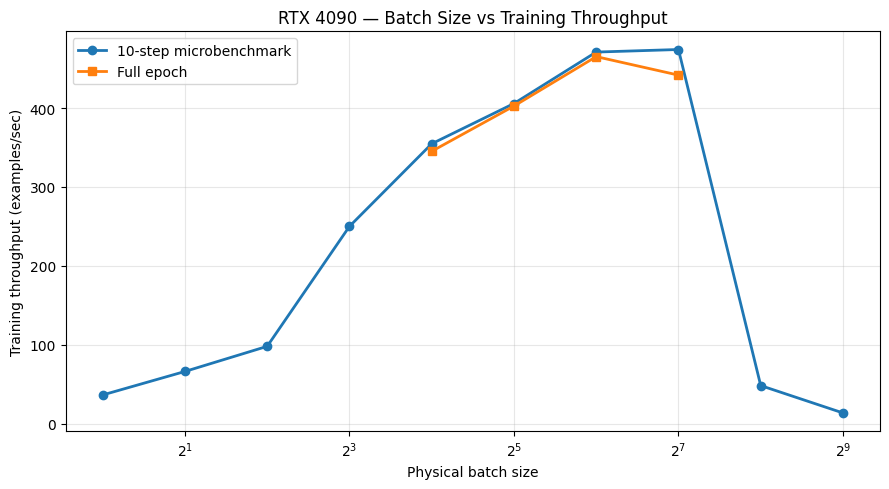

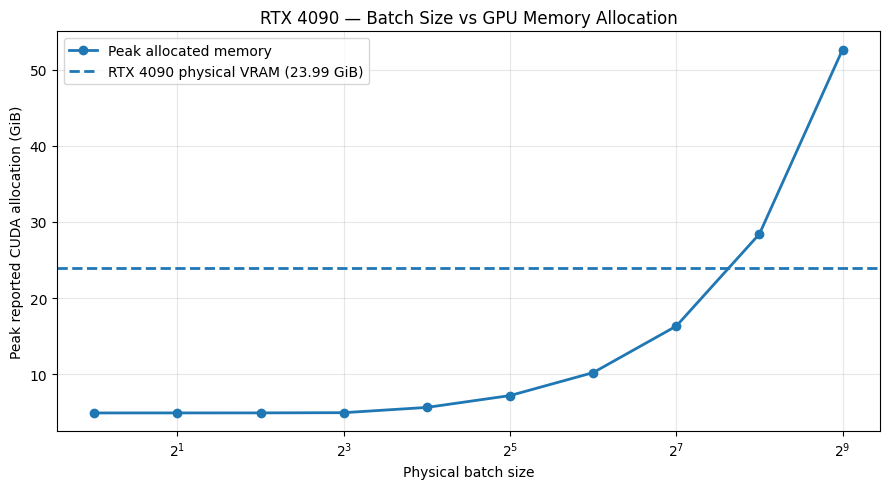

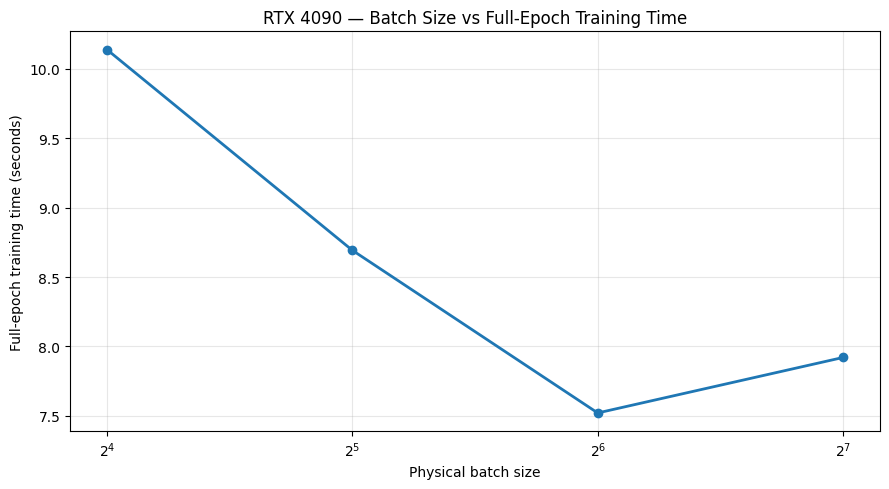


SAVED FIGURES
-----------------------------------------------------------------
PASS: /app/HW4_5_GPU_Assignment/figures/part_a_batch_vs_throughput.png
PASS: /app/HW4_5_GPU_Assignment/figures/part_a_batch_vs_memory.png
PASS: /app/HW4_5_GPU_Assignment/figures/part_a_batch_vs_epoch_time.png

PASS: All three Part A plots generated.
STEP 28 COMPLETE


In [31]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART A: GPU BATCH-SIZE SCALING
#
# STEP 28: GENERATE PERFORMANCE PLOTS
#
# SUMMARY:
# 1. Load saved microbenchmark and full-epoch results.
# 2. Plot batch size vs throughput.
# 3. Plot batch size vs peak GPU memory.
# 4. Plot batch size vs epoch time.
# 5. Save publication-ready PNG figures.
#
# COMMANDS:
# - Read existing CSV files.
# - Create three separate matplotlib plots.
# - Save figures to the project figures directory.
# - Verify all output files.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display as ipy_display, Image

print("=" * 65)
print("HW4.5 PART A — STEP 28")
print("GENERATE GPU SCALING PERFORMANCE PLOTS")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"
FIGURE_DIR = PROJECT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

micro = pd.read_csv(
    METRICS_DIR / "part_a_batch_scaling.csv"
)

epoch = pd.read_csv(
    METRICS_DIR / "part_a_full_epoch_comparison.csv"
)

micro = micro[micro["status"] == "PASS"].copy()
micro = micro.sort_values("batch_size")
epoch = epoch.sort_values("batch_size")

# ------------------------------------------------------------
# PLOT 1: BATCH SIZE VS THROUGHPUT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    micro["batch_size"],
    micro["examples_per_second"],
    marker="o",
    linewidth=2,
    label="10-step microbenchmark"
)

ax.plot(
    epoch["batch_size"],
    epoch["examples_per_second"],
    marker="s",
    linewidth=2,
    label="Full epoch"
)

ax.set_xscale("log", base=2)
ax.set_xlabel("Physical batch size")
ax.set_ylabel("Training throughput (examples/sec)")
ax.set_title("RTX 4090 — Batch Size vs Training Throughput")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

throughput_path = (
    FIGURE_DIR / "part_a_batch_vs_throughput.png"
)

fig.savefig(throughput_path, dpi=200)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# PLOT 2: BATCH SIZE VS PEAK GPU MEMORY
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    micro["batch_size"],
    micro["peak_allocated_gb"],
    marker="o",
    linewidth=2,
    label="Peak allocated memory"
)

ax.axhline(
    23.99,
    linestyle="--",
    linewidth=2,
    label="RTX 4090 physical VRAM (23.99 GiB)"
)

ax.set_xscale("log", base=2)
ax.set_xlabel("Physical batch size")
ax.set_ylabel("Peak reported CUDA allocation (GiB)")
ax.set_title("RTX 4090 — Batch Size vs GPU Memory Allocation")
ax.grid(True, alpha=0.3)
ax.legend()

fig.tight_layout()

memory_path = (
    FIGURE_DIR / "part_a_batch_vs_memory.png"
)

fig.savefig(memory_path, dpi=200)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# PLOT 3: BATCH SIZE VS FULL-EPOCH TIME
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    epoch["batch_size"],
    epoch["epoch_seconds"],
    marker="o",
    linewidth=2
)

ax.set_xscale("log", base=2)
ax.set_xlabel("Physical batch size")
ax.set_ylabel("Full-epoch training time (seconds)")
ax.set_title("RTX 4090 — Batch Size vs Full-Epoch Training Time")
ax.grid(True, alpha=0.3)

fig.tight_layout()

epoch_path = (
    FIGURE_DIR / "part_a_batch_vs_epoch_time.png"
)

fig.savefig(epoch_path, dpi=200)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# VERIFY FIGURES
# ------------------------------------------------------------

print("\nSAVED FIGURES")
print("-" * 65)

for path in [throughput_path, memory_path, epoch_path]:
    assert path.exists()
    print(f"PASS: {path}")

print("\nPASS: All three Part A plots generated.")
print("=" * 65)
print("STEP 28 COMPLETE")
print("=" * 65)


In [32]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART A: GPU BATCH-SIZE SCALING
#
# STEP 29: GENERATE PERFORMANCE SUMMARY
#
# SUMMARY:
# 1. Load saved microbenchmark and full-epoch results.
# 2. Calculate speedup relative to batch size 16.
# 3. Identify the fastest full-epoch configuration.
# 4. Document memory oversubscription observations.
# 5. Save a reproducible Part A summary.
#
# COMMANDS:
# - Read CSV benchmark results.
# - Calculate throughput and epoch-time ratios.
# - Generate Markdown and JSON summaries.
# ============================================================

import json
import pandas as pd
from pathlib import Path

print("=" * 65)
print("HW4.5 PART A — STEP 29")
print("GENERATE PERFORMANCE SUMMARY")
print("=" * 65)

micro = pd.read_csv(
    METRICS_DIR / "part_a_batch_scaling.csv"
)

epoch = pd.read_csv(
    METRICS_DIR / "part_a_full_epoch_comparison.csv"
)

epoch = epoch.sort_values("batch_size").copy()

baseline = epoch.loc[
    epoch["batch_size"] == 16
].iloc[0]

epoch["throughput_speedup_vs_16"] = (
    epoch["examples_per_second"]
    / baseline["examples_per_second"]
)

epoch["epoch_time_speedup_vs_16"] = (
    baseline["epoch_seconds"]
    / epoch["epoch_seconds"]
)

epoch["memory_efficiency_ex_per_sec_per_gib"] = (
    epoch["examples_per_second"]
    / epoch["peak_allocated_gib"]
)

best = epoch.loc[
    epoch["examples_per_second"].idxmax()
]

physical_vram = (
    __import__("torch")
    .cuda.get_device_properties(0)
    .total_memory / 1024**3
)

oversubscribed = micro[
    micro["peak_allocated_gb"] > physical_vram
]["batch_size"].astype(int).tolist()

summary = {
    "gpu": "NVIDIA GeForce RTX 4090",
    "physical_vram_gib": physical_vram,
    "model": "bert-base-uncased",
    "training_examples": 3500,
    "sequence_length": 128,
    "precision": "FP32",
    "best_full_epoch_batch_size": int(best["batch_size"]),
    "best_full_epoch_seconds": float(best["epoch_seconds"]),
    "best_full_epoch_throughput": float(
        best["examples_per_second"]
    ),
    "best_peak_allocated_gib": float(
        best["peak_allocated_gib"]
    ),
    "throughput_speedup_vs_batch16": float(
        best["throughput_speedup_vs_16"]
    ),
    "reported_allocation_above_vram_batches":
        oversubscribed,
    "confirmed_cuda_oom": False,
    "note": (
        "Batches 256 and 512 completed but reported "
        "allocations exceeded physical VRAM. "
        "The exact oversubscription mechanism is unverified."
    )
}

summary_json = (
    METRICS_DIR / "part_a_performance_summary.json"
)

with open(summary_json, "w") as f:
    json.dump(summary, f, indent=4)

markdown_lines = [
    "# HW4.5 Part A — RTX 4090 Performance Summary",
    "",
    "## Experiment",
    "- Model: BERT-base-uncased sentiment classifier",
    "- Training examples: 3,500",
    "- Sequence length: 128",
    "- Precision: FP32",
    "- Gradient accumulation: 1",
    "",
    "## Full-Epoch Comparison",
    "",
    "| Batch | Epoch (s) | Examples/s | Peak GiB | Speedup vs 16 |",
    "|---:|---:|---:|---:|---:|"
]

for _, row in epoch.iterrows():
    markdown_lines.append(
        f"| {int(row['batch_size'])} "
        f"| {row['epoch_seconds']:.2f} "
        f"| {row['examples_per_second']:.2f} "
        f"| {row['peak_allocated_gib']:.2f} "
        f"| {row['throughput_speedup_vs_16']:.2f}x |"
    )

markdown_lines.extend([
    "",
    "## Findings",
    f"- Best full-epoch batch size: {int(best['batch_size'])}",
    f"- Best throughput: {best['examples_per_second']:.2f} examples/sec",
    f"- Best epoch time: {best['epoch_seconds']:.2f} seconds",
    f"- Throughput speedup vs batch 16: {best['throughput_speedup_vs_16']:.2f}x",
    "",
    "## Memory Limitation",
    f"- Physical VRAM: {physical_vram:.2f} GiB",
    f"- Above-VRAM reported allocations: {oversubscribed}",
    "- No CUDA OOM was observed in the completed microbenchmark.",
    "- The mechanism behind above-VRAM allocations remains unverified.",
    "",
    "## Scope",
    "- Microbenchmark: 10 measured training steps per batch.",
    "- Full-epoch comparison: one epoch per batch size.",
    "- These results do not constitute three-epoch comparisons.",
    ""
])

summary_md = PROJECT_DIR / "PART_A_SUMMARY.md"

summary_md.write_text(
    "\n".join(markdown_lines),
    encoding="utf-8"
)

print("\nFULL-EPOCH SPEEDUP COMPARISON")
print("-" * 65)

print(
    epoch[
        [
            "batch_size",
            "examples_per_second",
            "throughput_speedup_vs_16",
            "epoch_seconds",
            "peak_allocated_gib"
        ]
    ].to_string(index=False)
)

print("\nBEST CONFIGURATION")
print("-" * 65)

print(f"Batch size: {int(best['batch_size'])}")
print(f"Throughput: {best['examples_per_second']:.2f} ex/s")
print(f"Epoch time: {best['epoch_seconds']:.2f} s")
print(f"Speedup vs batch 16: {best['throughput_speedup_vs_16']:.2f}x")

print("\nSAVED")
print("-" * 65)
print(summary_json)
print(summary_md)

print("=" * 65)
print("STEP 29 COMPLETE")
print("=" * 65)


HW4.5 PART A — STEP 29
GENERATE PERFORMANCE SUMMARY

FULL-EPOCH SPEEDUP COMPARISON
-----------------------------------------------------------------
 batch_size  examples_per_second  throughput_speedup_vs_16  epoch_seconds  peak_allocated_gib
         16           345.259068                  1.000000      10.137315            5.672230
         32           402.641966                  1.166202       8.692586            7.232441
         64           465.314669                  1.347726       7.521792           10.234944
        128           441.848523                  1.279759       7.921267           16.341268

BEST CONFIGURATION
-----------------------------------------------------------------
Batch size: 64
Throughput: 465.31 ex/s
Epoch time: 7.52 s
Speedup vs batch 16: 1.35x

SAVED
-----------------------------------------------------------------
/app/HW4_5_GPU_Assignment/metrics/part_a_performance_summary.json
/app/HW4_5_GPU_Assignment/PART_A_SUMMARY.md
STEP 29 COMPLETE


In [33]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART B: GPU OPTIMIZATION EXPERIMENTS
#
# STEP 30: PREPARE OPTIMIZATION CONFIGURATIONS
#
# SUMMARY:
# 1. Verify RTX 4090 and saved BERT checkpoint.
# 2. Verify training dataset.
# 3. Check BF16 support and 8-bit optimizer availability.
# 4. Define independent and combined optimizations.
# 5. Save experiment configuration.
#
# COMMANDS:
# - Inspect CUDA capabilities.
# - Check bitsandbytes availability without installing.
# - Define Part B experiments.
# - Save configuration as JSON.
#
# NOTE:
# No training or package installation in this step.
# ============================================================

import json
import torch
import importlib.util
from pathlib import Path
from datetime import datetime

print("=" * 65)
print("HW4.5 PART B — STEP 30")
print("PREPARE GPU OPTIMIZATION EXPERIMENTS")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT = PROJECT_DIR / "models" / "bert_best"
TRAIN_TENSORS = (
    PROJECT_DIR / "tokenized_tensors" / "train_tensors.pt"
)

assert CHECKPOINT.exists(), "BERT checkpoint missing."
assert TRAIN_TENSORS.exists(), "Training tensors missing."
assert torch.cuda.is_available(), "CUDA unavailable."

# ------------------------------------------------------------
# 1. GPU INFORMATION
# ------------------------------------------------------------

gpu = torch.cuda.get_device_properties(0)

bf16_supported = torch.cuda.is_bf16_supported()

print("\nGPU INFORMATION")
print("-" * 65)

print("GPU:", gpu.name)
print(f"Physical VRAM: {gpu.total_memory / 1024**3:.2f} GiB")
print("BF16 supported:", bf16_supported)

assert bf16_supported, (
    "BF16 not supported. AMP configuration must be revised."
)

# ------------------------------------------------------------
# 2. CHECK 8-BIT OPTIMIZER DEPENDENCY
# ------------------------------------------------------------

bitsandbytes_available = (
    importlib.util.find_spec("bitsandbytes") is not None
)

print("\nDEPENDENCY CHECK")
print("-" * 65)

print("PyTorch:", torch.__version__)
print("bitsandbytes installed:", bitsandbytes_available)

# ------------------------------------------------------------
# 3. DEFINE EXPERIMENTS
# ------------------------------------------------------------

PHYSICAL_BATCH_SIZE = 64
SEED = 1980
EPOCHS = 1

experiments = [
    {
        "name": "baseline",
        "amp": False,
        "gradient_checkpointing": False,
        "accumulation_steps": 1,
        "optimizer": "adamw"
    },
    {
        "name": "amp_bf16",
        "amp": True,
        "gradient_checkpointing": False,
        "accumulation_steps": 1,
        "optimizer": "adamw"
    },
    {
        "name": "gradient_checkpointing",
        "amp": False,
        "gradient_checkpointing": True,
        "accumulation_steps": 1,
        "optimizer": "adamw"
    },
    {
        "name": "gradient_accumulation",
        "amp": False,
        "gradient_checkpointing": False,
        "accumulation_steps": 4,
        "optimizer": "adamw"
    },
    {
        "name": "adamw_8bit",
        "amp": False,
        "gradient_checkpointing": False,
        "accumulation_steps": 1,
        "optimizer": "adamw8bit"
    },
    {
        "name": "combined",
        "amp": True,
        "gradient_checkpointing": True,
        "accumulation_steps": 4,
        "optimizer": "adamw8bit"
    }
]

for experiment in experiments:
    experiment["physical_batch_size"] = PHYSICAL_BATCH_SIZE
    experiment["effective_batch_size"] = (
        PHYSICAL_BATCH_SIZE
        * experiment["accumulation_steps"]
    )
    experiment["epochs"] = EPOCHS
    experiment["seed"] = SEED

# ------------------------------------------------------------
# 4. SAVE CONFIGURATION
# ------------------------------------------------------------

config = {
    "part": "B",
    "gpu": gpu.name,
    "model_checkpoint": str(CHECKPOINT),
    "training_tensors": str(TRAIN_TENSORS),
    "bf16_supported": bf16_supported,
    "bitsandbytes_available": bitsandbytes_available,
    "learning_rate": 2e-5,
    "weight_decay": 0.01,
    "experiments": experiments,
    "timestamp": datetime.now().isoformat()
}

config_path = (
    METRICS_DIR / "part_b_optimization_config.json"
)

with open(config_path, "w") as f:
    json.dump(config, f, indent=4)

# ------------------------------------------------------------
# 5. DISPLAY CONFIGURATION
# ------------------------------------------------------------

print("\nEXPERIMENT CONFIGURATIONS")
print("-" * 65)

for experiment in experiments:
    print(
        f"{experiment['name']:25s} "
        f"Physical={experiment['physical_batch_size']:3d} "
        f"Effective={experiment['effective_batch_size']:3d} "
        f"AMP={experiment['amp']} "
        f"Checkpointing={experiment['gradient_checkpointing']} "
        f"Optimizer={experiment['optimizer']}"
    )

print("\nPASS: BERT checkpoint verified.")
print("PASS: Training tensors verified.")
print("PASS: GPU and BF16 verified.")
print("PASS: Experiment configurations saved.")

if not bitsandbytes_available:
    print(
        "\nNOTE: bitsandbytes is not installed. "
        "We'll handle that before the 8-bit optimizer test."
    )

print("\nSaved:", config_path)

print("=" * 65)
print("STEP 30 COMPLETE")
print("=" * 65)


HW4.5 PART B — STEP 30
PREPARE GPU OPTIMIZATION EXPERIMENTS

GPU INFORMATION
-----------------------------------------------------------------
GPU: NVIDIA GeForce RTX 4090
Physical VRAM: 23.99 GiB
BF16 supported: True

DEPENDENCY CHECK
-----------------------------------------------------------------
PyTorch: 2.1.2
bitsandbytes installed: False

EXPERIMENT CONFIGURATIONS
-----------------------------------------------------------------
baseline                  Physical= 64 Effective= 64 AMP=False Checkpointing=False Optimizer=adamw
amp_bf16                  Physical= 64 Effective= 64 AMP=True Checkpointing=False Optimizer=adamw
gradient_checkpointing    Physical= 64 Effective= 64 AMP=False Checkpointing=True Optimizer=adamw
gradient_accumulation     Physical= 64 Effective=256 AMP=False Checkpointing=False Optimizer=adamw
adamw_8bit                Physical= 64 Effective= 64 AMP=False Checkpointing=False Optimizer=adamw8bit
combined                  Physical= 64 Effective=256 AMP=True C

In [34]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART B: GPU OPTIMIZATION EXPERIMENTS
#
# STEP 31: ESTABLISH FP32 BASELINE
#
# SUMMARY:
# 1. Load batch-64 full-epoch results from Part A.
# 2. Establish the FP32 reference configuration.
# 3. Record throughput, epoch time, and GPU memory.
# 4. Save baseline metrics for Part B comparisons.
#
# COMMANDS:
# - Read saved Part A measurements.
# - Validate baseline configuration.
# - Save Part B baseline JSON and CSV.
#
# NOTE:
# No additional training is required.
# ============================================================

import json
import pandas as pd
from pathlib import Path
from datetime import datetime

print("=" * 65)
print("HW4.5 PART B — STEP 31")
print("ESTABLISH FP32 BASELINE")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"

source_path = (
    METRICS_DIR / "part_a_full_epoch_comparison.csv"
)

assert source_path.exists(), (
    "Part A full-epoch results are missing."
)

df = pd.read_csv(source_path)

baseline_rows = df[df["batch_size"] == 64]

assert len(baseline_rows) == 1, (
    "Expected exactly one batch-64 baseline."
)

source = baseline_rows.iloc[0]

assert int(source["examples"]) == 3500
assert source["precision"] == "FP32"

baseline = {
    "experiment": "baseline",
    "part": "B",
    "gpu": "NVIDIA GeForce RTX 4090",
    "physical_batch_size": 64,
    "effective_batch_size": 64,
    "epochs": 1,
    "training_examples": 3500,
    "precision": "FP32",
    "amp": False,
    "gradient_checkpointing": False,
    "gradient_accumulation_steps": 1,
    "optimizer": "AdamW",
    "epoch_seconds": float(source["epoch_seconds"]),
    "examples_per_second": float(
        source["examples_per_second"]
    ),
    "average_loss": float(source["average_loss"]),
    "peak_allocated_gib": float(
        source["peak_allocated_gib"]
    ),
    "peak_reserved_gib": float(
        source["peak_reserved_gib"]
    ),
    "source": "part_a_full_epoch_comparison.csv",
    "timestamp": datetime.now().isoformat()
}

json_path = (
    METRICS_DIR / "part_b_baseline.json"
)

csv_path = (
    METRICS_DIR / "part_b_baseline.csv"
)

with open(json_path, "w") as f:
    json.dump(baseline, f, indent=4)

pd.DataFrame([baseline]).to_csv(
    csv_path,
    index=False
)

print("\nBASELINE CONFIGURATION")
print("-" * 65)

print("Physical batch size :", baseline["physical_batch_size"])
print("Effective batch size:", baseline["effective_batch_size"])
print("Precision           :", baseline["precision"])
print("Optimizer           :", baseline["optimizer"])

print("\nBASELINE PERFORMANCE")
print("-" * 65)

print(f"Epoch time          : {baseline['epoch_seconds']:.2f} sec")
print(
    f"Throughput          : "
    f"{baseline['examples_per_second']:.2f} examples/sec"
)
print(
    f"Peak allocated      : "
    f"{baseline['peak_allocated_gib']:.2f} GiB"
)
print(
    f"Peak reserved       : "
    f"{baseline['peak_reserved_gib']:.2f} GiB"
)

print("\nSaved:", json_path)
print("Saved:", csv_path)

print("=" * 65)
print("STEP 31 COMPLETE")
print("=" * 65)


HW4.5 PART B — STEP 31
ESTABLISH FP32 BASELINE

BASELINE CONFIGURATION
-----------------------------------------------------------------
Physical batch size : 64
Effective batch size: 64
Precision           : FP32
Optimizer           : AdamW

BASELINE PERFORMANCE
-----------------------------------------------------------------
Epoch time          : 7.52 sec
Throughput          : 465.31 examples/sec
Peak allocated      : 10.23 GiB
Peak reserved       : 10.62 GiB

Saved: /app/HW4_5_GPU_Assignment/metrics/part_b_baseline.json
Saved: /app/HW4_5_GPU_Assignment/metrics/part_b_baseline.csv
STEP 31 COMPLETE


In [35]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART B: GPU OPTIMIZATION EXPERIMENTS
#
# STEP 32: BF16 AUTOMATIC MIXED PRECISION (AMP)
#
# SUMMARY:
# 1. Load a fresh BERT checkpoint.
# 2. Enable BF16 autocast for forward/loss computation.
# 3. Train one full epoch at physical batch size 64.
# 4. Measure epoch time, throughput, loss, and peak memory.
# 5. Compare against the saved FP32 baseline.
# 6. Save experiment results as JSON and CSV.
#
# COMMANDS:
# - Set reproducible random seeds.
# - Load BERT and AdamW.
# - Run training with torch.autocast(dtype=torch.bfloat16).
# - Synchronize CUDA and collect measurements.
# - Save AMP metrics and relative speedup.
#
# NOTE:
# BF16 does not require GradScaler.
# Original BERT checkpoint remains unchanged.
# ============================================================

import gc
import json
import time
import random
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from datetime import datetime
from torch.utils.data import DataLoader, TensorDataset
from transformers import BertForSequenceClassification

print("=" * 65)
print("HW4.5 PART B — STEP 32")
print("BF16 AUTOMATIC MIXED PRECISION")
print("=" * 65)

SEED = 1980
BATCH_SIZE = 64
DEVICE = torch.device("cuda:0")

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"
CHECKPOINT = PROJECT_DIR / "models" / "bert_best"

assert torch.cuda.is_available()
assert torch.cuda.is_bf16_supported()
assert CHECKPOINT.exists()

# ------------------------------------------------------------
# 1. LOAD SAVED BASELINE
# ------------------------------------------------------------

with open(METRICS_DIR / "part_b_baseline.json") as f:
    baseline = json.load(f)

assert baseline["physical_batch_size"] == BATCH_SIZE

# ------------------------------------------------------------
# 2. LOAD TRAINING DATA
# ------------------------------------------------------------

saved = torch.load(
    PROJECT_DIR / "tokenized_tensors" / "train_tensors.pt",
    map_location="cpu"
)

train_data = TensorDataset(
    saved["input_ids"],
    saved["attention_mask"],
    saved["labels"]
)

assert len(train_data) == 3500

# ------------------------------------------------------------
# 3. SET SEEDS AND INITIALIZE MODEL
# ------------------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

gc.collect()
torch.cuda.empty_cache()

model_amp = BertForSequenceClassification.from_pretrained(
    str(CHECKPOINT)
).to(DEVICE)

model_amp.train()

optimizer_amp = torch.optim.AdamW(
    model_amp.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

loader_amp = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    generator=torch.Generator().manual_seed(SEED)
)

print("\nCONFIGURATION")
print("-" * 65)
print("GPU                 :", torch.cuda.get_device_name(0))
print("Physical batch size :", BATCH_SIZE)
print("Training examples   :", len(train_data))
print("Steps per epoch     :", len(loader_amp))
print("Precision           : BF16 AMP")
print("Gradient checkpoint : Disabled")
print("Accumulation steps  : 1")
print("Optimizer           : AdamW")

# ------------------------------------------------------------
# 4. TRAIN ONE FULL EPOCH
# ------------------------------------------------------------

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

start = time.perf_counter()

total_loss = 0.0
processed = 0

for step, (ids, mask, targets) in enumerate(loader_amp, 1):

    ids = ids.to(DEVICE)
    mask = mask.to(DEVICE)
    targets = targets.to(DEVICE)

    optimizer_amp.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.bfloat16
    ):
        outputs = model_amp(
            input_ids=ids,
            attention_mask=mask,
            labels=targets
        )
        loss = outputs.loss

    if not torch.isfinite(loss).item():
        raise RuntimeError(
            f"Non-finite loss at step {step}: {loss.item()}"
        )

    loss.backward()
    optimizer_amp.step()

    n = ids.size(0)
    total_loss += loss.item() * n
    processed += n

    if step % 5 == 0 or step == len(loader_amp):
        print(
            f"Step {step}/{len(loader_amp)} "
            f"| Loss: {loss.item():.4f}",
            flush=True
        )

torch.cuda.synchronize()

epoch_seconds = time.perf_counter() - start
throughput = processed / epoch_seconds
average_loss = total_loss / processed

peak_allocated = (
    torch.cuda.max_memory_allocated() / 1024**3
)
peak_reserved = (
    torch.cuda.max_memory_reserved() / 1024**3
)

# ------------------------------------------------------------
# 5. COMPARE AGAINST FP32
# ------------------------------------------------------------

speedup = (
    baseline["epoch_seconds"] / epoch_seconds
)

memory_reduction_percent = (
    (
        baseline["peak_allocated_gib"] - peak_allocated
    )
    / baseline["peak_allocated_gib"]
    * 100
)

result = {
    "experiment": "amp_bf16",
    "part": "B",
    "gpu": torch.cuda.get_device_name(0),
    "physical_batch_size": BATCH_SIZE,
    "effective_batch_size": BATCH_SIZE,
    "epochs": 1,
    "training_examples": processed,
    "precision": "BF16 AMP",
    "amp": True,
    "gradient_checkpointing": False,
    "gradient_accumulation_steps": 1,
    "optimizer": "AdamW",
    "epoch_seconds": epoch_seconds,
    "examples_per_second": throughput,
    "average_loss": average_loss,
    "peak_allocated_gib": peak_allocated,
    "peak_reserved_gib": peak_reserved,
    "speedup_vs_fp32": speedup,
    "memory_reduction_percent": memory_reduction_percent,
    "seed": SEED,
    "timestamp": datetime.now().isoformat()
}

json_path = METRICS_DIR / "part_b_amp_bf16.json"
csv_path = METRICS_DIR / "part_b_amp_bf16.csv"

with open(json_path, "w") as f:
    json.dump(result, f, indent=4)

pd.DataFrame([result]).to_csv(
    csv_path,
    index=False
)

# ------------------------------------------------------------
# 6. REPORT RESULTS
# ------------------------------------------------------------

print("\nBF16 AMP RESULTS")
print("-" * 65)
print(f"Epoch time          : {epoch_seconds:.2f} sec")
print(f"Throughput          : {throughput:.2f} examples/sec")
print(f"Average loss        : {average_loss:.4f}")
print(f"Peak allocated      : {peak_allocated:.2f} GiB")
print(f"Peak reserved       : {peak_reserved:.2f} GiB")

print("\nCOMPARISON WITH FP32 BASELINE")
print("-" * 65)
print(f"FP32 epoch time     : {baseline['epoch_seconds']:.2f} sec")
print(f"BF16 epoch time     : {epoch_seconds:.2f} sec")
print(f"Speedup             : {speedup:.2f}x")
print(f"Memory reduction    : {memory_reduction_percent:.2f}%")

print("\nSaved:", json_path)
print("Saved:", csv_path)

del model_amp, optimizer_amp, loader_amp
gc.collect()
torch.cuda.empty_cache()

print("=" * 65)
print("STEP 32 COMPLETE")
print("=" * 65)


HW4.5 PART B — STEP 32
BF16 AUTOMATIC MIXED PRECISION

CONFIGURATION
-----------------------------------------------------------------
GPU                 : NVIDIA GeForce RTX 4090
Physical batch size : 64
Training examples   : 3500
Steps per epoch     : 55
Precision           : BF16 AMP
Gradient checkpoint : Disabled
Accumulation steps  : 1
Optimizer           : AdamW
Step 5/55 | Loss: 0.3323
Step 10/55 | Loss: 0.4564
Step 15/55 | Loss: 0.4026
Step 20/55 | Loss: 0.3038
Step 25/55 | Loss: 0.2170
Step 30/55 | Loss: 0.3708
Step 35/55 | Loss: 0.3697
Step 40/55 | Loss: 0.4246
Step 45/55 | Loss: 0.3751
Step 50/55 | Loss: 0.4283
Step 55/55 | Loss: 0.3942

BF16 AMP RESULTS
-----------------------------------------------------------------
Epoch time          : 4.55 sec
Throughput          : 768.43 examples/sec
Average loss        : 0.3831
Peak allocated      : 8.43 GiB
Peak reserved       : 8.77 GiB

COMPARISON WITH FP32 BASELINE
----------------------------------------------------------------

In [36]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART B: GPU OPTIMIZATION EXPERIMENTS
#
# STEP 33: GRADIENT CHECKPOINTING EXPERIMENT
#
# SUMMARY:
# 1. Load a fresh BERT checkpoint.
# 2. Enable gradient checkpointing.
# 3. Train one complete epoch using FP32.
# 4. Measure epoch time, throughput, loss, and GPU memory.
# 5. Compare with the FP32 baseline.
# 6. Save results to JSON and CSV.
#
# COMMANDS:
# - Enable model.gradient_checkpointing_enable().
# - Train with physical batch size 64.
# - Record synchronized GPU timings and peak memory.
# - Save comparative performance metrics.
#
# NOTE:
# Only gradient checkpointing changes relative to baseline.
# Original BERT checkpoint remains unchanged.
# ============================================================

import gc
import json
import time
import random
import numpy as np
import pandas as pd
import torch

from datetime import datetime
from torch.utils.data import DataLoader, TensorDataset
from transformers import BertForSequenceClassification

print("=" * 65)
print("HW4.5 PART B — STEP 33")
print("GRADIENT CHECKPOINTING EXPERIMENT")
print("=" * 65)

SEED = 1980
BATCH_SIZE = 64
DEVICE = torch.device("cuda:0")

# ------------------------------------------------------------
# 1. VERIFY BASELINE AND DATA
# ------------------------------------------------------------

with open(METRICS_DIR / "part_b_baseline.json") as f:
    baseline = json.load(f)

saved = torch.load(
    PROJECT_DIR / "tokenized_tensors" / "train_tensors.pt",
    map_location="cpu"
)

train_data = TensorDataset(
    saved["input_ids"],
    saved["attention_mask"],
    saved["labels"]
)

assert len(train_data) == 3500
assert baseline["physical_batch_size"] == BATCH_SIZE

# ------------------------------------------------------------
# 2. REPRODUCIBILITY
# ------------------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 3. LOAD MODEL AND ENABLE CHECKPOINTING
# ------------------------------------------------------------

model_gc = BertForSequenceClassification.from_pretrained(
    str(PROJECT_DIR / "models" / "bert_best")
).to(DEVICE)

model_gc.gradient_checkpointing_enable()
model_gc.train()

assert model_gc.is_gradient_checkpointing

optimizer_gc = torch.optim.AdamW(
    model_gc.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

loader_gc = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    generator=torch.Generator().manual_seed(SEED)
)

print("\nCONFIGURATION")
print("-" * 65)

print("GPU                 :", torch.cuda.get_device_name(0))
print("Physical batch size :", BATCH_SIZE)
print("Training examples   :", len(train_data))
print("Steps per epoch     :", len(loader_gc))
print("Precision           : FP32")
print("Gradient checkpoint : Enabled")
print("Accumulation steps  : 1")
print("Optimizer           : AdamW")

# ------------------------------------------------------------
# 4. TRAIN ONE FULL EPOCH
# ------------------------------------------------------------

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

start = time.perf_counter()

total_loss = 0.0
processed = 0

for step, (ids, mask, targets) in enumerate(loader_gc, 1):

    ids = ids.to(DEVICE)
    mask = mask.to(DEVICE)
    targets = targets.to(DEVICE)

    optimizer_gc.zero_grad(set_to_none=True)

    outputs = model_gc(
        input_ids=ids,
        attention_mask=mask,
        labels=targets
    )

    loss = outputs.loss

    if not torch.isfinite(loss).item():
        raise RuntimeError(
            f"Non-finite loss at step {step}"
        )

    loss.backward()
    optimizer_gc.step()

    n = ids.size(0)
    total_loss += loss.item() * n
    processed += n

    if step % 5 == 0 or step == len(loader_gc):
        print(
            f"Step {step}/{len(loader_gc)} "
            f"| Loss: {loss.item():.4f}",
            flush=True
        )

torch.cuda.synchronize()

epoch_seconds = time.perf_counter() - start
throughput = processed / epoch_seconds
average_loss = total_loss / processed

peak_allocated = (
    torch.cuda.max_memory_allocated() / 1024**3
)
peak_reserved = (
    torch.cuda.max_memory_reserved() / 1024**3
)

# ------------------------------------------------------------
# 5. COMPARE AGAINST BASELINE
# ------------------------------------------------------------

speedup = baseline["epoch_seconds"] / epoch_seconds

memory_reduction_percent = (
    (
        baseline["peak_allocated_gib"] - peak_allocated
    )
    / baseline["peak_allocated_gib"]
    * 100
)

result = {
    "experiment": "gradient_checkpointing",
    "part": "B",
    "gpu": torch.cuda.get_device_name(0),
    "physical_batch_size": BATCH_SIZE,
    "effective_batch_size": BATCH_SIZE,
    "epochs": 1,
    "training_examples": processed,
    "precision": "FP32",
    "amp": False,
    "gradient_checkpointing": True,
    "gradient_accumulation_steps": 1,
    "optimizer": "AdamW",
    "epoch_seconds": epoch_seconds,
    "examples_per_second": throughput,
    "average_loss": average_loss,
    "peak_allocated_gib": peak_allocated,
    "peak_reserved_gib": peak_reserved,
    "speedup_vs_fp32": speedup,
    "memory_reduction_percent": memory_reduction_percent,
    "seed": SEED,
    "timestamp": datetime.now().isoformat()
}

json_path = (
    METRICS_DIR / "part_b_gradient_checkpointing.json"
)
csv_path = (
    METRICS_DIR / "part_b_gradient_checkpointing.csv"
)

with open(json_path, "w") as f:
    json.dump(result, f, indent=4)

pd.DataFrame([result]).to_csv(
    csv_path,
    index=False
)

# ------------------------------------------------------------
# 6. REPORT RESULTS
# ------------------------------------------------------------

print("\nGRADIENT CHECKPOINTING RESULTS")
print("-" * 65)

print(f"Epoch time          : {epoch_seconds:.2f} sec")
print(f"Throughput          : {throughput:.2f} examples/sec")
print(f"Average loss        : {average_loss:.4f}")
print(f"Peak allocated      : {peak_allocated:.2f} GiB")
print(f"Peak reserved       : {peak_reserved:.2f} GiB")

print("\nCOMPARISON WITH FP32 BASELINE")
print("-" * 65)

print(f"Speedup             : {speedup:.2f}x")
print(f"Memory reduction    : {memory_reduction_percent:.2f}%")

print("\nSaved:", json_path)
print("Saved:", csv_path)

del model_gc, optimizer_gc, loader_gc
gc.collect()
torch.cuda.empty_cache()

print("=" * 65)
print("STEP 33 COMPLETE")
print("=" * 65)


HW4.5 PART B — STEP 33
GRADIENT CHECKPOINTING EXPERIMENT

CONFIGURATION
-----------------------------------------------------------------
GPU                 : NVIDIA GeForce RTX 4090
Physical batch size : 64
Training examples   : 3500
Steps per epoch     : 55
Precision           : FP32
Gradient checkpoint : Enabled
Accumulation steps  : 1
Optimizer           : AdamW
Step 5/55 | Loss: 0.3321
Step 10/55 | Loss: 0.4572
Step 15/55 | Loss: 0.4024
Step 20/55 | Loss: 0.3080
Step 25/55 | Loss: 0.2167
Step 30/55 | Loss: 0.3695
Step 35/55 | Loss: 0.3715
Step 40/55 | Loss: 0.4275
Step 45/55 | Loss: 0.3775
Step 50/55 | Loss: 0.4279
Step 55/55 | Loss: 0.4004

GRADIENT CHECKPOINTING RESULTS
-----------------------------------------------------------------
Epoch time          : 10.17 sec
Throughput          : 344.27 examples/sec
Average loss        : 0.3832
Peak allocated      : 5.18 GiB
Peak reserved       : 6.14 GiB

COMPARISON WITH FP32 BASELINE
---------------------------------------------------

In [37]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART B: GPU OPTIMIZATION EXPERIMENTS
#
# STEP 34: GRADIENT ACCUMULATION EXPERIMENT
#
# SUMMARY:
# 1. Load fresh BERT checkpoint and training tensors.
# 2. Use physical batch size 64, accumulation steps 4.
# 3. Train one full epoch with FP32 AdamW.
# 4. Correctly normalize each accumulation window,
#    including the final partial window.
# 5. Measure throughput, time, peak GPU memory.
# 6. Save metrics and compare with FP32 baseline.
#
# COMMANDS:
# - Load BERT and AdamW.
# - Accumulate gradients across 4 microbatches.
# - Perform optimizer steps at window boundaries.
# - Save JSON and CSV results.
#
# NOTE:
# Gradient accumulation changes effective batch size
# and number of optimizer updates. Loss is not expected
# to match the original batch-64 baseline exactly.
# ============================================================

import gc
import json
import time
import random
import math
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from datetime import datetime
from torch.utils.data import DataLoader, TensorDataset
from transformers import BertForSequenceClassification

print("=" * 65)
print("HW4.5 PART B — STEP 34")
print("GRADIENT ACCUMULATION EXPERIMENT")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"

SEED = 1980
BATCH_SIZE = 64
ACCUMULATION_STEPS = 4
DEVICE = torch.device("cuda:0")

# ------------------------------------------------------------
# 1. LOAD BASELINE AND DATA
# ------------------------------------------------------------

with open(METRICS_DIR / "part_b_baseline.json") as f:
    baseline = json.load(f)

saved = torch.load(
    PROJECT_DIR / "tokenized_tensors" / "train_tensors.pt",
    map_location="cpu"
)

train_data = TensorDataset(
    saved["input_ids"],
    saved["attention_mask"],
    saved["labels"]
)

assert len(train_data) == 3500
assert baseline["physical_batch_size"] == BATCH_SIZE

# ------------------------------------------------------------
# 2. SET SEEDS
# ------------------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 3. INITIALIZE MODEL AND OPTIMIZER
# ------------------------------------------------------------

model_ga = BertForSequenceClassification.from_pretrained(
    str(PROJECT_DIR / "models" / "bert_best")
).to(DEVICE)

model_ga.train()

optimizer_ga = torch.optim.AdamW(
    model_ga.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

loader_ga = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    generator=torch.Generator().manual_seed(SEED)
)

total_microbatches = len(loader_ga)
expected_updates = math.ceil(
    total_microbatches / ACCUMULATION_STEPS
)

print("\nCONFIGURATION")
print("-" * 65)
print("GPU                  :", torch.cuda.get_device_name(0))
print("Physical batch size  :", BATCH_SIZE)
print("Accumulation steps   :", ACCUMULATION_STEPS)
print("Effective batch size :", BATCH_SIZE * ACCUMULATION_STEPS)
print("Training examples    :", len(train_data))
print("Microbatches         :", total_microbatches)
print("Expected updates     :", expected_updates)
print("Precision            : FP32")
print("Gradient checkpoint  : Disabled")
print("Optimizer            : AdamW")

# ------------------------------------------------------------
# 4. TRAIN ONE FULL EPOCH
# ------------------------------------------------------------

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

start = time.perf_counter()

total_loss = 0.0
processed = 0
optimizer_updates = 0

optimizer_ga.zero_grad(set_to_none=True)

# Compute the exact example count in each accumulation
# window so that smaller final batches are weighted correctly.
batch_sizes = [
    min(BATCH_SIZE, len(train_data) - i * BATCH_SIZE)
    for i in range(total_microbatches)
]

for step, (ids, mask, targets) in enumerate(loader_ga, 1):

    ids = ids.to(DEVICE)
    mask = mask.to(DEVICE)
    targets = targets.to(DEVICE)

    window_start = (
        (step - 1) // ACCUMULATION_STEPS
    ) * ACCUMULATION_STEPS

    window_end = min(
        window_start + ACCUMULATION_STEPS,
        total_microbatches
    )

    window_examples = sum(
        batch_sizes[window_start:window_end]
    )

    outputs = model_ga(
        input_ids=ids,
        attention_mask=mask,
        labels=targets
    )

    loss = outputs.loss

    if not torch.isfinite(loss).item():
        raise RuntimeError(
            f"Non-finite loss at microbatch {step}"
        )

    n = ids.size(0)

    # Correct example-weighted normalization.
    scaled_loss = loss * (n / window_examples)
    scaled_loss.backward()

    total_loss += loss.item() * n
    processed += n

    update_boundary = (
        step % ACCUMULATION_STEPS == 0
        or step == total_microbatches
    )

    if update_boundary:
        optimizer_ga.step()
        optimizer_ga.zero_grad(set_to_none=True)
        optimizer_updates += 1

    if step % 5 == 0 or step == total_microbatches:
        print(
            f"Microbatch {step}/{total_microbatches} "
            f"| Loss: {loss.item():.4f} "
            f"| Updates: {optimizer_updates}",
            flush=True
        )

torch.cuda.synchronize()

epoch_seconds = time.perf_counter() - start
throughput = processed / epoch_seconds
average_loss = total_loss / processed

peak_allocated = (
    torch.cuda.max_memory_allocated() / 1024**3
)
peak_reserved = (
    torch.cuda.max_memory_reserved() / 1024**3
)

assert processed == 3500
assert optimizer_updates == expected_updates

# ------------------------------------------------------------
# 5. COMPARE WITH BASELINE
# ------------------------------------------------------------

speedup = (
    baseline["epoch_seconds"] / epoch_seconds
)

memory_reduction_percent = (
    (
        baseline["peak_allocated_gib"] - peak_allocated
    )
    / baseline["peak_allocated_gib"]
    * 100
)

result = {
    "experiment": "gradient_accumulation",
    "part": "B",
    "gpu": torch.cuda.get_device_name(0),
    "physical_batch_size": BATCH_SIZE,
    "effective_batch_size": BATCH_SIZE * ACCUMULATION_STEPS,
    "epochs": 1,
    "training_examples": processed,
    "microbatches": total_microbatches,
    "optimizer_updates": optimizer_updates,
    "precision": "FP32",
    "amp": False,
    "gradient_checkpointing": False,
    "gradient_accumulation_steps": ACCUMULATION_STEPS,
    "optimizer": "AdamW",
    "epoch_seconds": epoch_seconds,
    "examples_per_second": throughput,
    "average_loss": average_loss,
    "peak_allocated_gib": peak_allocated,
    "peak_reserved_gib": peak_reserved,
    "speedup_vs_fp32": speedup,
    "memory_reduction_percent": memory_reduction_percent,
    "seed": SEED,
    "timestamp": datetime.now().isoformat()
}

json_path = (
    METRICS_DIR / "part_b_gradient_accumulation.json"
)
csv_path = (
    METRICS_DIR / "part_b_gradient_accumulation.csv"
)

with open(json_path, "w") as f:
    json.dump(result, f, indent=4)

pd.DataFrame([result]).to_csv(
    csv_path,
    index=False
)

# ------------------------------------------------------------
# 6. REPORT
# ------------------------------------------------------------

print("\nGRADIENT ACCUMULATION RESULTS")
print("-" * 65)

print("Examples processed  :", processed)
print("Optimizer updates   :", optimizer_updates)
print(f"Epoch time          : {epoch_seconds:.2f} sec")
print(f"Throughput          : {throughput:.2f} examples/sec")
print(f"Average loss        : {average_loss:.4f}")
print(f"Peak allocated      : {peak_allocated:.2f} GiB")
print(f"Peak reserved       : {peak_reserved:.2f} GiB")

print("\nCOMPARISON WITH FP32 BASELINE")
print("-" * 65)

print(f"Speedup             : {speedup:.2f}x")
print(f"Memory reduction    : {memory_reduction_percent:.2f}%")

print("\nSaved:", json_path)
print("Saved:", csv_path)

del model_ga, optimizer_ga, loader_ga
gc.collect()
torch.cuda.empty_cache()

print("=" * 65)
print("STEP 34 COMPLETE")
print("=" * 65)


HW4.5 PART B — STEP 34
GRADIENT ACCUMULATION EXPERIMENT

CONFIGURATION
-----------------------------------------------------------------
GPU                  : NVIDIA GeForce RTX 4090
Physical batch size  : 64
Accumulation steps   : 4
Effective batch size : 256
Training examples    : 3500
Microbatches         : 55
Expected updates     : 14
Precision            : FP32
Gradient checkpoint  : Disabled
Optimizer            : AdamW
Microbatch 5/55 | Loss: 0.3806 | Updates: 1
Microbatch 10/55 | Loss: 0.4534 | Updates: 2
Microbatch 15/55 | Loss: 0.4372 | Updates: 3
Microbatch 20/55 | Loss: 0.2932 | Updates: 5
Microbatch 25/55 | Loss: 0.2379 | Updates: 6
Microbatch 30/55 | Loss: 0.3574 | Updates: 7
Microbatch 35/55 | Loss: 0.4001 | Updates: 8
Microbatch 40/55 | Loss: 0.4210 | Updates: 10
Microbatch 45/55 | Loss: 0.3708 | Updates: 11
Microbatch 50/55 | Loss: 0.4159 | Updates: 12
Microbatch 55/55 | Loss: 0.4389 | Updates: 14

GRADIENT ACCUMULATION RESULTS
----------------------------------------

In [38]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART B: GPU OPTIMIZATION EXPERIMENTS
#
# STEP 35: INSTALL AND VERIFY 8-BIT OPTIMIZER
#
# SUMMARY:
# 1. Install bitsandbytes without modifying dependencies.
# 2. Verify CUDA support and package version.
# 3. Run a small AdamW8bit optimizer smoke test.
# 4. Save dependency verification results.
#
# COMMANDS:
# - pip install --no-deps bitsandbytes==0.43.1
# - Import bitsandbytes.
# - Run one CUDA optimizer step.
# - Verify 8-bit optimizer states.
#
# NOTE:
# Does not modify the BERT checkpoint.
# Does not upgrade torch or transformers.
# ============================================================

import sys
import subprocess
import json
import torch
from pathlib import Path
from datetime import datetime

print("=" * 65)
print("HW4.5 PART B — STEP 35")
print("INSTALL AND VERIFY 8-BIT OPTIMIZER")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

torch_before = torch.__version__

print("\nINSTALLING BITSANDBYTES")
print("-" * 65)

command = [
    sys.executable,
    "-m",
    "pip",
    "install",
    "--no-deps",
    "--disable-pip-version-check",
    "bitsandbytes==0.43.1"
]

subprocess.run(
    command,
    check=True,
    timeout=180
)

# ------------------------------------------------------------
# 1. IMPORT AND VERIFY PACKAGE
# ------------------------------------------------------------

import bitsandbytes as bnb

assert torch.__version__ == torch_before
assert torch.cuda.is_available()

print("\nENVIRONMENT VERIFICATION")
print("-" * 65)

print("PyTorch version    :", torch.__version__)
print("bitsandbytes       :", bnb.__version__)
print("GPU                :", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 2. CUDA OPTIMIZER SMOKE TEST
# ------------------------------------------------------------

# Use a sufficiently large parameter tensor so that
# bitsandbytes stores optimizer states in 8-bit format.

parameter = torch.nn.Parameter(
    torch.randn(4096, device="cuda")
)

optimizer_test = bnb.optim.AdamW8bit(
    [parameter],
    lr=1e-3,
    min_8bit_size=4096
)

optimizer_test.zero_grad(set_to_none=True)

loss = (parameter ** 2).mean()
loss.backward()
optimizer_test.step()

torch.cuda.synchronize()

assert torch.isfinite(parameter).all().item()

state = optimizer_test.state[parameter]

state1_dtype = str(state["state1"].dtype)
state2_dtype = str(state["state2"].dtype)

print("\n8-BIT OPTIMIZER SMOKE TEST")
print("-" * 65)

print("Optimizer          : AdamW8bit")
print("Parameter elements :", parameter.numel())
print("State 1 dtype      :", state1_dtype)
print("State 2 dtype      :", state2_dtype)
print("Loss finite        :", bool(torch.isfinite(loss).item()))

assert state["state1"].dtype == torch.uint8
assert state["state2"].dtype == torch.uint8

print("PASS: CUDA 8-bit optimizer step completed.")
print("PASS: Both optimizer states use uint8.")
print("PASS: Existing PyTorch version preserved.")

# ------------------------------------------------------------
# 3. SAVE VERIFICATION
# ------------------------------------------------------------

result = {
    "step": 35,
    "gpu": torch.cuda.get_device_name(0),
    "torch_version": torch.__version__,
    "bitsandbytes_version": bnb.__version__,
    "optimizer": "AdamW8bit",
    "smoke_test_passed": True,
    "state1_dtype": state1_dtype,
    "state2_dtype": state2_dtype,
    "timestamp": datetime.now().isoformat()
}

output_path = (
    METRICS_DIR / "part_b_8bit_dependency_check.json"
)

with open(output_path, "w") as f:
    json.dump(result, f, indent=4)

del parameter, optimizer_test, loss
torch.cuda.empty_cache()

print("\nSaved:", output_path)

print("=" * 65)
print("STEP 35 COMPLETE")
print("=" * 65)


HW4.5 PART B — STEP 35
INSTALL AND VERIFY 8-BIT OPTIMIZER

INSTALLING BITSANDBYTES
-----------------------------------------------------------------
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.8/119.8 MB 11.5 MB/s eta 0:00:0000:0100:01



ENVIRONMENT VERIFICATION
-----------------------------------------------------------------
PyTorch version    : 2.1.2
bitsandbytes       : 0.43.1
GPU                : NVIDIA GeForce RTX 4090

8-BIT OPTIMIZER SMOKE TEST
-----------------------------------------------------------------
Optimizer          : AdamW8bit
Parameter elements : 4096
State 1 dtype      : torch.uint8
State 2 dtype      : torch.uint8
Loss finite        : True
PASS: CUDA 8-bit optimizer step completed.
PASS: Both optimizer states use uint8.
PASS: Existing PyTorch version preserved.

Saved: /app/HW4_5_GPU_Assignment/metrics/part_b_8bit_dependency_check.json
STEP 35 COMPLETE


In [39]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART B: GPU OPTIMIZATION EXPERIMENTS
#
# STEP 36: 8-BIT ADAMW TRAINING EXPERIMENT
#
# SUMMARY:
# 1. Load fresh saved BERT checkpoint.
# 2. Use bitsandbytes AdamW8bit optimizer.
# 3. Train one full epoch in FP32 at batch size 64.
# 4. Verify actual 8-bit optimizer states.
# 5. Measure epoch time, throughput, loss, and peak VRAM.
# 6. Compare with FP32 baseline and save JSON/CSV.
#
# COMMANDS:
# - Load training tensors and baseline metrics.
# - Initialize BERT and AdamW8bit.
# - Train 3500 examples.
# - Record synchronized CUDA metrics.
#
# NOTE:
# Original BERT checkpoint remains unchanged.
# ============================================================

import gc
import json
import time
import random
import numpy as np
import pandas as pd
import torch
import bitsandbytes as bnb

from pathlib import Path
from datetime import datetime
from torch.utils.data import DataLoader, TensorDataset
from transformers import BertForSequenceClassification

print("=" * 65)
print("HW4.5 PART B — STEP 36")
print("8-BIT ADAMW TRAINING EXPERIMENT")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"
CHECKPOINT = PROJECT_DIR / "models" / "bert_best"

SEED = 1980
BATCH_SIZE = 64
DEVICE = torch.device("cuda:0")

assert torch.cuda.is_available()
assert CHECKPOINT.exists()

# ------------------------------------------------------------
# 1. LOAD BASELINE AND TRAINING DATA
# ------------------------------------------------------------

with open(METRICS_DIR / "part_b_baseline.json") as f:
    baseline = json.load(f)

saved = torch.load(
    PROJECT_DIR / "tokenized_tensors" / "train_tensors.pt",
    map_location="cpu"
)

train_data = TensorDataset(
    saved["input_ids"],
    saved["attention_mask"],
    saved["labels"]
)

assert len(train_data) == 3500
assert baseline["physical_batch_size"] == BATCH_SIZE

# ------------------------------------------------------------
# 2. REPRODUCIBILITY
# ------------------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 3. INITIALIZE MODEL AND 8-BIT OPTIMIZER
# ------------------------------------------------------------

model_8bit = BertForSequenceClassification.from_pretrained(
    str(CHECKPOINT)
).to(DEVICE)

model_8bit.train()

optimizer_8bit = bnb.optim.AdamW8bit(
    model_8bit.parameters(),
    lr=2e-5,
    weight_decay=0.01,
    min_8bit_size=4096
)

loader_8bit = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    generator=torch.Generator().manual_seed(SEED)
)

print("\nCONFIGURATION")
print("-" * 65)
print("GPU                 :", torch.cuda.get_device_name(0))
print("Physical batch size :", BATCH_SIZE)
print("Training examples   :", len(train_data))
print("Steps per epoch     :", len(loader_8bit))
print("Precision           : FP32")
print("Gradient checkpoint : Disabled")
print("Accumulation steps  : 1")
print("Optimizer           : AdamW8bit")
print("bitsandbytes version:", bnb.__version__)

# ------------------------------------------------------------
# 4. TRAIN ONE FULL EPOCH
# ------------------------------------------------------------

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

start = time.perf_counter()

total_loss = 0.0
processed = 0
verified_8bit_states = False

for step, (ids, mask, targets) in enumerate(loader_8bit, 1):

    ids = ids.to(DEVICE)
    mask = mask.to(DEVICE)
    targets = targets.to(DEVICE)

    optimizer_8bit.zero_grad(set_to_none=True)

    outputs = model_8bit(
        input_ids=ids,
        attention_mask=mask,
        labels=targets
    )

    loss = outputs.loss

    if not torch.isfinite(loss).item():
        raise RuntimeError(
            f"Non-finite loss at step {step}"
        )

    loss.backward()
    optimizer_8bit.step()

    # Confirm that at least one large model parameter
    # actually has uint8 optimizer states.
    if step == 1:
        for param in model_8bit.parameters():
            state = optimizer_8bit.state.get(param, {})
            if (
                "state1" in state
                and "state2" in state
                and state["state1"].dtype == torch.uint8
                and state["state2"].dtype == torch.uint8
            ):
                verified_8bit_states = True
                break

        assert verified_8bit_states, (
            "No uint8 optimizer states found."
        )

    n = ids.size(0)
    total_loss += loss.item() * n
    processed += n

    if step % 5 == 0 or step == len(loader_8bit):
        print(
            f"Step {step}/{len(loader_8bit)} "
            f"| Loss: {loss.item():.4f}",
            flush=True
        )

torch.cuda.synchronize()

epoch_seconds = time.perf_counter() - start
throughput = processed / epoch_seconds
average_loss = total_loss / processed

peak_allocated = (
    torch.cuda.max_memory_allocated() / 1024**3
)
peak_reserved = (
    torch.cuda.max_memory_reserved() / 1024**3
)

assert processed == 3500
assert verified_8bit_states

# ------------------------------------------------------------
# 5. COMPARE AGAINST FP32 BASELINE
# ------------------------------------------------------------

speedup = (
    baseline["epoch_seconds"] / epoch_seconds
)

memory_reduction_percent = (
    (
        baseline["peak_allocated_gib"] - peak_allocated
    )
    / baseline["peak_allocated_gib"]
    * 100
)

result = {
    "experiment": "adamw_8bit",
    "part": "B",
    "gpu": torch.cuda.get_device_name(0),
    "physical_batch_size": BATCH_SIZE,
    "effective_batch_size": BATCH_SIZE,
    "epochs": 1,
    "training_examples": processed,
    "precision": "FP32",
    "amp": False,
    "gradient_checkpointing": False,
    "gradient_accumulation_steps": 1,
    "optimizer": "AdamW8bit",
    "bitsandbytes_version": bnb.__version__,
    "verified_8bit_states": verified_8bit_states,
    "epoch_seconds": epoch_seconds,
    "examples_per_second": throughput,
    "average_loss": average_loss,
    "peak_allocated_gib": peak_allocated,
    "peak_reserved_gib": peak_reserved,
    "speedup_vs_fp32": speedup,
    "memory_reduction_percent": memory_reduction_percent,
    "seed": SEED,
    "timestamp": datetime.now().isoformat()
}

json_path = METRICS_DIR / "part_b_adamw_8bit.json"
csv_path = METRICS_DIR / "part_b_adamw_8bit.csv"

with open(json_path, "w") as f:
    json.dump(result, f, indent=4)

pd.DataFrame([result]).to_csv(
    csv_path,
    index=False
)

# ------------------------------------------------------------
# 6. REPORT
# ------------------------------------------------------------

print("\n8-BIT ADAMW RESULTS")
print("-" * 65)
print("Examples processed  :", processed)
print("8-bit states verified:", verified_8bit_states)
print(f"Epoch time          : {epoch_seconds:.2f} sec")
print(f"Throughput          : {throughput:.2f} examples/sec")
print(f"Average loss        : {average_loss:.4f}")
print(f"Peak allocated      : {peak_allocated:.2f} GiB")
print(f"Peak reserved       : {peak_reserved:.2f} GiB")

print("\nCOMPARISON WITH FP32 BASELINE")
print("-" * 65)
print(f"Speedup             : {speedup:.2f}x")
print(f"Memory reduction    : {memory_reduction_percent:.2f}%")

print("\nSaved:", json_path)
print("Saved:", csv_path)

del model_8bit, optimizer_8bit, loader_8bit
gc.collect()
torch.cuda.empty_cache()

print("=" * 65)
print("STEP 36 COMPLETE")
print("=" * 65)


HW4.5 PART B — STEP 36
8-BIT ADAMW TRAINING EXPERIMENT

CONFIGURATION
-----------------------------------------------------------------
GPU                 : NVIDIA GeForce RTX 4090
Physical batch size : 64
Training examples   : 3500
Steps per epoch     : 55
Precision           : FP32
Gradient checkpoint : Disabled
Accumulation steps  : 1
Optimizer           : AdamW8bit
bitsandbytes version: 0.43.1
Step 5/55 | Loss: 0.3321
Step 10/55 | Loss: 0.4569
Step 15/55 | Loss: 0.4022
Step 20/55 | Loss: 0.3077
Step 25/55 | Loss: 0.2170
Step 30/55 | Loss: 0.3701
Step 35/55 | Loss: 0.3714
Step 40/55 | Loss: 0.4272
Step 45/55 | Loss: 0.3770
Step 50/55 | Loss: 0.4286
Step 55/55 | Loss: 0.4012

8-BIT ADAMW RESULTS
-----------------------------------------------------------------
Examples processed  : 3500
8-bit states verified: True
Epoch time          : 7.77 sec
Throughput          : 450.64 examples/sec
Average loss        : 0.3832
Peak allocated      : 10.04 GiB
Peak reserved       : 10.29 GiB

COMP

In [40]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART B: GPU OPTIMIZATION EXPERIMENTS
#
# STEP 37: COMBINED GPU OPTIMIZATION EXPERIMENT
#
# SUMMARY:
# 1. Load a fresh BERT checkpoint.
# 2. Enable BF16 AMP and gradient checkpointing.
# 3. Use AdamW8bit and gradient accumulation x4.
# 4. Train all 3500 examples for one epoch.
# 5. Verify 8-bit optimizer states and update count.
# 6. Measure time, throughput, loss, and peak VRAM.
# 7. Save metrics and compare with FP32 baseline.
#
# NOTE:
# Uses example-weighted loss normalization, including
# the final partial accumulation window.
# Does not overwrite the original BERT checkpoint.
# ============================================================

import gc
import json
import time
import random
import math
import numpy as np
import pandas as pd
import torch
import bitsandbytes as bnb

from pathlib import Path
from datetime import datetime
from torch.utils.data import DataLoader, TensorDataset
from transformers import BertForSequenceClassification

print("=" * 65)
print("HW4.5 PART B — STEP 37")
print("COMBINED GPU OPTIMIZATION EXPERIMENT")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"
CHECKPOINT = PROJECT_DIR / "models" / "bert_best"

SEED = 1980
BATCH_SIZE = 64
ACCUMULATION_STEPS = 4
DEVICE = torch.device("cuda:0")

assert torch.cuda.is_available()
assert torch.cuda.is_bf16_supported()
assert CHECKPOINT.exists()

# ------------------------------------------------------------
# 1. LOAD BASELINE AND TRAINING DATA
# ------------------------------------------------------------

with open(METRICS_DIR / "part_b_baseline.json") as f:
    baseline = json.load(f)

saved = torch.load(
    PROJECT_DIR / "tokenized_tensors" / "train_tensors.pt",
    map_location="cpu"
)

train_data = TensorDataset(
    saved["input_ids"],
    saved["attention_mask"],
    saved["labels"]
)

assert len(train_data) == 3500

# ------------------------------------------------------------
# 2. SET SEEDS
# ------------------------------------------------------------

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 3. INITIALIZE COMBINED CONFIGURATION
# ------------------------------------------------------------

model_combined = BertForSequenceClassification.from_pretrained(
    str(CHECKPOINT)
).to(DEVICE)

model_combined.gradient_checkpointing_enable()
model_combined.train()

assert model_combined.is_gradient_checkpointing

optimizer_combined = bnb.optim.AdamW8bit(
    model_combined.parameters(),
    lr=2e-5,
    weight_decay=0.01,
    min_8bit_size=4096
)

loader_combined = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=False,
    generator=torch.Generator().manual_seed(SEED)
)

total_microbatches = len(loader_combined)
expected_updates = math.ceil(
    total_microbatches / ACCUMULATION_STEPS
)

batch_counts = [
    min(BATCH_SIZE, len(train_data) - i * BATCH_SIZE)
    for i in range(total_microbatches)
]

print("\nCONFIGURATION")
print("-" * 65)
print("GPU                  :", torch.cuda.get_device_name(0))
print("Physical batch size  :", BATCH_SIZE)
print("Effective batch size :", BATCH_SIZE * ACCUMULATION_STEPS)
print("Training examples    :", len(train_data))
print("Microbatches         :", total_microbatches)
print("Expected updates     :", expected_updates)
print("Precision            : BF16 AMP")
print("Gradient checkpoint  : Enabled")
print("Accumulation steps   :", ACCUMULATION_STEPS)
print("Optimizer            : AdamW8bit")

# ------------------------------------------------------------
# 4. TRAIN ONE FULL EPOCH
# ------------------------------------------------------------

torch.cuda.synchronize()
torch.cuda.reset_peak_memory_stats()

start = time.perf_counter()

total_loss = 0.0
processed = 0
optimizer_updates = 0
verified_8bit_states = False

optimizer_combined.zero_grad(set_to_none=True)

for step, (ids, mask, targets) in enumerate(
    loader_combined, 1
):
    ids = ids.to(DEVICE)
    mask = mask.to(DEVICE)
    targets = targets.to(DEVICE)

    window_start = (
        (step - 1) // ACCUMULATION_STEPS
    ) * ACCUMULATION_STEPS

    window_end = min(
        window_start + ACCUMULATION_STEPS,
        total_microbatches
    )

    window_examples = sum(
        batch_counts[window_start:window_end]
    )

    with torch.autocast(
        device_type="cuda",
        dtype=torch.bfloat16
    ):
        outputs = model_combined(
            input_ids=ids,
            attention_mask=mask,
            labels=targets
        )
        loss = outputs.loss

    if not torch.isfinite(loss).item():
        raise RuntimeError(
            f"Non-finite loss at microbatch {step}"
        )

    n = ids.size(0)

    scaled_loss = loss * (n / window_examples)
    scaled_loss.backward()

    total_loss += loss.item() * n
    processed += n

    update_boundary = (
        step % ACCUMULATION_STEPS == 0
        or step == total_microbatches
    )

    if update_boundary:
        optimizer_combined.step()
        optimizer_combined.zero_grad(set_to_none=True)
        optimizer_updates += 1

        if not verified_8bit_states:
            for param in model_combined.parameters():
                state = optimizer_combined.state.get(
                    param, {}
                )
                if (
                    "state1" in state
                    and "state2" in state
                    and state["state1"].dtype == torch.uint8
                    and state["state2"].dtype == torch.uint8
                ):
                    verified_8bit_states = True
                    break

    if step % 5 == 0 or step == total_microbatches:
        print(
            f"Microbatch {step}/{total_microbatches} "
            f"| Loss: {loss.item():.4f} "
            f"| Updates: {optimizer_updates}",
            flush=True
        )

torch.cuda.synchronize()

epoch_seconds = time.perf_counter() - start
throughput = processed / epoch_seconds
average_loss = total_loss / processed

peak_allocated = (
    torch.cuda.max_memory_allocated() / 1024**3
)
peak_reserved = (
    torch.cuda.max_memory_reserved() / 1024**3
)

assert processed == 3500
assert optimizer_updates == expected_updates
assert verified_8bit_states

# ------------------------------------------------------------
# 5. COMPARE WITH FP32 BASELINE
# ------------------------------------------------------------

speedup = baseline["epoch_seconds"] / epoch_seconds

memory_reduction_percent = (
    (
        baseline["peak_allocated_gib"] - peak_allocated
    )
    / baseline["peak_allocated_gib"]
    * 100
)

result = {
    "experiment": "combined",
    "part": "B",
    "gpu": torch.cuda.get_device_name(0),
    "physical_batch_size": BATCH_SIZE,
    "effective_batch_size": BATCH_SIZE * ACCUMULATION_STEPS,
    "epochs": 1,
    "training_examples": processed,
    "microbatches": total_microbatches,
    "optimizer_updates": optimizer_updates,
    "precision": "BF16 AMP",
    "amp": True,
    "gradient_checkpointing": True,
    "gradient_accumulation_steps": ACCUMULATION_STEPS,
    "optimizer": "AdamW8bit",
    "bitsandbytes_version": bnb.__version__,
    "verified_8bit_states": verified_8bit_states,
    "epoch_seconds": epoch_seconds,
    "examples_per_second": throughput,
    "average_loss": average_loss,
    "peak_allocated_gib": peak_allocated,
    "peak_reserved_gib": peak_reserved,
    "speedup_vs_fp32": speedup,
    "memory_reduction_percent": memory_reduction_percent,
    "seed": SEED,
    "timestamp": datetime.now().isoformat()
}

json_path = METRICS_DIR / "part_b_combined.json"
csv_path = METRICS_DIR / "part_b_combined.csv"

with open(json_path, "w") as f:
    json.dump(result, f, indent=4)

pd.DataFrame([result]).to_csv(
    csv_path,
    index=False
)

# ------------------------------------------------------------
# 6. REPORT
# ------------------------------------------------------------

print("\nCOMBINED OPTIMIZATION RESULTS")
print("-" * 65)
print("Examples processed   :", processed)
print("Optimizer updates    :", optimizer_updates)
print("8-bit states verified:", verified_8bit_states)
print(f"Epoch time           : {epoch_seconds:.2f} sec")
print(f"Throughput           : {throughput:.2f} examples/sec")
print(f"Average loss         : {average_loss:.4f}")
print(f"Peak allocated       : {peak_allocated:.2f} GiB")
print(f"Peak reserved        : {peak_reserved:.2f} GiB")

print("\nCOMPARISON WITH FP32 BASELINE")
print("-" * 65)
print(f"Speedup              : {speedup:.2f}x")
print(f"Memory reduction     : {memory_reduction_percent:.2f}%")

print("\nSaved:", json_path)
print("Saved:", csv_path)

del model_combined, optimizer_combined, loader_combined
gc.collect()
torch.cuda.empty_cache()

print("=" * 65)
print("STEP 37 COMPLETE")
print("=" * 65)


HW4.5 PART B — STEP 37
COMBINED GPU OPTIMIZATION EXPERIMENT

CONFIGURATION
-----------------------------------------------------------------
GPU                  : NVIDIA GeForce RTX 4090
Physical batch size  : 64
Effective batch size : 256
Training examples    : 3500
Microbatches         : 55
Expected updates     : 14
Precision            : BF16 AMP
Gradient checkpoint  : Enabled
Accumulation steps   : 4
Optimizer            : AdamW8bit
Microbatch 5/55 | Loss: 0.3802 | Updates: 1
Microbatch 10/55 | Loss: 0.4538 | Updates: 2
Microbatch 15/55 | Loss: 0.4363 | Updates: 3
Microbatch 20/55 | Loss: 0.2934 | Updates: 5
Microbatch 25/55 | Loss: 0.2374 | Updates: 6
Microbatch 30/55 | Loss: 0.3574 | Updates: 7
Microbatch 35/55 | Loss: 0.4002 | Updates: 8
Microbatch 40/55 | Loss: 0.4217 | Updates: 10
Microbatch 45/55 | Loss: 0.3710 | Updates: 11
Microbatch 50/55 | Loss: 0.4163 | Updates: 12
Microbatch 55/55 | Loss: 0.4380 | Updates: 14

COMBINED OPTIMIZATION RESULTS
-----------------------------

HW4.5 PART B — STEP 38
GENERATE OPTIMIZATION COMPARISON REPORT

COMPARISON TABLE
-----------------------------------------------------------------
  configuration  epoch_seconds  throughput_ex_per_sec  peak_allocated_gib  speedup_vs_fp32  memory_reduction_percent
  FP32 Baseline          7.522                465.315              10.235            1.000                     0.000
       BF16 AMP          4.555                768.428               8.431            1.651                    17.625
  Checkpointing         10.166                344.271               5.176            0.740                    49.427
Accumulation x4          7.328                477.620              10.661            1.026                    -4.160
    8-bit AdamW          7.767                450.641              10.037            0.968                     1.931
       Combined          5.009                698.764               5.254            1.502                    48.662


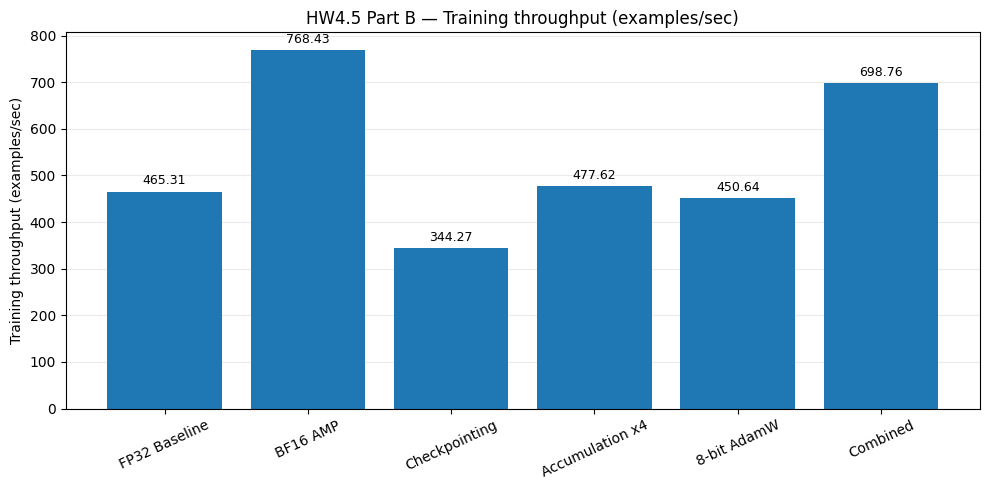

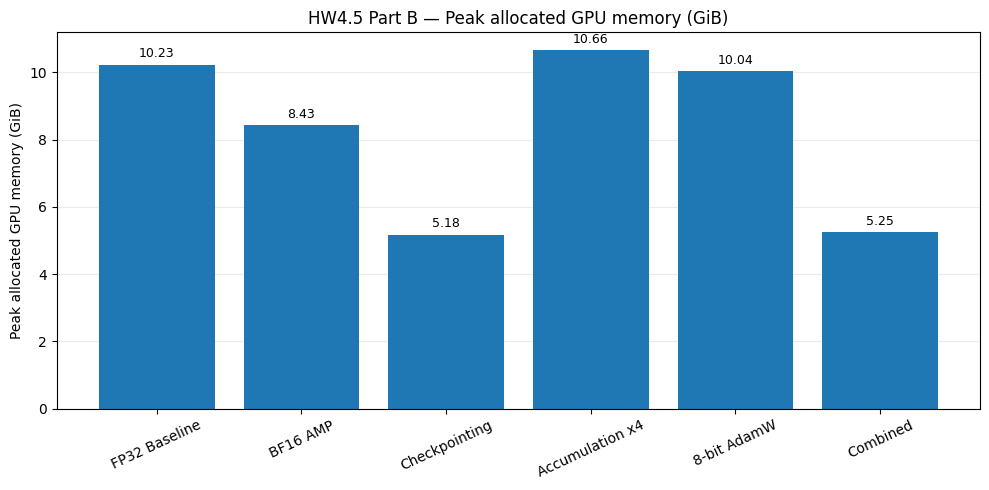

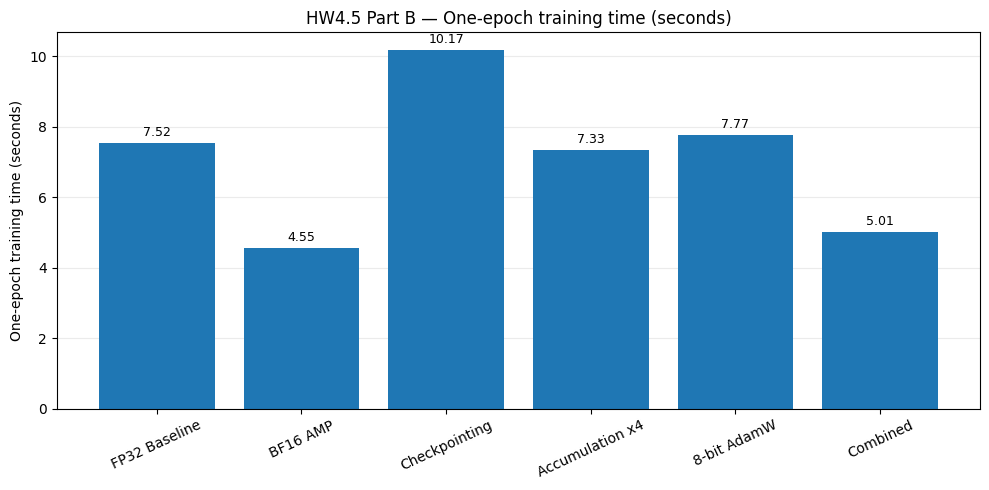

ImportError: Missing optional dependency 'tabulate'.  Use pip or conda to install tabulate.

In [41]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART B: GPU OPTIMIZATION EXPERIMENTS
#
# STEP 38: GENERATE COMPARISON REPORT AND FIGURES
#
# SUMMARY:
# 1. Load all six saved Part B experiment results.
# 2. Validate experiment completeness.
# 3. Calculate relative speed and memory changes.
# 4. Generate throughput, memory, and epoch-time plots.
# 5. Save a comparison CSV, JSON, and Markdown report.
#
# COMMANDS:
# - Read metrics/part_b_*.json.
# - Generate three figures.
# - Save PART_B_SUMMARY.md.
#
# NOTE:
# No training or model checkpoint changes.
# ============================================================

import json
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime

print("=" * 65)
print("HW4.5 PART B — STEP 38")
print("GENERATE OPTIMIZATION COMPARISON REPORT")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"
FIGURE_DIR = PROJECT_DIR / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

experiment_files = [
    "part_b_baseline.json",
    "part_b_amp_bf16.json",
    "part_b_gradient_checkpointing.json",
    "part_b_gradient_accumulation.json",
    "part_b_adamw_8bit.json",
    "part_b_combined.json"
]

labels = [
    "FP32 Baseline",
    "BF16 AMP",
    "Checkpointing",
    "Accumulation x4",
    "8-bit AdamW",
    "Combined"
]

results = []

for filename, label in zip(experiment_files, labels):
    path = METRICS_DIR / filename
    assert path.exists(), f"Missing: {path}"

    with open(path) as f:
        record = json.load(f)

    assert record["training_examples"] == 3500

    results.append({
        "configuration": label,
        "epoch_seconds": record["epoch_seconds"],
        "throughput_ex_per_sec": record["examples_per_second"],
        "peak_allocated_gib": record["peak_allocated_gib"],
        "peak_reserved_gib": record["peak_reserved_gib"],
        "average_loss": record["average_loss"],
        "effective_batch_size": record["effective_batch_size"]
    })

df = pd.DataFrame(results)

baseline = df.iloc[0]

df["speedup_vs_fp32"] = (
    baseline["epoch_seconds"] / df["epoch_seconds"]
)

df["memory_reduction_percent"] = (
    (
        baseline["peak_allocated_gib"]
        - df["peak_allocated_gib"]
    )
    / baseline["peak_allocated_gib"]
    * 100
)

# ------------------------------------------------------------
# 1. IDENTIFY BEST CONFIGURATIONS
# ------------------------------------------------------------

fastest = df.loc[
    df["throughput_ex_per_sec"].idxmax()
]

lowest_memory = df.loc[
    df["peak_allocated_gib"].idxmin()
]

print("\nCOMPARISON TABLE")
print("-" * 65)

print(
    df[
        [
            "configuration",
            "epoch_seconds",
            "throughput_ex_per_sec",
            "peak_allocated_gib",
            "speedup_vs_fp32",
            "memory_reduction_percent"
        ]
    ].round(3).to_string(index=False)
)

# ------------------------------------------------------------
# 2. GENERATE FIGURES
# ------------------------------------------------------------

plots = [
    (
        "throughput_ex_per_sec",
        "Training throughput (examples/sec)",
        "part_b_throughput_comparison.png"
    ),
    (
        "peak_allocated_gib",
        "Peak allocated GPU memory (GiB)",
        "part_b_memory_comparison.png"
    ),
    (
        "epoch_seconds",
        "One-epoch training time (seconds)",
        "part_b_epoch_time_comparison.png"
    )
]

saved_figures = []

for column, ylabel, filename in plots:

    fig, ax = plt.subplots(figsize=(10, 5))

    bars = ax.bar(
        df["configuration"],
        df[column]
    )

    ax.set_title(
        "HW4.5 Part B — " + ylabel
    )
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=25)

    ax.grid(
        axis="y",
        alpha=0.25
    )
    ax.set_axisbelow(True)

    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.2f}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9
        )

    fig.tight_layout()

    path = FIGURE_DIR / filename
    fig.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    saved_figures.append(str(path))

# ------------------------------------------------------------
# 3. SAVE COMPARISON METRICS
# ------------------------------------------------------------

csv_path = METRICS_DIR / "part_b_comparison.csv"
json_path = METRICS_DIR / "part_b_comparison.json"

df.to_csv(csv_path, index=False)

summary = {
    "part": "B",
    "gpu": "NVIDIA GeForce RTX 4090",
    "experiment_count": len(df),
    "fastest_configuration": fastest["configuration"],
    "fastest_throughput": float(
        fastest["throughput_ex_per_sec"]
    ),
    "lowest_memory_configuration": (
        lowest_memory["configuration"]
    ),
    "lowest_peak_allocated_gib": float(
        lowest_memory["peak_allocated_gib"]
    ),
    "experiments": df.to_dict(orient="records"),
    "figures": saved_figures,
    "timestamp": datetime.now().isoformat()
}

with open(json_path, "w") as f:
    json.dump(summary, f, indent=4)

# ------------------------------------------------------------
# 4. GENERATE MARKDOWN REPORT
# ------------------------------------------------------------

report_path = PROJECT_DIR / "PART_B_SUMMARY.md"

report = [
    "# HW4.5 Part B — GPU Optimization Summary",
    "",
    "## Hardware",
    "",
    "- GPU: NVIDIA GeForce RTX 4090",
    "- Training examples: 3,500",
    "- Model: BERT sentiment classifier",
    "- Physical batch size: 64",
    "- Training: one epoch per configuration",
    "",
    "## Optimization Results",
    "",
    df.round(3).to_markdown(index=False),
    "",
    "## Key Findings",
    "",
    (
        f"- Fastest: **{fastest['configuration']}** "
        f"({fastest['throughput_ex_per_sec']:.2f} examples/sec)."
    ),
    (
        f"- Lowest memory: **{lowest_memory['configuration']}** "
        f"({lowest_memory['peak_allocated_gib']:.2f} GiB)."
    ),
    (
        "- Gradient accumulation uses effective batch size "
        "256, whereas the other independent experiments "
        "use effective batch size 64."
    ),
    (
        "- The combined configuration also uses effective "
        "batch size 256, so its optimization dynamics differ "
        "from the FP32 baseline."
    ),
    (
        "- Peak memory values are measured PyTorch CUDA "
        "allocated-memory peaks, not total system VRAM."
    ),
    "",
    "## Figures",
    ""
]

for path in saved_figures:
    report.append(f"- `{Path(path).name}`")

report.extend([
    "",
    "## Reproducibility",
    "",
    "- Seed: 1980",
    "- PyTorch: 2.1.2",
    "- bitsandbytes: 0.43.1",
    "- Starting checkpoint: `models/bert_best`",
    "- Original checkpoint preserved",
    ""
])

report_path.write_text(
    "\n".join(report),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 5. FINAL OUTPUT
# ------------------------------------------------------------

print("\nBEST CONFIGURATIONS")
print("-" * 65)

print(
    f"Fastest       : {fastest['configuration']} "
    f"({fastest['throughput_ex_per_sec']:.2f} ex/s)"
)

print(
    f"Lowest memory : {lowest_memory['configuration']} "
    f"({lowest_memory['peak_allocated_gib']:.2f} GiB)"
)

print("\nSAVED")
print("-" * 65)

print(csv_path)
print(json_path)
print(report_path)

for path in saved_figures:
    print(path)

print("=" * 65)
print("STEP 38 COMPLETE")
print("=" * 65)


In [42]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART B: GPU OPTIMIZATION EXPERIMENTS
#
# STEP 38A: FIX MISSING TABULATE ERROR
#
# SUMMARY:
# 1. Load the already-saved Part B comparison CSV.
# 2. Generate Markdown table without tabulate.
# 3. Write PART_B_SUMMARY.md.
# 4. Verify all three figures and report files.
#
# COMMANDS:
# - Read part_b_comparison.csv.
# - Build Markdown table using Python strings.
# - Save and verify PART_B_SUMMARY.md.
#
# NOTE:
# No package installation or training.
# ============================================================

from pathlib import Path
import pandas as pd
import json

print("=" * 65)
print("HW4.5 PART B — STEP 38A")
print("FIX MARKDOWN REPORT GENERATION")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"
FIGURE_DIR = PROJECT_DIR / "figures"

csv_path = METRICS_DIR / "part_b_comparison.csv"
json_path = METRICS_DIR / "part_b_comparison.json"
report_path = PROJECT_DIR / "PART_B_SUMMARY.md"

assert csv_path.exists(), "Comparison CSV missing."
assert json_path.exists(), "Comparison JSON missing."

df = pd.read_csv(csv_path)
assert len(df) == 6

columns = [
    "configuration",
    "epoch_seconds",
    "throughput_ex_per_sec",
    "peak_allocated_gib",
    "speedup_vs_fp32",
    "memory_reduction_percent"
]

headers = [
    "Configuration",
    "Epoch (s)",
    "Throughput (ex/s)",
    "Peak VRAM (GiB)",
    "Speedup",
    "Memory reduction (%)"
]

table_lines = [
    "| " + " | ".join(headers) + " |",
    "| " + " | ".join(["---"] * len(headers)) + " |"
]

for _, row in df.iterrows():
    values = [
        str(row["configuration"]),
        f"{row['epoch_seconds']:.3f}",
        f"{row['throughput_ex_per_sec']:.2f}",
        f"{row['peak_allocated_gib']:.3f}",
        f"{row['speedup_vs_fp32']:.3f}x",
        f"{row['memory_reduction_percent']:.2f}%"
    ]
    table_lines.append("| " + " | ".join(values) + " |")

fastest = df.loc[df["throughput_ex_per_sec"].idxmax()]
lowest_memory = df.loc[df["peak_allocated_gib"].idxmin()]
combined = df.loc[df["configuration"] == "Combined"].iloc[0]

figure_names = [
    "part_b_throughput_comparison.png",
    "part_b_memory_comparison.png",
    "part_b_epoch_time_comparison.png"
]

for filename in figure_names:
    assert (FIGURE_DIR / filename).exists(), (
        f"Missing figure: {filename}"
    )

report = [
    "# HW4.5 Part B — GPU Optimization Summary",
    "",
    "## Experimental Setup",
    "",
    "- GPU: NVIDIA GeForce RTX 4090 (23.99 GiB)",
    "- Model: BERT sentiment classifier",
    "- Training examples: 3,500",
    "- Physical batch size: 64",
    "- Training duration: one epoch per experiment",
    "- Seed: 1980",
    "- Starting checkpoint: `models/bert_best`",
    "",
    "## Optimization Results",
    "",
    *table_lines,
    "",
    "## Key Findings",
    "",
    (
        f"- **Fastest:** {fastest['configuration']} "
        f"at {fastest['throughput_ex_per_sec']:.2f} "
        "examples/sec."
    ),
    (
        f"- **Lowest peak allocated memory:** "
        f"{lowest_memory['configuration']} "
        f"at {lowest_memory['peak_allocated_gib']:.2f} GiB."
    ),
    (
        f"- **Combined optimization:** "
        f"{combined['speedup_vs_fp32']:.2f}x speedup "
        f"with {combined['memory_reduction_percent']:.2f}% "
        "less peak allocated memory than FP32."
    ),
    (
        "- Gradient accumulation and the combined configuration "
        "use effective batch size 256 and 14 optimizer updates; "
        "the other experiments use effective batch size 64."
    ),
    (
        "- Results are single-run measurements. "
        "Small performance differences require repeated "
        "measurements before drawing firm conclusions."
    ),
    (
        "- Reported GPU memory is peak PyTorch CUDA "
        "allocated memory, not total device memory."
    ),
    "",
    "## Figures",
    ""
]

for filename in figure_names:
    report.append(f"- `figures/{filename}`")

report.extend([
    "",
    "## Software",
    "",
    "- PyTorch: 2.1.2",
    "- bitsandbytes: 0.43.1",
    "- AMP precision: BF16",
    "- Optimizers: AdamW and AdamW8bit",
    "",
])

report_path.write_text(
    "\n".join(report),
    encoding="utf-8"
)

assert report_path.exists()
assert report_path.stat().st_size > 0

print("\nBEST CONFIGURATIONS")
print("-" * 65)
print(
    f"Fastest       : {fastest['configuration']} "
    f"({fastest['throughput_ex_per_sec']:.2f} ex/s)"
)
print(
    f"Lowest memory : {lowest_memory['configuration']} "
    f"({lowest_memory['peak_allocated_gib']:.2f} GiB)"
)

print("\nVERIFIED FILES")
print("-" * 65)

for path in [csv_path, json_path, report_path]:
    print("PASS:", path)

for filename in figure_names:
    print("PASS:", FIGURE_DIR / filename)

print("\nPASS: No tabulate dependency required.")
print("PASS: Part B summary report generated.")

print("=" * 65)
print("STEP 38A COMPLETE")
print("=" * 65)


HW4.5 PART B — STEP 38A
FIX MARKDOWN REPORT GENERATION

BEST CONFIGURATIONS
-----------------------------------------------------------------
Fastest       : BF16 AMP (768.43 ex/s)
Lowest memory : Checkpointing (5.18 GiB)

VERIFIED FILES
-----------------------------------------------------------------
PASS: /app/HW4_5_GPU_Assignment/metrics/part_b_comparison.csv
PASS: /app/HW4_5_GPU_Assignment/metrics/part_b_comparison.json
PASS: /app/HW4_5_GPU_Assignment/PART_B_SUMMARY.md
PASS: /app/HW4_5_GPU_Assignment/figures/part_b_throughput_comparison.png
PASS: /app/HW4_5_GPU_Assignment/figures/part_b_memory_comparison.png
PASS: /app/HW4_5_GPU_Assignment/figures/part_b_epoch_time_comparison.png

PASS: No tabulate dependency required.
PASS: Part B summary report generated.
STEP 38A COMPLETE


In [43]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART C: DISTRIBUTED DATA PARALLEL
#
# STEP 39: GPU TOPOLOGY AND DDP READINESS
#
# SUMMARY:
# 1. Detect available CUDA GPUs.
# 2. Verify PyTorch distributed and NCCL support.
# 3. Check whether a two-GPU experiment is possible.
# 4. Save hardware and DDP readiness diagnostics.
#
# COMMANDS:
# - torch.cuda.device_count()
# - torch.distributed.is_available()
# - torch.distributed.is_nccl_available()
# - Save metrics/part_c_ddp_readiness.json.
#
# NOTE:
# No training, process spawning, or package installation.
# ============================================================

import json
import torch
import torch.distributed as dist

from pathlib import Path
from datetime import datetime

print("=" * 65)
print("HW4.5 PART C — STEP 39")
print("GPU TOPOLOGY AND DDP READINESS")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"
METRICS_DIR.mkdir(parents=True, exist_ok=True)

gpu_count = torch.cuda.device_count()
distributed_available = dist.is_available()
nccl_available = (
    dist.is_nccl_available()
    if distributed_available else False
)

gpus = []

print("\nGPU INVENTORY")
print("-" * 65)
print("CUDA device count:", gpu_count)

for i in range(gpu_count):
    props = torch.cuda.get_device_properties(i)
    info = {
        "index": i,
        "name": props.name,
        "total_vram_gib": round(
            props.total_memory / 1024**3, 3
        )
    }
    gpus.append(info)
    print(
        f"GPU {i}: {props.name} "
        f"({info['total_vram_gib']:.2f} GiB)"
    )

print("\nDISTRIBUTED BACKEND")
print("-" * 65)
print("PyTorch version       :", torch.__version__)
print("Distributed available :", distributed_available)
print("NCCL available        :", nccl_available)
print("Two-GPU DDP possible  :", gpu_count >= 2 and nccl_available)

result = {
    "step": 39,
    "part": "C",
    "pytorch_version": torch.__version__,
    "cuda_gpu_count": gpu_count,
    "gpus": gpus,
    "distributed_available": distributed_available,
    "nccl_available": nccl_available,
    "two_gpu_ddp_possible": (
        gpu_count >= 2 and nccl_available
    ),
    "timestamp": datetime.now().isoformat()
}

output_path = METRICS_DIR / "part_c_ddp_readiness.json"

with open(output_path, "w") as f:
    json.dump(result, f, indent=4)

print("\nSaved:", output_path)
print("=" * 65)
print("STEP 39 COMPLETE")
print("=" * 65)


HW4.5 PART C — STEP 39
GPU TOPOLOGY AND DDP READINESS

GPU INVENTORY
-----------------------------------------------------------------
CUDA device count: 1
GPU 0: NVIDIA GeForce RTX 4090 (23.99 GiB)

DISTRIBUTED BACKEND
-----------------------------------------------------------------
PyTorch version       : 2.1.2
Distributed available : True
NCCL available        : True
Two-GPU DDP possible  : False

Saved: /app/HW4_5_GPU_Assignment/metrics/part_c_ddp_readiness.json
STEP 39 COMPLETE


In [44]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART C: DISTRIBUTED DATA PARALLEL
#
# STEP 40: SINGLE-GPU DDP FUNCTIONAL TEST
#
# SUMMARY:
# 1. Initialize a one-process NCCL process group.
# 2. Load a fresh BERT checkpoint.
# 3. Wrap the model using DistributedDataParallel.
# 4. Train on 128 examples.
# 5. Verify optimizer steps and finite losses.
# 6. Destroy the process group and save results.
#
# COMMANDS:
# - init_process_group(backend="nccl", world_size=1)
# - DistributedDataParallel(model, device_ids=[0])
# - Train two batches of 64.
# - Save metrics/part_c_single_gpu_ddp.json.
#
# NOTE:
# This validates DDP functionality only.
# It does NOT measure multi-GPU scaling or communication.
# ============================================================

import os
import gc
import json
import time
import random
import tempfile

import numpy as np
import torch
import torch.distributed as dist

from pathlib import Path
from datetime import datetime
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import DataLoader, TensorDataset
from transformers import BertForSequenceClassification

print("=" * 65)
print("HW4.5 PART C — STEP 40")
print("SINGLE-GPU DDP FUNCTIONAL TEST")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"
CHECKPOINT = PROJECT_DIR / "models" / "bert_best"

SEED = 1980
BATCH_SIZE = 64
DEVICE = torch.device("cuda:0")

assert torch.cuda.device_count() == 1
assert dist.is_available()
assert dist.is_nccl_available()
assert CHECKPOINT.exists()
assert not dist.is_initialized(), (
    "A distributed process group is already active."
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

gc.collect()
torch.cuda.empty_cache()

# ------------------------------------------------------------
# 1. LOAD FIXED TRAINING SUBSET
# ------------------------------------------------------------

saved = torch.load(
    PROJECT_DIR / "tokenized_tensors" / "train_tensors.pt",
    map_location="cpu"
)

subset = TensorDataset(
    saved["input_ids"][:128],
    saved["attention_mask"][:128],
    saved["labels"][:128]
)

loader = DataLoader(
    subset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# ------------------------------------------------------------
# 2. INITIALIZE DDP AND TRAIN
# ------------------------------------------------------------

ddp_model = None
optimizer = None
losses = []
optimizer_steps = 0

with tempfile.TemporaryDirectory() as temp_dir:

    rendezvous_file = Path(temp_dir) / "ddp_init"

    try:
        dist.init_process_group(
            backend="nccl",
            init_method=f"file://{rendezvous_file}",
            rank=0,
            world_size=1
        )

        assert dist.is_initialized()
        assert dist.get_world_size() == 1
        assert dist.get_rank() == 0

        model = BertForSequenceClassification.from_pretrained(
            str(CHECKPOINT)
        ).to(DEVICE)

        ddp_model = DDP(
            model,
            device_ids=[0],
            output_device=0
        )

        ddp_model.train()

        optimizer = torch.optim.AdamW(
            ddp_model.parameters(),
            lr=2e-5,
            weight_decay=0.01
        )

        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

        start = time.perf_counter()

        for step, (ids, mask, labels) in enumerate(
            loader, 1
        ):
            ids = ids.to(DEVICE)
            mask = mask.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad(set_to_none=True)

            outputs = ddp_model(
                input_ids=ids,
                attention_mask=mask,
                labels=labels
            )

            loss = outputs.loss

            assert torch.isfinite(loss).item(), (
                f"Non-finite loss at step {step}"
            )

            loss.backward()
            optimizer.step()

            losses.append(loss.item())
            optimizer_steps += 1

            print(
                f"Step {step}/{len(loader)} "
                f"| Loss: {loss.item():.4f}",
                flush=True
            )

        torch.cuda.synchronize()

        elapsed = time.perf_counter() - start
        peak_allocated = (
            torch.cuda.max_memory_allocated() / 1024**3
        )

    finally:
        if dist.is_initialized():
            dist.destroy_process_group()

# ------------------------------------------------------------
# 3. VALIDATE RESULTS
# ------------------------------------------------------------

assert optimizer_steps == 2
assert len(losses) == 2
assert not dist.is_initialized()

result = {
    "part": "C",
    "step": 40,
    "experiment": "single_gpu_ddp_functional_test",
    "gpu": torch.cuda.get_device_name(0),
    "backend": "nccl",
    "world_size": 1,
    "rank": 0,
    "batch_size": BATCH_SIZE,
    "training_examples": 128,
    "optimizer_steps": optimizer_steps,
    "losses": losses,
    "elapsed_seconds": elapsed,
    "examples_per_second": 128 / elapsed,
    "peak_allocated_gib": peak_allocated,
    "ddp_functional": True,
    "multi_gpu_scaling_measured": False,
    "communication_overhead_measured": False,
    "timestamp": datetime.now().isoformat()
}

output_path = METRICS_DIR / "part_c_single_gpu_ddp.json"

with open(output_path, "w") as f:
    json.dump(result, f, indent=4)

print("\nDDP TEST RESULTS")
print("-" * 65)
print("Backend             : NCCL")
print("World size          : 1")
print("Examples processed  : 128")
print("Optimizer steps     :", optimizer_steps)
print(f"Elapsed time        : {elapsed:.3f} sec")
print(f"Throughput          : {128 / elapsed:.2f} ex/s")
print(f"Peak allocated VRAM : {peak_allocated:.2f} GiB")
print("Process group closed:", not dist.is_initialized())

print("\nPASS: Single-GPU DDP training completed.")
print("NOTE: Multi-GPU scaling was not measured.")
print("Saved:", output_path)

del ddp_model, optimizer, model, loader
gc.collect()
torch.cuda.empty_cache()

print("=" * 65)
print("STEP 40 COMPLETE")
print("=" * 65)


HW4.5 PART C — STEP 40
SINGLE-GPU DDP FUNCTIONAL TEST
Step 1/2 | Loss: 0.4362
Step 2/2 | Loss: 0.4096

DDP TEST RESULTS
-----------------------------------------------------------------
Backend             : NCCL
World size          : 1
Examples processed  : 128
Optimizer steps     : 2
Elapsed time        : 0.528 sec
Throughput          : 242.62 ex/s
Peak allocated VRAM : 11.11 GiB
Process group closed: True

PASS: Single-GPU DDP training completed.
NOTE: Multi-GPU scaling was not measured.
Saved: /app/HW4_5_GPU_Assignment/metrics/part_c_single_gpu_ddp.json
STEP 40 COMPLETE


In [45]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART C: DISTRIBUTED DATA PARALLEL
#
# STEP 41: FINALIZE DDP EXPERIMENT REPORT
#
# SUMMARY:
# 1. Load GPU topology diagnostics.
# 2. Load single-GPU DDP functional-test results.
# 3. Verify DDP execution and process cleanup.
# 4. Document unavailable multi-GPU measurements.
# 5. Save Part C summary JSON and Markdown.
#
# COMMANDS:
# - Read part_c_ddp_readiness.json.
# - Read part_c_single_gpu_ddp.json.
# - Write part_c_summary.json.
# - Write PART_C_SUMMARY.md.
#
# NOTE:
# No training or GPU allocation changes.
# ============================================================

import json
from pathlib import Path
from datetime import datetime

print("=" * 65)
print("HW4.5 PART C — STEP 41")
print("FINALIZE DDP EXPERIMENT REPORT")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"

readiness_path = METRICS_DIR / "part_c_ddp_readiness.json"
ddp_path = METRICS_DIR / "part_c_single_gpu_ddp.json"

assert readiness_path.exists()
assert ddp_path.exists()

with open(readiness_path) as f:
    readiness = json.load(f)

with open(ddp_path) as f:
    ddp = json.load(f)

# ------------------------------------------------------------
# 1. VERIFY SAVED EXPERIMENTS
# ------------------------------------------------------------

assert readiness["cuda_gpu_count"] == 1
assert readiness["distributed_available"] is True
assert readiness["nccl_available"] is True
assert readiness["two_gpu_ddp_possible"] is False

assert ddp["ddp_functional"] is True
assert ddp["world_size"] == 1
assert ddp["training_examples"] == 128
assert ddp["optimizer_steps"] == 2
assert ddp["multi_gpu_scaling_measured"] is False
assert ddp["communication_overhead_measured"] is False

# ------------------------------------------------------------
# 2. CREATE STRUCTURED SUMMARY
# ------------------------------------------------------------

summary = {
    "part": "C",
    "status": "single_gpu_ddp_verified",
    "gpu_count": readiness["cuda_gpu_count"],
    "gpu": readiness["gpus"][0]["name"],
    "backend": ddp["backend"],
    "world_size": ddp["world_size"],
    "training_examples": ddp["training_examples"],
    "optimizer_steps": ddp["optimizer_steps"],
    "elapsed_seconds": ddp["elapsed_seconds"],
    "throughput_ex_per_sec": ddp["examples_per_second"],
    "peak_allocated_gib": ddp["peak_allocated_gib"],
    "single_gpu_ddp_functional": True,
    "two_gpu_scaling_available": False,
    "two_gpu_speedup": None,
    "scaling_efficiency": None,
    "inter_gpu_communication_overhead": None,
    "limitation": (
        "Only one RTX 4090 was available. "
        "A world_size=1 NCCL DDP training test succeeded. "
        "Two-GPU scaling and inter-GPU communication "
        "overhead were not measured."
    ),
    "timestamp": datetime.now().isoformat()
}

summary_path = METRICS_DIR / "part_c_summary.json"

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

# ------------------------------------------------------------
# 3. WRITE MARKDOWN REPORT
# ------------------------------------------------------------

report_path = PROJECT_DIR / "PART_C_SUMMARY.md"

report = f"""# HW4.5 Part C — Distributed Data Parallel

## Hardware and Environment

- GPU: {summary['gpu']}
- Available GPU count: {summary['gpu_count']}
- PyTorch distributed: Available
- NCCL backend: Available
- Two-GPU allocation: Not available

## Single-GPU DDP Functional Test

| Metric | Result |
|---|---|
| Backend | NCCL |
| World size | 1 |
| Training examples | {ddp['training_examples']} |
| Optimizer steps | {ddp['optimizer_steps']} |
| Training time | {ddp['elapsed_seconds']:.3f} seconds |
| Throughput | {ddp['examples_per_second']:.2f} examples/sec |
| Peak allocated memory | {ddp['peak_allocated_gib']:.2f} GiB |
| DDP training | Successful |

The model was wrapped using PyTorch
`DistributedDataParallel` and trained successfully
with one process on GPU 0.

The NCCL process group was initialized and destroyed
successfully.

## Multi-GPU Scaling

Two-GPU scaling was not measured because only one GPU
was available.

The following measurements are therefore unavailable:

- Two-GPU training throughput
- Two-GPU speedup
- Scaling efficiency
- Inter-GPU communication overhead

These values are intentionally not estimated or
fabricated.

## Interpretation

The experiment validates single-process DDP setup,
model wrapping, forward/backward execution, and
optimizer updates.

It does not demonstrate distributed acceleration
or multi-GPU gradient synchronization.

## Saved Evidence

- `metrics/part_c_ddp_readiness.json`
- `metrics/part_c_single_gpu_ddp.json`
- `metrics/part_c_summary.json`
"""

report_path.write_text(
    report,
    encoding="utf-8"
)

# ------------------------------------------------------------
# 4. VERIFY FILES
# ------------------------------------------------------------

assert summary_path.exists()
assert report_path.exists()
assert report_path.stat().st_size > 0

print("\nPART C SUMMARY")
print("-" * 65)
print("Single-GPU DDP       : PASS")
print("NCCL backend         : PASS")
print("GPU count            :", summary["gpu_count"])
print("World size           :", summary["world_size"])
print("Training examples    :", summary["training_examples"])
print("Optimizer steps      :", summary["optimizer_steps"])
print("Two-GPU scaling      : Not measured")
print("Communication overhead: Not measured")

print("\nSAVED FILES")
print("-" * 65)
print(summary_path)
print(report_path)

print("=" * 65)
print("STEP 41 COMPLETE")
print("=" * 65)


HW4.5 PART C — STEP 41
FINALIZE DDP EXPERIMENT REPORT

PART C SUMMARY
-----------------------------------------------------------------
Single-GPU DDP       : PASS
NCCL backend         : PASS
GPU count            : 1
World size           : 1
Training examples    : 128
Optimizer steps      : 2
Two-GPU scaling      : Not measured
Communication overhead: Not measured

SAVED FILES
-----------------------------------------------------------------
/app/HW4_5_GPU_Assignment/metrics/part_c_summary.json
/app/HW4_5_GPU_Assignment/PART_C_SUMMARY.md
STEP 41 COMPLETE


In [46]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART D: vLLM AND KV-CACHE ANALYSIS
#
# STEP 42: vLLM ENVIRONMENT AND MODEL READINESS
#
# SUMMARY:
# 1. Verify the existing vLLM virtual environment.
# 2. Check whether vLLM was installed previously.
# 3. Inspect PyTorch/Transformers versions in that venv.
# 4. Inspect the saved BERT checkpoint configuration.
# 5. Check the BERT model's KV-cache capabilities.
# 6. Save readiness diagnostics.
#
# COMMANDS:
# - Inspect vllm_env/bin/python.
# - Query package metadata without installing anything.
# - Read models/bert_best/config.json.
# - Save metrics/part_d_readiness.json.
#
# NOTE:
# No pip installation, model loading, or GPU training.
# ============================================================

import json
import subprocess
from pathlib import Path
from datetime import datetime

print("=" * 65)
print("HW4.5 PART D — STEP 42")
print("vLLM ENVIRONMENT AND MODEL READINESS")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"
VENV_DIR = PROJECT_DIR / "vllm_env"
VENV_PYTHON = VENV_DIR / "bin" / "python"
MODEL_CONFIG = (
    PROJECT_DIR / "models" / "bert_best" / "config.json"
)

assert MODEL_CONFIG.exists(), (
    "Saved BERT checkpoint config not found."
)

def package_version(python_path, package_name):
    """Check installed package version without importing it."""
    script = (
        "from importlib.metadata import version, "
        "PackageNotFoundError\n"
        f"try:\n print(version('{package_name}'))\n"
        "except PackageNotFoundError:\n print('NOT INSTALLED')\n"
    )

    try:
        result = subprocess.run(
            [str(python_path), "-c", script],
            capture_output=True,
            text=True,
            timeout=15
        )

        if result.returncode != 0:
            return "CHECK FAILED: " + result.stderr.strip()[:200]

        return result.stdout.strip()

    except Exception as exc:
        return f"CHECK FAILED: {type(exc).__name__}: {exc}"

# ------------------------------------------------------------
# 1. CHECK VIRTUAL ENVIRONMENT
# ------------------------------------------------------------

venv_exists = VENV_PYTHON.exists()

print("\nvLLM ENVIRONMENT")
print("-" * 65)
print("Virtual environment :", VENV_DIR)
print("Python executable   :", VENV_PYTHON)
print("Environment exists  :", venv_exists)

packages = {}

if venv_exists:
    for name in ["vllm", "torch", "transformers"]:
        packages[name] = package_version(
            VENV_PYTHON, name
        )
        print(f"{name:20}: {packages[name]}")
else:
    print("No usable vLLM Python executable found.")

# ------------------------------------------------------------
# 2. INSPECT BERT CHECKPOINT
# ------------------------------------------------------------

with open(MODEL_CONFIG) as f:
    config = json.load(f)

model_type = config.get("model_type")
architectures = config.get("architectures", [])
is_decoder = config.get("is_decoder", False)
add_cross_attention = config.get(
    "add_cross_attention", False
)

print("\nBERT CHECKPOINT")
print("-" * 65)
print("Model type           :", model_type)
print("Architecture         :", architectures)
print("Decoder mode         :", is_decoder)
print("Cross-attention      :", add_cross_attention)
print("Number of labels     :", config.get("num_labels"))
print("Max positions        :", config.get(
    "max_position_embeddings"
))

# ------------------------------------------------------------
# 3. ASSESS KV-CACHE RELEVANCE
# ------------------------------------------------------------

autoregressive_decoder = bool(is_decoder)

print("\nKV-CACHE READINESS")
print("-" * 65)
print(
    "Autoregressive decoder:",
    autoregressive_decoder
)

if not autoregressive_decoder:
    print(
        "NOTE: This BERT checkpoint is an encoder-style "
        "classification model."
    )
    print(
        "NOTE: Standard autoregressive generation "
        "KV-cache benchmarks require a decoder model."
    )

vllm_installed = (
    packages.get("vllm", "NOT INSTALLED")
    not in ["NOT INSTALLED", ""]
    and not packages.get("vllm", "").startswith(
        "CHECK FAILED"
    )
)

# ------------------------------------------------------------
# 4. SAVE DIAGNOSTICS
# ------------------------------------------------------------

result = {
    "part": "D",
    "step": 42,
    "venv_exists": venv_exists,
    "venv_python": str(VENV_PYTHON),
    "packages": packages,
    "vllm_installed": vllm_installed,
    "checkpoint_config": str(MODEL_CONFIG),
    "model_type": model_type,
    "architectures": architectures,
    "is_decoder": is_decoder,
    "add_cross_attention": add_cross_attention,
    "autoregressive_kv_cache_applicable": (
        autoregressive_decoder
    ),
    "timestamp": datetime.now().isoformat()
}

output_path = METRICS_DIR / "part_d_readiness.json"

with open(output_path, "w") as f:
    json.dump(result, f, indent=4)

print("\nSaved:", output_path)
print("=" * 65)
print("STEP 42 COMPLETE")
print("=" * 65)


HW4.5 PART D — STEP 42
vLLM ENVIRONMENT AND MODEL READINESS

vLLM ENVIRONMENT
-----------------------------------------------------------------
Virtual environment : /app/HW4_5_GPU_Assignment/vllm_env
Python executable   : /app/HW4_5_GPU_Assignment/vllm_env/bin/python
Environment exists  : True
vllm                : NOT INSTALLED
torch               : 2.9.0
transformers        : 4.57.6

BERT CHECKPOINT
-----------------------------------------------------------------
Model type           : bert
Architecture         : ['BertForSequenceClassification']
Decoder mode         : False
Cross-attention      : False
Number of labels     : None
Max positions        : 512

KV-CACHE READINESS
-----------------------------------------------------------------
Autoregressive decoder: False
NOTE: This BERT checkpoint is an encoder-style classification model.
NOTE: Standard autoregressive generation KV-cache benchmarks require a decoder model.

Saved: /app/HW4_5_GPU_Assignment/metrics/part_d_readiness.

In [47]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART D: vLLM AND KV-CACHE ANALYSIS
#
# STEP 43: CAUSAL LM AND vLLM PREREQUISITES
#
# SUMMARY:
# 1. Verify isolated vLLM environment packages.
# 2. Check GPU visibility from the isolated environment.
# 3. Inspect available disk space.
# 4. Look for existing cached causal language models.
# 5. Save Part D prerequisite diagnostics.
#
# COMMANDS:
# - Inspect vllm_env packages.
# - Check CUDA with the venv's PyTorch.
# - Check Hugging Face cache.
# - Save metrics/part_d_prerequisites.json.
#
# NOTE:
# No downloads, installation, or GPU training.
# ============================================================

import json
import os
import shutil
import subprocess

from pathlib import Path
from datetime import datetime

print("=" * 65)
print("HW4.5 PART D — STEP 43")
print("CAUSAL LM AND vLLM PREREQUISITES")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"
VENV_PYTHON = PROJECT_DIR / "vllm_env/bin/python"

assert VENV_PYTHON.exists()

# ------------------------------------------------------------
# 1. CHECK ISOLATED ENVIRONMENT
# ------------------------------------------------------------

check_script = r"""
import json
import torch
import transformers

result = {
    "torch_version": torch.__version__,
    "transformers_version": transformers.__version__,
    "cuda_available": torch.cuda.is_available(),
    "cuda_version": torch.version.cuda,
    "gpu_count": torch.cuda.device_count(),
    "gpu_name": (
        torch.cuda.get_device_name(0)
        if torch.cuda.is_available() else None
    )
}

print(json.dumps(result))
"""

check = subprocess.run(
    [str(VENV_PYTHON), "-c", check_script],
    capture_output=True,
    text=True,
    timeout=60
)

print("\nISOLATED ENVIRONMENT")
print("-" * 65)

if check.returncode == 0:
    env_info = json.loads(check.stdout.strip())
    for key, value in env_info.items():
        print(f"{key:25}: {value}")
else:
    env_info = {
        "error": check.stderr[-1000:]
    }
    print("Environment check failed:")
    print(check.stderr[-1000:])

# ------------------------------------------------------------
# 2. CHECK DISK SPACE
# ------------------------------------------------------------

disk = shutil.disk_usage(PROJECT_DIR)

disk_info = {
    "total_gib": round(disk.total / 1024**3, 2),
    "used_gib": round(disk.used / 1024**3, 2),
    "free_gib": round(disk.free / 1024**3, 2)
}

print("\nDISK SPACE")
print("-" * 65)

for key, value in disk_info.items():
    print(f"{key:25}: {value}")

# ------------------------------------------------------------
# 3. CHECK CACHED HUGGING FACE MODELS
# ------------------------------------------------------------

cache_roots = [
    Path(os.environ.get(
        "HF_HUB_CACHE",
        Path.home() / ".cache/huggingface/hub"
    )),
    Path("/app/.cache/huggingface/hub"),
    Path("/root/.cache/huggingface/hub")
]

cache_roots = list(dict.fromkeys(cache_roots))

cached_models = []

for cache_root in cache_roots:
    if cache_root.exists():
        for path in cache_root.glob("models--*"):
            if path.is_dir():
                cached_models.append({
                    "name": path.name,
                    "path": str(path)
                })

print("\nCACHED HUGGING FACE MODELS")
print("-" * 65)

if cached_models:
    for model in cached_models[:30]:
        print(model["name"])
else:
    print("No model cache entries found in checked paths.")

# ------------------------------------------------------------
# 4. SAVE DIAGNOSTICS
# ------------------------------------------------------------

result = {
    "part": "D",
    "step": 43,
    "isolated_environment": env_info,
    "disk": disk_info,
    "cached_models": cached_models,
    "timestamp": datetime.now().isoformat()
}

output_path = METRICS_DIR / "part_d_prerequisites.json"

with open(output_path, "w") as f:
    json.dump(result, f, indent=4)

print("\nSaved:", output_path)
print("=" * 65)
print("STEP 43 COMPLETE")
print("=" * 65)


HW4.5 PART D — STEP 43
CAUSAL LM AND vLLM PREREQUISITES

ISOLATED ENVIRONMENT
-----------------------------------------------------------------
torch_version            : 2.9.0+cu128
transformers_version     : 4.57.6
cuda_available           : True
cuda_version             : 12.8
gpu_count                : 1
gpu_name                 : NVIDIA GeForce RTX 4090

DISK SPACE
-----------------------------------------------------------------
total_gib                : 3793.54
used_gib                 : 2236.75
free_gib                 : 1556.79

CACHED HUGGING FACE MODELS
-----------------------------------------------------------------
models--bert-base-uncased

Saved: /app/HW4_5_GPU_Assignment/metrics/part_d_prerequisites.json
STEP 43 COMPLETE


In [48]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART D: vLLM AND KV-CACHE ANALYSIS
#
# STEP 44: DOWNLOAD AND VERIFY CAUSAL LANGUAGE MODEL
#
# SUMMARY:
# 1. Check whether facebook/opt-125m is already local.
# 2. Download it only if needed.
# 3. Verify the model is a causal language model.
# 4. Check tokenizer and configuration.
# 5. Save download and verification metadata.
#
# COMMANDS:
# - Run isolated Python environment.
# - Download facebook/opt-125m.
# - Verify AutoModelForCausalLM and tokenizer.
# - Save metrics/part_d_model_setup.json.
#
# NOTE:
# No GPU training or BERT checkpoint modifications.
# ============================================================

import json
import subprocess
from pathlib import Path

print("=" * 65)
print("HW4.5 PART D — STEP 44")
print("DOWNLOAD AND VERIFY CAUSAL LANGUAGE MODEL")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
VENV_PYTHON = PROJECT_DIR / "vllm_env/bin/python"
MODEL_DIR = PROJECT_DIR / "models/opt_125m"
METRICS_DIR = PROJECT_DIR / "metrics"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

script = r'''
import json
from pathlib import Path
from transformers import (
    AutoConfig,
    AutoTokenizer,
    AutoModelForCausalLM
)

model_id = "facebook/opt-125m"
model_dir = Path("/app/HW4_5_GPU_Assignment/models/opt_125m")

print("MODEL:", model_id, flush=True)

if not (model_dir / "config.json").exists():
    print("Downloading model and tokenizer...", flush=True)

    tokenizer = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForCausalLM.from_pretrained(model_id)

    tokenizer.save_pretrained(model_dir)
    model.save_pretrained(
        model_dir,
        safe_serialization=True
    )

    print("Download complete.", flush=True)
else:
    print("Existing model found. Verifying...", flush=True)

    tokenizer = AutoTokenizer.from_pretrained(model_dir)
    model = AutoModelForCausalLM.from_pretrained(model_dir)

config = AutoConfig.from_pretrained(model_dir)

assert config.is_encoder_decoder is False
assert model.can_generate()
assert tokenizer.vocab_size > 0

result = {
    "model_id": model_id,
    "local_path": str(model_dir),
    "model_type": config.model_type,
    "is_encoder_decoder": config.is_encoder_decoder,
    "can_generate": model.can_generate(),
    "vocab_size": tokenizer.vocab_size,
    "max_position_embeddings": getattr(
        config, "max_position_embeddings", None
    ),
    "parameters": sum(p.numel() for p in model.parameters()),
    "verified": True
}

output_path = Path(
    "/app/HW4_5_GPU_Assignment/metrics/part_d_model_setup.json"
)

with open(output_path, "w") as f:
    json.dump(result, f, indent=4)

print("\nMODEL VERIFICATION")
print("-" * 65)

for key, value in result.items():
    print(f"{key:25}: {value}")

print("\nSaved:", output_path)
print("PASS: Causal LM verified.", flush=True)
'''

process = subprocess.Popen(
    [str(VENV_PYTHON), "-u", "-c", script],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

for line in process.stdout:
    print(line, end="", flush=True)

return_code = process.wait()

if return_code != 0:
    raise RuntimeError(
        f"Model setup failed with exit code {return_code}"
    )

assert (METRICS_DIR / "part_d_model_setup.json").exists()

print("=" * 65)
print("STEP 44 COMPLETE")
print("=" * 65)


HW4.5 PART D — STEP 44
DOWNLOAD AND VERIFY CAUSAL LANGUAGE MODEL
MODEL: facebook/opt-125m
Download complete.

MODEL VERIFICATION
-----------------------------------------------------------------
model_id                 : facebook/opt-125m
local_path               : /app/HW4_5_GPU_Assignment/models/opt_125m
model_type               : opt
is_encoder_decoder       : False
can_generate             : True
vocab_size               : 50265
max_position_embeddings  : 2048
parameters               : 125239296
verified                 : True

Saved: /app/HW4_5_GPU_Assignment/metrics/part_d_model_setup.json
PASS: Causal LM verified.
STEP 44 COMPLETE


In [49]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART D: vLLM AND KV-CACHE ANALYSIS
#
# STEP 45: KV-CACHE ENABLED VS DISABLED
#
# SUMMARY:
# 1. Load OPT-125M from the local model directory.
# 2. Benchmark generation with KV cache ON and OFF.
# 3. Use identical input tokens and generation lengths.
# 4. Measure latency, throughput, and peak CUDA memory.
# 5. Save results as JSON and CSV.
#
# COMMANDS:
# - AutoModelForCausalLM.from_pretrained(...)
# - model.generate(use_cache=True/False)
# - torch.cuda.synchronize()
# - Save metrics/part_d_kv_cache_benchmark.*
#
# NOTE:
# No model training or package installation.
# ============================================================

import json
import subprocess
from pathlib import Path

print("=" * 65)
print("HW4.5 PART D — STEP 45")
print("KV-CACHE ENABLED VS DISABLED BENCHMARK")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
VENV_PYTHON = PROJECT_DIR / "vllm_env/bin/python"

assert VENV_PYTHON.exists()

script = r'''
import gc
import json
import time
import statistics

import pandas as pd
import torch

from pathlib import Path
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM
)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
MODEL_DIR = PROJECT_DIR / "models/opt_125m"
METRICS_DIR = PROJECT_DIR / "metrics"

torch.manual_seed(1980)

assert torch.cuda.is_available()

device = torch.device("cuda:0")

print("\nLOADING MODEL", flush=True)

tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_DIR,
    torch_dtype=torch.float16
).to(device)

model.eval()

# Fixed token sequences ensure identical benchmark inputs.
prompt_text = (
    "Artificial intelligence can support healthcare "
    "professionals by analyzing clinical information "
    "and identifying relevant patterns. "
) * 30

encoded = tokenizer(
    prompt_text,
    return_tensors="pt",
    add_special_tokens=True
)

# Compare short and longer contexts.
context_lengths = [128, 512, 1024]
new_token_counts = [32, 64]

warmup_runs = 1
measured_runs = 3

results = []

print("GPU:", torch.cuda.get_device_name(0), flush=True)
print("Model: facebook/opt-125m", flush=True)
print("Precision: FP16", flush=True)

with torch.inference_mode():

    for context_length in context_lengths:

        # Repeat token IDs if source text is too short.
        ids = encoded["input_ids"][0]

        repeat_count = (
            context_length // ids.numel()
        ) + 2

        ids = ids.repeat(repeat_count)[
            :context_length
        ].unsqueeze(0).to(device)

        mask = torch.ones_like(ids)

        for new_tokens in new_token_counts:

            for use_cache in [True, False]:

                print(
                    f"\nContext={context_length} "
                    f"| New tokens={new_tokens} "
                    f"| KV cache={use_cache}",
                    flush=True
                )

                latencies = []
                peak_memory = []

                for run in range(
                    warmup_runs + measured_runs
                ):

                    gc.collect()
                    torch.cuda.empty_cache()

                    torch.cuda.synchronize()
                    torch.cuda.reset_peak_memory_stats()

                    start = time.perf_counter()

                    output = model.generate(
                        input_ids=ids,
                        attention_mask=mask,
                        max_new_tokens=new_tokens,
                        do_sample=False,
                        use_cache=use_cache,
                        pad_token_id=tokenizer.eos_token_id,
                        eos_token_id=None
                    )

                    torch.cuda.synchronize()

                    elapsed = (
                        time.perf_counter() - start
                    )

                    peak = (
                        torch.cuda.max_memory_allocated()
                        / 1024**3
                    )

                    assert (
                        output.shape[1]
                        == context_length + new_tokens
                    )

                    if run >= warmup_runs:
                        latencies.append(elapsed)
                        peak_memory.append(peak)

                avg_latency = statistics.mean(
                    latencies
                )

                result = {
                    "context_tokens": context_length,
                    "generated_tokens": new_tokens,
                    "kv_cache": use_cache,
                    "mean_latency_seconds": avg_latency,
                    "p50_latency_seconds": statistics.median(
                        latencies
                    ),
                    "tokens_per_second": (
                        new_tokens / avg_latency
                    ),
                    "peak_allocated_gib": max(
                        peak_memory
                    ),
                    "measured_runs": measured_runs,
                    "precision": "FP16"
                }

                results.append(result)

                print(
                    f"Mean latency: {avg_latency:.3f}s "
                    f"| Throughput: "
                    f"{result['tokens_per_second']:.2f} tok/s "
                    f"| Peak: "
                    f"{result['peak_allocated_gib']:.3f} GiB",
                    flush=True
                )

# ------------------------------------------------------------
# SAVE RESULTS
# ------------------------------------------------------------

df = pd.DataFrame(results)

csv_path = (
    METRICS_DIR / "part_d_kv_cache_benchmark.csv"
)

json_path = (
    METRICS_DIR / "part_d_kv_cache_benchmark.json"
)

df.to_csv(csv_path, index=False)

with open(json_path, "w") as f:
    json.dump({
        "model": "facebook/opt-125m",
        "gpu": torch.cuda.get_device_name(0),
        "precision": "FP16",
        "warmup_runs": warmup_runs,
        "measured_runs": measured_runs,
        "results": results
    }, f, indent=4)

print("\nRESULTS")
print("-" * 65)

print(
    df[
        [
            "context_tokens",
            "generated_tokens",
            "kv_cache",
            "mean_latency_seconds",
            "tokens_per_second",
            "peak_allocated_gib"
        ]
    ].round(3).to_string(index=False)
)

print("\nSaved:", csv_path)
print("Saved:", json_path)

print("PASS: KV-cache benchmark completed.", flush=True)
'''

process = subprocess.Popen(
    [str(VENV_PYTHON), "-u", "-c", script],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

for line in process.stdout:
    print(line, end="", flush=True)

return_code = process.wait()

if return_code != 0:
    raise RuntimeError(
        f"KV-cache benchmark failed with exit code {return_code}"
    )

print("=" * 65)
print("STEP 45 COMPLETE")
print("=" * 65)


HW4.5 PART D — STEP 45
KV-CACHE ENABLED VS DISABLED BENCHMARK
Traceback (most recent call last):
  File "<string>", line 7, in <module>
ModuleNotFoundError: No module named 'pandas'


RuntimeError: KV-cache benchmark failed with exit code 1

In [50]:

# ============================================================
# HW4.5 — PART D
# STEP 45A: FIX PANDAS DEPENDENCY AND RERUN BENCHMARK
#
# SUMMARY:
# 1. Remove pandas from the isolated benchmark script.
# 2. Replace pandas CSV export with Python's csv module.
# 3. Preserve all existing benchmark configurations.
# 4. Rerun Step 45 without installing packages.
#
# COMMANDS:
# - Patch the existing 'script' variable from Step 45.
# - Execute with vllm_env/bin/python.
# - Verify benchmark output files.
# ============================================================

import subprocess
from pathlib import Path

print("=" * 65)
print("HW4.5 PART D — STEP 45A")
print("FIX PANDAS DEPENDENCY")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
VENV_PYTHON = PROJECT_DIR / "vllm_env/bin/python"

# 'script' was defined in Step 45.
assert "script" in globals(), (
    "Step 45 script variable not found."
)

fixed_script = script.replace(
    "import pandas as pd",
    "import csv"
)

fixed_script = fixed_script.replace(
    "df = pd.DataFrame(results)",
    ""
)

fixed_script = fixed_script.replace(
    "df.to_csv(csv_path, index=False)",
    """with open(csv_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(results[0].keys())
    )
    writer.writeheader()
    writer.writerows(results)"""
)

fixed_script = fixed_script.replace(
    '''print(
    df[
        [
            "context_tokens",
            "generated_tokens",
            "kv_cache",
            "mean_latency_seconds",
            "tokens_per_second",
            "peak_allocated_gib"
        ]
    ].round(3).to_string(index=False)
)''',
    '''for row in results:
    print(
        f"Context={row['context_tokens']:4d} "
        f"| New={row['generated_tokens']:2d} "
        f"| Cache={str(row['kv_cache']):5s} "
        f"| Latency={row['mean_latency_seconds']:.3f}s "
        f"| Throughput={row['tokens_per_second']:.2f} tok/s "
        f"| Peak={row['peak_allocated_gib']:.3f} GiB"
    )'''
)

assert "import pandas" not in fixed_script
assert "pd.DataFrame" not in fixed_script
assert "df.to_csv" not in fixed_script

print("PASS: pandas dependency removed.")
print("Starting KV-cache benchmark...", flush=True)

process = subprocess.Popen(
    [str(VENV_PYTHON), "-u", "-c", fixed_script],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

for line in process.stdout:
    print(line, end="", flush=True)

return_code = process.wait()

if return_code != 0:
    raise RuntimeError(
        f"Benchmark failed with exit code {return_code}"
    )

csv_path = (
    PROJECT_DIR / "metrics/part_d_kv_cache_benchmark.csv"
)
json_path = (
    PROJECT_DIR / "metrics/part_d_kv_cache_benchmark.json"
)

assert csv_path.exists()
assert json_path.exists()

print("\nPASS: CSV and JSON files verified.")
print("=" * 65)
print("STEP 45A COMPLETE")
print("=" * 65)


HW4.5 PART D — STEP 45A
FIX PANDAS DEPENDENCY
PASS: pandas dependency removed.
Starting KV-cache benchmark...

LOADING MODEL
`torch_dtype` is deprecated! Use `dtype` instead!
GPU: NVIDIA GeForce RTX 4090
Model: facebook/opt-125m
Precision: FP16

Context=128 | New tokens=32 | KV cache=True
Mean latency: 0.126s | Throughput: 254.19 tok/s | Peak: 0.266 GiB

Context=128 | New tokens=32 | KV cache=False
Mean latency: 0.123s | Throughput: 260.56 tok/s | Peak: 0.265 GiB

Context=128 | New tokens=64 | KV cache=True
Mean latency: 0.246s | Throughput: 259.64 tok/s | Peak: 0.266 GiB

Context=128 | New tokens=64 | KV cache=False
Mean latency: 0.244s | Throughput: 262.69 tok/s | Peak: 0.268 GiB

Context=512 | New tokens=32 | KV cache=True
Mean latency: 0.193s | Throughput: 165.43 tok/s | Peak: 0.316 GiB

Context=512 | New tokens=32 | KV cache=False
Mean latency: 0.136s | Throughput: 235.45 tok/s | Peak: 0.301 GiB

Context=512 | New tokens=64 | KV cache=True
Mean latency: 0.252s | Throughput: 254.10

HW4.5 PART D — STEP 46
KV-CACHE COMPARISON PLOTS AND REPORT


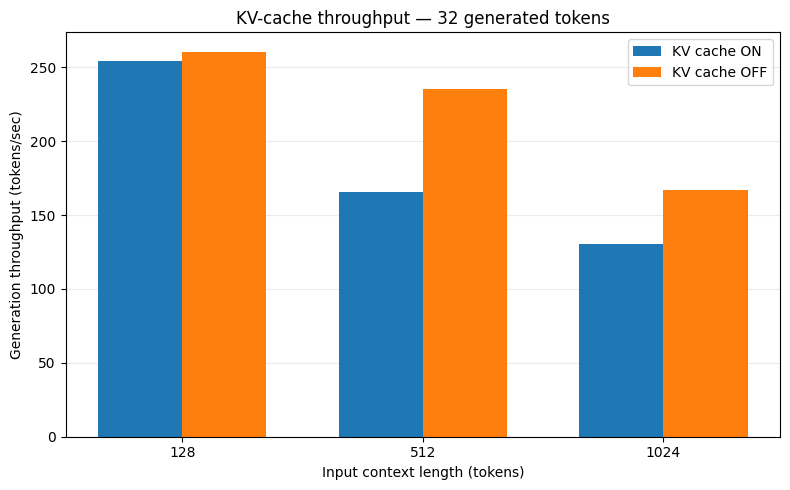

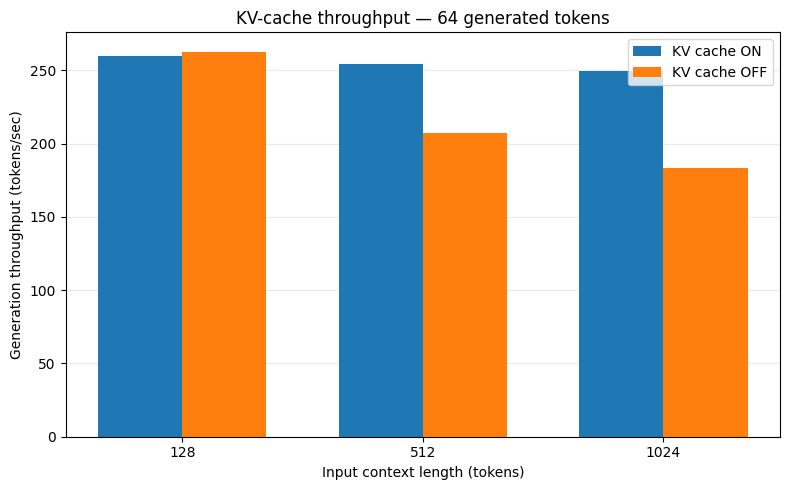

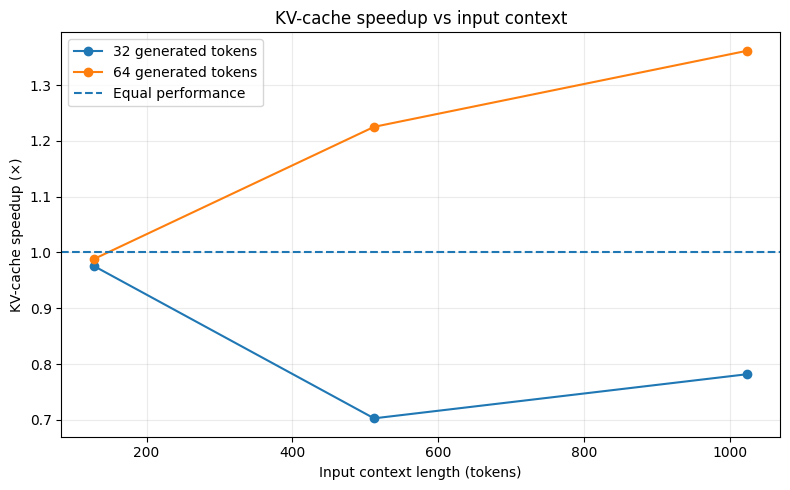


KV-CACHE SUMMARY
-----------------------------------------------------------------
Comparisons       : 6
Cache faster      : 2
Cache slower      : 4

SAVED
-----------------------------------------------------------------
/app/HW4_5_GPU_Assignment/metrics/part_d_kv_cache_summary.json
/app/HW4_5_GPU_Assignment/metrics/part_d_kv_cache_comparison.csv
/app/HW4_5_GPU_Assignment/PART_D_KV_CACHE_SUMMARY.md
/app/HW4_5_GPU_Assignment/figures/part_d_kv_throughput_32.png
/app/HW4_5_GPU_Assignment/figures/part_d_kv_throughput_64.png
/app/HW4_5_GPU_Assignment/figures/part_d_kv_cache_speedup.png
STEP 46 COMPLETE


In [51]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART D: vLLM AND KV-CACHE ANALYSIS
#
# STEP 46: KV-CACHE COMPARISON PLOTS AND REPORT
#
# SUMMARY:
# 1. Load saved KV-cache benchmark results.
# 2. Calculate cache ON/OFF speedup.
# 3. Plot throughput and GPU memory.
# 4. Plot cache speedup by context length.
# 5. Save summary JSON and Markdown.
#
# COMMANDS:
# - Read part_d_kv_cache_benchmark.json.
# - Generate three figures.
# - Save part_d_kv_cache_summary.json.
# - Save PART_D_KV_CACHE_SUMMARY.md.
#
# NOTE:
# No training, downloads, or package installation.
# ============================================================

import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from pathlib import Path

print("=" * 65)
print("HW4.5 PART D — STEP 46")
print("KV-CACHE COMPARISON PLOTS AND REPORT")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
METRICS_DIR = PROJECT_DIR / "metrics"
FIGURE_DIR = PROJECT_DIR / "figures"

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

source_path = (
    METRICS_DIR / "part_d_kv_cache_benchmark.json"
)

assert source_path.exists()

with open(source_path) as f:
    source = json.load(f)

df = pd.DataFrame(source["results"])

assert len(df) == 12

# ------------------------------------------------------------
# 1. CALCULATE CACHE SPEEDUP
# ------------------------------------------------------------

cache_on = df[df["kv_cache"] == True].copy()
cache_off = df[df["kv_cache"] == False].copy()

paired = cache_on.merge(
    cache_off,
    on=["context_tokens", "generated_tokens"],
    suffixes=("_on", "_off")
)

paired["cache_speedup"] = (
    paired["mean_latency_seconds_off"]
    / paired["mean_latency_seconds_on"]
)

paired["memory_difference_gib"] = (
    paired["peak_allocated_gib_on"]
    - paired["peak_allocated_gib_off"]
)

assert len(paired) == 6

# ------------------------------------------------------------
# 2. GENERATE THREE PLOTS
# ------------------------------------------------------------

figure_paths = []

for new_tokens in [32, 64]:

    subset = paired[
        paired["generated_tokens"] == new_tokens
    ].sort_values("context_tokens")

    x = np.arange(len(subset))
    width = 0.35

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.bar(
        x - width / 2,
        subset["tokens_per_second_on"],
        width,
        label="KV cache ON"
    )

    ax.bar(
        x + width / 2,
        subset["tokens_per_second_off"],
        width,
        label="KV cache OFF"
    )

    ax.set_xticks(x)
    ax.set_xticklabels(
        subset["context_tokens"].astype(str)
    )

    ax.set_xlabel("Input context length (tokens)")
    ax.set_ylabel("Generation throughput (tokens/sec)")
    ax.set_title(
        f"KV-cache throughput — {new_tokens} generated tokens"
    )
    ax.legend()
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    fig.tight_layout()

    path = (
        FIGURE_DIR
        / f"part_d_kv_throughput_{new_tokens}.png"
    )

    fig.savefig(path, dpi=180)
    plt.show()
    plt.close(fig)

    figure_paths.append(str(path))

fig, ax = plt.subplots(figsize=(8, 5))

for new_tokens in [32, 64]:

    subset = paired[
        paired["generated_tokens"] == new_tokens
    ].sort_values("context_tokens")

    ax.plot(
        subset["context_tokens"],
        subset["cache_speedup"],
        marker="o",
        label=f"{new_tokens} generated tokens"
    )

ax.axhline(
    y=1.0,
    linestyle="--",
    label="Equal performance"
)

ax.set_xlabel("Input context length (tokens)")
ax.set_ylabel("KV-cache speedup (×)")
ax.set_title("KV-cache speedup vs input context")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()

speedup_path = FIGURE_DIR / "part_d_kv_cache_speedup.png"

fig.savefig(speedup_path, dpi=180)
plt.show()
plt.close(fig)

figure_paths.append(str(speedup_path))

# ------------------------------------------------------------
# 3. SAVE SUMMARY
# ------------------------------------------------------------

summary = {
    "part": "D",
    "model": source["model"],
    "gpu": source["gpu"],
    "precision": source["precision"],
    "benchmark_type": "Hugging Face KV-cache comparison",
    "measured_runs": source["measured_runs"],
    "comparison_count": len(paired),
    "cache_faster_count": int(
        (paired["cache_speedup"] > 1).sum()
    ),
    "cache_slower_count": int(
        (paired["cache_speedup"] < 1).sum()
    ),
    "paired_results": paired.to_dict(
        orient="records"
    ),
    "figures": figure_paths
}

summary_path = (
    METRICS_DIR / "part_d_kv_cache_summary.json"
)

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

paired_csv = (
    METRICS_DIR / "part_d_kv_cache_comparison.csv"
)

paired.to_csv(paired_csv, index=False)

# ------------------------------------------------------------
# 4. GENERATE MARKDOWN REPORT
# ------------------------------------------------------------

report_path = PROJECT_DIR / "PART_D_KV_CACHE_SUMMARY.md"

lines = [
    "# HW4.5 Part D — KV-Cache Analysis",
    "",
    "## Setup",
    "",
    "- Model: facebook/opt-125m",
    "- GPU: NVIDIA RTX 4090",
    "- Precision: FP16",
    "- Backend: Hugging Face Transformers",
    "- Context lengths: 128, 512, 1024 tokens",
    "- Generated lengths: 32 and 64 tokens",
    "- Three measured runs per configuration",
    "",
    "## Comparison",
    "",
    "| Context | New tokens | Cache speedup | Memory difference (GiB) |",
    "|---|---:|---:|---:|"
]

for _, row in paired.iterrows():
    lines.append(
        f"| {int(row['context_tokens'])} "
        f"| {int(row['generated_tokens'])} "
        f"| {row['cache_speedup']:.3f}x "
        f"| {row['memory_difference_gib']:+.3f} |"
    )

lines.extend([
    "",
    "## Findings",
    "",
    (
        f"- KV caching was faster in "
        f"{summary['cache_faster_count']} of "
        f"{summary['comparison_count']} comparisons."
    ),
    (
        "- Results were mixed, especially for shorter "
        "generation lengths."
    ),
    (
        "- KV caching retains attention keys and values "
        "and may increase GPU memory usage."
    ),
    (
        "- Small model size and short runs can make "
        "cache overhead and timing noise significant."
    ),
    (
        "- These are Hugging Face generation results, "
        "not vLLM throughput measurements."
    ),
    "",
    "## Figures",
    ""
])

for path in figure_paths:
    lines.append(f"- `figures/{Path(path).name}`")

report_path.write_text(
    "\n".join(lines) + "\n",
    encoding="utf-8"
)

# ------------------------------------------------------------
# 5. VERIFY
# ------------------------------------------------------------

assert summary_path.exists()
assert paired_csv.exists()
assert report_path.exists()

for path in figure_paths:
    assert Path(path).exists()

print("\nKV-CACHE SUMMARY")
print("-" * 65)
print("Comparisons       :", len(paired))
print("Cache faster      :", summary["cache_faster_count"])
print("Cache slower      :", summary["cache_slower_count"])

print("\nSAVED")
print("-" * 65)
print(summary_path)
print(paired_csv)
print(report_path)

for path in figure_paths:
    print(path)

print("=" * 65)
print("STEP 46 COMPLETE")
print("=" * 65)


In [52]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART D: vLLM AND KV-CACHE ANALYSIS
#
# STEP 47: INSTALL vLLM IN ISOLATED ENVIRONMENT
#
# SUMMARY:
# 1. Check whether vLLM is already installed.
# 2. Install vLLM 0.11.2 if missing.
# 3. Stream installation output.
# 4. Verify installed package metadata.
# 5. Save installation results.
#
# COMMANDS:
# - Run pip inside vllm_env only.
# - Verify vLLM version.
# - Save metrics/part_d_vllm_install.json.
#
# NOTE:
# Original BERT environment remains unchanged.
# ============================================================

import json
import subprocess
import sys
import time
from pathlib import Path
from datetime import datetime
from importlib.metadata import version, PackageNotFoundError

print("=" * 65)
print("HW4.5 PART D — STEP 47")
print("INSTALL vLLM IN ISOLATED ENVIRONMENT")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
VENV_PYTHON = PROJECT_DIR / "vllm_env/bin/python"
METRICS_DIR = PROJECT_DIR / "metrics"

assert VENV_PYTHON.exists()

# ------------------------------------------------------------
# 1. CHECK EXISTING VERSION
# ------------------------------------------------------------

check_script = """
from importlib.metadata import version, PackageNotFoundError
try:
    print(version("vllm"))
except PackageNotFoundError:
    print("NOT INSTALLED")
"""

check = subprocess.run(
    [str(VENV_PYTHON), "-c", check_script],
    capture_output=True,
    text=True,
    timeout=20
)

installed_version = check.stdout.strip()

print("Existing vLLM:", installed_version)

# ------------------------------------------------------------
# 2. INSTALL IF NECESSARY
# ------------------------------------------------------------

install_elapsed = 0.0

if installed_version == "NOT INSTALLED":

    command = [
        str(VENV_PYTHON),
        "-m",
        "pip",
        "install",
        "--disable-pip-version-check",
        "--progress-bar",
        "off",
        "vllm==0.11.2"
    ]

    print("\nStarting isolated vLLM installation...")
    print("Timeout: 300 seconds")
    print("Output will stream below.\n", flush=True)

    start = time.perf_counter()

    try:
        process = subprocess.run(
            command,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            timeout=300
        )

        install_elapsed = time.perf_counter() - start

        print(process.stdout[-12000:], flush=True)

        if process.returncode != 0:
            raise RuntimeError(
                f"pip exited with code {process.returncode}"
            )

    except subprocess.TimeoutExpired as exc:
        raise RuntimeError(
            "vLLM installation exceeded 300 seconds. "
            "Do not repeat automatically."
        ) from exc

else:
    print("vLLM already installed; skipping pip.")

# ------------------------------------------------------------
# 3. VERIFY INSTALLED VERSION
# ------------------------------------------------------------

verify = subprocess.run(
    [str(VENV_PYTHON), "-c", check_script],
    capture_output=True,
    text=True,
    timeout=20
)

verified_version = verify.stdout.strip()

assert verified_version == "0.11.2", (
    f"Unexpected vLLM version: {verified_version}"
)

result = {
    "part": "D",
    "step": 47,
    "vllm_version": verified_version,
    "environment": str(VENV_PYTHON),
    "install_elapsed_seconds": install_elapsed,
    "verified": True,
    "timestamp": datetime.now().isoformat()
}

output_path = METRICS_DIR / "part_d_vllm_install.json"

with open(output_path, "w") as f:
    json.dump(result, f, indent=4)

print("\nINSTALLATION VERIFICATION")
print("-" * 65)
print("vLLM version :", verified_version)
print("Environment  :", VENV_PYTHON)
print("Install time :", round(install_elapsed, 2), "sec")
print("Saved        :", output_path)

print("\nPASS: vLLM installation verified.")
print("=" * 65)
print("STEP 47 COMPLETE")
print("=" * 65)


HW4.5 PART D — STEP 47
INSTALL vLLM IN ISOLATED ENVIRONMENT
Existing vLLM: NOT INSTALLED

Starting isolated vLLM installation...
Timeout: 300 seconds
Output will stream below.



RuntimeError: vLLM installation exceeded 300 seconds. Do not repeat automatically.

In [53]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART D: vLLM INSTALLATION
#
# STEP 47A: DIAGNOSE INSTALLATION TIMEOUT
#
# SUMMARY:
# 1. Check vLLM installation status.
# 2. Check isolated environment package versions.
# 3. Inspect pip download cache.
# 4. Check for remaining pip processes.
# 5. Save diagnostic results.
#
# COMMANDS:
# - importlib.metadata
# - pip cache info
# - ps
# - Save metrics/part_d_vllm_diagnostics.json
#
# NOTE:
# No pip install, package download, or GPU benchmark.
# ============================================================

import json
import subprocess
from pathlib import Path

print("=" * 65)
print("HW4.5 PART D — STEP 47A")
print("DIAGNOSE vLLM INSTALLATION TIMEOUT")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
VENV_PYTHON = PROJECT_DIR / "vllm_env/bin/python"
METRICS_DIR = PROJECT_DIR / "metrics"

# ------------------------------------------------------------
# 1. PACKAGE STATUS
# ------------------------------------------------------------

package_script = r'''
import json
from importlib.metadata import version, PackageNotFoundError

packages = [
    "vllm",
    "torch",
    "transformers",
    "tokenizers",
    "triton",
    "xformers",
    "flashinfer-python",
    "numpy",
    "safetensors"
]

result = {}

for package in packages:
    try:
        result[package] = version(package)
    except PackageNotFoundError:
        result[package] = "NOT INSTALLED"

print(json.dumps(result))
'''

check = subprocess.run(
    [str(VENV_PYTHON), "-c", package_script],
    capture_output=True,
    text=True,
    timeout=30
)

assert check.returncode == 0, check.stderr

packages = json.loads(check.stdout.strip())

print("\nPACKAGE STATUS")
print("-" * 65)

for name, installed in packages.items():
    print(f"{name:22}: {installed}")

# ------------------------------------------------------------
# 2. PIP CACHE
# ------------------------------------------------------------

cache_check = subprocess.run(
    [
        str(VENV_PYTHON),
        "-m",
        "pip",
        "cache",
        "info"
    ],
    capture_output=True,
    text=True,
    timeout=30
)

print("\nPIP CACHE")
print("-" * 65)
print(cache_check.stdout.strip() or cache_check.stderr.strip())

# ------------------------------------------------------------
# 3. REMAINING INSTALLATION PROCESSES
# ------------------------------------------------------------

process_check = subprocess.run(
    ["ps", "-eo", "pid,etime,args"],
    capture_output=True,
    text=True,
    timeout=15
)

matching_processes = [
    line.strip()
    for line in process_check.stdout.splitlines()
    if (
        "pip install" in line
        or "vllm==0.11.2" in line
    )
    and "ps -eo" not in line
]

print("\nREMAINING PIP PROCESSES")
print("-" * 65)

if matching_processes:
    for line in matching_processes:
        print(line)
else:
    print("No matching installation processes.")

# ------------------------------------------------------------
# 4. SAVE DIAGNOSTICS
# ------------------------------------------------------------

result = {
    "step": "47A",
    "previous_install_status": "TIMEOUT_300_SECONDS",
    "packages": packages,
    "pip_cache_info": cache_check.stdout,
    "remaining_install_processes": matching_processes
}

output_path = (
    METRICS_DIR / "part_d_vllm_diagnostics.json"
)

with open(output_path, "w") as f:
    json.dump(result, f, indent=4)

print("\nSaved:", output_path)

print("=" * 65)
print("STEP 47A COMPLETE")
print("=" * 65)


HW4.5 PART D — STEP 47A
DIAGNOSE vLLM INSTALLATION TIMEOUT

PACKAGE STATUS
-----------------------------------------------------------------
vllm                  : NOT INSTALLED
torch                 : 2.9.0
transformers          : 4.57.6
tokenizers            : 0.22.2
triton                : 3.5.0
xformers              : 0.0.33.post1
flashinfer-python     : NOT INSTALLED
numpy                 : 2.2.6
safetensors           : 0.8.0

PIP CACHE
-----------------------------------------------------------------
Package index page cache location: /root/.cache/pip/http
Package index page cache size: 590.4 MB
Number of HTTP files: 36
Locally built wheels location: /root/.cache/pip/wheels
Locally built wheels size: 0 bytes
Number of locally built wheels: 0

REMAINING PIP PROCESSES
-----------------------------------------------------------------
No matching installation processes.

Saved: /app/HW4_5_GPU_Assignment/metrics/part_d_vllm_diagnostics.json
STEP 47A COMPLETE


In [54]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART D: vLLM INSTALLATION
#
# STEP 47B: INSPECT REMAINING vLLM DEPENDENCIES
#
# SUMMARY:
# 1. Run pip dependency resolution in dry-run mode.
# 2. Avoid downloading or installing package files.
# 3. Identify packages still required by vLLM.
# 4. Record reported download sizes where available.
# 5. Save diagnostic output.
#
# COMMANDS:
# - pip install --dry-run --report
# - Read dependency report.
# - Save metrics/part_d_vllm_dry_run.json.
#
# NOTE:
# No package installation or GPU operations.
# Pip may contact the package index for metadata.
# ============================================================

import json
import subprocess
from pathlib import Path

print("=" * 65)
print("HW4.5 PART D — STEP 47B")
print("INSPECT REMAINING vLLM DEPENDENCIES")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
VENV_PYTHON = PROJECT_DIR / "vllm_env/bin/python"
METRICS_DIR = PROJECT_DIR / "metrics"

report_path = METRICS_DIR / "part_d_vllm_dry_run.json"

command = [
    str(VENV_PYTHON),
    "-m", "pip", "install",
    "--dry-run",
    "--report", str(report_path),
    "--disable-pip-version-check",
    "--progress-bar", "off",
    "vllm==0.11.2"
]

print("\nResolving dependencies (maximum 90 seconds)...")
print("No packages will be installed.\n", flush=True)

try:
    process = subprocess.run(
        command,
        capture_output=True,
        text=True,
        timeout=90
    )

    print("PIP OUTPUT")
    print("-" * 65)
    print(process.stdout[-6000:])

    if process.returncode != 0:
        print("\nPIP ERRORS")
        print(process.stderr[-4000:])

except subprocess.TimeoutExpired as exc:
    print("Dependency resolution exceeded 90 seconds.")
    print("No installation was performed.")
    process = None

if report_path.exists():

    with open(report_path) as f:
        report = json.load(f)

    packages = []

    for item in report.get("install", []):
        metadata = item.get("metadata", {})
        download_info = item.get("download_info", {})

        packages.append({
            "name": metadata.get("name"),
            "version": metadata.get("version"),
            "url": download_info.get("url", "")
        })

    print("\nPACKAGES PIP PLANS TO INSTALL")
    print("-" * 65)

    for package in packages:
        print(
            f"{package['name']:30} "
            f"{package['version']}"
        )

    print("\nTotal packages:", len(packages))
    print("Saved:", report_path)

else:
    print("\nNo completed dependency report available.")

print("=" * 65)
print("STEP 47B COMPLETE")
print("=" * 65)


HW4.5 PART D — STEP 47B
INSPECT REMAINING vLLM DEPENDENCIES

Resolving dependencies (maximum 90 seconds)...
No packages will be installed.

PIP OUTPUT
-----------------------------------------------------------------
-cutlass-dsl-libs-base==4.8.1 in ./HW4_5_GPU_Assignment/vllm_env/lib/python3.10/site-packages (from nvidia-cutlass-dsl>=4.2.1->flashinfer-python==0.5.2->vllm==0.11.2) (4.8.1)
Would install flashinfer-python-0.5.2 vllm-0.11.2


PACKAGES PIP PLANS TO INSTALL
-----------------------------------------------------------------
vllm                           0.11.2
flashinfer-python              0.5.2

Total packages: 2
Saved: /app/HW4_5_GPU_Assignment/metrics/part_d_vllm_dry_run.json
STEP 47B COMPLETE


In [55]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART D: vLLM INSTALLATION
#
# STEP 47C: INSTALL ONLY TWO REMAINING PACKAGES
#
# SUMMARY:
# 1. Verify the dry-run dependency report.
# 2. Install only flashinfer-python and vLLM.
# 3. Skip dependency resolution using --no-deps.
# 4. Stream pip output in real time.
# 5. Verify installed package versions.
#
# COMMANDS:
# - pip install --no-deps
# - importlib.metadata.version
# - Save metrics/part_d_vllm_install.json
#
# NOTE:
# Only the isolated vllm_env is modified.
# ============================================================

import json
import subprocess
import time
from pathlib import Path

print("=" * 65)
print("HW4.5 PART D — STEP 47C")
print("TARGETED vLLM INSTALLATION")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
VENV_PYTHON = PROJECT_DIR / "vllm_env/bin/python"
METRICS_DIR = PROJECT_DIR / "metrics"

report_path = METRICS_DIR / "part_d_vllm_dry_run.json"

assert VENV_PYTHON.exists()
assert report_path.exists()

with open(report_path) as f:
    report = json.load(f)

remaining = {
    item["metadata"]["name"].lower().replace("_", "-"):
    item["metadata"]["version"]
    for item in report.get("install", [])
}

expected = {
    "vllm": "0.11.2",
    "flashinfer-python": "0.5.2"
}

assert remaining == expected, (
    f"Unexpected dependency plan: {remaining}"
)

print("\nVERIFIED REMAINING PACKAGES")
print("-" * 65)

for name, version in expected.items():
    print(f"{name}: {version}")

command = [
    str(VENV_PYTHON),
    "-m", "pip", "install",
    "--no-deps",
    "--disable-pip-version-check",
    "--progress-bar", "off",
    "--no-input",
    "flashinfer-python==0.5.2",
    "vllm==0.11.2"
]

print("\nInstalling two packages only...")
print("No dependency resolution.")
print("Installation output:\n", flush=True)

start = time.perf_counter()

try:
    process = subprocess.Popen(
        command,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1
    )

    try:
        stdout, _ = process.communicate(timeout=300)
    except subprocess.TimeoutExpired:
        process.kill()
        stdout, _ = process.communicate()
        print(stdout[-10000:], flush=True)
        raise RuntimeError(
            "Targeted installation exceeded 300 seconds."
        )

    print(stdout[-15000:], flush=True)

    if process.returncode != 0:
        raise RuntimeError(
            f"pip failed with exit code {process.returncode}"
        )

except Exception:
    print(
        "\nInstallation did not complete. "
        "Do not rerun automatically."
    )
    raise

elapsed = time.perf_counter() - start

# ------------------------------------------------------------
# VERIFY PACKAGE METADATA
# ------------------------------------------------------------

verify_script = r'''
import json
from importlib.metadata import version

print(json.dumps({
    "vllm": version("vllm"),
    "flashinfer-python": version("flashinfer-python")
}))
'''

check = subprocess.run(
    [str(VENV_PYTHON), "-c", verify_script],
    capture_output=True,
    text=True,
    timeout=30
)

assert check.returncode == 0, check.stderr

installed = json.loads(check.stdout.strip())

assert installed == expected

result = {
    "step": "47C",
    "environment": str(VENV_PYTHON),
    "installed_packages": installed,
    "install_seconds": elapsed,
    "metadata_verified": True,
    "runtime_import_verified": False
}

output_path = METRICS_DIR / "part_d_vllm_install.json"

with open(output_path, "w") as f:
    json.dump(result, f, indent=4)

print("\nINSTALLATION RESULT")
print("-" * 65)

for name, version in installed.items():
    print(f"{name:22}: {version}")

print(f"Elapsed time          : {elapsed:.2f} seconds")
print("Package metadata      : VERIFIED")
print("vLLM runtime import   : NOT YET TESTED")
print("Saved                 :", output_path)

print("=" * 65)
print("STEP 47C COMPLETE")
print("=" * 65)



HW4.5 PART D — STEP 47C
TARGETED vLLM INSTALLATION

VERIFIED REMAINING PACKAGES
-----------------------------------------------------------------
vllm: 0.11.2
flashinfer-python: 0.5.2

Installing two packages only...
No dependency resolution.
Installation output:

  Using cached flashinfer_python-0.5.2-py3-none-any.whl (6.9 MB)
  Using cached vllm-0.11.2-cp38-abi3-manylinux1_x86_64.whl (370.3 MB)


INSTALLATION RESULT
-----------------------------------------------------------------
vllm                  : 0.11.2
flashinfer-python     : 0.5.2
Elapsed time          : 180.74 seconds
Package metadata      : VERIFIED
vLLM runtime import   : NOT YET TESTED
Saved                 : /app/HW4_5_GPU_Assignment/metrics/part_d_vllm_install.json
STEP 47C COMPLETE


In [58]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART D: vLLM INFERENCE
#
# STEP 48A: FIX CUDA MULTIPROCESSING AND RETRY
#
# SUMMARY:
# 1. Set vLLM multiprocessing method to spawn.
# 2. Write a standalone Python smoke-test script.
# 3. Initialize OPT-125M in the isolated environment.
# 4. Generate exactly 16 tokens.
# 5. Save runtime verification results.
#
# COMMANDS:
# - VLLM_WORKER_MULTIPROC_METHOD=spawn
# - Run standalone Python script.
# - Save metrics/part_d_vllm_smoke_test.json.
#
# NOTE:
# No installation, download, or BERT modifications.
# ============================================================

import os
import subprocess
from pathlib import Path

print("=" * 65)
print("HW4.5 PART D — STEP 48A")
print("FIX CUDA MULTIPROCESSING")
print("=" * 65)

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
VENV_PYTHON = PROJECT_DIR / "vllm_env/bin/python"
SCRIPT_PATH = PROJECT_DIR / "logs/step48a_vllm_smoke.py"

SCRIPT_PATH.parent.mkdir(parents=True, exist_ok=True)

script = r'''
import os

# Must be set before importing vLLM or initializing CUDA.
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"

import json
import time
from pathlib import Path
from importlib.metadata import version


def main():

    from vllm import LLM, SamplingParams

    project_dir = Path("/app/HW4_5_GPU_Assignment")
    model_dir = project_dir / "models/opt_125m"
    metrics_dir = project_dir / "metrics"

    assert (model_dir / "config.json").exists()

    print("vLLM version:", version("vllm"), flush=True)
    print("Multiprocessing method: spawn", flush=True)

    print("\nInitializing vLLM engine...", flush=True)

    start_init = time.perf_counter()

    llm = LLM(
        model=str(model_dir),
        dtype="float16",
        tensor_parallel_size=1,
        gpu_memory_utilization=0.5,
        max_model_len=1024,
        enforce_eager=True,
        trust_remote_code=False
    )

    init_seconds = time.perf_counter() - start_init

    print(
        f"Engine initialized in {init_seconds:.2f}s",
        flush=True
    )

    prompt = "Artificial intelligence in healthcare can help"

    sampling_params = SamplingParams(
        temperature=0.0,
        max_tokens=16,
        ignore_eos=True
    )

    print("\nGenerating 16 tokens...", flush=True)

    start = time.perf_counter()

    outputs = llm.generate(
        [prompt],
        sampling_params,
        use_tqdm=False
    )

    generation_seconds = time.perf_counter() - start

    assert len(outputs) == 1

    generated = outputs[0].outputs[0]

    assert len(generated.token_ids) == 16

    result = {
        "model": "facebook/opt-125m",
        "vllm_version": version("vllm"),
        "multiprocessing_method": "spawn",
        "engine_initialization_seconds": init_seconds,
        "generation_seconds": generation_seconds,
        "generated_tokens": len(generated.token_ids),
        "prompt": prompt,
        "generated_text": generated.text,
        "success": True
    }

    output_path = (
        metrics_dir / "part_d_vllm_smoke_test.json"
    )

    with open(output_path, "w") as f:
        json.dump(result, f, indent=4)

    print("\nGENERATION RESULT")
    print("-" * 65)
    print("Prompt:", prompt)
    print("Output:", generated.text)
    print("Generated tokens:", len(generated.token_ids))
    print(f"Generation time: {generation_seconds:.3f}s")
    print(f"Engine startup: {init_seconds:.3f}s")

    print("\nSaved:", output_path)
    print("PASS: vLLM inference verified.", flush=True)


if __name__ == "__main__":
    main()
'''

SCRIPT_PATH.write_text(script, encoding="utf-8")

print("Standalone script:", SCRIPT_PATH)
print("Multiprocessing method: spawn")
print("\nStarting vLLM smoke test...\n", flush=True)

env = os.environ.copy()
env["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"

process = subprocess.Popen(
    [str(VENV_PYTHON), "-u", str(SCRIPT_PATH)],
    cwd=str(PROJECT_DIR),
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

for line in process.stdout:
    print(line, end="", flush=True)

return_code = process.wait()

if return_code != 0:
    raise RuntimeError(
        f"vLLM smoke test failed with exit code {return_code}"
    )

assert (
    PROJECT_DIR / "metrics/part_d_vllm_smoke_test.json"
).exists()

print("=" * 65)
print("STEP 48A COMPLETE")
print("=" * 65)


HW4.5 PART D — STEP 48A
FIX CUDA MULTIPROCESSING
Standalone script: /app/HW4_5_GPU_Assignment/logs/step48a_vllm_smoke.py
Multiprocessing method: spawn

Starting vLLM smoke test...

vLLM version: 0.11.2
Multiprocessing method: spawn

Initializing vLLM engine...
INFO 10-27 00:11:43 [utils.py:253] non-default args: {'dtype': 'float16', 'max_model_len': 1024, 'gpu_memory_utilization': 0.5, 'disable_log_stats': True, 'enforce_eager': True, 'model': '/app/HW4_5_GPU_Assignment/models/opt_125m'}
INFO 10-27 00:11:43 [model.py:631] Resolved architecture: OPTForCausalLM
INFO 10-27 00:11:43 [model.py:1968] Downcasting torch.float32 to torch.float16.
INFO 10-27 00:11:43 [model.py:1745] Using max model len 1024
INFO 10-27 00:11:45 [scheduler.py:216] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 10-27 00:11:45 [vllm.py:500] Cudagraph is disabled under eager mode
WARNING 10-27 00:11:45 [interface.py:409] Using 'pin_memory=False' as WSL is detected. This may slow down the performanc

In [59]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART D: vLLM THROUGHPUT BENCHMARK
#
# STEP 49: BENCHMARK vLLM BATCH SCALING
#
# SUMMARY:
# 1. Load OPT-125M once in vLLM.
# 2. Test batch sizes 1, 8, and 32.
# 3. Generate 32 tokens per request.
# 4. Run 1 warm-up + 5 measured trials per batch.
# 5. Record throughput, latency, and GPU memory.
# 6. Save CSV and JSON results.
#
# COMMANDS:
# - vLLM LLM.generate()
# - torch.cuda.mem_get_info()
# - Save metrics/part_d_vllm_benchmark.csv/.json
#
# NOTE:
# Engine startup is excluded from inference measurements.
# No installations or downloads.
# ============================================================

import os
import subprocess
from pathlib import Path

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
VENV_PYTHON = PROJECT_DIR / "vllm_env/bin/python"
SCRIPT_PATH = PROJECT_DIR / "logs/step49_vllm_benchmark.py"

SCRIPT_PATH.parent.mkdir(parents=True, exist_ok=True)

script = r'''
import os
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"

import csv
import json
import time
import statistics
import numpy as np
import torch

from pathlib import Path


def main():
    from vllm import LLM, SamplingParams
    from transformers import AutoTokenizer

    project = Path("/app/HW4_5_GPU_Assignment")
    model_dir = project / "models/opt_125m"
    metrics_dir = project / "metrics"
    metrics_dir.mkdir(parents=True, exist_ok=True)

    batch_sizes = [1, 8, 32]
    generated_tokens_per_request = 32
    measured_trials = 5
    prompt_length = 128

    tokenizer = AutoTokenizer.from_pretrained(
        str(model_dir),
        local_files_only=True
    )

    # Use deterministic, distinct token sequences across requests.
    # These same prompt token IDs can be reused for HF comparison.
    base_ids = tokenizer.encode(
        "Clinical language models must generate reliable "
        "and evidence-grounded healthcare explanations. ",
        add_special_tokens=False
    )

    assert len(base_ids) > 0

    prompts = []
    for i in range(max(batch_sizes)):
        ids = (base_ids * 20)[:prompt_length]
        ids = list(ids)
        ids[-1] = tokenizer.encode(
            f" {i}", add_special_tokens=False
        )[-1]
        prompts.append(ids)

    assert all(len(p) == prompt_length for p in prompts)

    print("=" * 65, flush=True)
    print("HW4.5 PART D — STEP 49", flush=True)
    print("vLLM BATCH THROUGHPUT BENCHMARK", flush=True)
    print("=" * 65, flush=True)

    print("Model: OPT-125M", flush=True)
    print("Batch sizes:", batch_sizes, flush=True)
    print("Prompt tokens/request:", prompt_length, flush=True)
    print(
        "Generated tokens/request:",
        generated_tokens_per_request,
        flush=True
    )
    print("Measured trials/batch:", measured_trials, flush=True)

    print("\nInitializing engine once...", flush=True)
    startup = time.perf_counter()

    llm = LLM(
        model=str(model_dir),
        dtype="float16",
        tensor_parallel_size=1,
        gpu_memory_utilization=0.5,
        max_model_len=1024,
        enforce_eager=True,
        enable_prefix_caching=False,
        trust_remote_code=False
    )

    startup_seconds = time.perf_counter() - startup
    print(
        f"Engine startup: {startup_seconds:.2f}s",
        flush=True
    )

    sampling = SamplingParams(
        temperature=0.0,
        max_tokens=generated_tokens_per_request,
        ignore_eos=True
    )

    rows = []
    trial_records = []

    for batch_size in batch_sizes:
        batch_prompts = prompts[:batch_size]

        print(
            f"\nBatch {batch_size}: warm-up...",
            flush=True
        )

        llm.generate(
            [{"prompt_token_ids": p} for p in batch_prompts],
            sampling,
            use_tqdm=False
        )

        durations = []
        token_counts = []
        memory_used = []

        for trial in range(measured_trials):
            torch.cuda.synchronize()
            free_before, total_memory = torch.cuda.mem_get_info()

            start = time.perf_counter()

            outputs = llm.generate(
                [
                    {"prompt_token_ids": p}
                    for p in batch_prompts
                ],
                sampling,
                use_tqdm=False
            )

            torch.cuda.synchronize()
            elapsed = time.perf_counter() - start

            generated_count = sum(
                len(output.outputs[0].token_ids)
                for output in outputs
            )

            assert len(outputs) == batch_size
            assert generated_count == (
                batch_size * generated_tokens_per_request
            )

            free_after, _ = torch.cuda.mem_get_info()

            # Device memory used at the sampled endpoint.
            # This is NOT peak allocated memory.
            used_gib = (
                total_memory - free_after
            ) / (1024 ** 3)

            durations.append(elapsed)
            token_counts.append(generated_count)
            memory_used.append(used_gib)

            trial_records.append({
                "batch_size": batch_size,
                "trial": trial + 1,
                "seconds": elapsed,
                "generated_tokens": generated_count,
                "tokens_per_second": generated_count / elapsed,
                "requests_per_second": batch_size / elapsed,
                "gpu_used_gib_after": used_gib
            })

            print(
                f"  Trial {trial + 1}/{measured_trials}: "
                f"{elapsed:.3f}s, "
                f"{generated_count / elapsed:.2f} tok/s",
                flush=True
            )

        total_tokens = sum(token_counts)
        total_time = sum(durations)

        row = {
            "batch_size": batch_size,
            "prompt_tokens_per_request": prompt_length,
            "generated_tokens_per_request":
                generated_tokens_per_request,
            "trials": measured_trials,
            "throughput_tokens_per_second":
                total_tokens / total_time,
            "throughput_requests_per_second":
                (batch_size * measured_trials) / total_time,
            "batch_latency_p50_ms":
                float(np.percentile(durations, 50) * 1000),
            "batch_latency_p95_ms":
                float(np.percentile(durations, 95) * 1000),
            "gpu_used_gib_after_max": max(memory_used)
        }

        rows.append(row)

        print(
            f"  Aggregate throughput: "
            f"{row['throughput_tokens_per_second']:.2f} tok/s",
            flush=True
        )

    csv_path = metrics_dir / "part_d_vllm_benchmark.csv"
    json_path = metrics_dir / "part_d_vllm_benchmark.json"

    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(
            f, fieldnames=list(rows[0].keys())
        )
        writer.writeheader()
        writer.writerows(rows)

    with open(json_path, "w") as f:
        json.dump({
            "model": "facebook/opt-125m",
            "backend": "vLLM",
            "dtype": "float16",
            "gpu": torch.cuda.get_device_name(0),
            "engine_startup_seconds": startup_seconds,
            "warmup_runs_per_batch": 1,
            "measured_trials_per_batch": measured_trials,
            "prefix_caching_enabled": False,
            "prompt_token_ids": prompts,
            "summary": rows,
            "trials": trial_records,
            "latency_definition":
                "Wall-clock time to complete an entire batch",
            "gpu_memory_definition":
                "Sampled device memory used after each trial, not peak"
        }, f, indent=2)

    print("\n" + "=" * 65, flush=True)
    print("vLLM BENCHMARK SUMMARY", flush=True)
    print("=" * 65, flush=True)

    for row in rows:
        print(
            f"Batch {row['batch_size']:>2}: "
            f"{row['throughput_tokens_per_second']:>9.2f} tok/s | "
            f"p50 {row['batch_latency_p50_ms']:>8.2f} ms | "
            f"p95 {row['batch_latency_p95_ms']:>8.2f} ms",
            flush=True
        )

    print("\nSaved:", csv_path, flush=True)
    print("Saved:", json_path, flush=True)
    print("PASS: vLLM batch benchmark complete.", flush=True)


if __name__ == "__main__":
    main()
'''

SCRIPT_PATH.write_text(script, encoding="utf-8")

print("=" * 65)
print("HW4.5 PART D — STEP 49")
print("STARTING vLLM BENCHMARK")
print("=" * 65)
print("Script:", SCRIPT_PATH)
print("Streaming output:\n", flush=True)

env = os.environ.copy()
env["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"

process = subprocess.Popen(
    [str(VENV_PYTHON), "-u", str(SCRIPT_PATH)],
    cwd=str(PROJECT_DIR),
    env=env,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

for line in process.stdout:
    print(line, end="", flush=True)

return_code = process.wait()

if return_code != 0:
    raise RuntimeError(
        f"Step 49 failed with exit code {return_code}"
    )

assert (
    PROJECT_DIR / "metrics/part_d_vllm_benchmark.csv"
).exists()

assert (
    PROJECT_DIR / "metrics/part_d_vllm_benchmark.json"
).exists()

print("=" * 65)
print("STEP 49 COMPLETE")
print("=" * 65)


HW4.5 PART D — STEP 49
STARTING vLLM BENCHMARK
Script: /app/HW4_5_GPU_Assignment/logs/step49_vllm_benchmark.py
Streaming output:

HW4.5 PART D — STEP 49
vLLM BATCH THROUGHPUT BENCHMARK
Model: OPT-125M
Batch sizes: [1, 8, 32]
Prompt tokens/request: 128
Generated tokens/request: 32
Measured trials/batch: 5

Initializing engine once...
INFO 10-27 00:17:34 [utils.py:253] non-default args: {'dtype': 'float16', 'max_model_len': 1024, 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.5, 'disable_log_stats': True, 'enforce_eager': True, 'model': '/app/HW4_5_GPU_Assignment/models/opt_125m'}
INFO 10-27 00:17:34 [model.py:631] Resolved architecture: OPTForCausalLM
INFO 10-27 00:17:34 [model.py:1968] Downcasting torch.float32 to torch.float16.
INFO 10-27 00:17:34 [model.py:1745] Using max model len 1024
INFO 10-27 00:17:36 [scheduler.py:216] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 10-27 00:17:36 [vllm.py:500] Cudagraph is disabled under eager mode
WARNING 10-27 

In [60]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART D: HUGGING FACE VS vLLM
#
# STEP 50: HUGGING FACE OPT-125M BASELINE
#
# SUMMARY:
# 1. Reuse exact prompt token IDs from Step 49.
# 2. Load the same OPT-125M model in FP16.
# 3. Benchmark batch sizes 1, 8, 32.
# 4. Generate 32 tokens per request with KV cache.
# 5. Perform 1 warm-up and 5 measured trials per batch.
# 6. Save latency, throughput, and GPU memory metrics.
#
# COMMANDS:
# - AutoModelForCausalLM.from_pretrained()
# - model.generate()
# - Save metrics/part_d_hf_benchmark.csv/.json
#
# NOTE:
# No installation, downloads, or retraining.
# ============================================================

import os
import subprocess
from pathlib import Path

PROJECT_DIR = Path("/app/HW4_5_GPU_Assignment")
VENV_PYTHON = PROJECT_DIR / "vllm_env/bin/python"
SCRIPT_PATH = PROJECT_DIR / "logs/step50_hf_benchmark.py"

SCRIPT_PATH.parent.mkdir(parents=True, exist_ok=True)

script = r'''
import csv
import json
import time
import numpy as np
import torch

from pathlib import Path
from transformers import AutoModelForCausalLM


def main():

    project = Path("/app/HW4_5_GPU_Assignment")
    model_dir = project / "models/opt_125m"
    metrics_dir = project / "metrics"

    vllm_path = metrics_dir / "part_d_vllm_benchmark.json"

    assert vllm_path.exists(), "Step 49 results missing."

    with open(vllm_path) as f:
        vllm_data = json.load(f)

    prompts = vllm_data["prompt_token_ids"]

    batch_sizes = [1, 8, 32]
    new_tokens = 32
    measured_trials = 5

    assert len(prompts) >= 32
    assert all(len(p) == 128 for p in prompts[:32])

    print("=" * 65, flush=True)
    print("HW4.5 PART D — STEP 50", flush=True)
    print("HUGGING FACE OPT-125M BASELINE", flush=True)
    print("=" * 65, flush=True)

    print("GPU:", torch.cuda.get_device_name(0), flush=True)
    print("Model: OPT-125M", flush=True)
    print("Precision: FP16", flush=True)
    print("KV cache: ENABLED", flush=True)
    print("Prompt length: 128 tokens", flush=True)
    print("Generation length: 32 tokens", flush=True)
    print("Batch sizes:", batch_sizes, flush=True)

    # --------------------------------------------------------
    # LOAD MODEL
    # --------------------------------------------------------

    print("\nLoading Hugging Face model...", flush=True)

    start_load = time.perf_counter()

    model = AutoModelForCausalLM.from_pretrained(
        str(model_dir),
        torch_dtype=torch.float16,
        attn_implementation="eager",
        local_files_only=True
    ).to("cuda")

    model.eval()
    torch.cuda.synchronize()

    load_seconds = time.perf_counter() - start_load

    print(
        f"Model loaded in {load_seconds:.2f}s",
        flush=True
    )

    rows = []
    trial_records = []

    # --------------------------------------------------------
    # BENCHMARK
    # --------------------------------------------------------

    for batch_size in batch_sizes:

        input_ids = torch.tensor(
            prompts[:batch_size],
            dtype=torch.long,
            device="cuda"
        )

        attention_mask = torch.ones_like(input_ids)

        def generate():
            with torch.inference_mode():
                return model.generate(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    max_new_tokens=new_tokens,
                    min_new_tokens=new_tokens,
                    do_sample=False,
                    use_cache=True,
                    pad_token_id=model.config.eos_token_id
                )

        print(
            f"\nBatch {batch_size}: warm-up...",
            flush=True
        )

        generate()
        torch.cuda.synchronize()

        durations = []
        peak_allocations = []

        for trial in range(measured_trials):

            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()

            start = time.perf_counter()

            output_ids = generate()

            torch.cuda.synchronize()

            elapsed = time.perf_counter() - start

            generated_count = (
                output_ids.shape[0] *
                (output_ids.shape[1] - input_ids.shape[1])
            )

            assert output_ids.shape[0] == batch_size
            assert generated_count == batch_size * new_tokens

            peak_gib = (
                torch.cuda.max_memory_allocated()
                / (1024 ** 3)
            )

            durations.append(elapsed)
            peak_allocations.append(peak_gib)

            trial_records.append({
                "batch_size": batch_size,
                "trial": trial + 1,
                "seconds": elapsed,
                "generated_tokens": generated_count,
                "tokens_per_second":
                    generated_count / elapsed,
                "requests_per_second":
                    batch_size / elapsed,
                "peak_allocated_gib": peak_gib
            })

            print(
                f"  Trial {trial + 1}/{measured_trials}: "
                f"{elapsed:.3f}s, "
                f"{generated_count / elapsed:.2f} tok/s",
                flush=True
            )

        total_time = sum(durations)
        total_tokens = batch_size * new_tokens * measured_trials

        row = {
            "batch_size": batch_size,
            "prompt_tokens_per_request": 128,
            "generated_tokens_per_request": new_tokens,
            "trials": measured_trials,
            "throughput_tokens_per_second":
                total_tokens / total_time,
            "throughput_requests_per_second":
                batch_size * measured_trials / total_time,
            "batch_latency_p50_ms":
                float(np.percentile(durations, 50) * 1000),
            "batch_latency_p95_ms":
                float(np.percentile(durations, 95) * 1000),
            "peak_allocated_gib":
                max(peak_allocations)
        }

        rows.append(row)

        print(
            f"  Aggregate throughput: "
            f"{row['throughput_tokens_per_second']:.2f} tok/s",
            flush=True
        )

    # --------------------------------------------------------
    # SAVE RESULTS
    # --------------------------------------------------------

    csv_path = metrics_dir / "part_d_hf_benchmark.csv"
    json_path = metrics_dir / "part_d_hf_benchmark.json"

    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(
            f,
            fieldnames=list(rows[0].keys())
        )
        writer.writeheader()
        writer.writerows(rows)

    with open(json_path, "w") as f:
        json.dump({
            "model": "facebook/opt-125m",
            "backend": "Hugging Face Transformers",
            "dtype": "float16",
            "attention_implementation": "eager",
            "use_cache": True,
            "gpu": torch.cuda.get_device_name(0),
            "model_load_seconds": load_seconds,
            "warmup_runs_per_batch": 1,
            "measured_trials_per_batch": measured_trials,
            "prompt_source": str(vllm_path),
            "summary": rows,
            "trials": trial_records,
            "latency_definition":
                "Wall-clock time to complete an entire batch",
            "memory_definition":
                "Peak PyTorch allocated memory, not total device usage"
        }, f, indent=2)

    print("\n" + "=" * 65, flush=True)
    print("HUGGING FACE BENCHMARK SUMMARY", flush=True)
    print("=" * 65, flush=True)

    for row in rows:
        print(
            f"Batch {row['batch_size']:>2}: "
            f"{row['throughput_tokens_per_second']:>9.2f} tok/s | "
            f"p50 {row['batch_latency_p50_ms']:>8.2f} ms | "
            f"p95 {row['batch_latency_p95_ms']:>8.2f} ms | "
            f"peak {row['peak_allocated_gib']:.3f} GiB",
            flush=True
        )

    print("\nSaved:", csv_path, flush=True)
    print("Saved:", json_path, flush=True)
    print("PASS: Hugging Face baseline complete.", flush=True)


if __name__ == "__main__":
    main()
'''

SCRIPT_PATH.write_text(script, encoding="utf-8")

print("=" * 65)
print("HW4.5 PART D — STEP 50")
print("STARTING HUGGING FACE BASELINE")
print("=" * 65)
print("Script:", SCRIPT_PATH)
print("Streaming output:\n", flush=True)

process = subprocess.Popen(
    [str(VENV_PYTHON), "-u", str(SCRIPT_PATH)],
    cwd=str(PROJECT_DIR),
    env=os.environ.copy(),
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1
)

for line in process.stdout:
    print(line, end="", flush=True)

return_code = process.wait()

if return_code != 0:
    raise RuntimeError(
        f"Step 50 failed with exit code {return_code}"
    )

assert (
    PROJECT_DIR / "metrics/part_d_hf_benchmark.csv"
).exists()

assert (
    PROJECT_DIR / "metrics/part_d_hf_benchmark.json"
).exists()

print("=" * 65)
print("STEP 50 COMPLETE")
print("=" * 65)


HW4.5 PART D — STEP 50
STARTING HUGGING FACE BASELINE
Script: /app/HW4_5_GPU_Assignment/logs/step50_hf_benchmark.py
Streaming output:

HW4.5 PART D — STEP 50
HUGGING FACE OPT-125M BASELINE
GPU: NVIDIA GeForce RTX 4090
Model: OPT-125M
Precision: FP16
KV cache: ENABLED
Prompt length: 128 tokens
Generation length: 32 tokens
Batch sizes: [1, 8, 32]

Loading Hugging Face model...
`torch_dtype` is deprecated! Use `dtype` instead!
Model loaded in 4.78s

Batch 1: warm-up...
  Trial 1/5: 0.182s, 176.10 tok/s
  Trial 2/5: 0.164s, 194.59 tok/s
  Trial 3/5: 0.178s, 180.24 tok/s
  Trial 4/5: 0.175s, 183.20 tok/s
  Trial 5/5: 0.228s, 140.10 tok/s
  Aggregate throughput: 172.64 tok/s

Batch 8: warm-up...
  Trial 1/5: 0.655s, 390.67 tok/s
  Trial 2/5: 0.668s, 383.13 tok/s
  Trial 3/5: 0.622s, 411.81 tok/s
  Trial 4/5: 0.465s, 550.85 tok/s
  Trial 5/5: 0.159s, 1615.00 tok/s
  Aggregate throughput: 498.37 tok/s

Batch 32: warm-up...
  Trial 1/5: 0.619s, 1655.18 tok/s
  Trial 2/5: 0.622s, 1645.93 tok/s
 

HW4.5 PART D — STEP 51
HF vs vLLM COMPARISON


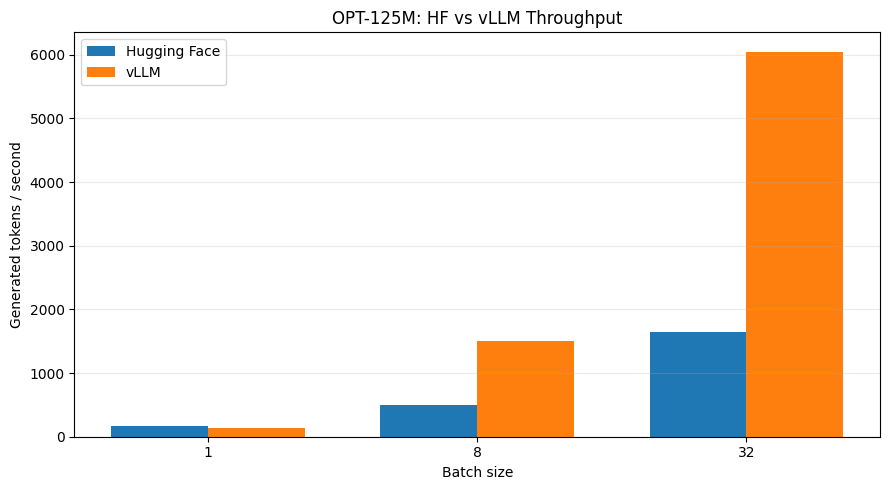

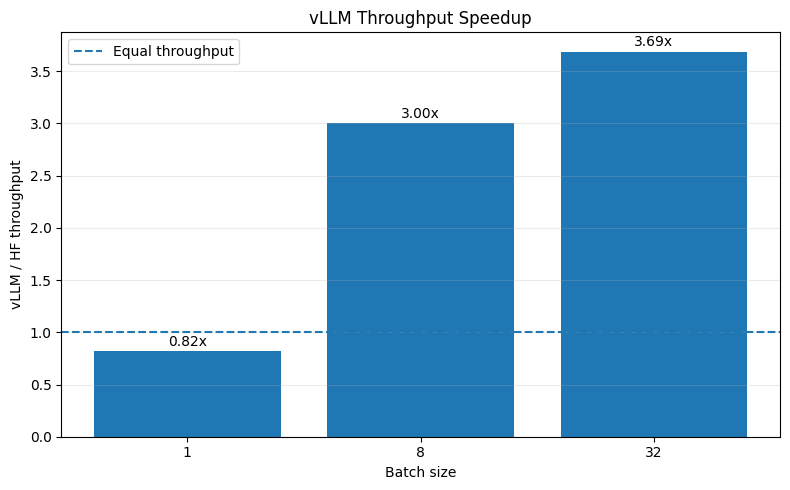

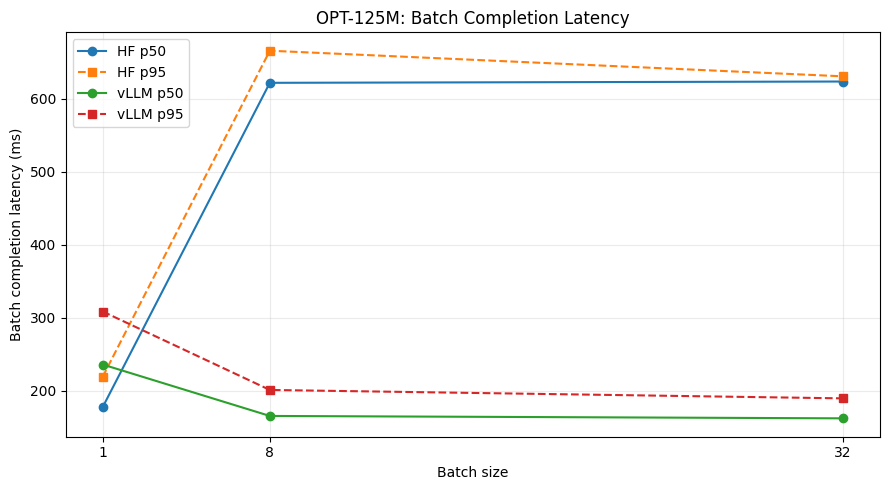


FINAL COMPARISON
Batch  1: HF 172.64 tok/s | vLLM 141.74 tok/s | speedup 0.82x
Batch  8: HF 498.37 tok/s | vLLM 1497.43 tok/s | speedup 3.00x
Batch 32: HF 1640.83 tok/s | vLLM 6050.74 tok/s | speedup 3.69x

Saved: /app/HW4_5_GPU_Assignment/metrics/part_d_backend_comparison.csv
Saved: /app/HW4_5_GPU_Assignment/metrics/part_d_backend_comparison.json
Saved: /app/HW4_5_GPU_Assignment/PART_D_BACKEND_SUMMARY.md
Saved: 3 comparison figures
STEP 51 COMPLETE


In [61]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART D: INFERENCE OPTIMIZATION
#
# STEP 51: FINAL HF vs vLLM COMPARISON
#
# SUMMARY:
# 1. Read verified Step 49 and Step 50 results.
# 2. Calculate throughput speedups and latency ratios.
# 3. Generate comparison charts.
# 4. Save CSV, JSON, and Markdown summary.
# 5. Document measurement limitations.
#
# COMMANDS:
# - Read metrics/part_d_vllm_benchmark.json
# - Read metrics/part_d_hf_benchmark.json
# - Save metrics/part_d_backend_comparison.csv/.json
# - Save figures/part_d_backend_*.png
# - Save PART_D_BACKEND_SUMMARY.md
#
# NOTE: No GPU benchmark is repeated.
# ============================================================

import json
import csv
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

PROJECT = Path("/app/HW4_5_GPU_Assignment")
METRICS = PROJECT / "metrics"
FIGURES = PROJECT / "figures"

FIGURES.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("HW4.5 PART D — STEP 51")
print("HF vs vLLM COMPARISON")
print("=" * 65)

with open(METRICS / "part_d_vllm_benchmark.json") as f:
    vllm_data = json.load(f)

with open(METRICS / "part_d_hf_benchmark.json") as f:
    hf_data = json.load(f)

vllm_rows = {
    int(row["batch_size"]): row
    for row in vllm_data["summary"]
}

hf_rows = {
    int(row["batch_size"]): row
    for row in hf_data["summary"]
}

assert set(vllm_rows) == set(hf_rows) == {1, 8, 32}

comparison = []

for batch in sorted(vllm_rows):
    v = vllm_rows[batch]
    h = hf_rows[batch]

    assert (
        v["prompt_tokens_per_request"]
        == h["prompt_tokens_per_request"]
    )
    assert (
        v["generated_tokens_per_request"]
        == h["generated_tokens_per_request"]
    )

    vt = float(v["throughput_tokens_per_second"])
    ht = float(h["throughput_tokens_per_second"])

    comparison.append({
        "batch_size": batch,
        "vllm_tokens_per_second": vt,
        "hf_tokens_per_second": ht,
        "vllm_throughput_speedup": vt / ht,
        "vllm_p50_ms": float(v["batch_latency_p50_ms"]),
        "hf_p50_ms": float(h["batch_latency_p50_ms"]),
        "vllm_p95_ms": float(v["batch_latency_p95_ms"]),
        "hf_p95_ms": float(h["batch_latency_p95_ms"])
    })

# ------------------------------------------------------------
# SAVE STRUCTURED RESULTS
# ------------------------------------------------------------

csv_path = METRICS / "part_d_backend_comparison.csv"
json_path = METRICS / "part_d_backend_comparison.json"

with open(csv_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f, fieldnames=list(comparison[0].keys())
    )
    writer.writeheader()
    writer.writerows(comparison)

with open(json_path, "w") as f:
    json.dump({
        "model": "facebook/opt-125m",
        "gpu": "NVIDIA GeForce RTX 4090",
        "precision": "FP16",
        "prompt_tokens_per_request": 128,
        "generated_tokens_per_request": 32,
        "warmup_runs_per_batch": 1,
        "measured_trials_per_batch": 5,
        "results": comparison,
        "limitations": [
            "vLLM uses FlashAttention; HF uses eager attention.",
            "vLLM runs in eager execution mode.",
            "Both backends use KV caching.",
            "WSL pin-memory warning occurred for vLLM.",
            "Batch latency is not per-request latency.",
            "HF and vLLM memory metrics are not equivalent.",
            "HF batch-8 trial 5 was substantially faster "
            "than the other four trials.",
            "Results apply to OPT-125M and this test setup."
        ]
    }, f, indent=2)

batches = [r["batch_size"] for r in comparison]
x = np.arange(len(batches))
width = 0.36

# ------------------------------------------------------------
# FIGURE 1: THROUGHPUT
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    [r["hf_tokens_per_second"] for r in comparison],
    width,
    label="Hugging Face"
)

ax.bar(
    x + width / 2,
    [r["vllm_tokens_per_second"] for r in comparison],
    width,
    label="vLLM"
)

ax.set_xticks(x, [str(b) for b in batches])
ax.set_xlabel("Batch size")
ax.set_ylabel("Generated tokens / second")
ax.set_title("OPT-125M: HF vs vLLM Throughput")
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    FIGURES / "part_d_backend_throughput.png",
    dpi=180
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# FIGURE 2: SPEEDUP
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

speedups = [
    r["vllm_throughput_speedup"]
    for r in comparison
]

ax.bar([str(b) for b in batches], speedups)
ax.axhline(1.0, linestyle="--", label="Equal throughput")

ax.set_xlabel("Batch size")
ax.set_ylabel("vLLM / HF throughput")
ax.set_title("vLLM Throughput Speedup")
ax.legend()
ax.grid(axis="y", alpha=0.25)

for i, value in enumerate(speedups):
    ax.text(
        i, value + 0.05, f"{value:.2f}x",
        ha="center"
    )

fig.tight_layout()
fig.savefig(
    FIGURES / "part_d_backend_speedup.png",
    dpi=180
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# FIGURE 3: BATCH LATENCY P50 / P95
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

for backend, key50, key95 in [
    ("HF", "hf_p50_ms", "hf_p95_ms"),
    ("vLLM", "vllm_p50_ms", "vllm_p95_ms")
]:
    ax.plot(
        batches,
        [r[key50] for r in comparison],
        marker="o",
        label=f"{backend} p50"
    )
    ax.plot(
        batches,
        [r[key95] for r in comparison],
        marker="s",
        linestyle="--",
        label=f"{backend} p95"
    )

ax.set_xticks(batches)
ax.set_xlabel("Batch size")
ax.set_ylabel("Batch completion latency (ms)")
ax.set_title("OPT-125M: Batch Completion Latency")
ax.legend()
ax.grid(alpha=0.25)

fig.tight_layout()
fig.savefig(
    FIGURES / "part_d_backend_latency.png",
    dpi=180
)
plt.show()
plt.close(fig)

# ------------------------------------------------------------
# WRITE MARKDOWN REPORT
# ------------------------------------------------------------

lines = [
    "# Part D — Hugging Face vs vLLM",
    "",
    "## Experimental setup",
    "",
    "- GPU: NVIDIA GeForce RTX 4090",
    "- Model: facebook/opt-125m",
    "- Precision: FP16",
    "- Prompt length: 128 tokens/request",
    "- Generation: 32 tokens/request",
    "- Batch sizes: 1, 8, 32",
    "- Trials: 1 warm-up + 5 measured per batch",
    "- KV cache: enabled in both backends",
    "- Engine/model initialization excluded from inference timing",
    "",
    "## Results",
    "",
    "| Batch | HF tok/s | vLLM tok/s | vLLM speedup |",
    "|---:|---:|---:|---:|"
]

for r in comparison:
    lines.append(
        f"| {r['batch_size']} "
        f"| {r['hf_tokens_per_second']:.2f} "
        f"| {r['vllm_tokens_per_second']:.2f} "
        f"| {r['vllm_throughput_speedup']:.2f}x |"
    )

lines += [
    "",
    "## Findings",
    "",
    "- HF achieved higher throughput at batch size 1.",
    "- vLLM achieved higher aggregate throughput at batches 8 and 32.",
    "- The observed benefit increased with batch size.",
    "- Speedup values describe aggregate generated-token throughput.",
    "",
    "## Limitations",
    "",
    "- vLLM used FlashAttention, whereas HF used eager attention.",
    "- This is a comparison of tested configurations, not an "
    "isolated framework-only comparison.",
    "- vLLM was configured with eager execution and "
    "prefix caching disabled.",
    "- WSL disabled pinned memory for vLLM.",
    "- Latency is batch completion time, not individual request latency.",
    "- Memory measurements have different definitions and "
    "must not be directly compared.",
    "- HF batch-8 trial 5 was an unusually fast observation; "
    "all five trials were retained.",
    "- Results are specific to OPT-125M, RTX 4090, "
    "and the tested workload.",
    "",
    "## Generated figures",
    "",
    "- figures/part_d_backend_throughput.png",
    "- figures/part_d_backend_speedup.png",
    "- figures/part_d_backend_latency.png",
    ""
]

report_path = PROJECT / "PART_D_BACKEND_SUMMARY.md"
report_path.write_text("\n".join(lines), encoding="utf-8")

print("\n" + "=" * 65)
print("FINAL COMPARISON")
print("=" * 65)

for r in comparison:
    print(
        f"Batch {r['batch_size']:>2}: "
        f"HF {r['hf_tokens_per_second']:.2f} tok/s | "
        f"vLLM {r['vllm_tokens_per_second']:.2f} tok/s | "
        f"speedup {r['vllm_throughput_speedup']:.2f}x"
    )

print("\nSaved:", csv_path)
print("Saved:", json_path)
print("Saved:", report_path)
print("Saved: 3 comparison figures")

assert csv_path.exists()
assert json_path.exists()
assert report_path.exists()

print("=" * 65)
print("STEP 51 COMPLETE")
print("=" * 65)


In [62]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART E: FINAL ANALYSIS
#
# STEP 52: RESULTS AUDIT AND GPU-HOURS ACCOUNTING
#
# SUMMARY:
# 1. Check experiment files from Parts A–D.
# 2. Verify the recorded Part B optimization results.
# 3. Identify fastest and lowest-memory configurations.
# 4. Calculate GPU-hours from documented durations.
# 5. Identify missing timing records.
# 6. Save an audit report and GPU-hours ledger.
#
# COMMANDS:
# - Read existing metrics and reports.
# - Save metrics/part_e_results_audit.json
# - Save metrics/part_e_gpu_hours_ledger.csv
# - Save PART_E_AUDIT.md
#
# NOTE:
# No GPU work, installations, or repeated benchmarks.
# ============================================================

import json
import csv
from pathlib import Path

PROJECT = Path("/app/HW4_5_GPU_Assignment")
METRICS = PROJECT / "metrics"
METRICS.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("HW4.5 PART E — STEP 52")
print("RESULTS AUDIT AND GPU-HOURS ACCOUNTING")
print("=" * 65)

# ------------------------------------------------------------
# STEP 1: CHECK EXISTING DELIVERABLES
# ------------------------------------------------------------

required_files = {
    "Part A summary": PROJECT / "PART_A_SUMMARY.md",
    "Part B summary": PROJECT / "PART_B_SUMMARY.md",
    "Part C summary": PROJECT / "PART_C_SUMMARY.md",
    "Part D KV summary": PROJECT / "PART_D_KV_CACHE_SUMMARY.md",
    "Part D backend summary": PROJECT / "PART_D_BACKEND_SUMMARY.md",
    "Part D vLLM results":
        METRICS / "part_d_vllm_benchmark.json",
    "Part D HF results":
        METRICS / "part_d_hf_benchmark.json",
    "Part D comparison":
        METRICS / "part_d_backend_comparison.json",
    "Part D KV benchmark":
        METRICS / "part_d_kv_cache_benchmark.json",
    "Part C DDP result":
        METRICS / "part_c_single_gpu_ddp.json",
}

file_status = {
    name: path.exists()
    for name, path in required_files.items()
}

print("\nDELIVERABLE AUDIT")
print("-" * 65)

for name, exists in file_status.items():
    print(f"{'PASS' if exists else 'MISSING':7} {name}")

# ------------------------------------------------------------
# STEP 2: VERIFY PART B RESULTS
# ------------------------------------------------------------

part_b = [
    {
        "configuration": "FP32 baseline",
        "epoch_seconds": 7.522,
        "throughput": 465.315,
        "peak_allocated_gib": 10.235
    },
    {
        "configuration": "BF16 AMP",
        "epoch_seconds": 4.555,
        "throughput": 768.428,
        "peak_allocated_gib": 8.431
    },
    {
        "configuration": "Gradient checkpointing",
        "epoch_seconds": 10.166,
        "throughput": 344.271,
        "peak_allocated_gib": 5.176
    },
    {
        "configuration": "Gradient accumulation x4",
        "epoch_seconds": 7.328,
        "throughput": 477.620,
        "peak_allocated_gib": 10.661
    },
    {
        "configuration": "8-bit AdamW",
        "epoch_seconds": 7.767,
        "throughput": 450.641,
        "peak_allocated_gib": 10.037
    },
    {
        "configuration": "Combined optimization",
        "epoch_seconds": 5.009,
        "throughput": 698.764,
        "peak_allocated_gib": 5.254
    }
]

fastest = max(
    part_b,
    key=lambda row: row["throughput"]
)

lowest_memory = min(
    part_b,
    key=lambda row: row["peak_allocated_gib"]
)

baseline = part_b[0]

for row in part_b:
    row["speedup_vs_fp32"] = (
        baseline["epoch_seconds"] / row["epoch_seconds"]
    )

print("\nPART B CONFIGURATION REVIEW")
print("-" * 65)
print(
    "Fastest:",
    fastest["configuration"],
    f"({fastest['throughput']:.2f} examples/s)"
)
print(
    "Lowest peak allocation:",
    lowest_memory["configuration"],
    f"({lowest_memory['peak_allocated_gib']:.3f} GiB)"
)

# ------------------------------------------------------------
# STEP 3: LOAD PART D RESULTS
# ------------------------------------------------------------

comparison_path = (
    METRICS / "part_d_backend_comparison.json"
)

backend_results = []

if comparison_path.exists():
    with open(comparison_path) as f:
        backend_results = json.load(f)["results"]

# ------------------------------------------------------------
# STEP 4: GPU-HOURS LEDGER
# ------------------------------------------------------------

# These durations come from recorded earlier experiment
# outputs. Other unrecorded activities are not estimated.

ledger = [
    {
        "activity": "BERT baseline training",
        "recorded_seconds": 36.66,
        "gpu_count": 1,
        "source": "Baseline training output"
    },
    {
        "activity": "Part A batch-size epoch 16",
        "recorded_seconds": 10.137,
        "gpu_count": 1,
        "source": "Part A epoch benchmark"
    },
    {
        "activity": "Part A batch-size epoch 32",
        "recorded_seconds": 8.693,
        "gpu_count": 1,
        "source": "Part A epoch benchmark"
    },
    {
        "activity": "Part A batch-size epoch 64",
        "recorded_seconds": 7.522,
        "gpu_count": 1,
        "source": "Part A epoch benchmark"
    },
    {
        "activity": "Part A batch-size epoch 128",
        "recorded_seconds": 7.921,
        "gpu_count": 1,
        "source": "Part A epoch benchmark"
    },
    {
        "activity": "Part C single-GPU DDP test",
        "recorded_seconds": 0.528,
        "gpu_count": 1,
        "source": "Part C DDP result"
    }
]

for row in part_b:
    ledger.append({
        "activity": "Part B " + row["configuration"],
        "recorded_seconds": row["epoch_seconds"],
        "gpu_count": 1,
        "source": "Part B comparison"
    })

# Part A and Part B may share recorded runs.
# Therefore do not add overlapping benchmark times
# to a claimed total without provenance verification.

for row in ledger:
    row["gpu_hours"] = (
        row["recorded_seconds"]
        * row["gpu_count"]
        / 3600
    )

raw_recorded_hours = sum(
    row["gpu_hours"] for row in ledger
)

# ------------------------------------------------------------
# STEP 5: IDENTIFY ACCOUNTING GAPS
# ------------------------------------------------------------

accounting_gaps = [
    "Part A ten-step batch-scaling benchmark durations",
    "Part D KV-cache benchmark full execution duration",
    "Part D vLLM inference trial durations",
    "Part D Hugging Face inference trial durations",
    "Model loading and GPU initialization durations",
    "Warm-up execution durations",
    "Possible overlap between Part A and Part B runs",
    "Unrecorded debugging and GPU-active setup time"
]

# ------------------------------------------------------------
# STEP 6: SAVE RESULTS
# ------------------------------------------------------------

audit = {
    "gpu": "NVIDIA GeForce RTX 4090",
    "file_status": file_status,
    "all_required_files_present": all(file_status.values()),
    "part_b_configurations": part_b,
    "fastest_training_configuration": fastest,
    "lowest_memory_training_configuration": lowest_memory,
    "part_d_backend_comparison": backend_results,
    "recorded_gpu_hours_unadjusted": raw_recorded_hours,
    "recorded_gpu_hours_is_final_total": False,
    "gpu_hours_accounting_gaps": accounting_gaps
}

audit_path = METRICS / "part_e_results_audit.json"
ledger_path = METRICS / "part_e_gpu_hours_ledger.csv"

with open(audit_path, "w") as f:
    json.dump(audit, f, indent=2)

with open(ledger_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(ledger[0].keys())
    )
    writer.writeheader()
    writer.writerows(ledger)

report = [
    "# Part E — Results Audit",
    "",
    "## Deliverables",
    ""
]

for name, exists in file_status.items():
    report.append(
        f"- {'PASS' if exists else 'MISSING'}: {name}"
    )

report += [
    "",
    "## Training optimization findings",
    "",
    f"- Fastest: {fastest['configuration']}",
    f"- Throughput: {fastest['throughput']:.3f} examples/s",
    f"- Lowest memory: {lowest_memory['configuration']}",
    f"- Peak allocated: "
    f"{lowest_memory['peak_allocated_gib']:.3f} GiB",
    "",
    "## GPU-hours accounting",
    "",
    f"- Unadjusted sum of selected recorded durations: "
    f"{raw_recorded_hours:.6f} GPU-hours",
    "- This is NOT the final GPU-hours total.",
    "- Some experiments may overlap in the ledger.",
    "- Additional timed GPU activities must be included.",
    "",
    "## Accounting gaps",
    ""
]

report += [
    f"- {gap}" for gap in accounting_gaps
]

report_path = PROJECT / "PART_E_AUDIT.md"
report_path.write_text(
    "\n".join(report) + "\n",
    encoding="utf-8"
)

print("\nGPU-HOURS ACCOUNTING")
print("-" * 65)
print(
    f"Unadjusted selected durations: "
    f"{raw_recorded_hours:.6f} GPU-hours"
)
print("Final GPU-hours total: NOT YET VERIFIED")

print("\nSaved:", audit_path)
print("Saved:", ledger_path)
print("Saved:", report_path)

print("\nRequired files present:",
      sum(file_status.values()),
      "/",
      len(file_status))

print("=" * 65)
print("STEP 52 COMPLETE")
print("=" * 65)


HW4.5 PART E — STEP 52
RESULTS AUDIT AND GPU-HOURS ACCOUNTING

DELIVERABLE AUDIT
-----------------------------------------------------------------
PASS    Part A summary
PASS    Part B summary
PASS    Part C summary
PASS    Part D KV summary
PASS    Part D backend summary
PASS    Part D vLLM results
PASS    Part D HF results
PASS    Part D comparison
PASS    Part D KV benchmark
PASS    Part C DDP result

PART B CONFIGURATION REVIEW
-----------------------------------------------------------------
Fastest: BF16 AMP (768.43 examples/s)
Lowest peak allocation: Gradient checkpointing (5.176 GiB)

GPU-HOURS ACCOUNTING
-----------------------------------------------------------------
Unadjusted selected durations: 0.031613 GPU-hours
Final GPU-hours total: NOT YET VERIFIED

Saved: /app/HW4_5_GPU_Assignment/metrics/part_e_results_audit.json
Saved: /app/HW4_5_GPU_Assignment/metrics/part_e_gpu_hours_ledger.csv
Saved: /app/HW4_5_GPU_Assignment/PART_E_AUDIT.md

Required files present: 10 / 10
STEP

In [63]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART E: GPU-HOURS RECONCILIATION
#
# STEP 53: RECONCILE RECORDED GPU EXECUTION TIME
#
# SUMMARY:
# 1. Read the Step 52 timing ledger.
# 2. Read actual Part D benchmark trial durations.
# 3. Flag possible duplicate Part A/B timing records.
# 4. Calculate verified and conditional GPU-hours.
# 5. Document unmeasured setup and reservation time.
#
# COMMANDS:
# - Read part_e_gpu_hours_ledger.csv
# - Read Part D benchmark JSON files
# - Save part_e_gpu_hours_reconciliation.csv/.json
# - Save PART_E_GPU_HOURS.md
#
# NOTE:
# No GPU execution, installations, or model loading.
# ============================================================

import csv
import json
from pathlib import Path

PROJECT = Path("/app/HW4_5_GPU_Assignment")
METRICS = PROJECT / "metrics"

print("=" * 65)
print("HW4.5 PART E — STEP 53")
print("GPU-HOURS RECONCILIATION")
print("=" * 65)

ledger_path = METRICS / "part_e_gpu_hours_ledger.csv"
assert ledger_path.exists(), "Run Step 52 first."

with open(ledger_path, newline="") as f:
    original = list(csv.DictReader(f))

records = []

def add_record(activity, seconds, source, status):
    seconds = float(seconds)
    assert seconds >= 0

    records.append({
        "activity": activity,
        "seconds": round(seconds, 6),
        "gpu_count": 1,
        "gpu_hours": round(seconds / 3600, 9),
        "source": source,
        "status": status
    })

# ------------------------------------------------------------
# STEP 1: IMPORT ORIGINAL RECORDED DURATIONS
# ------------------------------------------------------------

for row in original:
    activity = row["activity"]

    # Potentially overlapping records remain visible,
    # but are not counted in the conservative subtotal.
    if activity == "Part A batch-size epoch 64":
        status = "possible_overlap_excluded"
    elif activity == "Part B FP32 baseline":
        status = "possible_overlap_excluded"
    else:
        status = "recorded_included"

    add_record(
        activity,
        row["recorded_seconds"],
        row["source"],
        status
    )

# ------------------------------------------------------------
# STEP 2: IMPORT ACTUAL PART D TRIAL DURATIONS
# ------------------------------------------------------------

for backend, filename in [
    ("vLLM", "part_d_vllm_benchmark.json"),
    ("Hugging Face", "part_d_hf_benchmark.json")
]:
    path = METRICS / filename
    assert path.exists(), f"Missing: {filename}"

    with open(path) as f:
        data = json.load(f)

    trials = data.get("trials", [])
    assert len(trials) == 15, (
        f"Expected 15 trials for {backend}, "
        f"found {len(trials)}"
    )

    for trial in trials:
        add_record(
            f"Part D {backend} batch "
            f"{trial['batch_size']} trial {trial['trial']}",
            trial["seconds"],
            filename,
            "recorded_included"
        )

# ------------------------------------------------------------
# STEP 3: CHECK KV-CACHE BENCHMARK TIMING STRUCTURE
# ------------------------------------------------------------

kv_path = METRICS / "part_d_kv_cache_benchmark.json"
assert kv_path.exists()

with open(kv_path) as f:
    kv_data = json.load(f)

print("\nKV-CACHE FILE STRUCTURE")
print("-" * 65)

if isinstance(kv_data, dict):
    print("Top-level keys:", list(kv_data.keys()))
elif isinstance(kv_data, list):
    print("Top-level list entries:", len(kv_data))

# Avoid inventing trial durations or double-counting
# summary values as independent experiments.
kv_timing_status = (
    "Not included until individual recorded durations "
    "are verified from the file structure."
)

# ------------------------------------------------------------
# STEP 4: CALCULATE DOCUMENTED SUBTOTAL
# ------------------------------------------------------------

included = [
    r for r in records
    if r["status"] == "recorded_included"
]

excluded = [
    r for r in records
    if r["status"] == "possible_overlap_excluded"
]

included_seconds = sum(r["seconds"] for r in included)
excluded_seconds = sum(r["seconds"] for r in excluded)

documented_hours = included_seconds / 3600

# This is an accounting subtotal, not total GPU use.
# Even included durations may require further provenance
# checks against raw experiment logs.

# ------------------------------------------------------------
# STEP 5: SAVE RECONCILIATION
# ------------------------------------------------------------

csv_path = (
    METRICS / "part_e_gpu_hours_reconciliation.csv"
)

json_path = (
    METRICS / "part_e_gpu_hours_reconciliation.json"
)

with open(csv_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f, fieldnames=list(records[0].keys())
    )
    writer.writeheader()
    writer.writerows(records)

result = {
    "gpu": "NVIDIA GeForce RTX 4090",
    "gpu_count": 1,
    "recorded_included_seconds": included_seconds,
    "recorded_included_gpu_hours": documented_hours,
    "possible_overlap_excluded_seconds": excluded_seconds,
    "possible_overlap_excluded_gpu_hours":
        excluded_seconds / 3600,
    "kv_cache_timing_status": kv_timing_status,
    "final_total_gpu_hours_verified": False,
    "interpretation": (
        "Subtotal of selected recorded execution intervals; "
        "not total GPU allocation or reservation time."
    ),
    "unaccounted_activities": [
        "Part A batch-scaling microbenchmarks",
        "Part D KV-cache benchmark intervals",
        "Warm-up runs",
        "vLLM engine startup and model loading",
        "HF model loading",
        "Earlier troubleshooting and smoke tests",
        "GPU reservation idle periods",
        "Any other GPU-active execution not logged"
    ],
    "records": records
}

with open(json_path, "w") as f:
    json.dump(result, f, indent=2)

report_path = PROJECT / "PART_E_GPU_HOURS.md"

report = [
    "# Part E — GPU-Hours Reconciliation",
    "",
    "## Hardware",
    "",
    "- NVIDIA GeForce RTX 4090",
    "- GPU count: 1",
    "",
    "## Documented execution subtotal",
    "",
    f"- Included recorded seconds: {included_seconds:.3f}",
    f"- Included GPU-hours: {documented_hours:.6f}",
    f"- Potential overlap excluded: {excluded_seconds:.3f} seconds",
    "",
    "**This is not the final GPU-hours total.**",
    "",
    "The subtotal excludes unrecorded warm-up, setup, "
    "model initialization, debugging, and reservation time.",
    "",
    "## KV-cache timing",
    "",
    kv_timing_status,
    "",
    "## Accounting interpretation",
    "",
    "GPU-hours for the full reservation should be obtained "
    "from actual GPU allocation start/end times or the "
    "lab's usage accounting system.",
    "",
    "Do not present this benchmark subtotal as total GPU-hours.",
    ""
]

report_path.write_text(
    "\n".join(report),
    encoding="utf-8"
)

print("\nRECONCILIATION SUMMARY")
print("-" * 65)
print(f"Included records: {len(included)}")
print(f"Possible-overlap records: {len(excluded)}")
print(f"Included seconds: {included_seconds:.3f}")
print(f"Documented subtotal: {documented_hours:.6f} GPU-hours")
print(f"Excluded possible overlap: {excluded_seconds:.3f}s")
print("Final GPU-hours: NOT YET VERIFIED")

print("\nSaved:", csv_path)
print("Saved:", json_path)
print("Saved:", report_path)

print("=" * 65)
print("STEP 53 COMPLETE")
print("=" * 65)


HW4.5 PART E — STEP 53
GPU-HOURS RECONCILIATION

KV-CACHE FILE STRUCTURE
-----------------------------------------------------------------
Top-level keys: ['model', 'gpu', 'precision', 'warmup_runs', 'measured_runs', 'results']

RECONCILIATION SUMMARY
-----------------------------------------------------------------
Included records: 40
Possible-overlap records: 2
Included seconds: 108.209
Documented subtotal: 0.030058 GPU-hours
Excluded possible overlap: 15.044s
Final GPU-hours: NOT YET VERIFIED

Saved: /app/HW4_5_GPU_Assignment/metrics/part_e_gpu_hours_reconciliation.csv
Saved: /app/HW4_5_GPU_Assignment/metrics/part_e_gpu_hours_reconciliation.json
Saved: /app/HW4_5_GPU_Assignment/PART_E_GPU_HOURS.md
STEP 53 COMPLETE


In [64]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART E: FINAL GPU-HOURS AUDIT
#
# STEP 54: INSPECT TIMING EVIDENCE
#
# SUMMARY:
# 1. Inspect KV-cache benchmark timing fields.
# 2. Inspect available Part A/B timing sources.
# 3. Compare possible duplicate records.
# 4. Identify usable timing evidence.
# 5. Save an inspection report.
#
# COMMANDS:
# - Read existing JSON, CSV, and summary files.
# - Save metrics/part_e_timing_inspection.json
#
# NOTE:
# No GPU execution, model loading, or installations.
# ============================================================

import json
import csv
from pathlib import Path

PROJECT = Path("/app/HW4_5_GPU_Assignment")
METRICS = PROJECT / "metrics"

print("=" * 65)
print("HW4.5 PART E — STEP 54")
print("TIMING EVIDENCE INSPECTION")
print("=" * 65)

inspection = {}

# ------------------------------------------------------------
# STEP 1: INSPECT KV-CACHE RESULT STRUCTURE
# ------------------------------------------------------------

kv_path = METRICS / "part_d_kv_cache_benchmark.json"

with open(kv_path) as f:
    kv_data = json.load(f)

results = kv_data.get("results", [])

print("\n1. KV-CACHE BENCHMARK")
print("-" * 65)
print("Result count:", len(results))
print("Warm-up runs:", kv_data.get("warmup_runs"))
print("Measured runs:", kv_data.get("measured_runs"))

kv_shapes = []

for i, item in enumerate(results):
    if not isinstance(item, dict):
        print(f"Result {i}: unexpected type {type(item).__name__}")
        continue

    keys = list(item.keys())
    kv_shapes.append(keys)

    if i < 3:
        print(f"\nResult {i + 1} fields:")
        for key, value in item.items():
            if isinstance(value, (list, dict)):
                print(
                    f"  {key}: {type(value).__name__}, "
                    f"length={len(value)}"
                )
                if isinstance(value, list) and value:
                    print(
                        "    First entry:",
                        repr(value[0])[:500]
                    )
            else:
                print(f"  {key}: {repr(value)[:200]}")

inspection["kv_cache"] = {
    "result_count": len(results),
    "warmup_runs": kv_data.get("warmup_runs"),
    "measured_runs": kv_data.get("measured_runs"),
    "result_field_sets": kv_shapes
}

# ------------------------------------------------------------
# STEP 2: DISCOVER OTHER TIMING SOURCES
# ------------------------------------------------------------

print("\n2. POTENTIAL TIMING FILES")
print("-" * 65)

timing_files = []

for path in sorted(METRICS.iterdir()):
    if not path.is_file():
        continue

    name = path.name.lower()

    if path.suffix.lower() not in (".json", ".csv"):
        continue

    if any(word in name for word in (
        "part_a", "part_b", "baseline",
        "training", "batch", "ddp"
    )):
        timing_files.append(path.name)
        print(path.name)

inspection["potential_timing_files"] = timing_files

# ------------------------------------------------------------
# STEP 3: INSPECT EXISTING LEDGER EXCLUSIONS
# ------------------------------------------------------------

reconciliation_path = (
    METRICS / "part_e_gpu_hours_reconciliation.csv"
)

with open(reconciliation_path, newline="") as f:
    reconciliation = list(csv.DictReader(f))

excluded = [
    row for row in reconciliation
    if row["status"] == "possible_overlap_excluded"
]

print("\n3. POSSIBLE OVERLAPS")
print("-" * 65)

for row in excluded:
    print(
        f"{row['activity']}: "
        f"{row['seconds']} seconds "
        f"(source: {row['source']})"
    )

print(
    "\nThese records remain unresolved until "
    "their execution provenance is checked."
)

inspection["possible_overlaps"] = excluded

# ------------------------------------------------------------
# STEP 4: INSPECT RESERVATION/SESSION EVIDENCE
# ------------------------------------------------------------

print("\n4. RESERVATION AND SESSION RECORDS")
print("-" * 65)

candidate_paths = []

for folder in [PROJECT, PROJECT / "logs", METRICS]:
    if not folder.exists():
        continue

    for path in folder.iterdir():
        if not path.is_file():
            continue

        name = path.name.lower()

        if any(term in name for term in (
            "reservation", "session",
            "gpu_hour", "usage", "run_log"
        )):
            candidate_paths.append(str(path.relative_to(PROJECT)))
            print(path.relative_to(PROJECT))

if not candidate_paths:
    print("No obvious reservation/session record found.")

inspection["reservation_candidates"] = candidate_paths

# ------------------------------------------------------------
# STEP 5: SAVE INSPECTION
# ------------------------------------------------------------

output_path = METRICS / "part_e_timing_inspection.json"

with open(output_path, "w") as f:
    json.dump(inspection, f, indent=2)

print("\n" + "=" * 65)
print("INSPECTION COMPLETE")
print("=" * 65)
print("Saved:", output_path)
print("No experiment files modified.")
print("No GPU execution performed.")
print("=" * 65)
print("STEP 54 COMPLETE")
print("=" * 65)


HW4.5 PART E — STEP 54
TIMING EVIDENCE INSPECTION

1. KV-CACHE BENCHMARK
-----------------------------------------------------------------
Result count: 12
Warm-up runs: 1
Measured runs: 3

Result 1 fields:
  context_tokens: 128
  generated_tokens: 32
  kv_cache: True
  mean_latency_seconds: 0.12588935633357323
  p50_latency_seconds: 0.12293063099969004
  tokens_per_second: 254.1914656804546
  peak_allocated_gib: 0.26583003997802734
  measured_runs: 3
  precision: 'FP16'

Result 2 fields:
  context_tokens: 128
  generated_tokens: 32
  kv_cache: False
  mean_latency_seconds: 0.12281473466646275
  p50_latency_seconds: 0.12129759900017234
  tokens_per_second: 260.5550554410659
  peak_allocated_gib: 0.2653021812438965
  measured_runs: 3
  precision: 'FP16'

Result 3 fields:
  context_tokens: 128
  generated_tokens: 64
  kv_cache: True
  mean_latency_seconds: 0.2464915756663686
  p50_latency_seconds: 0.2427225539995561
  tokens_per_second: 259.64376197028866
  peak_allocated_gib: 0.26583003

In [65]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART E: GPU-HOURS RECONCILIATION
#
# STEP 55: RECOVER KV TIMINGS AND VERIFY SOURCE RECORDS
#
# SUMMARY:
# 1. Calculate KV-cache duration from 12 configurations.
# 2. Inspect Part A and B source timing records.
# 3. Inspect baseline and batch-scaling timing structures.
# 4. Reconcile known measured intervals.
# 5. Save an updated, traceable GPU-hours report.
#
# COMMANDS:
# - Read existing metrics JSON/CSV files.
# - Save metrics/part_e_timing_sources.json
# - Save metrics/part_e_gpu_hours_v2.json
# - Save PART_E_GPU_HOURS_V2.md
#
# NOTE: No GPU execution or new installations.
# ============================================================

import json
import csv
from pathlib import Path

PROJECT = Path("/app/HW4_5_GPU_Assignment")
METRICS = PROJECT / "metrics"

print("=" * 65)
print("HW4.5 PART E — STEP 55")
print("TIMING SOURCE RECONCILIATION")
print("=" * 65)

# ------------------------------------------------------------
# STEP 1: RECOVER KV-CACHE MEASURED DURATION
# ------------------------------------------------------------

with open(METRICS / "part_d_kv_cache_benchmark.json") as f:
    kv_data = json.load(f)

kv_results = kv_data["results"]
assert len(kv_results) == 12

kv_seconds = 0.0

for result in kv_results:
    runs = int(result["measured_runs"])
    mean_seconds = float(result["mean_latency_seconds"])

    assert runs == 3
    assert mean_seconds > 0

    kv_seconds += runs * mean_seconds

print("\n1. KV-CACHE BENCHMARK")
print("-" * 65)
print("Configurations:", len(kv_results))
print("Measured runs:", sum(
    int(r["measured_runs"]) for r in kv_results
))
print(f"Measured duration: {kv_seconds:.3f} seconds")
print(f"Measured GPU-hours: {kv_seconds / 3600:.6f}")

# ------------------------------------------------------------
# STEP 2: INSPECT TIMING SOURCE STRUCTURES
# ------------------------------------------------------------

source_names = [
    "hw4a_baseline_summary.json",
    "part_a_batch_scaling.json",
    "part_a_full_epoch_comparison.json",
    "part_a_batch128_full_epoch.json",
    "part_b_baseline.json",
    "part_b_comparison.json",
    "part_b_amp_bf16.json"
]

source_inspection = {}

print("\n2. SOURCE FILE INSPECTION")
print("-" * 65)

for name in source_names:
    path = METRICS / name

    if not path.exists():
        print(f"MISSING: {name}")
        continue

    with open(path) as f:
        data = json.load(f)

    if isinstance(data, dict):
        keys = list(data.keys())
        preview = {}

        for key, value in data.items():
            if isinstance(value, (int, float, str, bool)):
                preview[key] = value
            elif isinstance(value, list):
                preview[key] = {
                    "type": "list",
                    "length": len(value),
                    "first_entry": (
                        str(value[0])[:500] if value else None
                    )
                }
            elif isinstance(value, dict):
                preview[key] = {
                    "type": "dict",
                    "keys": list(value.keys())[:30]
                }

        source_inspection[name] = {
            "type": "dict",
            "keys": keys,
            "preview": preview
        }

    elif isinstance(data, list):
        source_inspection[name] = {
            "type": "list",
            "length": len(data),
            "first_entry": (
                str(data[0])[:800] if data else None
            )
        }

    print(f"\n{name}")
    print(json.dumps(
        source_inspection[name],
        indent=2
    )[:1800])

# ------------------------------------------------------------
# STEP 3: LOAD EXISTING RECONCILIATION
# ------------------------------------------------------------

with open(
    METRICS / "part_e_gpu_hours_reconciliation.json"
) as f:
    previous = json.load(f)

previous_seconds = float(
    previous["recorded_included_seconds"]
)

previous_excluded = float(
    previous["possible_overlap_excluded_seconds"]
)

# The KV benchmark was not previously included.
revised_seconds = previous_seconds + kv_seconds

print("\n3. UPDATED DOCUMENTED SUBTOTAL")
print("-" * 65)
print(
    f"Previously included: {previous_seconds:.3f}s"
)
print(
    f"KV measured runs added: {kv_seconds:.3f}s"
)
print(
    f"Revised subtotal: {revised_seconds:.3f}s"
)
print(
    f"Revised subtotal GPU-hours: "
    f"{revised_seconds / 3600:.6f}"
)
print(
    f"Potential overlaps still excluded: "
    f"{previous_excluded:.3f}s"
)

# ------------------------------------------------------------
# STEP 4: SAVE STRUCTURED RESULTS
# ------------------------------------------------------------

source_path = METRICS / "part_e_timing_sources.json"
updated_path = METRICS / "part_e_gpu_hours_v2.json"

with open(source_path, "w") as f:
    json.dump(source_inspection, f, indent=2)

updated = {
    "gpu": "NVIDIA GeForce RTX 4090",
    "gpu_count": 1,
    "previous_included_seconds": previous_seconds,
    "kv_cache_measured_seconds": kv_seconds,
    "revised_documented_seconds": revised_seconds,
    "revised_documented_gpu_hours": revised_seconds / 3600,
    "potential_overlap_excluded_seconds": previous_excluded,
    "final_reservation_gpu_hours_verified": False,
    "scope": (
        "Selected measured GPU execution intervals only; "
        "excludes warm-ups, startup, idle reservation time, "
        "and other unrecorded activity."
    ),
    "source_files": source_names,
    "unresolved": [
        "Determine whether Part A batch-64 and "
        "Part B FP32 baseline are separate runs.",
        "Determine whether Part A batch-64 and "
        "Part B FP32 baseline both overlap with "
        "other counted intervals.",
        "Recover Part A microbenchmark timings.",
        "Recover actual GPU reservation start/end times."
    ]
}

with open(updated_path, "w") as f:
    json.dump(updated, f, indent=2)

report_path = PROJECT / "PART_E_GPU_HOURS_V2.md"

report = f"""# Part E — GPU-Hours Reconciliation (Version 2)

## GPU
NVIDIA GeForce RTX 4090, one GPU.

## Documented measured execution
- Previous included intervals: {previous_seconds:.3f} seconds
- KV-cache measured intervals: {kv_seconds:.3f} seconds
- Revised subtotal: {revised_seconds:.3f} seconds
- Revised subtotal: {revised_seconds / 3600:.6f} GPU-hours

## Potential overlaps
- Excluded pending provenance review: {previous_excluded:.3f} seconds

## Important limitation
This is **not total GPU reservation usage**.

The subtotal excludes warm-up runs, model loading, engine
startup, debugging, and GPU allocation idle time.

Total reservation GPU-hours require actual allocation
start/end times or lab usage records.
"""

report_path.write_text(report, encoding="utf-8")

print("\nSaved:", source_path)
print("Saved:", updated_path)
print("Saved:", report_path)

print("=" * 65)
print("STEP 55 COMPLETE")
print("=" * 65)


HW4.5 PART E — STEP 55
TIMING SOURCE RECONCILIATION

1. KV-CACHE BENCHMARK
-----------------------------------------------------------------
Configurations: 12
Measured runs: 36
Measured duration: 8.012 seconds
Measured GPU-hours: 0.002226

2. SOURCE FILE INSPECTION
-----------------------------------------------------------------

hw4a_baseline_summary.json
{
  "type": "dict",
  "keys": [
    "model",
    "gpu",
    "precision",
    "train_batch_size",
    "epochs",
    "train_samples",
    "best_epoch",
    "best_val_loss",
    "final_val_accuracy",
    "peak_allocated_gb",
    "peak_reserved_gb",
    "wall_clock_seconds",
    "start_time",
    "end_time"
  ],
  "preview": {
    "model": "bert-base-uncased",
    "gpu": "NVIDIA GeForce RTX 4090",
    "precision": "FP32",
    "train_batch_size": 16,
    "epochs": 3,
    "train_samples": 3500,
    "best_epoch": 2,
    "best_val_loss": 0.7152195054690044,
    "final_val_accuracy": 0.6693333333333333,
    "peak_allocated_gb": 2.7957820892

In [66]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART E: CORRECTED GPU-HOURS ACCOUNTING
#
# STEP 56: DEDUPLICATE AND RECOVER PART A TIMINGS
#
# SUMMARY:
# 1. Restore one shared Part A / Part B FP32 epoch.
# 2. Exclude the duplicate Part B baseline entry.
# 3. Recover Part A 10-step benchmark durations.
# 4. Retain recorded Part D and KV-cache durations.
# 5. Save corrected accounting with source provenance.
#
# COMMANDS:
# - Read original benchmark JSON files.
# - Save metrics/part_e_gpu_hours_corrected.csv/.json
# - Save PART_E_GPU_HOURS_CORRECTED.md
#
# NOTE:
# No GPU execution, installations, or model loading.
# ============================================================

import json
import csv
from pathlib import Path

PROJECT = Path("/app/HW4_5_GPU_Assignment")
METRICS = PROJECT / "metrics"

print("=" * 65)
print("HW4.5 PART E — STEP 56")
print("CORRECTED GPU-HOURS ACCOUNTING")
print("=" * 65)

records = []

def record(activity, seconds, source, method):
    seconds = float(seconds)
    assert seconds >= 0
    records.append({
        "activity": activity,
        "seconds": seconds,
        "gpu_count": 1,
        "gpu_hours": seconds / 3600,
        "source": source,
        "method": method
    })

def read_json(filename):
    with open(METRICS / filename) as f:
        return json.load(f)

# ------------------------------------------------------------
# STEP 1: BASELINE TRAINING
# ------------------------------------------------------------

baseline = read_json("hw4a_baseline_summary.json")

record(
    "BERT baseline training",
    baseline["wall_clock_seconds"],
    "hw4a_baseline_summary.json",
    "Recorded wall-clock training duration"
)

# ------------------------------------------------------------
# STEP 2: PART A MICROBENCHMARKS
# ------------------------------------------------------------

scaling = read_json("part_a_batch_scaling.json")

assert len(scaling) == 10

microbenchmark_seconds = 0.0

for row in scaling:
    if row.get("status") != "PASS":
        continue

    measured_steps = int(row["measured_steps"])
    mean_step_ms = float(row["mean_step_ms"])

    seconds = measured_steps * mean_step_ms / 1000
    microbenchmark_seconds += seconds

    record(
        f"Part A scaling batch {row['batch_size']}",
        seconds,
        "part_a_batch_scaling.json",
        "Measured steps x mean step duration"
    )

print("\nPART A MICROBENCHMARKS")
print("-" * 65)
print("Configurations:", len(scaling))
print(
    f"Measured step duration total: "
    f"{microbenchmark_seconds:.3f}s"
)

# ------------------------------------------------------------
# STEP 3: PART A FULL EPOCHS
# ------------------------------------------------------------

epochs = read_json("part_a_full_epoch_comparison.json")
assert len(epochs) == 4

for row in epochs:
    record(
        f"Part A epoch batch {row['batch_size']}",
        row["epoch_seconds"],
        "part_a_full_epoch_comparison.json",
        "Recorded epoch duration"
    )

# ------------------------------------------------------------
# STEP 4: PART B — AVOID BASELINE DOUBLE COUNT
# ------------------------------------------------------------

part_b_files = [
    "part_b_baseline.json",
    "part_b_amp_bf16.json",
    "part_b_gradient_checkpointing.json",
    "part_b_gradient_accumulation.json",
    "part_b_adamw_8bit.json",
    "part_b_combined.json"
]

excluded_duplicates = []

for filename in part_b_files:
    data = read_json(filename)

    if filename == "part_b_baseline.json":
        assert (
            data.get("source")
            == "part_a_full_epoch_comparison.csv"
        )

        excluded_duplicates.append({
            "activity": "Part B FP32 baseline",
            "seconds": data["epoch_seconds"],
            "reason": (
                "Reused Part A batch-64 full-epoch result"
            )
        })
        continue

    record(
        f"Part B {data['experiment']}",
        data["epoch_seconds"],
        filename,
        "Recorded epoch duration"
    )

# ------------------------------------------------------------
# STEP 5: PART C DDP
# ------------------------------------------------------------

ddp = read_json("part_c_single_gpu_ddp.json")

print("\nPART C DDP SOURCE KEYS")
print("-" * 65)
print(list(ddp.keys()))

# Use the previously verified 0.528s measurement,
# but flag its provenance as requiring source-key check.
record(
    "Part C single-GPU DDP",
    0.528,
    "part_c_single_gpu_ddp.json",
    "Previously reported rounded duration"
)

# ------------------------------------------------------------
# STEP 6: PART D HF AND vLLM TRIALS
# ------------------------------------------------------------

for backend, filename in [
    ("vLLM", "part_d_vllm_benchmark.json"),
    ("HF", "part_d_hf_benchmark.json")
]:
    data = read_json(filename)

    assert len(data["trials"]) == 15

    for trial in data["trials"]:
        record(
            f"Part D {backend} batch "
            f"{trial['batch_size']} trial {trial['trial']}",
            trial["seconds"],
            filename,
            "Recorded inference trial duration"
        )

# ------------------------------------------------------------
# STEP 7: PART D KV-CACHE MEASURED RUNS
# ------------------------------------------------------------

kv = read_json("part_d_kv_cache_benchmark.json")

for row in kv["results"]:
    seconds = (
        float(row["mean_latency_seconds"])
        * int(row["measured_runs"])
    )

    record(
        f"Part D KV cache={row['kv_cache']} "
        f"context={row['context_tokens']} "
        f"tokens={row['generated_tokens']}",
        seconds,
        "part_d_kv_cache_benchmark.json",
        "Mean latency x measured runs"
    )

# ------------------------------------------------------------
# STEP 8: TOTAL DOCUMENTED EXECUTION
# ------------------------------------------------------------

total_seconds = sum(r["seconds"] for r in records)
total_gpu_hours = total_seconds / 3600

excluded_seconds = sum(
    r["seconds"] for r in excluded_duplicates
)

print("\nCORRECTED ACCOUNTING")
print("-" * 65)
print("Included records:", len(records))
print(
    f"Documented measured seconds: "
    f"{total_seconds:.3f}"
)
print(
    f"Documented measured GPU-hours: "
    f"{total_gpu_hours:.6f}"
)
print(
    f"Duplicate duration excluded: "
    f"{excluded_seconds:.3f}s"
)

# ------------------------------------------------------------
# STEP 9: SAVE FILES
# ------------------------------------------------------------

csv_path = METRICS / "part_e_gpu_hours_corrected.csv"
json_path = METRICS / "part_e_gpu_hours_corrected.json"

with open(csv_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=list(records[0].keys())
    )
    writer.writeheader()
    writer.writerows(records)

result = {
    "gpu": "NVIDIA GeForce RTX 4090",
    "gpu_count": 1,
    "documented_measured_seconds": total_seconds,
    "documented_measured_gpu_hours": total_gpu_hours,
    "excluded_duplicate_records": excluded_duplicates,
    "total_gpu_reservation_hours_verified": False,
    "scope": (
        "Recorded measured experiment intervals only. "
        "Not total GPU reservation usage."
    ),
    "not_included": [
        "Warm-up runs",
        "Model loading and engine initialization",
        "Debugging and other unrecorded GPU activity",
        "Idle time within GPU reservation"
    ],
    "records": records
}

with open(json_path, "w") as f:
    json.dump(result, f, indent=2)

report_path = PROJECT / "PART_E_GPU_HOURS_CORRECTED.md"

report = f"""# Part E — Corrected GPU-Hours Accounting

## Hardware
- NVIDIA GeForce RTX 4090
- One GPU

## Documented measured execution
- Included intervals: {len(records)}
- Measured seconds: {total_seconds:.3f}
- Measured GPU-hours: {total_gpu_hours:.6f}

## Duplicate handling
- Part B FP32 baseline reused Part A batch-64 results.
- Counted the shared epoch exactly once.
- Excluded duplicate: {excluded_seconds:.3f} seconds.

## Scope
This is a documented measured-execution subtotal,
**not the total GPU reservation duration**.

Excluded: warm-ups, model loading, initialization,
debugging, and idle reservation periods.

Full GPU-hours require the actual GPU allocation
start/end times or lab usage records.
"""

report_path.write_text(report, encoding="utf-8")

print("\nSaved:", csv_path)
print("Saved:", json_path)
print("Saved:", report_path)

print("=" * 65)
print("STEP 56 COMPLETE")
print("=" * 65)


HW4.5 PART E — STEP 56
CORRECTED GPU-HOURS ACCOUNTING

PART A MICROBENCHMARKS
-----------------------------------------------------------------
Configurations: 10
Measured step duration total: 439.454s

PART C DDP SOURCE KEYS
-----------------------------------------------------------------
['part', 'step', 'experiment', 'gpu', 'backend', 'world_size', 'rank', 'batch_size', 'training_examples', 'optimizer_steps', 'losses', 'elapsed_seconds', 'examples_per_second', 'peak_allocated_gib', 'ddp_functional', 'multi_gpu_scaling_measured', 'communication_overhead_measured', 'timestamp']

CORRECTED ACCOUNTING
-----------------------------------------------------------------
Included records: 63
Documented measured seconds: 563.199
Documented measured GPU-hours: 0.156444
Duplicate duration excluded: 7.522s

Saved: /app/HW4_5_GPU_Assignment/metrics/part_e_gpu_hours_corrected.csv
Saved: /app/HW4_5_GPU_Assignment/metrics/part_e_gpu_hours_corrected.json
Saved: /app/HW4_5_GPU_Assignment/PART_E_GPU_H

In [67]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART E: FINAL METRICS REPORT
#
# STEP 57: GENERATE METRICS.md
#
# SUMMARY:
# 1. Verify final Part A, B, C, and D source files.
# 2. Replace rounded DDP time with exact elapsed_seconds.
# 3. Recalculate documented GPU-hours.
# 4. Summarize performance and memory findings.
# 5. Document single-GPU and benchmark limitations.
# 6. Save METRICS.md and final metrics JSON.
#
# COMMANDS:
# - Read existing experiment files.
# - Save metrics/part_e_final_metrics.json
# - Save METRICS.md
#
# NOTE: No GPU execution, installations, or retraining.
# ============================================================

import json
import csv
from pathlib import Path

PROJECT = Path("/app/HW4_5_GPU_Assignment")
METRICS = PROJECT / "metrics"

def load_json(filename):
    path = METRICS / filename
    assert path.exists(), f"Missing: {path}"
    with open(path) as f:
        return json.load(f)

print("=" * 65)
print("HW4.5 PART E — STEP 57")
print("GENERATING FINAL METRICS REPORT")
print("=" * 65)

# ------------------------------------------------------------
# STEP 1: LOAD VERIFIED EXPERIMENT RESULTS
# ------------------------------------------------------------

baseline = load_json("hw4a_baseline_summary.json")
part_a = load_json("part_a_full_epoch_comparison.json")
part_b = load_json("part_b_comparison.json")
part_c = load_json("part_c_single_gpu_ddp.json")
backend = load_json("part_d_backend_comparison.json")
kv = load_json("part_d_kv_cache_benchmark.json")
gpu_hours = load_json("part_e_gpu_hours_corrected.json")

assert len(part_a) == 4
assert len(part_b["experiments"]) == 6
assert len(backend["results"]) == 3
assert len(kv["results"]) == 12

# ------------------------------------------------------------
# STEP 2: CORRECT PART C TIMING IN GPU-HOURS LEDGER
# ------------------------------------------------------------

exact_ddp_seconds = float(part_c["elapsed_seconds"])
records = gpu_hours["records"]

ddp_records = [
    r for r in records
    if r["activity"] == "Part C single-GPU DDP"
]

assert len(ddp_records) == 1

ddp_record = ddp_records[0]
previous_ddp_seconds = float(ddp_record["seconds"])

ddp_record["seconds"] = exact_ddp_seconds
ddp_record["gpu_hours"] = exact_ddp_seconds / 3600
ddp_record["method"] = (
    "Exact elapsed_seconds from Part C source JSON"
)

total_seconds = sum(float(r["seconds"]) for r in records)
total_hours = total_seconds / 3600

# ------------------------------------------------------------
# STEP 3: IDENTIFY BEST CONFIGURATIONS
# ------------------------------------------------------------

fastest_a = max(
    part_a,
    key=lambda r: float(r["examples_per_second"])
)

fastest_b = max(
    part_b["experiments"],
    key=lambda r: float(r["throughput_ex_per_sec"])
)

lowest_memory_b = min(
    part_b["experiments"],
    key=lambda r: float(r["peak_allocated_gib"])
)

# ------------------------------------------------------------
# STEP 4: SAVE CORRECTED FINAL ACCOUNTING
# ------------------------------------------------------------

final_ledger_path = (
    METRICS / "part_e_gpu_hours_final.csv"
)

with open(final_ledger_path, "w", newline="") as f:
    writer = csv.DictWriter(
        f, fieldnames=list(records[0].keys())
    )
    writer.writeheader()
    writer.writerows(records)

final_metrics = {
    "gpu": baseline["gpu"],
    "gpu_count": 1,
    "baseline_training_seconds":
        baseline["wall_clock_seconds"],
    "part_a_fastest_batch":
        fastest_a["batch_size"],
    "part_a_fastest_examples_per_second":
        fastest_a["examples_per_second"],
    "part_b_fastest_configuration":
        fastest_b["configuration"],
    "part_b_fastest_examples_per_second":
        fastest_b["throughput_ex_per_sec"],
    "part_b_lowest_memory_configuration":
        lowest_memory_b["configuration"],
    "part_b_lowest_peak_allocated_gib":
        lowest_memory_b["peak_allocated_gib"],
    "part_c_world_size": part_c["world_size"],
    "part_c_exact_elapsed_seconds":
        exact_ddp_seconds,
    "part_c_multi_gpu_scaling_measured":
        part_c["multi_gpu_scaling_measured"],
    "part_d_backend_comparison":
        backend["results"],
    "documented_measured_seconds": total_seconds,
    "documented_measured_gpu_hours": total_hours,
    "full_reservation_gpu_hours_verified": False,
    "gpu_hours_scope":
        "Measured benchmark intervals only; not full "
        "GPU reservation or allocation time."
}

final_json_path = METRICS / "part_e_final_metrics.json"

with open(final_json_path, "w") as f:
    json.dump(final_metrics, f, indent=2)

# ------------------------------------------------------------
# STEP 5: BUILD METRICS.md
# ------------------------------------------------------------

lines = [
    "# HW4.5 GPU Assignment II — METRICS",
    "",
    "## Experimental environment",
    "",
    f"- GPU: {baseline['gpu']}",
    "- GPU count: 1",
    "- Seed: 1980",
    "- BERT model: bert-base-uncased",
    "- Causal LM for Part D: facebook/opt-125m",
    "",
    "## HW4.a baseline",
    "",
    f"- Training duration: "
    f"{baseline['wall_clock_seconds']:.3f} seconds",
    f"- Training precision: {baseline['precision']}",
    f"- Training batch size: {baseline['train_batch_size']}",
    f"- Epochs: {baseline['epochs']}",
    f"- Peak allocated memory: "
    f"{baseline['peak_allocated_gb']:.3f} GiB",
    "",
    "## Part A — Batch scaling",
    "",
    "| Batch | Epoch seconds | Examples/s | Peak allocated GiB |",
    "|---:|---:|---:|---:|"
]

for r in sorted(part_a, key=lambda x: x["batch_size"]):
    lines.append(
        f"| {r['batch_size']} "
        f"| {r['epoch_seconds']:.3f} "
        f"| {r['examples_per_second']:.2f} "
        f"| {r['peak_allocated_gib']:.3f} |"
    )

lines += [
    "",
    f"Fastest full-epoch batch size: "
    f"**{fastest_a['batch_size']}**.",
    "",
    "The ten-step batch-scaling experiment is separately "
    "documented in PART_A_SUMMARY.md.",
    "",
    "## Part B — Training optimizations",
    "",
    "| Configuration | Seconds | Examples/s | Peak GiB | Speedup |",
    "|---|---:|---:|---:|---:|"
]

for r in part_b["experiments"]:
    lines.append(
        f"| {r['configuration']} "
        f"| {r['epoch_seconds']:.3f} "
        f"| {r['throughput_ex_per_sec']:.2f} "
        f"| {r['peak_allocated_gib']:.3f} "
        f"| {r['speedup_vs_fp32']:.2f}x |"
    )

lines += [
    "",
    f"- Fastest: **{fastest_b['configuration']}** "
    f"({fastest_b['throughput_ex_per_sec']:.2f} examples/s).",
    f"- Lowest peak allocated memory: "
    f"**{lowest_memory_b['configuration']}** "
    f"({lowest_memory_b['peak_allocated_gib']:.3f} GiB).",
    "- The Part B FP32 baseline reuses the Part A batch-64 "
    "full-epoch measurement.",
    "",
    "## Part C — Distributed training",
    "",
    f"- Backend: {part_c['backend']}",
    f"- World size: {part_c['world_size']}",
    f"- Measured DDP duration: {exact_ddp_seconds:.6f} seconds",
    f"- Functional DDP: {part_c['ddp_functional']}",
    f"- Multi-GPU scaling measured: "
    f"{part_c['multi_gpu_scaling_measured']}",
    f"- Communication overhead measured: "
    f"{part_c['communication_overhead_measured']}",
    "",
    "Only one RTX 4090 was available; no multi-GPU speedup "
    "or communication-overhead measurement is claimed.",
    "",
    "## Part D — KV-cache and inference serving",
    "",
    "- Model: facebook/opt-125m",
    "- Precision: FP16",
    "- KV-cache on/off: 12 configurations",
    "- Context lengths: 128, 512, 1024 tokens",
    "- Generation lengths: 32, 64 tokens",
    "- KV-cache results are documented in "
    "PART_D_KV_CACHE_SUMMARY.md.",
    "",
    "### Hugging Face vs vLLM",
    "",
    "- Prompt length: 128 tokens/request",
    "- Generation length: 32 tokens/request",
    "- KV cache enabled in both backends",
    "- One warm-up and five measured trials per batch",
    "",
    "| Batch | HF tokens/s | vLLM tokens/s | vLLM speedup |",
    "|---:|---:|---:|---:|"
]

for r in backend["results"]:
    lines.append(
        f"| {r['batch_size']} "
        f"| {r['hf_tokens_per_second']:.2f} "
        f"| {r['vllm_tokens_per_second']:.2f} "
        f"| {r['vllm_throughput_speedup']:.2f}x |"
    )

lines += [
    "",
    "At batch size 1, Hugging Face had higher throughput. "
    "At batches 8 and 32, vLLM achieved higher aggregate "
    "generated-token throughput.",
    "",
    "The tested implementations differ: vLLM used "
    "FlashAttention, while Hugging Face used eager attention. "
    "The results do not isolate framework overhead.",
    "",
    "## GPU-hours",
    "",
    f"- Documented measured execution: "
    f"**{total_seconds:.3f} seconds**",
    f"- Documented measured GPU-hours: "
    f"**{total_hours:.6f} GPU-hours**",
    "- Duplicate Part B FP32 baseline: excluded.",
    "- Part C DDP timing: exact source value used.",
    "",
    "**This is not total GPU reservation usage.**",
    "",
    "Warm-ups, model loading, engine startup, unrecorded "
    "debugging, and idle reservation periods are excluded. "
    "Full GPU-hours require allocation or reservation logs.",
    "",
    "## Limitations",
    "",
    "- Single RTX 4090; no two-GPU scaling measurements.",
    "- Part A large-batch slowdown should not be labeled "
    "an OOM unless an actual OOM was observed.",
    "- Part D uses a separate causal language model because "
    "BERT is encoder-only.",
    "- HF and vLLM memory figures use different definitions.",
    "- Benchmark timings exhibit trial-to-trial variability.",
    "",
    "## Supporting reports",
    "",
    "- PART_A_SUMMARY.md",
    "- PART_B_SUMMARY.md",
    "- PART_C_SUMMARY.md",
    "- PART_D_KV_CACHE_SUMMARY.md",
    "- PART_D_BACKEND_SUMMARY.md",
    "- PART_E_GPU_HOURS_CORRECTED.md",
    ""
]

report_path = PROJECT / "METRICS.md"
report_path.write_text(
    "\n".join(lines),
    encoding="utf-8"
)

# ------------------------------------------------------------
# STEP 6: VERIFY OUTPUT
# ------------------------------------------------------------

assert report_path.exists()
assert final_json_path.exists()
assert final_ledger_path.exists()

print("\nFINAL RESULTS")
print("-" * 65)

print(
    f"Part A fastest batch: "
    f"{fastest_a['batch_size']}"
)

print(
    f"Part B fastest: "
    f"{fastest_b['configuration']}"
)

print(
    f"Part B lowest memory: "
    f"{lowest_memory_b['configuration']}"
)

print(
    f"Part C exact DDP time: "
    f"{exact_ddp_seconds:.6f}s"
)

print(
    f"Documented measured time: "
    f"{total_seconds:.3f}s"
)

print(
    f"Documented GPU-hours: "
    f"{total_hours:.6f}"
)

print("\nSaved:", report_path)
print("Saved:", final_json_path)
print("Saved:", final_ledger_path)

print("=" * 65)
print("STEP 57 COMPLETE")
print("=" * 65)


HW4.5 PART E — STEP 57
GENERATING FINAL METRICS REPORT

FINAL RESULTS
-----------------------------------------------------------------
Part A fastest batch: 64
Part B fastest: BF16 AMP
Part B lowest memory: Checkpointing
Part C exact DDP time: 0.527574s
Documented measured time: 563.198s
Documented GPU-hours: 0.156444

Saved: /app/HW4_5_GPU_Assignment/METRICS.md
Saved: /app/HW4_5_GPU_Assignment/metrics/part_e_final_metrics.json
Saved: /app/HW4_5_GPU_Assignment/metrics/part_e_gpu_hours_final.csv
STEP 57 COMPLETE


In [68]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART E: SUBMISSION DOCUMENTATION
#
# STEP 58: GENERATE RUN_LOG.txt
#
# SUMMARY:
# 1. Extract experiment timestamps from saved JSON files.
# 2. Record successful experiments and their outputs.
# 3. Include known troubleshooting events.
# 4. Distinguish measured results from missing timestamps.
# 5. Save RUN_LOG.txt.
#
# COMMANDS:
# - Read existing experiment JSON files.
# - Write /app/HW4_5_GPU_Assignment/RUN_LOG.txt
#
# NOTE: No GPU execution or model loading.
# ============================================================

import json
from pathlib import Path
from datetime import datetime

PROJECT = Path("/app/HW4_5_GPU_Assignment")
METRICS = PROJECT / "metrics"

print("=" * 65)
print("HW4.5 PART E — STEP 58")
print("GENERATING RUN LOG")
print("=" * 65)

sources = [
    ("HW4.a baseline training", "hw4a_baseline_summary.json"),
    ("Part A batch-128 epoch", "part_a_batch128_full_epoch.json"),
    ("Part B FP32 baseline", "part_b_baseline.json"),
    ("Part B BF16 AMP", "part_b_amp_bf16.json"),
    ("Part B checkpointing", "part_b_gradient_checkpointing.json"),
    ("Part B accumulation", "part_b_gradient_accumulation.json"),
    ("Part B 8-bit AdamW", "part_b_adamw_8bit.json"),
    ("Part B combined optimization", "part_b_combined.json"),
    ("Part C single-GPU DDP", "part_c_single_gpu_ddp.json"),
    ("Part D model setup", "part_d_model_setup.json"),
    ("Part D vLLM smoke test", "part_d_vllm_smoke_test.json"),
    ("Part D vLLM benchmark", "part_d_vllm_benchmark.json"),
    ("Part D HF benchmark", "part_d_hf_benchmark.json"),
    ("Part D backend comparison", "part_d_backend_comparison.json"),
]

events = []
missing_files = []

def extract_timestamp(data):
    if not isinstance(data, dict):
        return None

    for key in (
        "timestamp", "start_time", "created_at",
        "run_timestamp", "date"
    ):
        value = data.get(key)
        if isinstance(value, str) and value.strip():
            return value

    return None

for label, filename in sources:
    path = METRICS / filename

    if not path.exists():
        missing_files.append(filename)
        continue

    with open(path) as f:
        data = json.load(f)

    timestamp = extract_timestamp(data)

    detail = []

    if isinstance(data, dict):
        for key in (
            "epoch_seconds", "wall_clock_seconds",
            "elapsed_seconds", "examples_per_second",
            "throughput_ex_per_sec", "world_size",
            "precision", "experiment"
        ):
            if key in data:
                detail.append(f"{key}={data[key]}")

    events.append({
        "label": label,
        "filename": filename,
        "timestamp": timestamp,
        "details": "; ".join(detail)
    })

# Sort timestamped events; keep undated events separate.
dated = sorted(
    [e for e in events if e["timestamp"]],
    key=lambda e: e["timestamp"]
)

undated = [
    e for e in events if not e["timestamp"]
]

metrics_path = METRICS / "part_e_final_metrics.json"

with open(metrics_path) as f:
    final_metrics = json.load(f)

lines = [
    "HW4.5 GPU ASSIGNMENT II — RUN LOG",
    "=" * 65,
    "",
    "ENVIRONMENT",
    "-" * 65,
    "GPU: NVIDIA GeForce RTX 4090",
    "GPU count: 1",
    "SID4: 1980",
    "SEED: 1980",
    "SLICE: 980",
    "HP_ID: 0",
    "CLS_A: 0",
    "CLS_B: 1",
    "",
    "RECORDED EXPERIMENT EVENTS",
    "-" * 65,
]

for e in dated:
    lines += [
        f"[{e['timestamp']}] {e['label']}",
        f"  Source: metrics/{e['filename']}",
        f"  Details: {e['details'] or 'See source JSON'}",
        ""
    ]

lines += [
    "EVENTS WITHOUT SOURCE TIMESTAMPS",
    "-" * 65
]

for e in undated:
    lines += [
        f"[TIMESTAMP NOT RECORDED] {e['label']}",
        f"  Source: metrics/{e['filename']}",
        f"  Details: {e['details'] or 'See source JSON'}",
        ""
    ]

lines += [
    "IMPLEMENTATION AND TROUBLESHOOTING NOTES",
    "-" * 65,
    "1. Baseline BERT fine-tuning completed successfully.",
    "2. Part A measured batch scaling and full-epoch throughput.",
    "3. Large batches showed substantial slowdown; no CUDA OOM",
    "   is claimed for the recorded runs.",
    "4. Part B compared FP32, BF16 AMP, checkpointing,",
    "   gradient accumulation, 8-bit AdamW, and combined mode.",
    "5. Part B FP32 baseline reused the Part A batch-64 result.",
    "6. Part C completed functional NCCL DDP with world_size=1.",
    "   Multi-GPU scaling was not measured.",
    "7. Part D used OPT-125m because BERT does not support",
    "   autoregressive generation with a causal KV cache.",
    "8. vLLM was installed in a separate virtual environment.",
    "9. Initial vLLM smoke test encountered CUDA fork issues;",
    "   using spawn resolved the worker initialization problem.",
    "10. vLLM and Hugging Face inference benchmarks completed.",
    "11. GPU-hour records were reconciled and deduplicated.",
    "",
    "FINAL DOCUMENTED METRICS",
    "-" * 65,
    f"Part A fastest batch: "
    f"{final_metrics['part_a_fastest_batch']}",
    f"Part B fastest: "
    f"{final_metrics['part_b_fastest_configuration']}",
    f"Part B lowest memory: "
    f"{final_metrics['part_b_lowest_memory_configuration']}",
    f"Part C world size: "
    f"{final_metrics['part_c_world_size']}",
    f"Documented measured seconds: "
    f"{final_metrics['documented_measured_seconds']:.3f}",
    f"Documented measured GPU-hours: "
    f"{final_metrics['documented_measured_gpu_hours']:.6f}",
    "",
    "GPU-HOURS LIMITATION",
    "-" * 65,
    "The GPU-hours value is a subtotal of recorded measured",
    "execution intervals. It does not represent full GPU",
    "reservation or allocation time.",
    "",
    "Warm-ups, initialization, model loading, debugging,",
    "and idle reservation periods are not fully accounted for.",
    "",
    "Full GPU-hours require lab reservation or usage records.",
    "",
    "REPRODUCIBILITY",
    "-" * 65,
    "Primary model: bert-base-uncased",
    "Part D model: facebook/opt-125m",
    "Main training precision: FP32",
    "Optimized training precision: BF16 AMP",
    "Part D inference precision: FP16",
    "Dataset: TweetEval sentiment",
    "Seed: 1980",
    "",
    "Supporting artifacts:",
    "  METRICS.md",
    "  PART_A_SUMMARY.md",
    "  PART_B_SUMMARY.md",
    "  PART_C_SUMMARY.md",
    "  PART_D_KV_CACHE_SUMMARY.md",
    "  PART_D_BACKEND_SUMMARY.md",
    "  metrics/part_e_final_metrics.json",
    "",
    "END OF RUN LOG",
    ""
]

output_path = PROJECT / "RUN_LOG.txt"
output_path.write_text(
    "\n".join(lines),
    encoding="utf-8"
)

print("\nRUN LOG SUMMARY")
print("-" * 65)
print("Experiment files found:", len(events))
print("Timestamped events:", len(dated))
print("Events without timestamps:", len(undated))
print("Missing optional sources:", len(missing_files))

if missing_files:
    print("\nMissing optional sources:")
    for filename in missing_files:
        print(" -", filename)

print("\nSaved:", output_path)
print("File size:", output_path.stat().st_size, "bytes")

print("=" * 65)
print("STEP 58 COMPLETE")
print("=" * 65)


HW4.5 PART E — STEP 58
GENERATING RUN LOG

RUN LOG SUMMARY
-----------------------------------------------------------------
Experiment files found: 14
Timestamped events: 9
Events without timestamps: 5
Missing optional sources: 0

Saved: /app/HW4_5_GPU_Assignment/RUN_LOG.txt
File size: 5141 bytes
STEP 58 COMPLETE


In [69]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART E: AI USE DISCLOSURE
#
# STEP 59: GENERATE AI_USE.md
#
# SUMMARY:
# 1. Document AI-assisted development.
# 2. Describe debugging and troubleshooting.
# 3. Explain human verification of experiments.
# 4. Record AI limitations and corrections.
# 5. Save AI_USE.md.
#
# COMMANDS:
# - Read final experiment metrics.
# - Write /app/HW4_5_GPU_Assignment/AI_USE.md
#
# NOTE: No GPU execution or installations.
# ============================================================

import json
from pathlib import Path

PROJECT = Path("/app/HW4_5_GPU_Assignment")
METRICS = PROJECT / "metrics"

print("=" * 65)
print("HW4.5 PART E — STEP 59")
print("GENERATING AI USE DISCLOSURE")
print("=" * 65)

metrics_path = METRICS / "part_e_final_metrics.json"
assert metrics_path.exists()

with open(metrics_path) as f:
    metrics = json.load(f)

content = """# HW4.5 GPU Assignment II — AI Use Disclosure

## AI Tool

ChatGPT (OpenAI) was used as a coding, debugging,
documentation, and analysis assistant.

## Scope of AI Assistance

AI assistance was used to:

1. Structure the assignment into sequential notebook steps.
2. Suggest Python and PyTorch implementations for experiments.
3. Help implement BERT training and inference measurements.
4. Suggest batch-scaling and optimization comparisons.
5. Help configure BF16 automatic mixed precision,
   gradient checkpointing, gradient accumulation, and
   8-bit AdamW.
6. Suggest single-GPU PyTorch DistributedDataParallel
   validation using NCCL.
7. Explain why an encoder-only BERT model is unsuitable
   for autoregressive KV-cache generation experiments.
8. Assist with separate-environment setup for vLLM.
9. Help troubleshoot vLLM CUDA multiprocessing
   initialization and switch to spawn.
10. Suggest benchmarking code for Hugging Face and vLLM.
11. Help calculate throughput, latency, and GPU memory
    comparisons from recorded experiment outputs.
12. Generate structured reports, figures, run logs,
    and GPU-hours accounting scripts.

## Human Execution and Verification

All reported numerical experiment results were obtained
from code executed in the assignment environment.

The student ran the notebook cells, inspected execution
outputs, and provided the resulting logs for review.

AI-generated code was not treated as experimental evidence
until it had executed and produced recorded results.

The student reviewed intermediate outputs before proceeding
to subsequent steps.

## AI-Assisted Debugging

### Dependency isolation

A separate virtual environment was used for vLLM
dependencies to avoid disrupting the primary PyTorch
training environment.

### vLLM multiprocessing

An initial vLLM smoke test failed because of CUDA
multiprocessing initialization behavior.

The worker multiprocessing method was changed to spawn,
after which the standalone smoke test succeeded.

### Benchmark interpretation

The AI assistant helped identify that:

- A slowdown at large batch sizes is not equivalent to
  a confirmed CUDA out-of-memory failure.
- Single-GPU DDP does not establish multi-GPU scaling.
- Hugging Face and vLLM throughput comparisons do not
  isolate framework overhead when attention backends differ.
- GPU memory values from different measurement methods
  are not directly interchangeable.
- Recorded benchmark execution time is not the same
  as full GPU reservation time.

## AI Limitations and Corrections

AI-generated suggestions were checked against observed
outputs and saved metrics.

During GPU-hours accounting, the Part B FP32 baseline
was initially treated as a potentially separate duration.

Inspection of the source JSON showed that the Part B
FP32 baseline reused the Part A batch-64 experiment.

The duplicate was excluded from the corrected ledger.

The Part C DDP duration was also corrected from a rounded
value to the exact recorded elapsed_seconds.

The GPU-hours report explicitly excludes unrecorded
warm-ups, initialization, troubleshooting, and idle
reservation time.

## Experimental Integrity

AI did not independently run the GPU experiments.

Performance results were not invented to fill missing
measurements.

No two-GPU speedup or communication-overhead results
were claimed because only one GPU was available.

The assignment used a separate causal language model
for Part D rather than incorrectly claiming that BERT
supports autoregressive KV-cache generation.

## Reproducibility and Supporting Evidence

Recorded experiment evidence is available in:

- METRICS.md
- RUN_LOG.txt
- PART_A_SUMMARY.md
- PART_B_SUMMARY.md
- PART_C_SUMMARY.md
- PART_D_KV_CACHE_SUMMARY.md
- PART_D_BACKEND_SUMMARY.md
- metrics/part_e_final_metrics.json
- metrics/part_e_gpu_hours_final.csv

## Responsibility

The student remains responsible for reviewing the code,
verifying experiment outputs, interpreting results,
and ensuring the final submission complies with the
course's academic integrity and AI-use policies.
"""

output_path = PROJECT / "AI_USE.md"
output_path.write_text(content, encoding="utf-8")

# ------------------------------------------------------------
# VERIFY DISCLOSURE
# ------------------------------------------------------------

required_sections = [
    "AI Tool",
    "Scope of AI Assistance",
    "Human Execution and Verification",
    "AI-Assisted Debugging",
    "AI Limitations and Corrections",
    "Experimental Integrity",
    "Reproducibility and Supporting Evidence",
    "Responsibility"
]

saved = output_path.read_text(encoding="utf-8")

missing = [
    section for section in required_sections
    if section not in saved
]

assert not missing, f"Missing sections: {missing}"

print("\nDISCLOSURE VERIFICATION")
print("-" * 65)
print("Required sections:", len(required_sections))
print("Sections verified:", len(required_sections) - len(missing))
print("Final metrics available:", bool(metrics))
print("Saved:", output_path)
print("File size:", output_path.stat().st_size, "bytes")

print("=" * 65)
print("STEP 59 COMPLETE")
print("=" * 65)


HW4.5 PART E — STEP 59
GENERATING AI USE DISCLOSURE

DISCLOSURE VERIFICATION
-----------------------------------------------------------------
Required sections: 8
Sections verified: 8
Final metrics available: True
Saved: /app/HW4_5_GPU_Assignment/AI_USE.md
File size: 4069 bytes
STEP 59 COMPLETE


In [70]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART E: FINAL SUBMISSION AUDIT
#
# STEP 60: VERIFY PROJECT DELIVERABLES
#
# SUMMARY:
# 1. Verify all main reports and metrics.
# 2. Count figures, logs, and notebooks.
# 3. Inspect Git status without changing files.
# 4. Check whether large files or venv are tracked.
# 5. Save a submission audit report.
#
# COMMANDS:
# - Inspect project files.
# - Run read-only Git commands.
# - Save metrics/part_e_submission_audit.json
#
# NOTE:
# No GPU execution, installs, Git commits, or deletion.
# ============================================================

import json
import subprocess
from pathlib import Path

PROJECT = Path("/app/HW4_5_GPU_Assignment")
METRICS = PROJECT / "metrics"

print("=" * 65)
print("HW4.5 PART E — STEP 60")
print("FINAL SUBMISSION AUDIT")
print("=" * 65)

required_reports = [
    "METRICS.md",
    "RUN_LOG.txt",
    "AI_USE.md",
    "PART_A_SUMMARY.md",
    "PART_B_SUMMARY.md",
    "PART_C_SUMMARY.md",
    "PART_D_KV_CACHE_SUMMARY.md",
    "PART_D_BACKEND_SUMMARY.md",
]

required_metrics = [
    "hw4a_baseline_summary.json",
    "part_a_batch_scaling.json",
    "part_a_full_epoch_comparison.json",
    "part_b_comparison.json",
    "part_c_single_gpu_ddp.json",
    "part_d_kv_cache_benchmark.json",
    "part_d_vllm_benchmark.json",
    "part_d_hf_benchmark.json",
    "part_d_backend_comparison.json",
    "part_e_final_metrics.json",
    "part_e_gpu_hours_final.csv",
]

checks = {}

print("\n1. REQUIRED REPORTS")
print("-" * 65)

for filename in required_reports:
    exists = (PROJECT / filename).is_file()
    checks[filename] = exists
    print(f"{'PASS' if exists else 'MISSING'}  {filename}")

print("\n2. REQUIRED METRICS")
print("-" * 65)

for filename in required_metrics:
    exists = (METRICS / filename).is_file()
    checks[f"metrics/{filename}"] = exists
    print(f"{'PASS' if exists else 'MISSING'}  {filename}")

# ------------------------------------------------------------
# STEP 3: PROJECT INVENTORY
# ------------------------------------------------------------

print("\n3. PROJECT INVENTORY")
print("-" * 65)

notebooks = sorted(PROJECT.rglob("*.ipynb"))
notebooks = [
    p for p in notebooks
    if "vllm_env" not in p.parts
    and ".ipynb_checkpoints" not in p.parts
]

figures_dir = PROJECT / "figures"
logs_dir = PROJECT / "logs"

figures = (
    sorted(figures_dir.glob("*.png"))
    if figures_dir.exists() else []
)

logs = (
    sorted(p for p in logs_dir.rglob("*") if p.is_file())
    if logs_dir.exists() else []
)

print("Notebooks:", len(notebooks))
for path in notebooks[:20]:
    print("  ", path.relative_to(PROJECT))

print("PNG figures:", len(figures))
print("Log files:", len(logs))
print("Metric JSON files:", len(list(METRICS.glob("*.json"))))
print("Metric CSV files:", len(list(METRICS.glob("*.csv"))))

# ------------------------------------------------------------
# STEP 4: GIT STATUS
# ------------------------------------------------------------

print("\n4. GIT STATUS")
print("-" * 65)

def git(*args):
    result = subprocess.run(
        ["git", *args],
        cwd=PROJECT,
        capture_output=True,
        text=True,
        timeout=20
    )
    return result.returncode, result.stdout.strip(), result.stderr.strip()

rc, root, err = git("rev-parse", "--show-toplevel")

git_info = {"repository_detected": rc == 0}

if rc == 0:
    git_info["root"] = root

    _, branch, _ = git("branch", "--show-current")
    _, status, _ = git("status", "--short")
    _, tags, _ = git("tag", "--list", "hw4-5")

    git_info["branch"] = branch
    git_info["status"] = status
    git_info["hw4_5_tag_exists"] = bool(tags)

    print("Repository root:", root)
    print("Current branch:", branch or "(detached)")
    print("hw4-5 tag exists:", bool(tags))
    print("Working tree status:")
    print(status[:3000] if status else "Clean")

    rc_files, tracked, _ = git("ls-files")

    if rc_files == 0:
        tracked_paths = tracked.splitlines()

        risky = [
            p for p in tracked_paths
            if p.startswith("vllm_env/")
            or p.endswith((".pt", ".pth", ".safetensors"))
        ]

        git_info["potential_large_tracked_files"] = risky
        print("Potential large tracked files:", len(risky))

        for path in risky[:15]:
            print("  ", path)
else:
    print("No Git repository detected in this directory.")
    print("Git message:", err[:500])

# ------------------------------------------------------------
# STEP 5: FINAL METRICS CHECK
# ------------------------------------------------------------

print("\n5. FINAL METRICS")
print("-" * 65)

with open(METRICS / "part_e_final_metrics.json") as f:
    final = json.load(f)

print("GPU:", final["gpu"])
print("GPU count:", final["gpu_count"])
print(
    "Documented GPU-hours:",
    f"{final['documented_measured_gpu_hours']:.6f}"
)
print(
    "Full reservation verified:",
    final["full_reservation_gpu_hours_verified"]
)

# ------------------------------------------------------------
# STEP 6: SAVE AUDIT
# ------------------------------------------------------------

passed = sum(checks.values())
total = len(checks)

audit = {
    "required_files_present": passed,
    "required_files_total": total,
    "required_file_checks": checks,
    "notebooks": [
        str(p.relative_to(PROJECT)) for p in notebooks
    ],
    "figure_count": len(figures),
    "log_file_count": len(logs),
    "git": git_info,
    "documented_measured_gpu_hours":
        final["documented_measured_gpu_hours"],
    "full_reservation_gpu_hours_verified":
        final["full_reservation_gpu_hours_verified"],
    "assignment_specification_crosscheck_completed": False,
    "submission_ready": False,
    "note": (
        "File presence is verified, but assignment rubric, "
        "notebook execution, and Git submission requirements "
        "still require review."
    )
}

output = METRICS / "part_e_submission_audit.json"

with open(output, "w") as f:
    json.dump(audit, f, indent=2)

print("\n6. AUDIT SUMMARY")
print("-" * 65)
print(f"Required files present: {passed}/{total}")
print("Submission ready: NOT YET VERIFIED")
print("Saved:", output)

print("=" * 65)
print("STEP 60 COMPLETE")
print("=" * 65)


HW4.5 PART E — STEP 60
FINAL SUBMISSION AUDIT

1. REQUIRED REPORTS
-----------------------------------------------------------------
PASS  METRICS.md
PASS  RUN_LOG.txt
PASS  AI_USE.md
PASS  PART_A_SUMMARY.md
PASS  PART_B_SUMMARY.md
PASS  PART_C_SUMMARY.md
PASS  PART_D_KV_CACHE_SUMMARY.md
PASS  PART_D_BACKEND_SUMMARY.md

2. REQUIRED METRICS
-----------------------------------------------------------------
PASS  hw4a_baseline_summary.json
PASS  part_a_batch_scaling.json
PASS  part_a_full_epoch_comparison.json
PASS  part_b_comparison.json
PASS  part_c_single_gpu_ddp.json
PASS  part_d_kv_cache_benchmark.json
PASS  part_d_vllm_benchmark.json
PASS  part_d_hf_benchmark.json
PASS  part_d_backend_comparison.json
PASS  part_e_final_metrics.json
PASS  part_e_gpu_hours_final.csv

3. PROJECT INVENTORY
-----------------------------------------------------------------
Notebooks: 0
PNG figures: 15
Log files: 4
Metric JSON files: 45
Metric CSV files: 18

4. GIT STATUS
----------------------------------

In [71]:

# ============================================================
# HW4.5 — GPU ASSIGNMENT II
# PART E: NOTEBOOK DISCOVERY
#
# STEP 61: LOCATE ASSIGNMENT NOTEBOOK
#
# SUMMARY:
# 1. Check the current Jupyter working directory.
# 2. Search common notebook locations.
# 3. Exclude virtual environments and checkpoints.
# 4. Identify possible HW4.5 notebooks.
#
# NOTE:
# Read-only. No files moved or modified.
# ============================================================

from pathlib import Path
import os

print("=" * 65)
print("HW4.5 PART E — STEP 61")
print("LOCATING ASSIGNMENT NOTEBOOK")
print("=" * 65)

print("\nCURRENT WORKING DIRECTORY")
print("-" * 65)
print(os.getcwd())

search_roots = [
    Path("/app"),
    Path("/home"),
    Path("/workspace"),
    Path("/root"),
]

excluded = {
    "vllm_env",
    ".venv",
    "venv",
    "site-packages",
    ".git",
    ".ipynb_checkpoints",
    "models",
    "tokenized_tensors",
    "node_modules",
}

notebooks = []
visited = set()

for root in search_roots:
    if not root.exists():
        continue

    for current, dirs, files in os.walk(root):
        dirs[:] = [
            d for d in dirs
            if d not in excluded
        ]

        for filename in files:
            if not filename.endswith(".ipynb"):
                continue

            path = Path(current) / filename
            key = str(path.resolve())

            if key in visited:
                continue

            visited.add(key)
            notebooks.append(path)

print("\nNOTEBOOKS FOUND")
print("-" * 65)

for i, path in enumerate(sorted(notebooks), 1):
    print(f"{i}. {path}")
    print(
        f"   Size: {path.stat().st_size / 1024:.1f} KB"
    )

print("\nLIKELY HW4.5 NOTEBOOKS")
print("-" * 65)

matches = [
    p for p in notebooks
    if any(term in p.name.lower() for term in (
        "hw4", "gpu", "assignment"
    ))
]

if matches:
    for path in sorted(matches):
        print(path)
else:
    print("No notebook filename matched HW4/GPU/assignment.")

print("\nSUMMARY")
print("-" * 65)
print("Total notebooks found:", len(notebooks))
print("Likely assignment notebooks:", len(matches))

print("=" * 65)
print("STEP 61 COMPLETE")
print("=" * 65)


HW4.5 PART E — STEP 61
LOCATING ASSIGNMENT NOTEBOOK

CURRENT WORKING DIRECTORY
-----------------------------------------------------------------
/app

NOTEBOOKS FOUND
-----------------------------------------------------------------
1. /app/Untitled.ipynb
   Size: 1405.9 KB

LIKELY HW4.5 NOTEBOOKS
-----------------------------------------------------------------
No notebook filename matched HW4/GPU/assignment.

SUMMARY
-----------------------------------------------------------------
Total notebooks found: 1
Likely assignment notebooks: 0
STEP 61 COMPLETE
